# Analiza i wizualizacja meczu euro 2020 Szwecja - Polska

## Pozyskanie danych event po evencie

In [1]:
from get_data.get_data import get_merged_events

MATCH_ID = 3788776

EVENTS_TO_ANALIZE = ['passes', 'carrys', 'ball_receipts', 'ball_recoverys', 'dribbles', 'blocks', 'clearances', 'duels',
'dispossesseds', 'errors', 'foul_committeds', 'foul_wons', 'half_ends', 'injury_stoppages', 'interceptions', 'miscontrols', 'shots']

merged_events = get_merged_events(EVENTS_TO_ANALIZE, MATCH_ID)

merged_events.head(5)

,id,index,period,timestamp,minute,second,type,possession,possession_team,play_pattern,...,duration,related_events,event,match_id,possession_team_id,player_id,under_pressure,off_camera,counterpress,out
0,9e9ec22a-f1cf-4460-ba53-c786f7b05287,5,1,00:00:00.080,0,0,Pass,2,Sweden,From Kick Off,...,1.422263,[b3c8e55c-581c-4c68-b722-446903bbd574],"{'recipient': {'id': 3702, 'name': 'Victor Nil...",3788776,790,5617.0,,,,
1,b3c8e55c-581c-4c68-b722-446903bbd574,6,1,00:00:01.502,0,1,Ball Receipt*,2,Sweden,From Kick Off,...,,[9e9ec22a-f1cf-4460-ba53-c786f7b05287],,3788776,790,3702.0,,,,
2,f0280b81-7d48-4071-bd0e-c479ccda4a03,7,1,00:00:01.502,0,1,Carry,2,Sweden,From Kick Off,...,1.150845,"[470d2435-f5a4-46f9-aa0c-af2ce5e92f31, b3c8e55...","{'end_location': [36.8, 41.1]}",3788776,790,3702.0,,,,
3,470d2435-f5a4-46f9-aa0c-af2ce5e92f31,8,1,00:00:02.653,0,2,Pass,2,Sweden,From Kick Off,...,3.210068,[e7e53c4b-6ee1-4f04-9a41-c4d3906d072e],"{'recipient': {'id': 5612, 'name': 'Mikael Lus...",3788776,790,3702.0,,,,
4,e7e53c4b-6ee1-4f04-9a41-c4d3906d072e,9,1,00:00:05.863,0,5,Ball Receipt*,2,Sweden,From Kick Off,...,,[470d2435-f5a4-46f9-aa0c-af2ce5e92f31],,3788776,790,5612.0,,,,


## Dodanie kolumn z lokalizacją eventów

In [2]:
from dataframe_modify.add_positions import add_positions

merged_events = add_positions(merged_events)

## Podział na sekwencje

In [3]:
from sequences.get_sequences import get_sequences_by_possession
sequences = get_sequences_by_possession(merged_events)
sequences[0]

,id,index,period,timestamp,minute,second,type,possession,possession_team,play_pattern,...,possession_team_id,player_id,under_pressure,off_camera,counterpress,out,start_x,start_y,end_x,end_y
0,9e9ec22a-f1cf-4460-ba53-c786f7b05287,5,1,00:00:00.080,0,0,Pass,2,Sweden,From Kick Off,...,790,5617.0,,,,,60.0,40.0,36.1,39.7
1,b3c8e55c-581c-4c68-b722-446903bbd574,6,1,00:00:01.502,0,1,Ball Receipt*,2,Sweden,From Kick Off,...,790,3702.0,,,,,36.1,39.7,,
2,f0280b81-7d48-4071-bd0e-c479ccda4a03,7,1,00:00:01.502,0,1,Carry,2,Sweden,From Kick Off,...,790,3702.0,,,,,36.1,39.7,36.8,41.1
3,470d2435-f5a4-46f9-aa0c-af2ce5e92f31,8,1,00:00:02.653,0,2,Pass,2,Sweden,From Kick Off,...,790,3702.0,,,,,36.8,41.1,49.8,68.1
4,e7e53c4b-6ee1-4f04-9a41-c4d3906d072e,9,1,00:00:05.863,0,5,Ball Receipt*,2,Sweden,From Kick Off,...,790,5612.0,,,,,49.8,68.1,,
5,a3c476e1-a372-492d-bf5b-4ebe5a98d21c,10,1,00:00:05.863,0,5,Pass,2,Sweden,From Kick Off,...,790,5612.0,,,,,49.8,68.1,95.3,38.1
6,2b8824d2-8f34-436b-9bce-f8960a0f9cbf,11,1,00:00:09.353,0,9,Ball Receipt*,2,Sweden,From Kick Off,...,790,8552.0,,,,,95.3,38.1,,
7,baca1749-3f13-4fd4-8c1e-a84748f80a5d,12,1,00:00:09.353,0,9,Duel,2,Sweden,From Kick Off,...,790,8552.0,True,,,,95.3,38.1,,


## Ujednolicenie perspektywy lewa-prawa bramka

In [4]:
from dataframe_modify.generalize_perspective import generalize_perspective

sequences = generalize_perspective(sequences)

In [5]:
sequences[4].to_csv('test.csv')

## Dodanie stref boiska

In [6]:
from dataframe_modify.grid_areas import add_grid_areas_sequences

sequences = add_grid_areas_sequences(sequences)

sequences[0]['area_code']

0    F5D5
1      D5
2    D5D4
3    D4E2
4      E2
5    E2J5
6      J5
7      J5
Name: area_code, dtype: object

## Narysowanie pierwszych 10 sekwencji

Sequence: 1
Team: Sweden
1: Sebastian Larsson (Pass) <00:00:00.080>
2: Victor Nilsson Lindelöf (Ball Receipt*) <00:00:01.502>
2: Victor Nilsson Lindelöf (Carry) <00:00:01.502>
2: Victor Nilsson Lindelöf (Pass) <00:00:02.653>
3: Mikael Lustig (Ball Receipt*) <00:00:05.863>
3: Mikael Lustig (Pass) <00:00:05.863>
4: Robin Quaison (Ball Receipt*) <00:00:09.353>
4: Robin Quaison (Duel) <00:00:09.353>


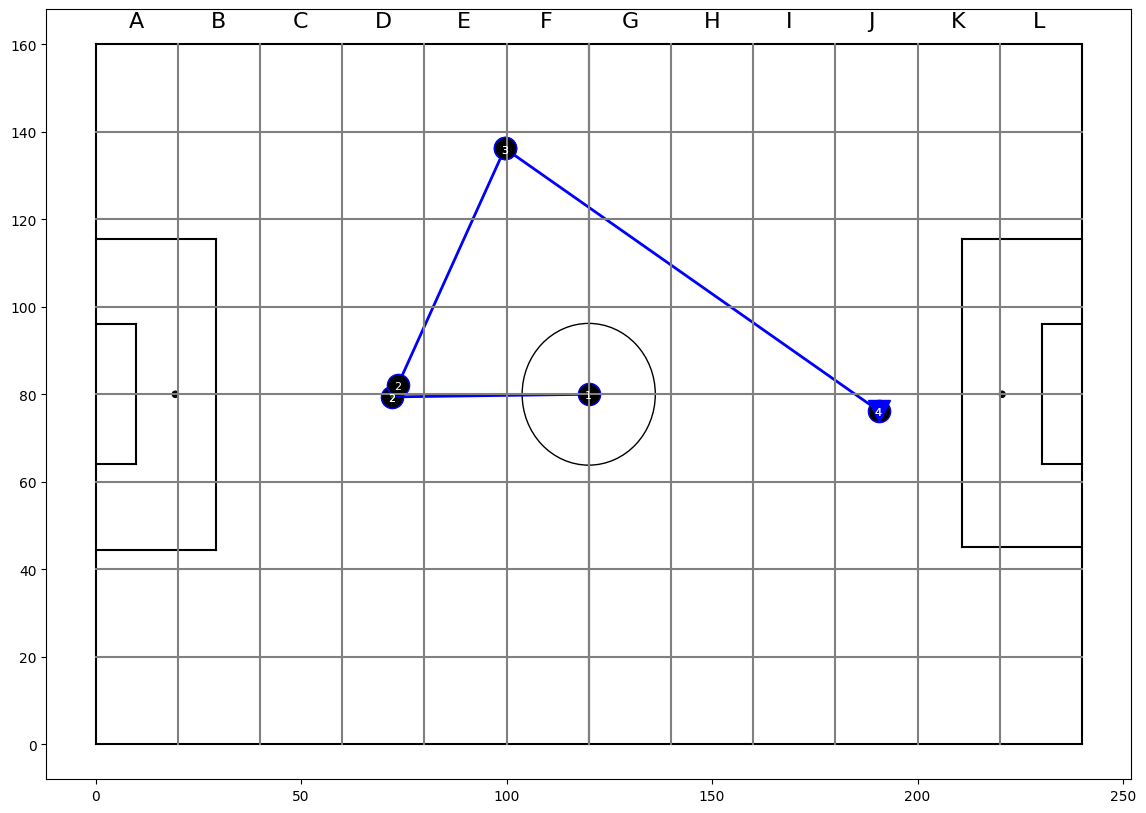

Sequence: 2
Team: Poland
1: Kamil Glik (Pass) <00:00:09.353>
2: Mateusz Andrzej Klich (Ball Receipt*) <00:00:10.310>
2: Mateusz Andrzej Klich (Pass) <00:00:10.344>
3: Piotr Zieliński (Ball Receipt*) <00:00:11.479>
3: Piotr Zieliński (Carry) <00:00:11.479>
3: Piotr Zieliński (Pass) <00:00:13.421>
4: Robert Lewandowski (Ball Receipt*) <00:00:14.364>
4: Robert Lewandowski (Carry) <00:00:14.364>
4: Robert Lewandowski (Pass) <00:00:15.523>
5: Tymoteusz Puchacz (Ball Receipt*) <00:00:16.740>
5: Tymoteusz Puchacz (Carry) <00:00:16.740>
5: Tymoteusz Puchacz (Pass) <00:00:17.456>
6: Jan Bednarek (Ball Receipt*) <00:00:18.427>
6: Jan Bednarek (Carry) <00:00:18.427>
6: Jan Bednarek (Pass) <00:00:19.747>
7: Bartosz Bereszyński (Ball Receipt*) <00:00:21.153>
7: Bartosz Bereszyński (Carry) <00:00:21.153>
7: Bartosz Bereszyński (Pass) <00:00:25.168>
8: Kamil Glik (Ball Receipt*) <00:00:26.550>
8: Kamil Glik (Carry) <00:00:26.550>
8: Kamil Glik (Pass) <00:00:27.497>
9: Jan Bednarek (Ball Receipt*) <00

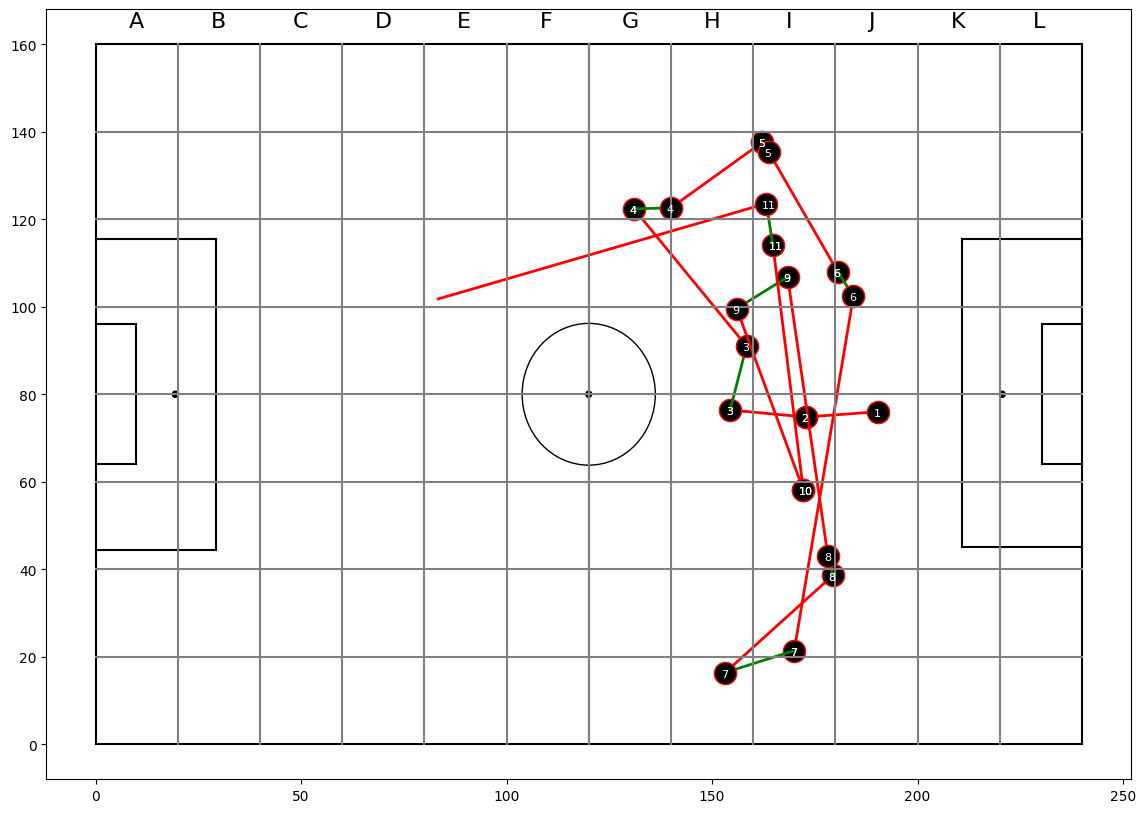

Sequence: 3
Team: Sweden
1: Victor Nilsson Lindelöf (Pass) <00:00:38.375>
2: Kristoffer Olsson (Ball Receipt*) <00:00:39.466>
2: Kristoffer Olsson (Pass) <00:00:39.466>
3: Mikael Lustig (Ball Receipt*) <00:00:40.562>
3: Mikael Lustig (Carry) <00:00:40.562>
3: Mikael Lustig (Pass) <00:00:42.468>


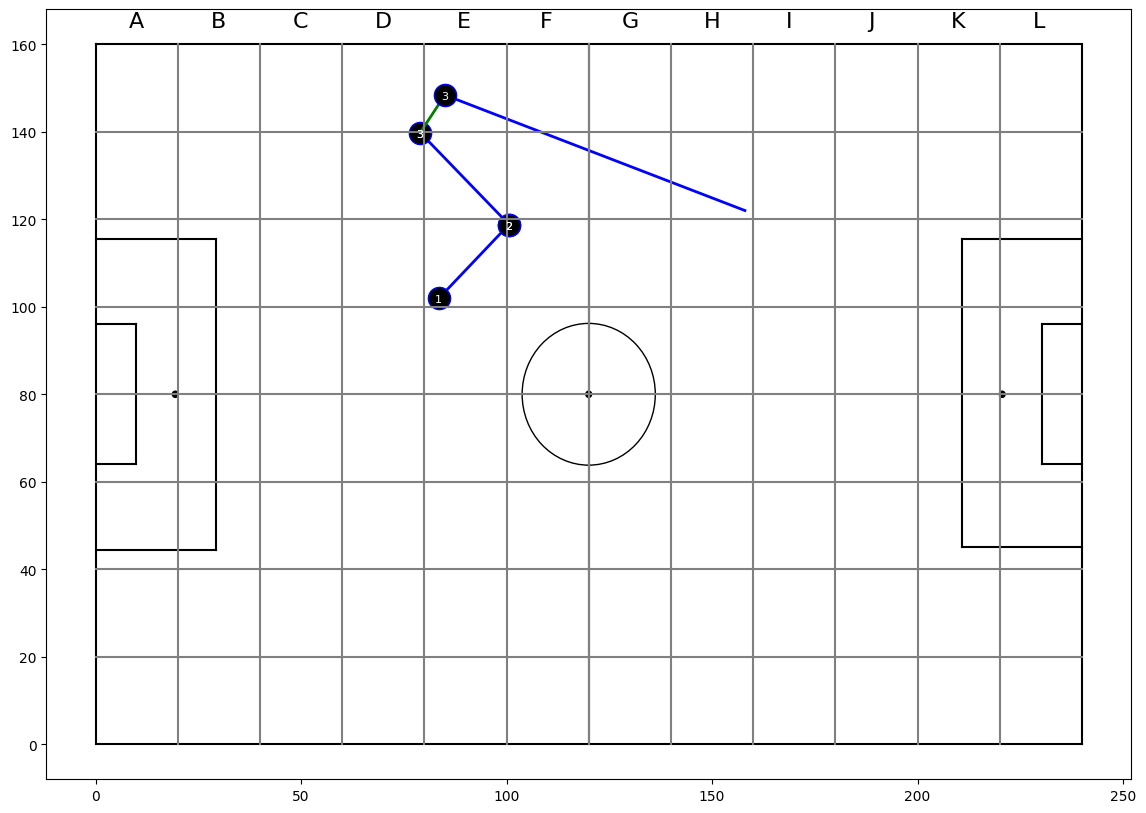

Sequence: 4
Team: Poland
1: Jan Bednarek (Pass) <00:00:44.270>
2: Grzegorz Krychowiak (Ball Receipt*) <00:00:45.101>
2: Grzegorz Krychowiak (Carry) <00:00:45.101>
2: Grzegorz Krychowiak (Pass) <00:00:46.473>
3: Tymoteusz Puchacz (Ball Receipt*) <00:00:47.194>
3: Tymoteusz Puchacz (Carry) <00:00:47.194>
3: Tymoteusz Puchacz (Pass) <00:00:47.847>
4: Mateusz Andrzej Klich (Ball Receipt*) <00:00:48.794>
4: Mateusz Andrzej Klich (Carry) <00:00:48.794>
4: Mateusz Andrzej Klich (Dispossessed) <00:00:50.138>
5: Mikael Lustig (Duel) <00:00:50.138>


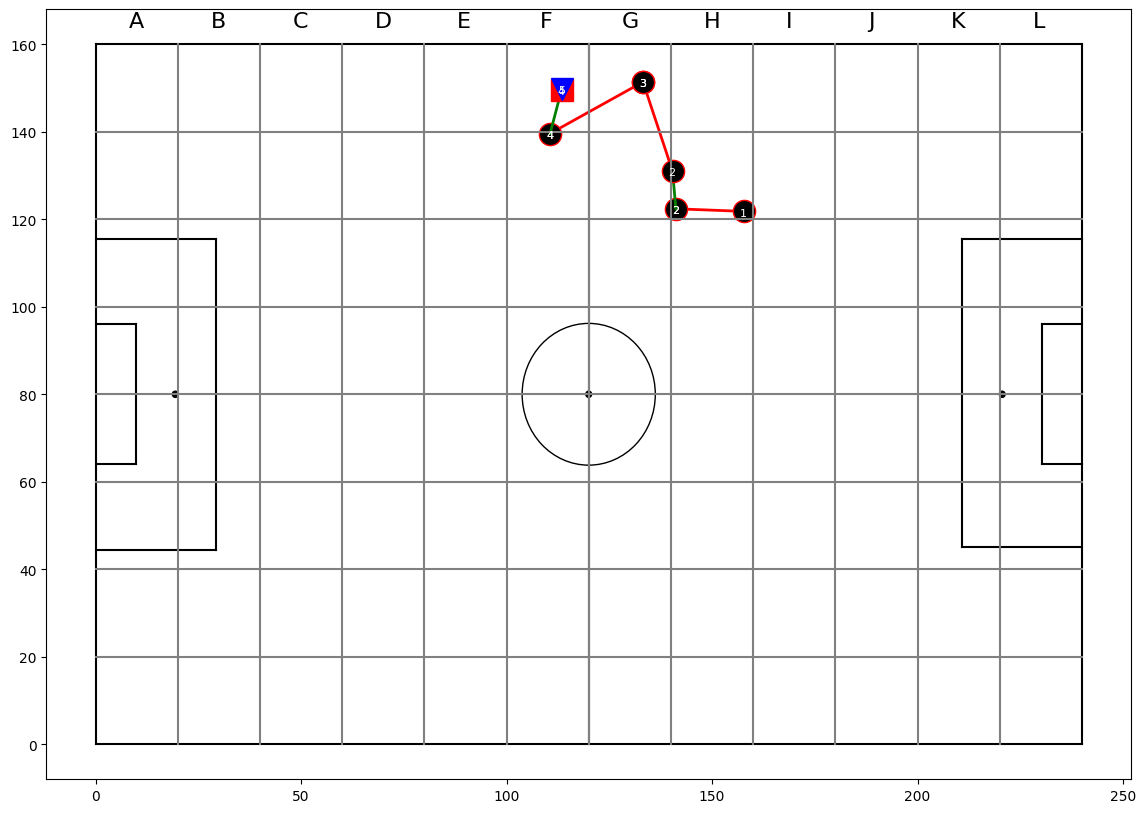

Sequence: 5
Team: Sweden
1: Mikael Lustig (Pass) <00:01:10.498>
2: Sebastian Larsson (Ball Receipt*) <00:01:11.479>
2: Sebastian Larsson (Pass) <00:01:11.479>
3: Mikael Lustig (Ball Receipt*) <00:01:12.472>
3: Mikael Lustig (Pass) <00:01:12.472>
4: Sebastian Larsson (Ball Receipt*) <00:01:13.070>
4: Sebastian Larsson (Pass) <00:01:13.070>
5: Mikael Lustig (Ball Receipt*) <00:01:14.119>
5: Mikael Lustig (Carry) <00:01:14.119>
5: Mikael Lustig (Pass) <00:01:15.083>
6: Alexander Isak (Ball Receipt*) <00:01:16.569>
6: Alexander Isak (Carry) <00:01:16.569>
6: Alexander Isak (Pass) <00:01:16.577>
7: Emil Peter Forsberg (Ball Receipt*) <00:01:17.827>
7: Emil Peter Forsberg (Carry) <00:01:17.827>
7: Emil Peter Forsberg (Pass) <00:01:17.830>
8: Alexander Isak (Ball Receipt*) <00:01:18.888>
8: Alexander Isak (Carry) <00:01:18.888>
8: Alexander Isak (Dispossessed) <00:01:19.168>
9: Kamil Glik (Duel) <00:01:19.168>
10: Emil Peter Forsberg (Pass) <00:01:19.483>
11: Alexander Isak (Ball Receipt*) <0

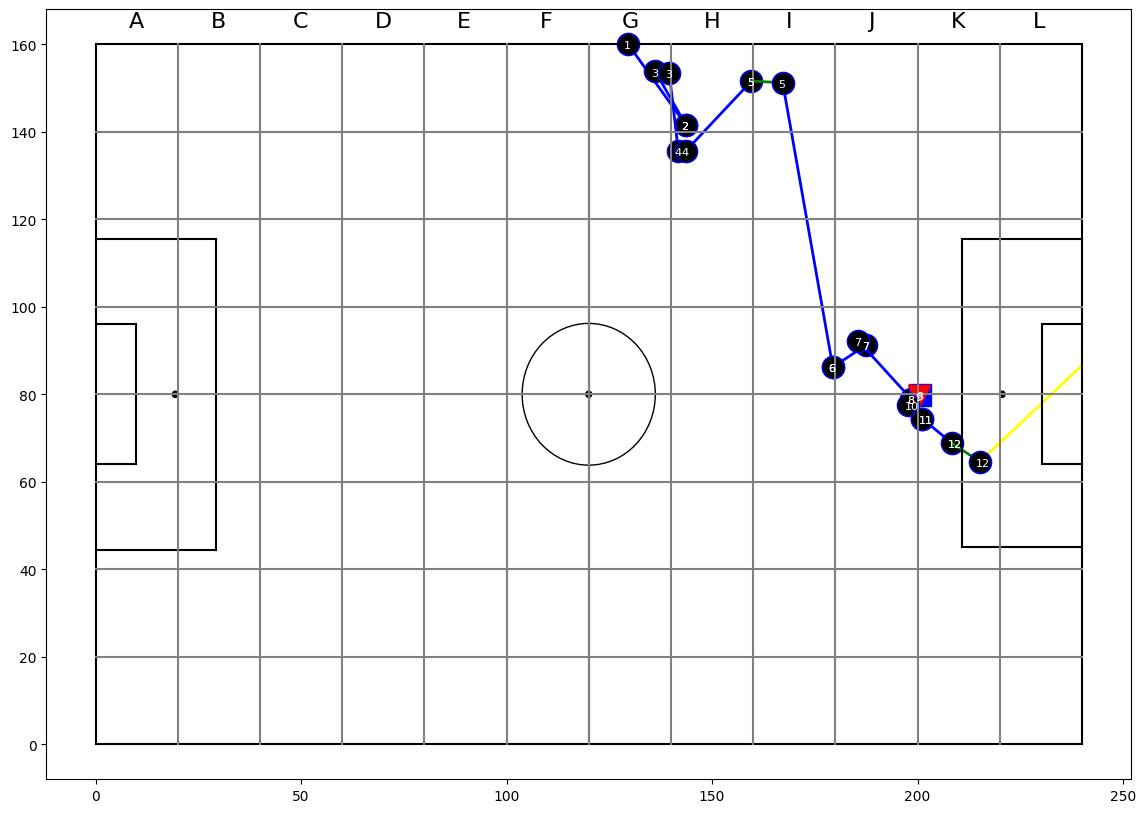

Sequence: 6
Team: Poland
1: Robert Lewandowski (Pass) <00:02:17.362>
2: Kamil Glik (Ball Receipt*) <00:02:19.016>
2: Kamil Glik (Pass) <00:02:21.722>
3: Jan Bednarek (Ball Receipt*) <00:02:23.028>
3: Jan Bednarek (Carry) <00:02:23.028>
3: Jan Bednarek (Pass) <00:02:25.583>
4: Kamil Glik (Ball Receipt*) <00:02:27.086>
4: Kamil Glik (Carry) <00:02:27.086>
4: Kamil Glik (Pass) <00:02:30.217>
5: Jan Bednarek (Ball Receipt*) <00:02:32.147>
5: Jan Bednarek (Carry) <00:02:32.147>
5: Jan Bednarek (Pass) <00:02:33.891>
6: Robert Lewandowski (Ball Receipt*) <00:02:36.609>


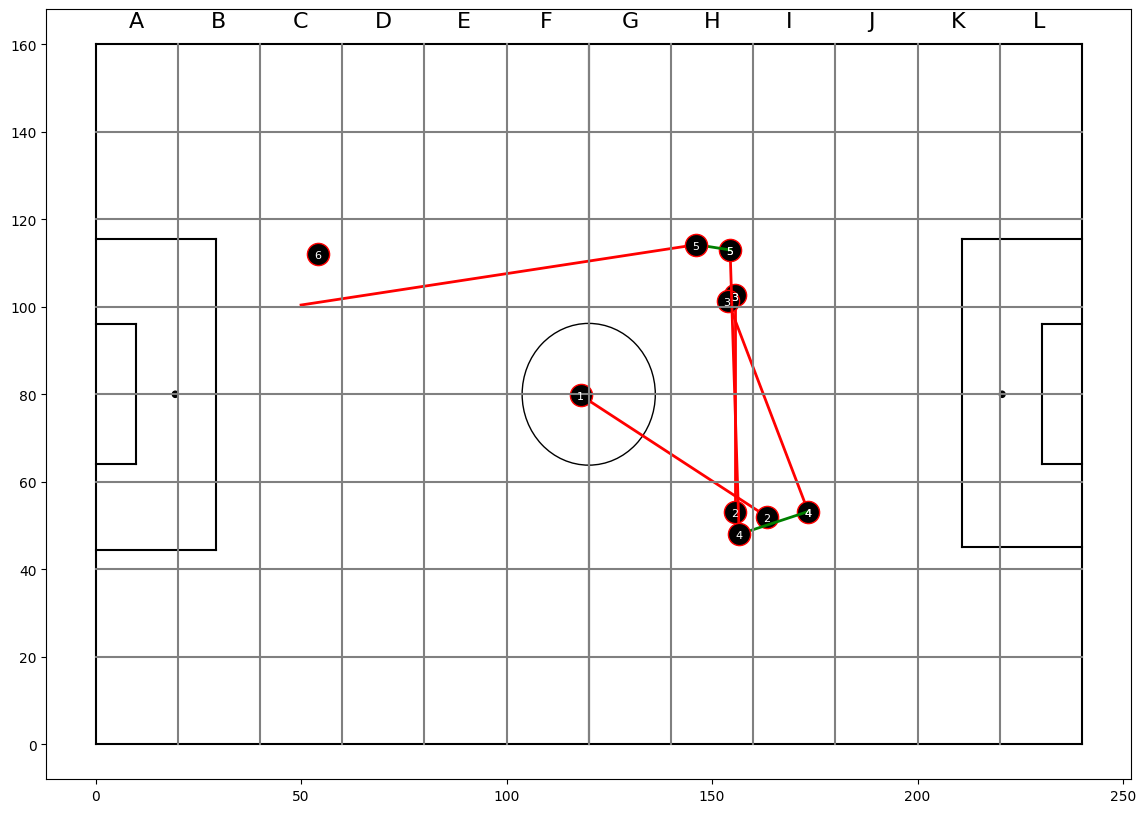

Sequence: 7
Team: Sweden
1: Victor Nilsson Lindelöf (Pass) <00:02:36.609>
2: Mikael Lustig (Ball Receipt*) <00:02:38.606>
2: Mikael Lustig (Carry) <00:02:38.606>
2: Mikael Lustig (Pass) <00:02:40.897>
3: Alexander Isak (Ball Receipt*) <00:02:43.264>
3: Alexander Isak (Duel) <00:02:43.264>
4: Kamil Glik (Pass) <00:02:43.264>


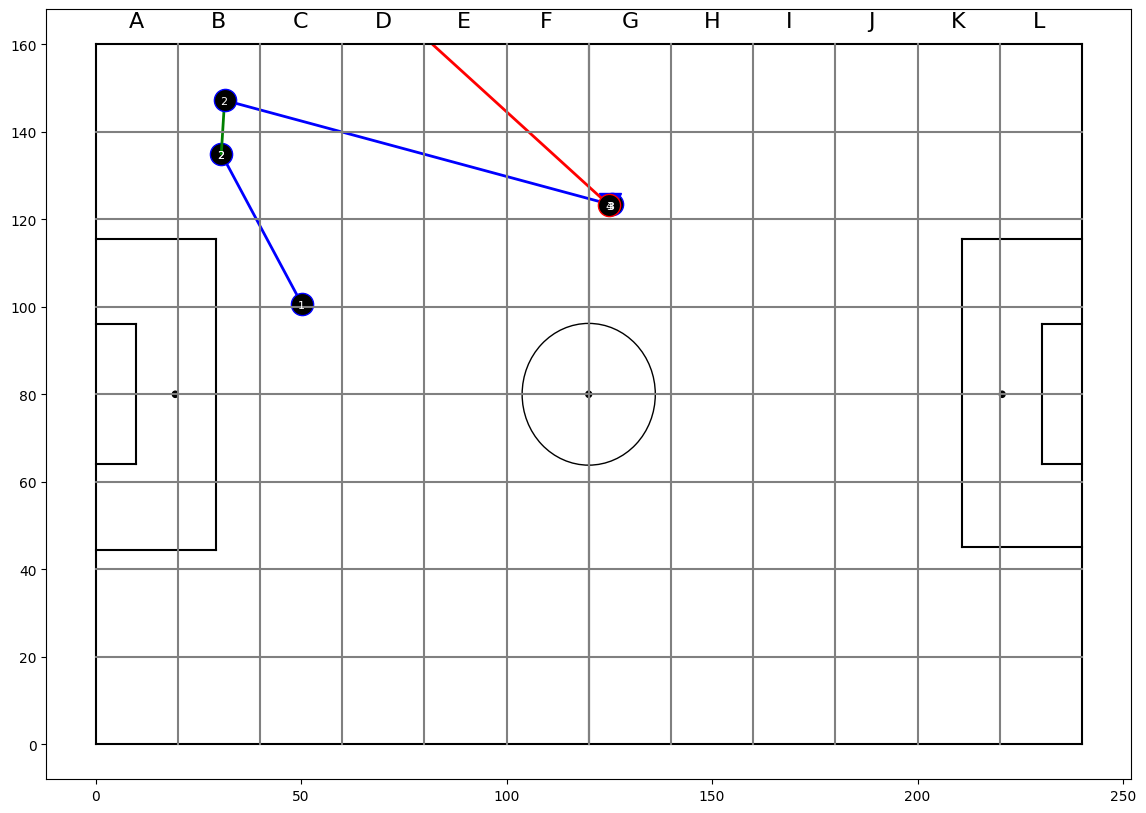

Sequence: 8
Team: Sweden
1: Mikael Lustig (Pass) <00:02:58.958>
2: Sebastian Larsson (Ball Receipt*) <00:03:00.252>
2: Sebastian Larsson (Carry) <00:03:00.252>
2: Sebastian Larsson (Pass) <00:03:00.268>
3: Mikael Lustig (Ball Receipt*) <00:03:01.146>
3: Mikael Lustig (Pass) <00:03:01.146>
4: Sebastian Larsson (Ball Receipt*) <00:03:01.294>
5: Piotr Zieliński (Block) <00:03:01.294>


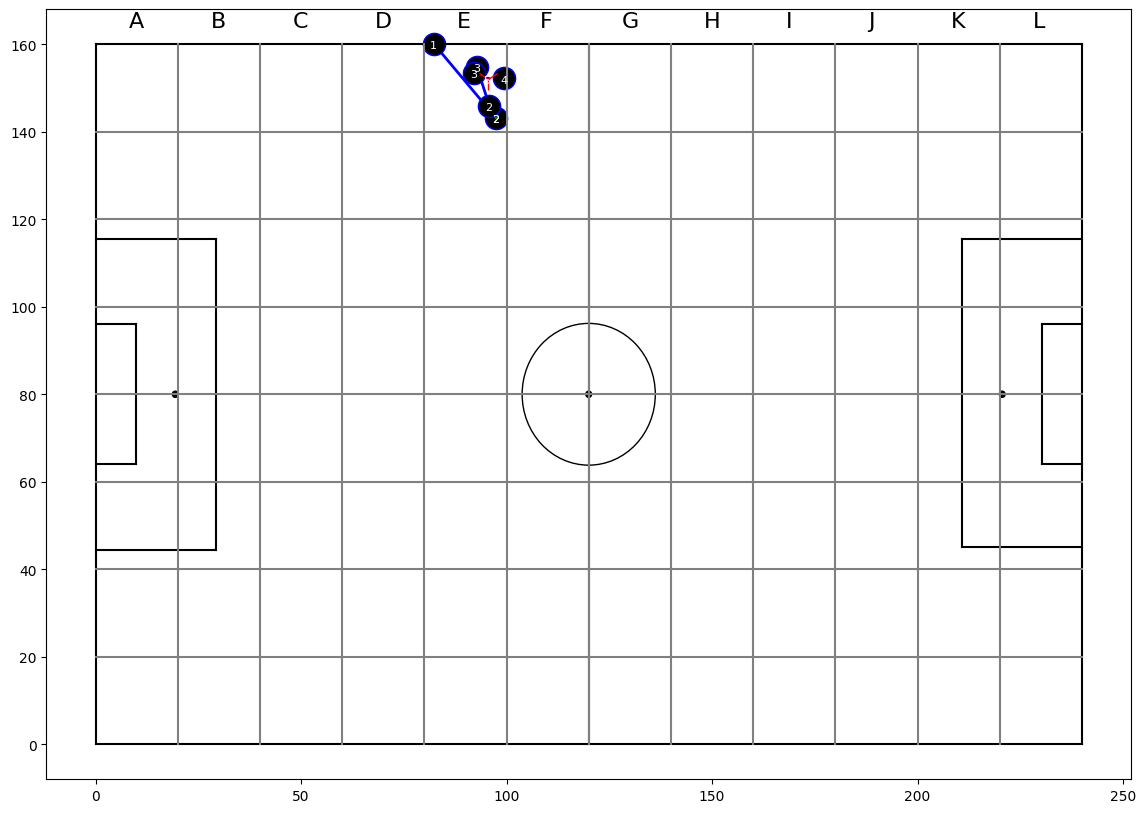

Sequence: 9
Team: Sweden
1: Mikael Lustig (Pass) <00:03:11.677>
2: Kristoffer Olsson (Ball Receipt*) <00:03:12.556>
2: Kristoffer Olsson (Pass) <00:03:12.556>
3: Mikael Lustig (Ball Receipt*) <00:03:13.491>
3: Mikael Lustig (Pass) <00:03:13.491>
4: Robin Quaison (Ball Receipt*) <00:03:16.503>
5: Kamil Glik (Pass) <00:03:16.503>
6: Tymoteusz Puchacz (Ball Receipt*) <00:03:18.134>
6: Tymoteusz Puchacz (Carry) <00:03:18.134>
6: Tymoteusz Puchacz (Pass) <00:03:19.771>
7: Marcus Andreas Danielsson (Pass) <00:03:23.681>
8: Robin Quaison (Ball Receipt*) <00:03:26.064>
9: Jan Bednarek (Duel) <00:03:26.064>
10: Robin Quaison (Pass) <00:03:26.064>
11: Emil Peter Forsberg (Ball Receipt*) <00:03:26.994>
11: Emil Peter Forsberg (Carry) <00:03:26.994>
11: Emil Peter Forsberg (Pass) <00:03:28.076>
12: Ludwig Augustinsson (Ball Receipt*) <00:03:32.879>
12: Ludwig Augustinsson (Carry) <00:03:32.879>
12: Ludwig Augustinsson (Pass) <00:03:34.011>
13: Albin Ekdal (Ball Receipt*) <00:03:35.616>
13: Albin E

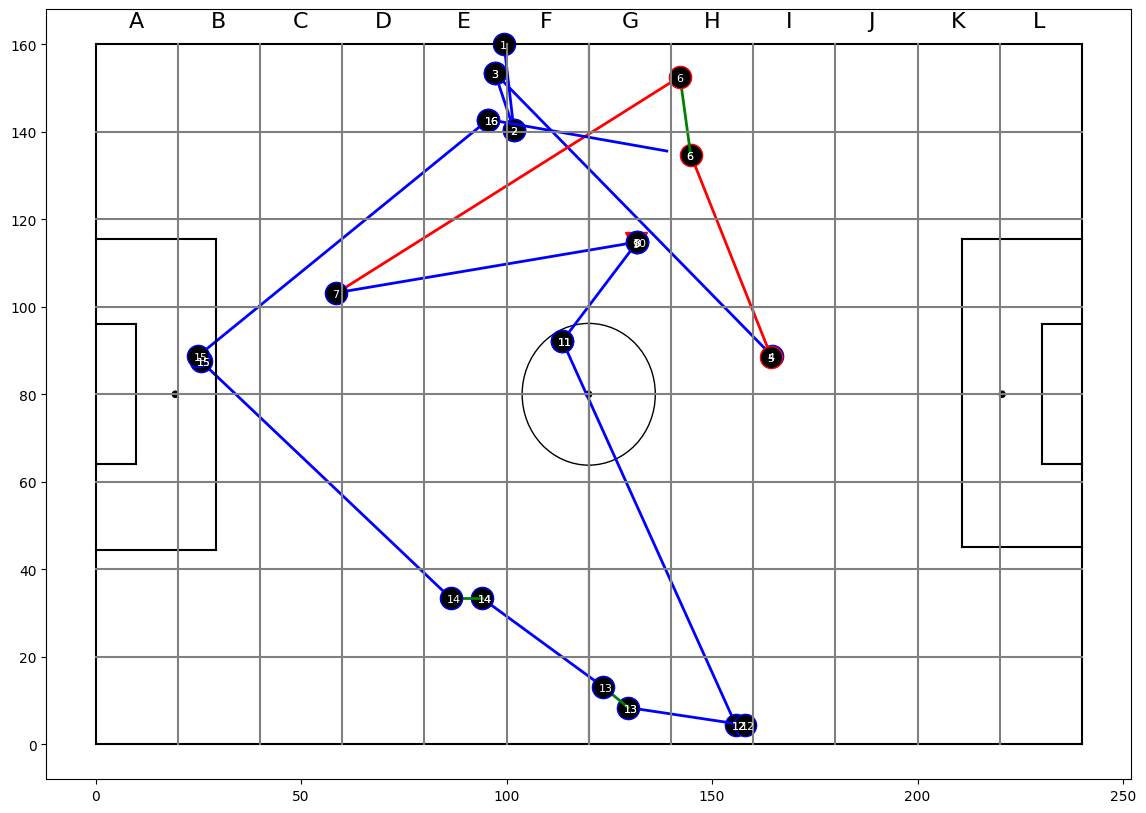

Sequence: 10
Team: Poland
1: Jan Bednarek (Pass) <00:03:53.358>
2: Mateusz Andrzej Klich (Ball Receipt*) <00:03:54.025>
2: Mateusz Andrzej Klich (Carry) <00:03:54.025>
2: Mateusz Andrzej Klich (Pass) <00:03:54.063>
3: Grzegorz Krychowiak (Ball Receipt*) <00:03:55.019>
3: Grzegorz Krychowiak (Pass) <00:03:55.019>


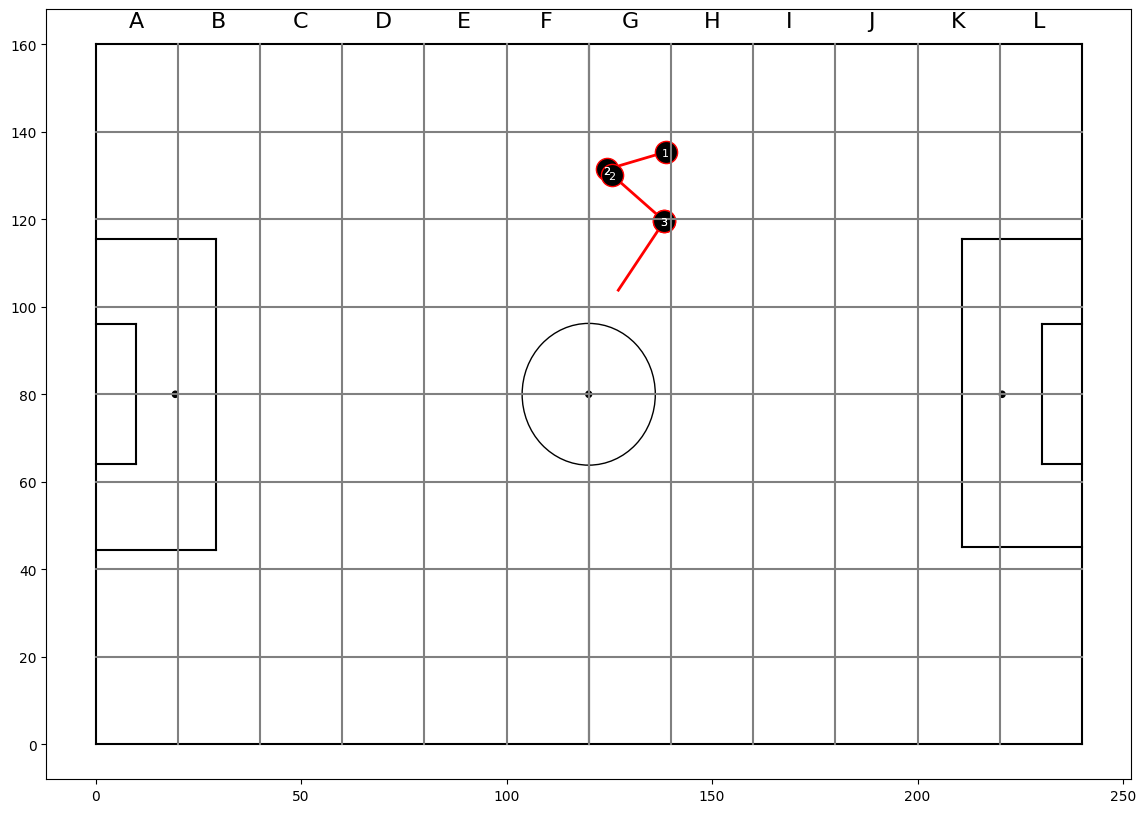

Sequence: 11
Team: Sweden
1: Kristoffer Olsson (Pass) <00:03:57.065>
2: Emil Peter Forsberg (Ball Receipt*) <00:03:58.111>
2: Emil Peter Forsberg (Carry) <00:03:58.111>
2: Emil Peter Forsberg (Pass) <00:04:01.108>
3: Ludwig Augustinsson (Ball Receipt*) <00:04:02.667>
3: Ludwig Augustinsson (Carry) <00:04:02.667>
3: Ludwig Augustinsson (Pass) <00:04:06.061>
4: Kristoffer Olsson (Ball Receipt*) <00:04:06.841>
4: Kristoffer Olsson (Carry) <00:04:06.841>
4: Kristoffer Olsson (Dispossessed) <00:04:06.879>
5: Bartosz Bereszyński (Duel) <00:04:06.879>
6: Kristoffer Olsson (Pass) <00:04:08.905>
7: Albin Ekdal (Ball Receipt*) <00:04:10.392>
7: Albin Ekdal (Pass) <00:04:10.392>
8: Ludwig Augustinsson (Ball Receipt*) <00:04:11.705>
8: Ludwig Augustinsson (Carry) <00:04:11.705>
8: Ludwig Augustinsson (Pass) <00:04:13.227>
9: Emil Peter Forsberg (Ball Receipt*) <00:04:13.915>
9: Emil Peter Forsberg (Carry) <00:04:13.915>
9: Emil Peter Forsberg (Dispossessed) <00:04:15.120>
10: Grzegorz Krychowiak (

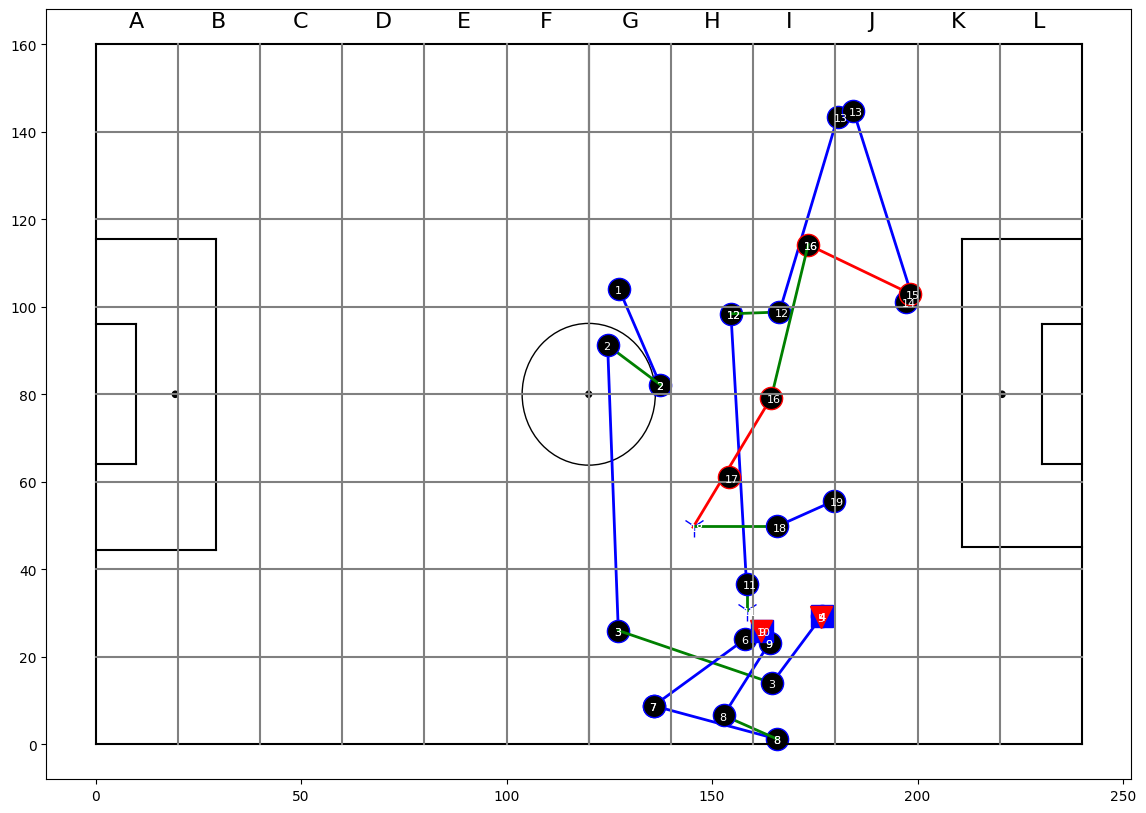

Sequence: 12
Team: Poland
1: Grzegorz Krychowiak (Interception) <00:04:34.047>
1: Grzegorz Krychowiak (Carry) <00:04:34.047>
1: Grzegorz Krychowiak (Pass) <00:04:35.567>
2: Karol Świderski (Ball Receipt*) <00:04:36.790>
2: Karol Świderski (Carry) <00:04:36.790>
2: Karol Świderski (Pass) <00:04:37.520>
3: Piotr Zieliński (Ball Receipt*) <00:04:38.289>
3: Piotr Zieliński (Carry) <00:04:38.289>
3: Piotr Zieliński (Pass) <00:04:39.143>
4: Kamil Jóźwiak (Ball Receipt*) <00:04:42.801>
4: Kamil Jóźwiak (Miscontrol) <00:04:42.801>


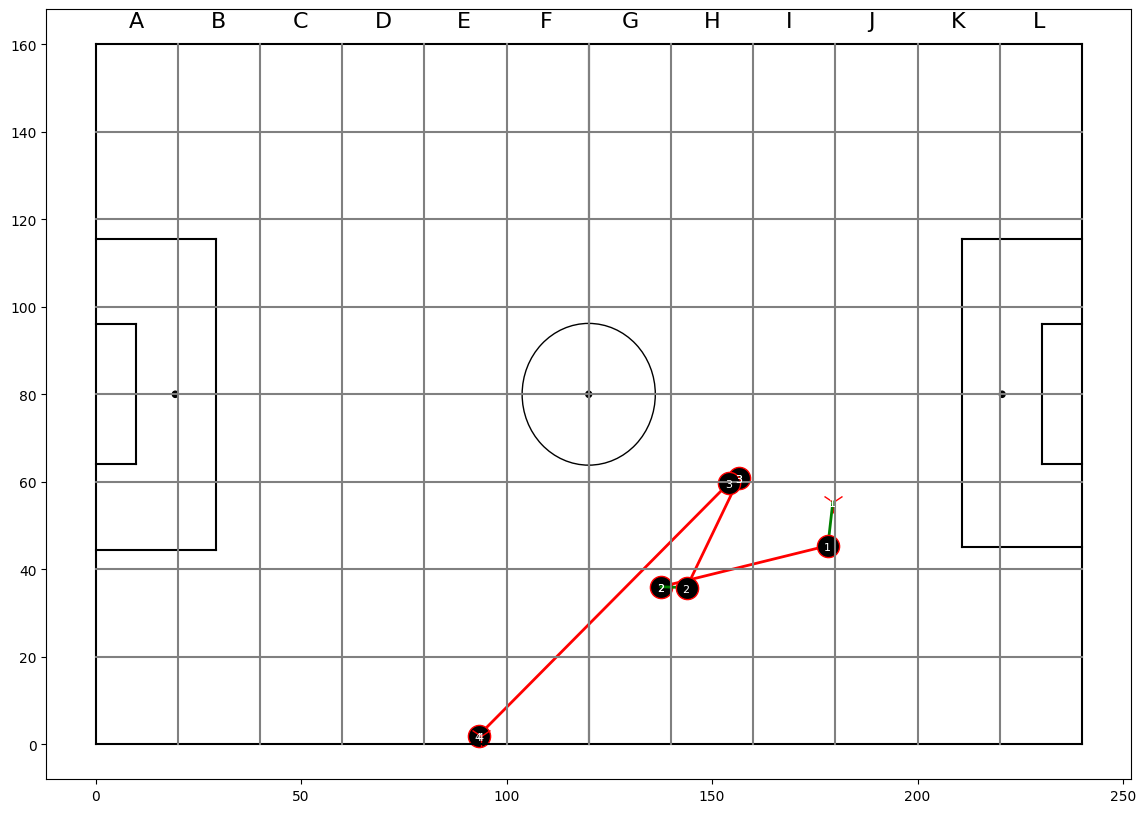

Sequence: 13
Team: Sweden
1: Ludwig Augustinsson (Pass) <00:05:11.130>
2: Alexander Isak (Ball Receipt*) <00:05:12.389>
2: Alexander Isak (Duel) <00:05:12.389>


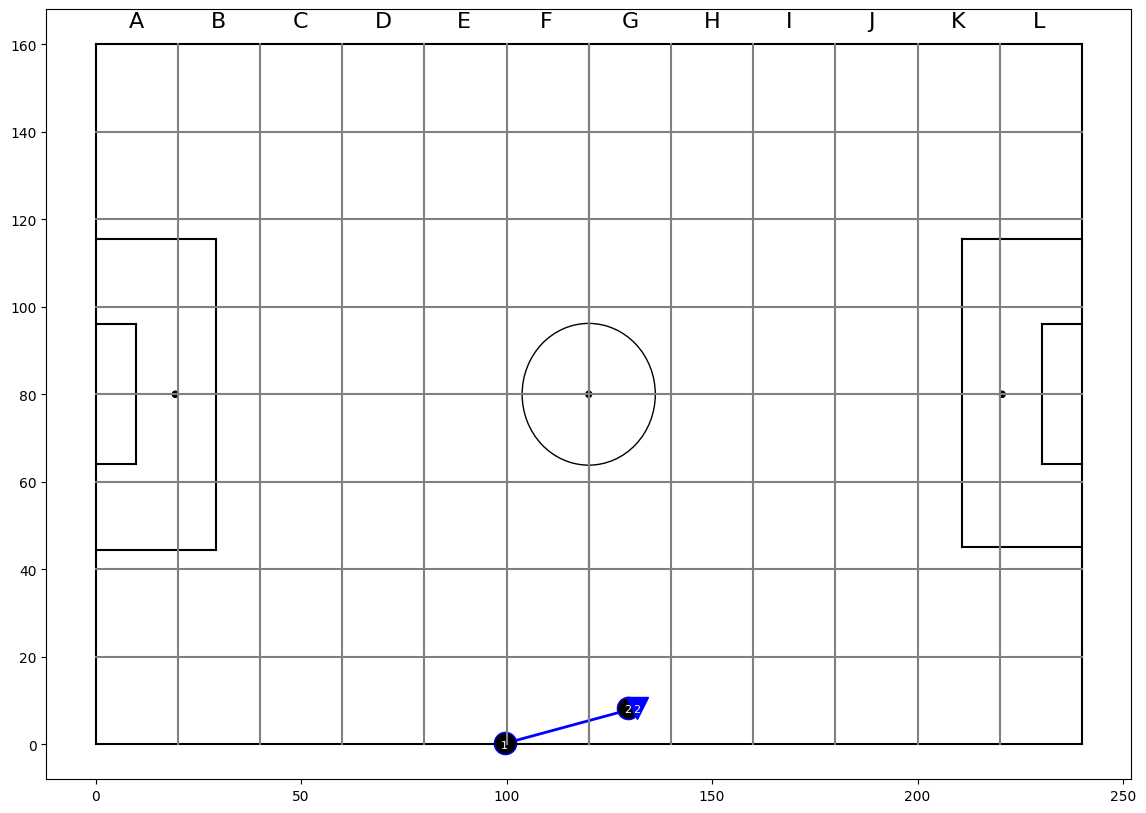

Sequence: 14
Team: Poland
1: Kamil Glik (Pass) <00:05:12.389>
2: Jan Bednarek (Ball Receipt*) <00:05:14.149>
2: Jan Bednarek (Pass) <00:05:14.172>
3: Mateusz Andrzej Klich (Ball Receipt*) <00:05:14.736>
4: Kristoffer Olsson (Interception) <00:05:14.736>
5: Grzegorz Krychowiak (Pass) <00:05:15.315>
6: Albin Ekdal (Pass) <00:05:16.378>
7: Robin Quaison (Ball Receipt*) <00:05:19.207>
8: Jan Bednarek (Pass) <00:05:19.207>
9: Grzegorz Krychowiak (Ball Receipt*) <00:05:20.278>
9: Grzegorz Krychowiak (Pass) <00:05:20.278>
10: Mateusz Andrzej Klich (Ball Receipt*) <00:05:22.914>
10: Mateusz Andrzej Klich (Carry) <00:05:22.914>
10: Mateusz Andrzej Klich (Pass) <00:05:24.673>
11: Grzegorz Krychowiak (Ball Receipt*) <00:05:25.220>
11: Grzegorz Krychowiak (Carry) <00:05:25.220>
11: Grzegorz Krychowiak (Pass) <00:05:26.948>
12: Bartosz Bereszyński (Ball Receipt*) <00:05:27.918>
12: Bartosz Bereszyński (Carry) <00:05:27.918>
12: Bartosz Bereszyński (Pass) <00:05:29.227>
13: Karol Świderski (Ball Rec

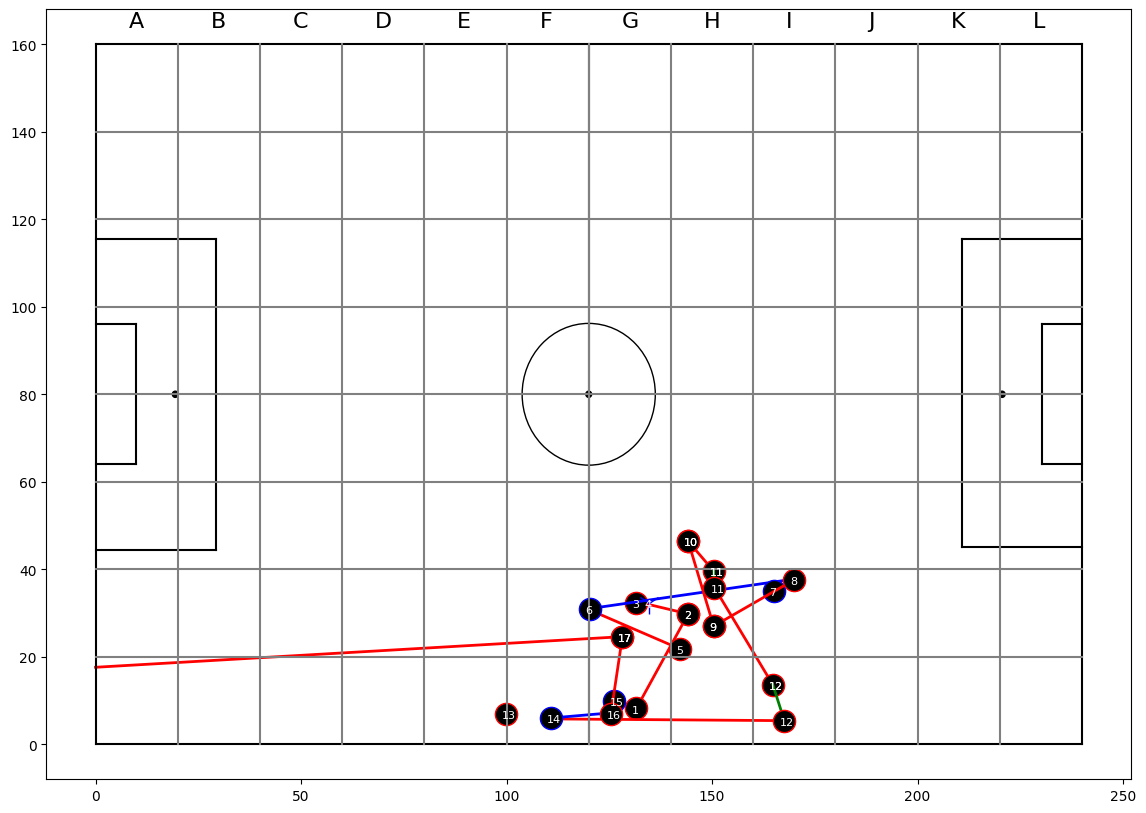

Sequence: 15
Team: Sweden
1: Robin Olsen (Pass) <00:06:07.179>
2: Sebastian Larsson (Ball Receipt*) <00:06:11.801>
2: Sebastian Larsson (Pass) <00:06:11.840>
3: Tymoteusz Puchacz (Duel) <00:06:11.840>
4: Alexander Isak (Ball Receipt*) <00:06:13.887>
5: Jan Bednarek (Interception) <00:06:13.887>


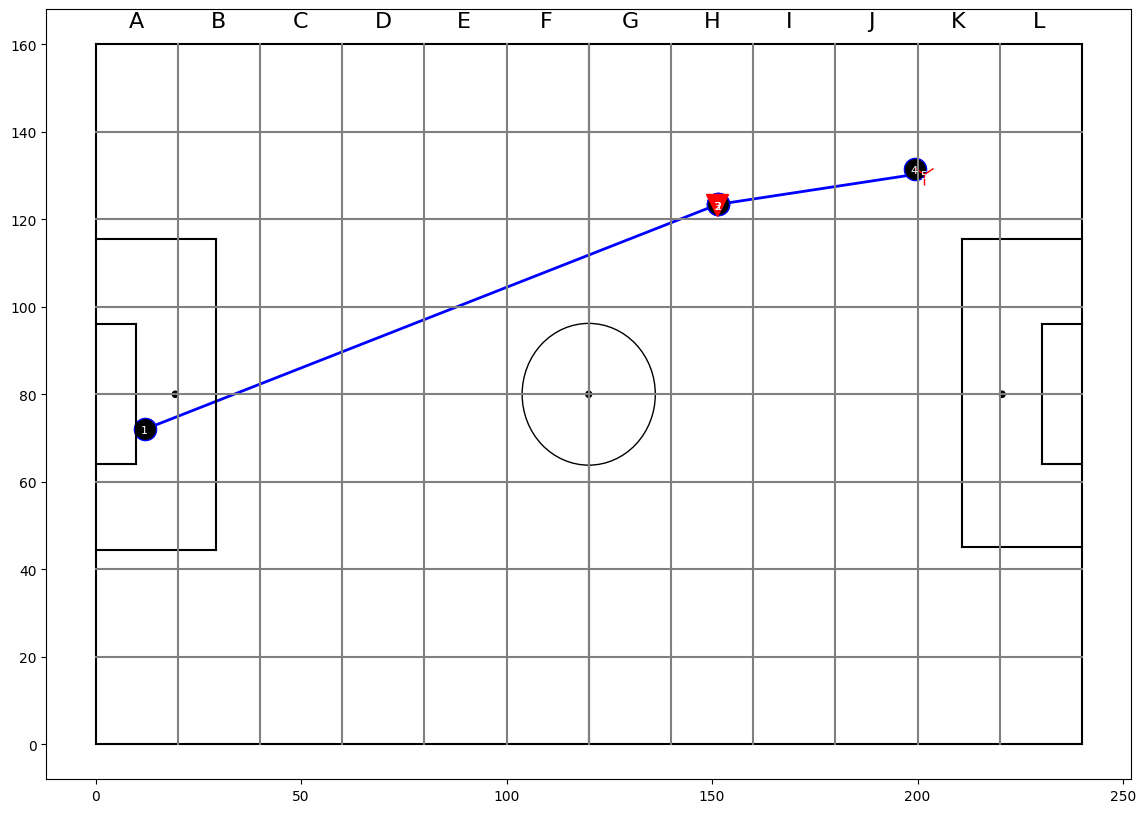

Sequence: 16
Team: Sweden
1: Victor Nilsson Lindelöf (Pass) <00:06:47.600>
2: Mikael Lustig (Ball Receipt*) <00:06:49.456>
3: Karol Świderski (Duel) <00:06:49.456>
4: Mikael Lustig (Miscontrol) <00:06:49.456>
5: Alexander Isak (Ball Recovery) <00:06:51.388>
5: Alexander Isak (Carry) <00:06:51.388>
5: Alexander Isak (Dispossessed) <00:06:52.477>
6: Grzegorz Krychowiak (Duel) <00:06:52.477>
7: Alexander Isak (Ball Recovery) <00:06:53.150>
7: Alexander Isak (Carry) <00:06:53.150>
7: Alexander Isak (Dribble) <00:06:53.444>
7: Alexander Isak (Carry) <00:06:53.444>
7: Alexander Isak (Miscontrol) <00:06:53.531>
8: Grzegorz Krychowiak (Ball Recovery) <00:06:53.757>
9: Kristoffer Olsson (Pass) <00:06:54.935>
10: Albin Ekdal (Ball Receipt*) <00:06:57.606>
10: Albin Ekdal (Carry) <00:06:57.606>
11: Kamil Jóźwiak (Foul Committed) <00:06:57.973>
12: Albin Ekdal (Foul Won) <00:06:57.973>
13: Sebastian Larsson (Pass) <00:07:43.546>
14: Bartosz Bereszyński (Clearance) <00:07:44.659>
15: Mikael Lustig 

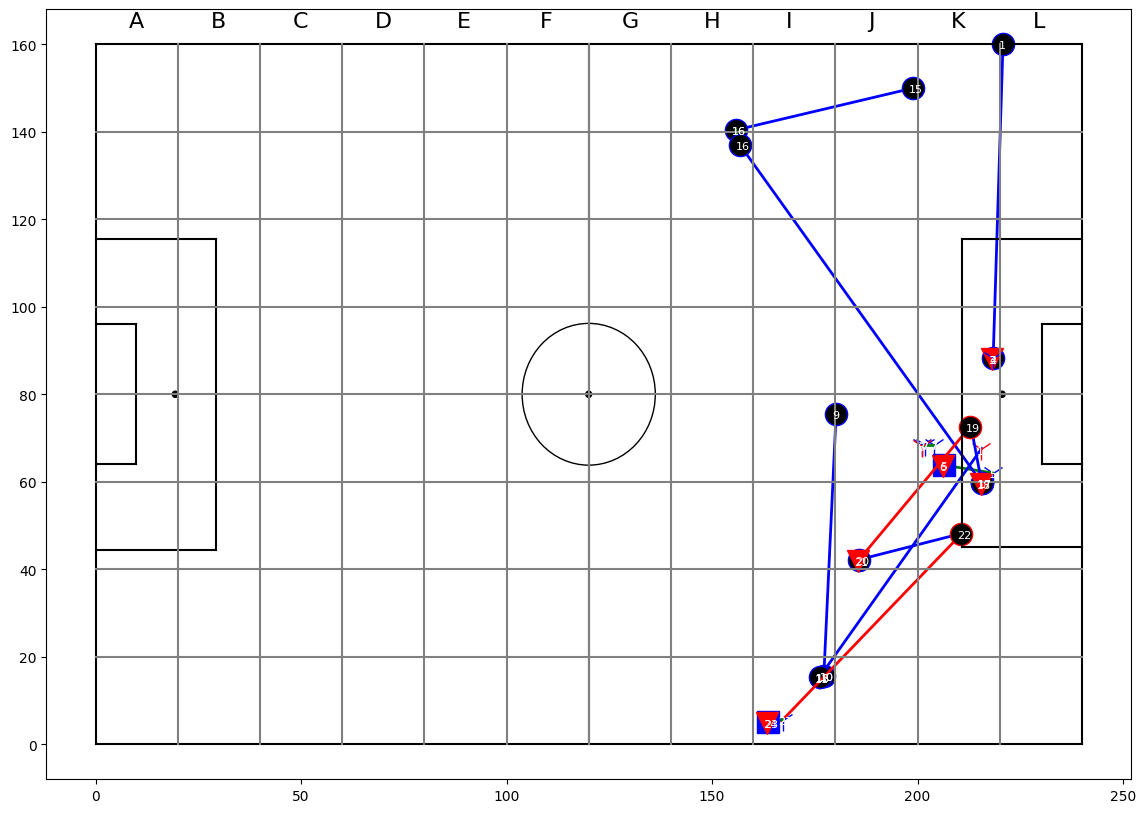

Sequence: 17
Team: Sweden
1: Ludwig Augustinsson (Pass) <00:08:24.485>
2: Alexander Isak (Ball Receipt*) <00:08:26.370>
3: Bartosz Bereszyński (Block) <00:08:26.370>
3: Bartosz Bereszyński (Clearance) <00:08:27.946>


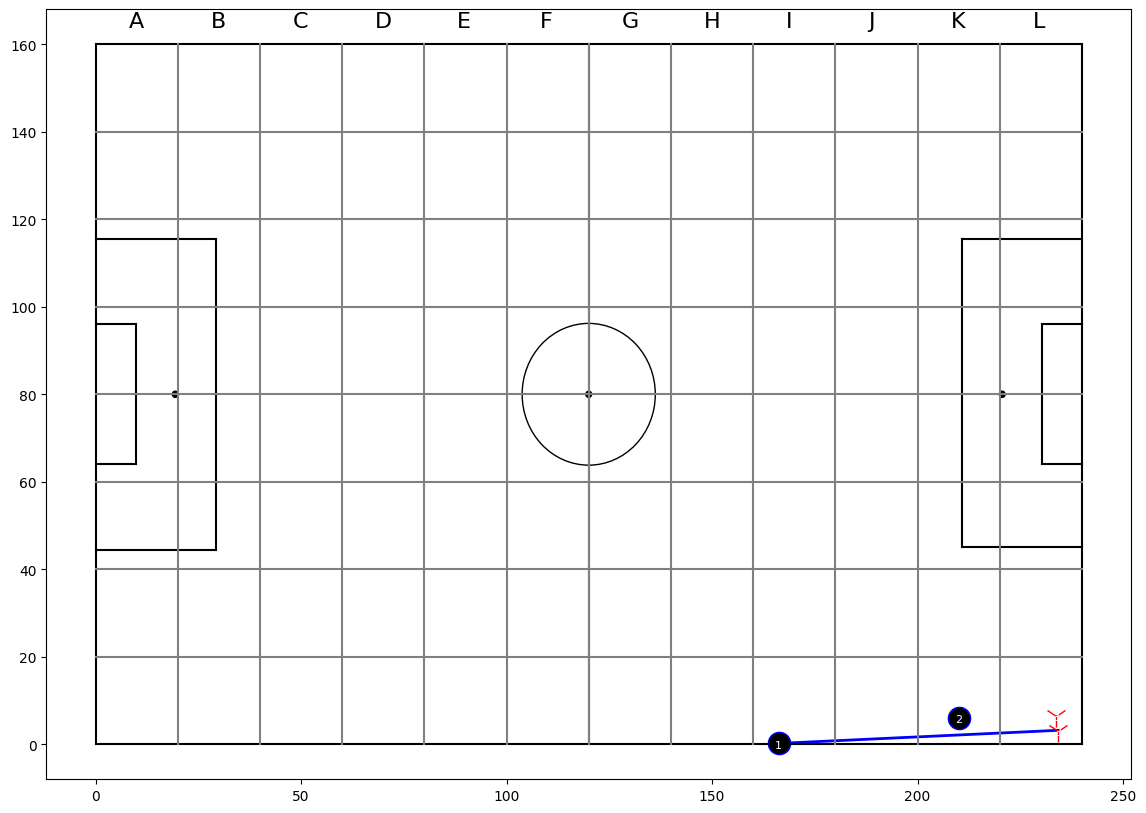

Sequence: 18
Team: Sweden
1: Ludwig Augustinsson (Pass) <00:08:34.895>
2: Albin Ekdal (Ball Receipt*) <00:08:35.726>
2: Albin Ekdal (Carry) <00:08:35.726>
2: Albin Ekdal (Pass) <00:08:36.354>
3: Ludwig Augustinsson (Ball Receipt*) <00:08:37.104>
3: Ludwig Augustinsson (Carry) <00:08:37.104>
3: Ludwig Augustinsson (Pass) <00:08:38.312>
4: Robin Quaison (Ball Receipt*) <00:08:40.777>
5: Tymoteusz Puchacz (Ball Recovery) <00:08:40.777>
5: Tymoteusz Puchacz (Carry) <00:08:40.777>
5: Tymoteusz Puchacz (Pass) <00:08:43.765>


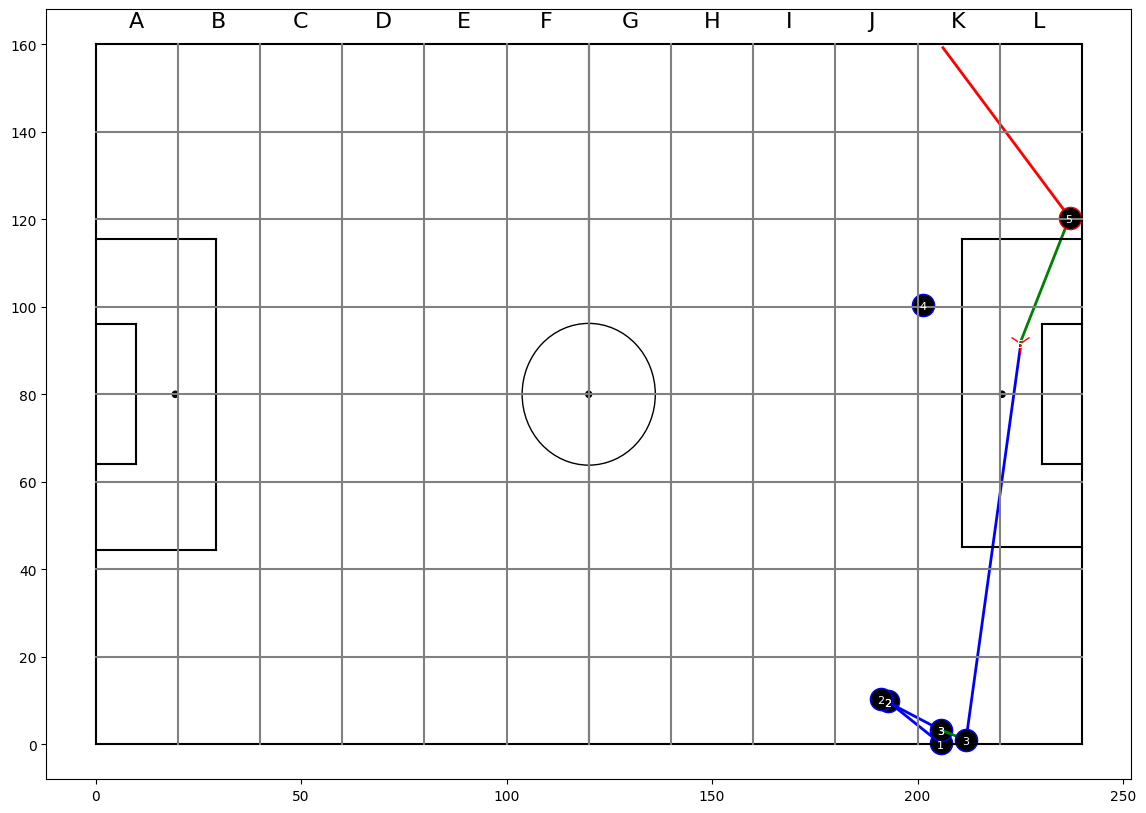

Sequence: 19
Team: Sweden
1: Sebastian Larsson (Pass) <00:08:49.761>
2: Mikael Lustig (Ball Receipt*) <00:08:51.596>
2: Mikael Lustig (Carry) <00:08:51.596>
2: Mikael Lustig (Pass) <00:08:52.151>
3: Kristoffer Olsson (Ball Receipt*) <00:08:53.318>
3: Kristoffer Olsson (Carry) <00:08:53.318>
3: Kristoffer Olsson (Pass) <00:08:55.409>
4: Sebastian Larsson (Ball Receipt*) <00:08:56.001>
4: Sebastian Larsson (Carry) <00:08:56.001>
4: Sebastian Larsson (Pass) <00:08:58.278>
5: Marcus Andreas Danielsson (Ball Receipt*) <00:08:59.600>
5: Marcus Andreas Danielsson (Carry) <00:08:59.600>
5: Marcus Andreas Danielsson (Miscontrol) <00:08:59.681>
6: Karol Świderski (Ball Recovery) <00:09:00.733>
7: Marcus Andreas Danielsson (Foul Committed) <00:09:01.202>
8: Karol Świderski (Foul Won) <00:09:01.202>


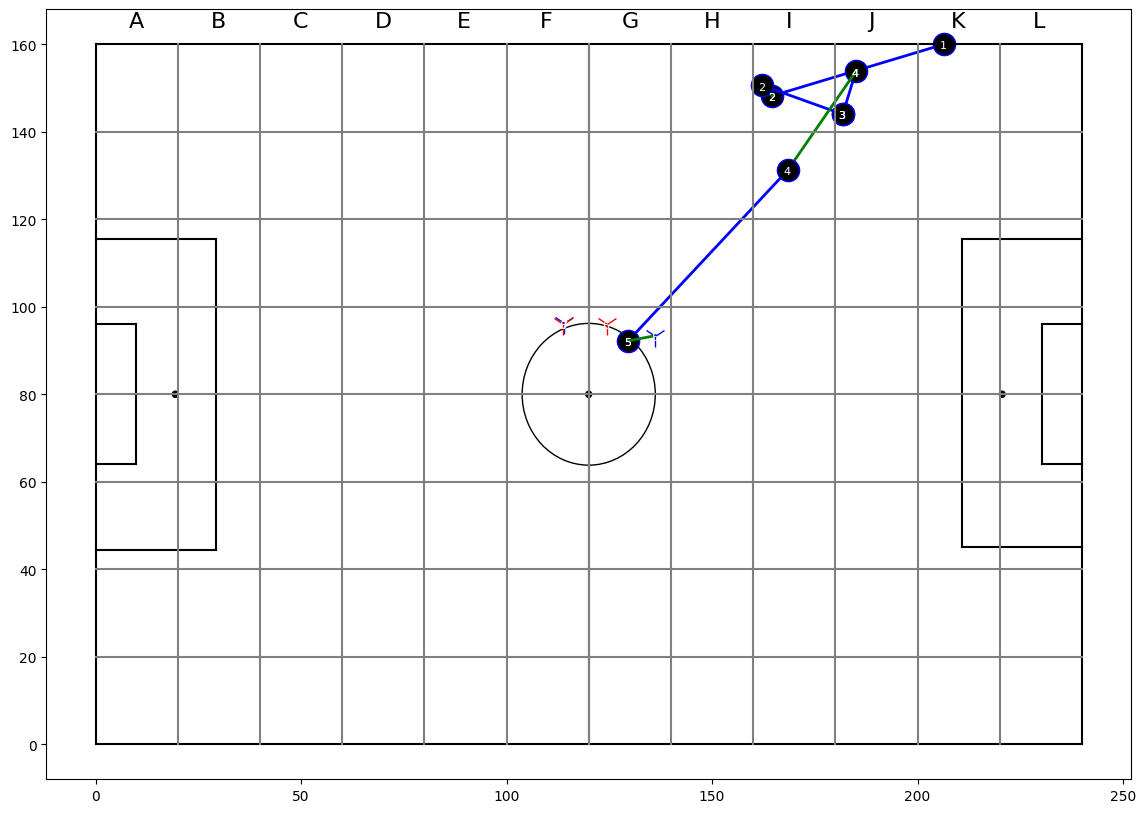

Sequence: 20
Team: Poland
1: Robert Lewandowski (Ball Recovery) <00:09:02.735>
1: Robert Lewandowski (Carry) <00:09:02.735>
1: Robert Lewandowski (Pass) <00:09:06.887>
2: Piotr Zieliński (Ball Receipt*) <00:09:11.706>
2: Piotr Zieliński (Carry) <00:09:11.706>
2: Piotr Zieliński (Pass) <00:09:12.182>
3: Tymoteusz Puchacz (Ball Receipt*) <00:09:14.179>
3: Tymoteusz Puchacz (Carry) <00:09:14.179>
3: Tymoteusz Puchacz (Pass) <00:09:16.077>
4: Kristoffer Olsson (Block) <00:09:16.312>


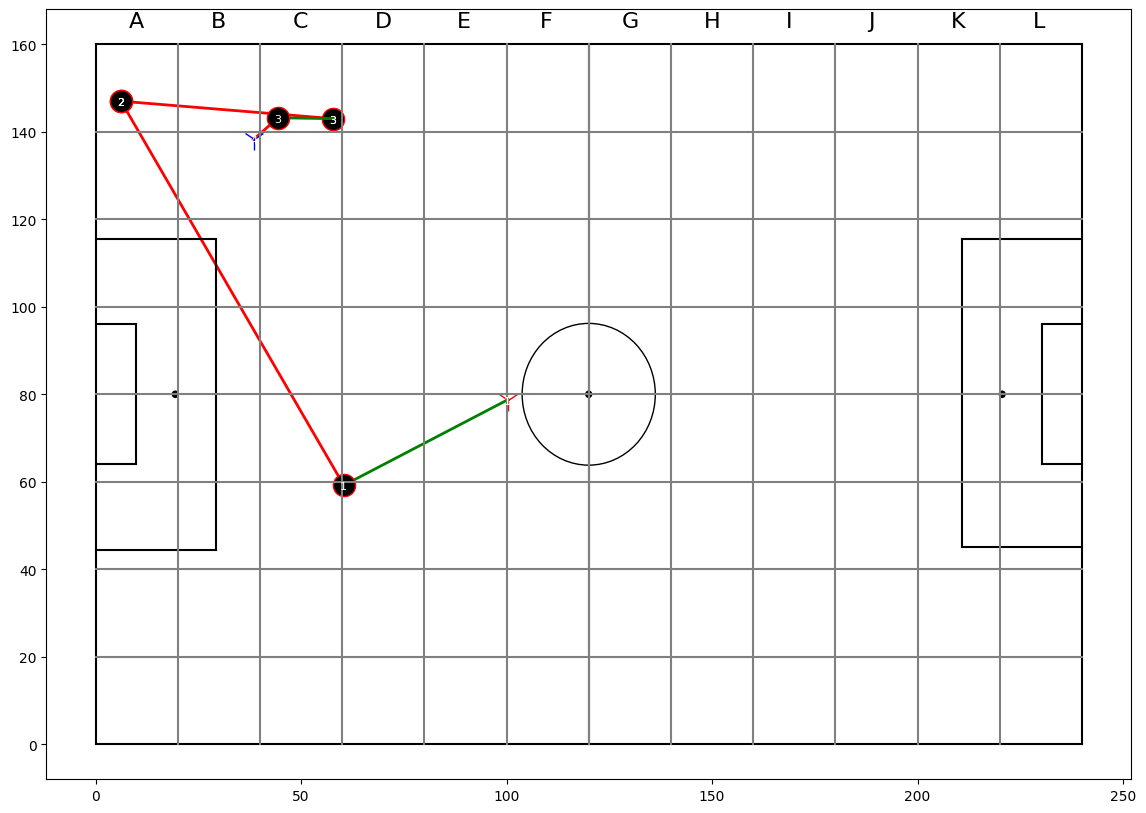

Sequence: 21
Team: Poland
1: Piotr Zieliński (Pass) <00:09:52.918>
2: Kamil Jóźwiak (Duel) <00:09:54.294>
3: Marcus Andreas Danielsson (Clearance) <00:09:54.294>
4: Kamil Glik (Foul Committed) <00:09:56.373>
5: Albin Ekdal (Foul Won) <00:09:56.373>


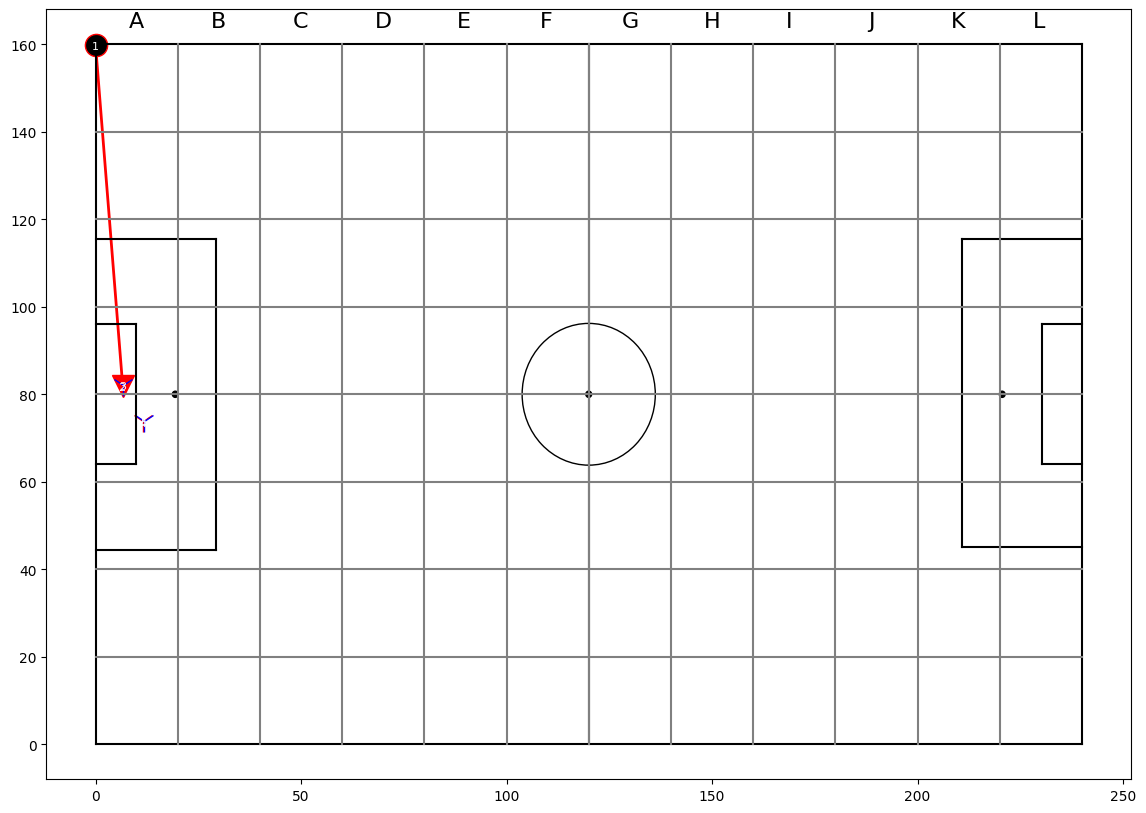

Sequence: 22
Team: Sweden
1: Robin Olsen (Pass) <00:10:30.272>
2: Mikael Lustig (Ball Receipt*) <00:10:33.859>
2: Mikael Lustig (Duel) <00:10:33.859>
3: Tymoteusz Puchacz (Clearance) <00:10:33.859>
3: Tymoteusz Puchacz (Block) <00:10:33.939>
4: Kristoffer Olsson (Pass) <00:10:35.560>
5: Mikael Lustig (Ball Receipt*) <00:10:36.630>
5: Mikael Lustig (Carry) <00:10:36.630>
5: Mikael Lustig (Pass) <00:10:38.425>
6: Emil Peter Forsberg (Ball Receipt*) <00:10:39.808>
6: Emil Peter Forsberg (Miscontrol) <00:10:39.808>


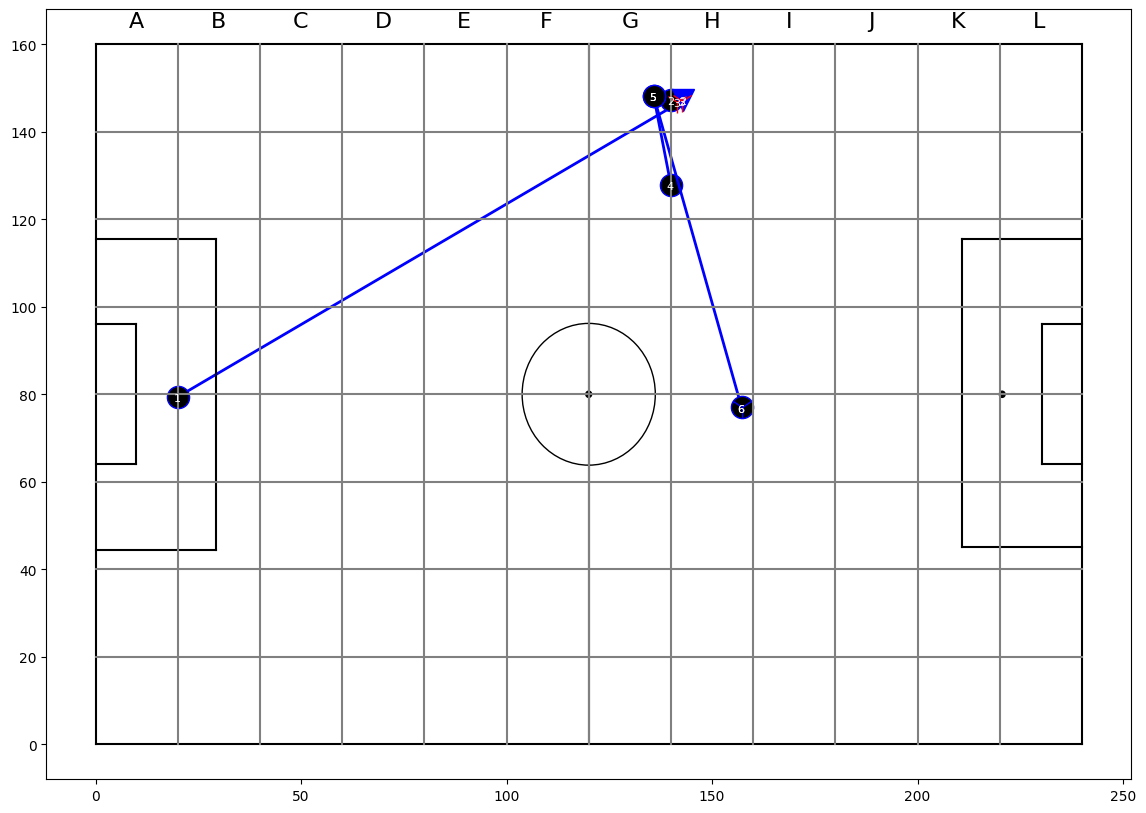

Sequence: 23
Team: Poland
1: Kamil Jóźwiak (Ball Recovery) <00:10:42.118>
1: Kamil Jóźwiak (Carry) <00:10:42.118>
1: Kamil Jóźwiak (Pass) <00:10:50.369>
2: Bartosz Bereszyński (Ball Receipt*) <00:10:51.590>
2: Bartosz Bereszyński (Carry) <00:10:51.590>
2: Bartosz Bereszyński (Pass) <00:10:52.977>
3: Kamil Glik (Ball Receipt*) <00:10:54.537>
3: Kamil Glik (Carry) <00:10:54.537>
3: Kamil Glik (Pass) <00:10:55.344>
4: Jan Bednarek (Ball Receipt*) <00:10:56.723>
4: Jan Bednarek (Carry) <00:10:56.723>
4: Jan Bednarek (Pass) <00:11:00.859>
5: Kamil Glik (Ball Receipt*) <00:11:02.511>
5: Kamil Glik (Carry) <00:11:02.511>
5: Kamil Glik (Pass) <00:11:03.540>
6: Bartosz Bereszyński (Ball Receipt*) <00:11:04.755>
6: Bartosz Bereszyński (Carry) <00:11:04.755>
6: Bartosz Bereszyński (Pass) <00:11:05.687>
7: Kamil Jóźwiak (Ball Receipt*) <00:11:07.024>
7: Kamil Jóźwiak (Carry) <00:11:07.024>
7: Kamil Jóźwiak (Pass) <00:11:09.406>
8: Piotr Zieliński (Ball Receipt*) <00:11:10.434>
8: Piotr Zieliński (

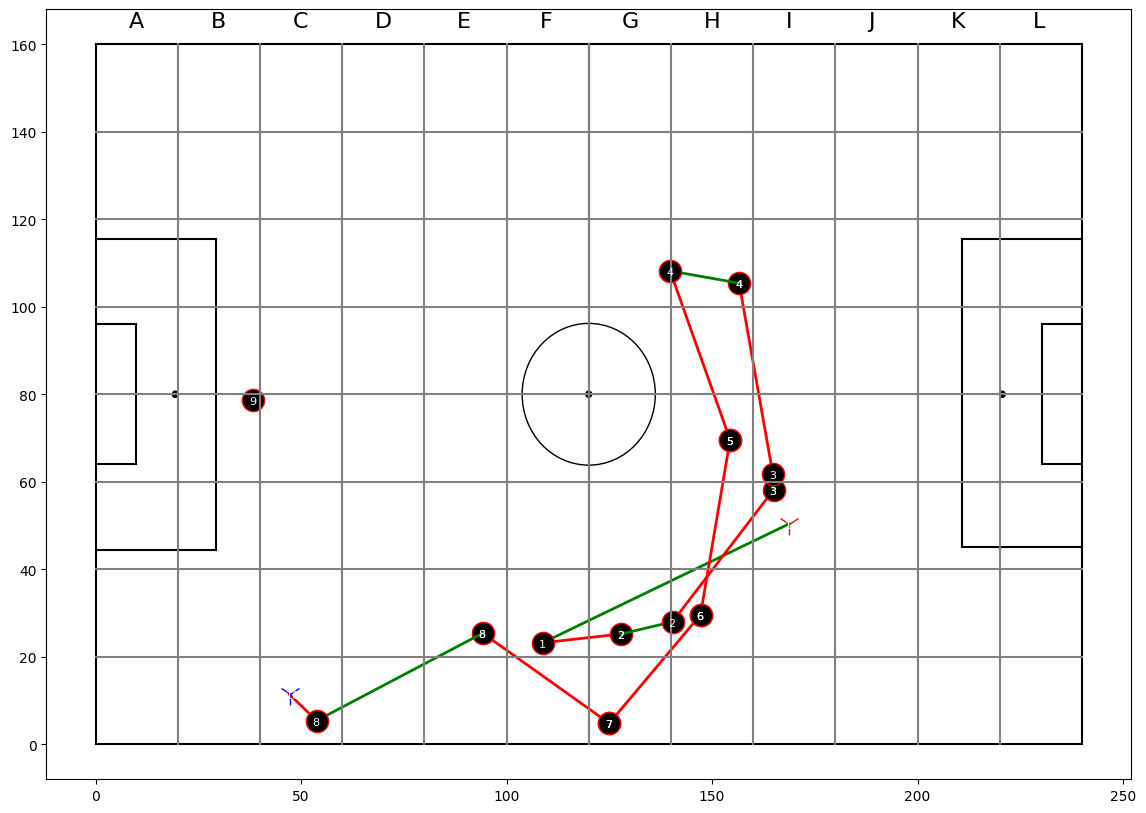

Sequence: 24
Team: Poland
1: Kamil Jóźwiak (Pass) <00:11:22.618>
2: Bartosz Bereszyński (Ball Receipt*) <00:11:24.444>
2: Bartosz Bereszyński (Carry) <00:11:24.444>
2: Bartosz Bereszyński (Pass) <00:11:25.672>
3: Kamil Glik (Ball Receipt*) <00:11:27.297>
3: Kamil Glik (Carry) <00:11:27.297>
3: Kamil Glik (Pass) <00:11:28.899>
4: Tymoteusz Puchacz (Ball Receipt*) <00:11:31.737>
4: Tymoteusz Puchacz (Carry) <00:11:31.737>
4: Tymoteusz Puchacz (Pass) <00:11:34.279>
5: Jan Bednarek (Ball Receipt*) <00:11:34.990>
5: Jan Bednarek (Carry) <00:11:34.990>
5: Jan Bednarek (Pass) <00:11:36.191>
6: Kamil Glik (Ball Receipt*) <00:11:37.713>
6: Kamil Glik (Carry) <00:11:37.713>
6: Kamil Glik (Pass) <00:11:38.972>
7: Bartosz Bereszyński (Ball Receipt*) <00:11:40.290>
7: Bartosz Bereszyński (Carry) <00:11:40.290>
7: Bartosz Bereszyński (Pass) <00:11:41.921>
8: Karol Świderski (Ball Receipt*) <00:11:43.670>
8: Karol Świderski (Pass) <00:11:43.670>
9: Robin Olsen (Ball Recovery) <00:11:48.171>
9: Robin 

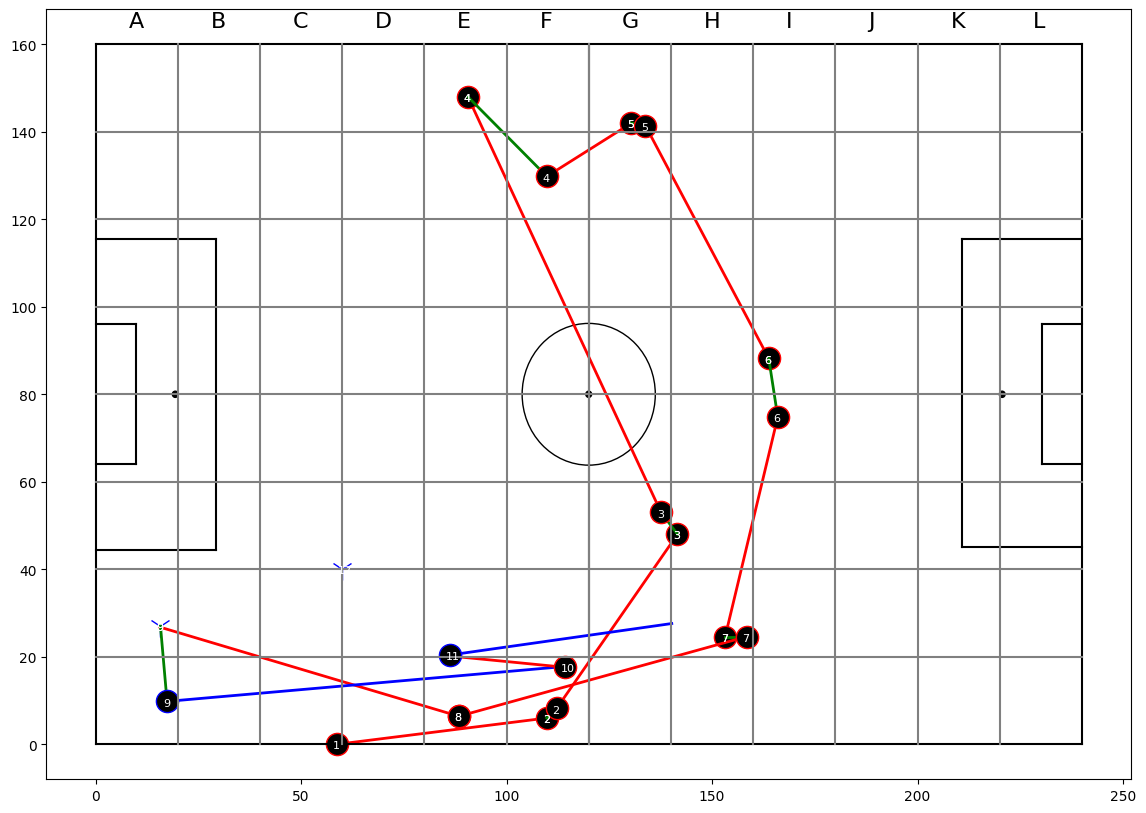

Sequence: 25
Team: Poland
1: Kamil Jóźwiak (Injury Stoppage) <00:11:58.725>
2: Grzegorz Krychowiak (Pass) <00:12:22.115>
3: Kamil Glik (Ball Receipt*) <00:12:22.721>
3: Kamil Glik (Pass) <00:12:24.308>
4: Jan Bednarek (Ball Receipt*) <00:12:25.780>
4: Jan Bednarek (Carry) <00:12:25.780>
4: Jan Bednarek (Pass) <00:12:29.131>
5: Bartosz Bereszyński (Ball Receipt*) <00:12:31.414>
5: Bartosz Bereszyński (Carry) <00:12:31.414>
5: Bartosz Bereszyński (Pass) <00:12:33.349>
6: Grzegorz Krychowiak (Ball Receipt*) <00:12:34.311>
6: Grzegorz Krychowiak (Carry) <00:12:34.311>
6: Grzegorz Krychowiak (Pass) <00:12:35.073>
7: Bartosz Bereszyński (Ball Receipt*) <00:12:36.443>
7: Bartosz Bereszyński (Carry) <00:12:36.443>
7: Bartosz Bereszyński (Pass) <00:12:37.601>
8: Kamil Glik (Ball Receipt*) <00:12:38.921>
8: Kamil Glik (Carry) <00:12:38.921>
8: Kamil Glik (Pass) <00:12:39.976>
9: Jan Bednarek (Ball Receipt*) <00:12:41.467>
9: Jan Bednarek (Carry) <00:12:41.467>
9: Jan Bednarek (Dispossessed) <00:

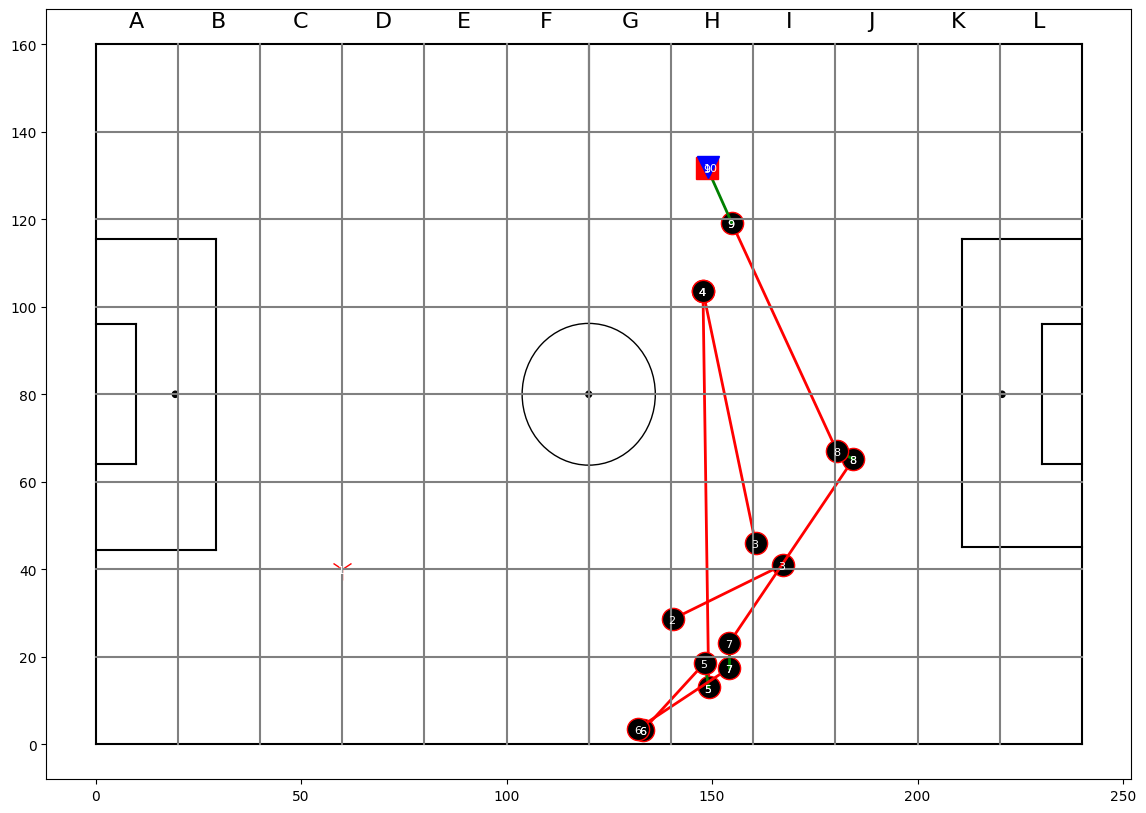

Sequence: 26
Team: Poland
1: Tymoteusz Puchacz (Pass) <00:12:53.096>
2: Jan Bednarek (Ball Receipt*) <00:12:53.991>
2: Jan Bednarek (Carry) <00:12:53.991>
2: Jan Bednarek (Pass) <00:12:54.623>
3: Tymoteusz Puchacz (Ball Receipt*) <00:12:55.340>
4: Alexander Isak (Interception) <00:12:55.340>


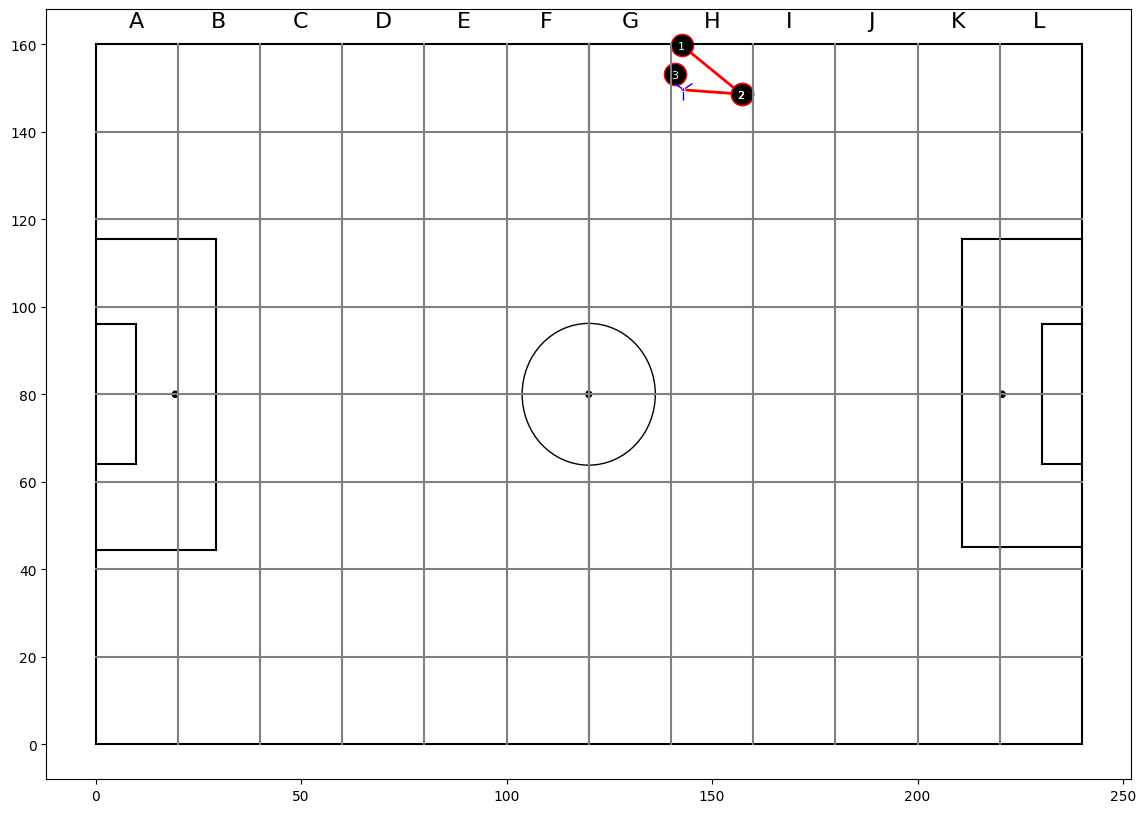

Sequence: 27
Team: Sweden
1: Mikael Lustig (Ball Recovery) <00:12:57.448>
1: Mikael Lustig (Carry) <00:12:57.448>
1: Mikael Lustig (Pass) <00:12:58.578>
2: Robin Quaison (Ball Receipt*) <00:13:00.169>
2: Robin Quaison (Pass) <00:13:00.169>
3: Alexander Isak (Ball Receipt*) <00:13:01.267>
3: Alexander Isak (Carry) <00:13:01.267>
3: Alexander Isak (Pass) <00:13:04.376>
4: Emil Peter Forsberg (Ball Receipt*) <00:13:05.583>
4: Emil Peter Forsberg (Carry) <00:13:05.583>
4: Emil Peter Forsberg (Pass) <00:13:09.874>
5: Mikael Lustig (Ball Receipt*) <00:13:12.929>
5: Mikael Lustig (Carry) <00:13:12.929>
5: Mikael Lustig (Pass) <00:13:12.969>
6: Jan Bednarek (Clearance) <00:13:13.759>
7: Mikael Lustig (Ball Recovery) <00:13:16.780>
7: Mikael Lustig (Carry) <00:13:16.780>
7: Mikael Lustig (Pass) <00:13:18.084>
8: Sebastian Larsson (Ball Receipt*) <00:13:19.281>
8: Sebastian Larsson (Carry) <00:13:19.281>
8: Sebastian Larsson (Pass) <00:13:20.174>
9: Piotr Zieliński (Interception) <00:13:21.476>


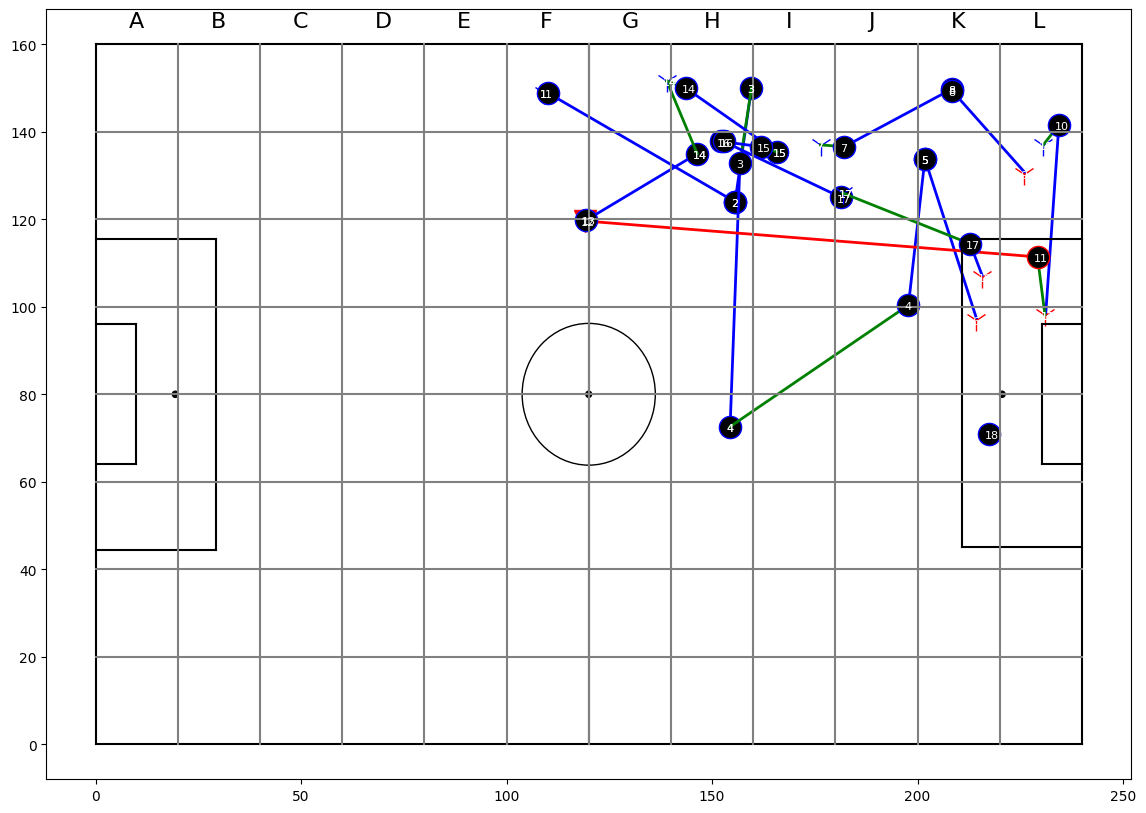

Sequence: 28
Team: Sweden
1: Sebastian Larsson (Pass) <00:14:23.522>
2: Victor Nilsson Lindelöf (Ball Receipt*) <00:14:24.793>
3: Jan Bednarek (Duel) <00:14:24.803>
4: Victor Nilsson Lindelöf (Miscontrol) <00:14:24.803>
5: Mikael Lustig (Pass) <00:14:27.026>
6: Grzegorz Krychowiak (Duel) <00:14:27.026>
7: Jan Bednarek (Pass) <00:14:27.517>
8: Grzegorz Krychowiak (Ball Receipt*) <00:14:28.097>
8: Grzegorz Krychowiak (Carry) <00:14:28.097>
8: Grzegorz Krychowiak (Pass) <00:14:28.292>


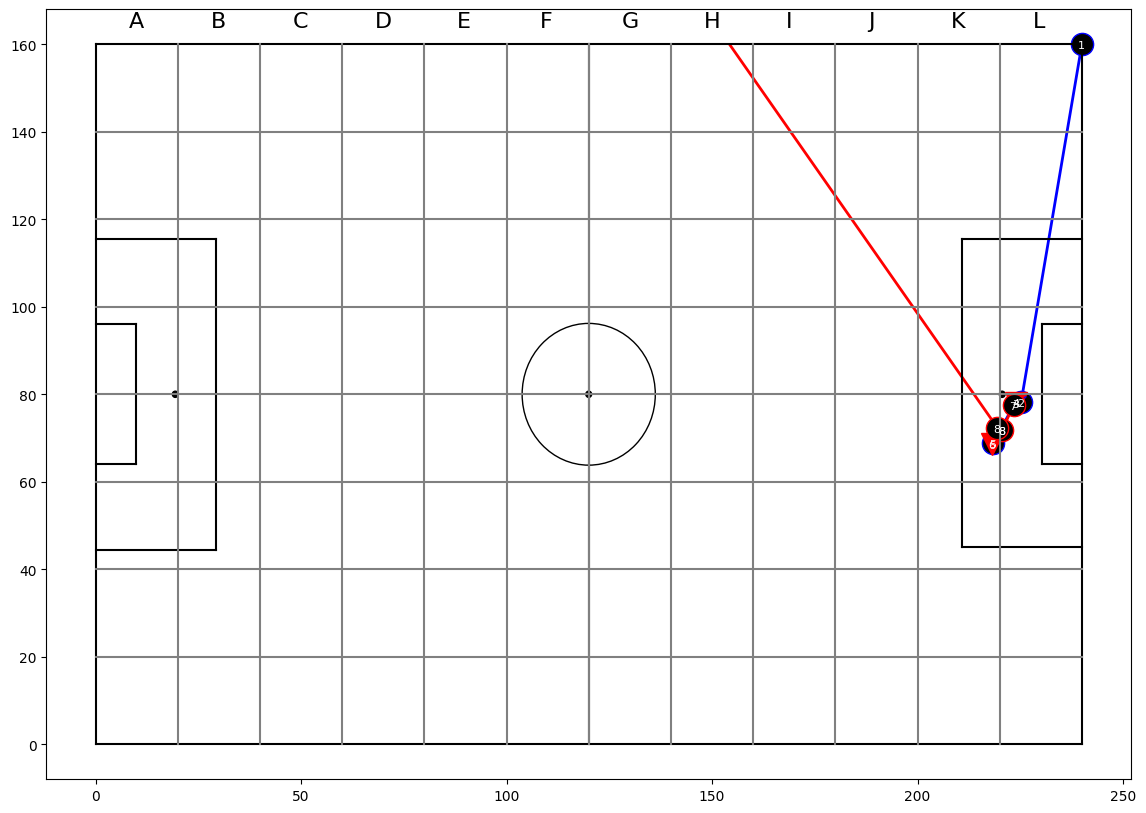

Sequence: 29
Team: Sweden
1: Mikael Lustig (Pass) <00:14:57.513>
2: Albin Ekdal (Ball Receipt*) <00:14:58.451>
2: Albin Ekdal (Pass) <00:14:58.451>
3: Mikael Lustig (Ball Receipt*) <00:14:59.401>
3: Mikael Lustig (Carry) <00:14:59.401>
3: Mikael Lustig (Pass) <00:14:59.910>


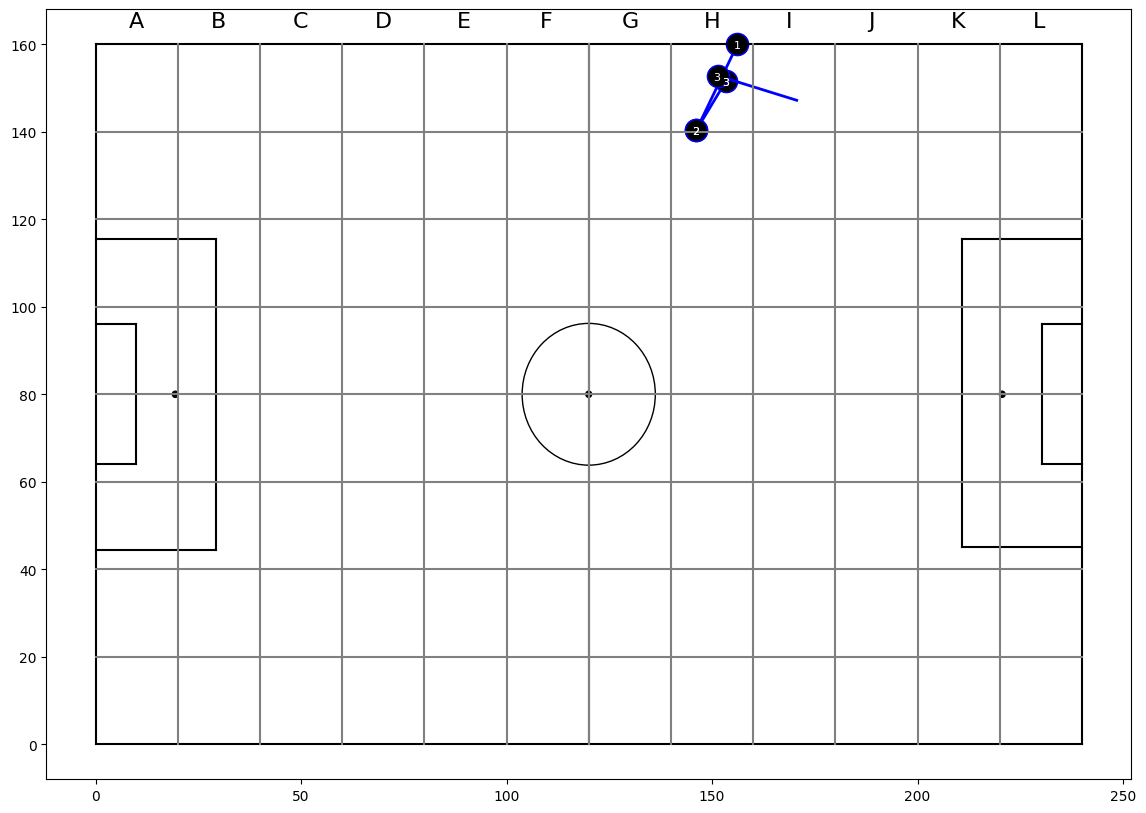

Sequence: 30
Team: Poland
1: Tymoteusz Puchacz (Pass) <00:15:01.471>
2: Karol Świderski (Ball Receipt*) <00:15:02.104>
2: Karol Świderski (Carry) <00:15:02.104>
2: Karol Świderski (Miscontrol) <00:15:03.334>
3: Piotr Zieliński (Ball Recovery) <00:15:04.521>
3: Piotr Zieliński (Carry) <00:15:04.521>
3: Piotr Zieliński (Pass) <00:15:06.849>
4: Tymoteusz Puchacz (Ball Receipt*) <00:15:08.758>
4: Tymoteusz Puchacz (Carry) <00:15:08.758>
4: Tymoteusz Puchacz (Pass) <00:15:11.128>
5: Victor Nilsson Lindelöf (Block) <00:15:11.466>
5: Victor Nilsson Lindelöf (Clearance) <00:15:13.919>
6: Jan Bednarek (Interception) <00:15:16.717>


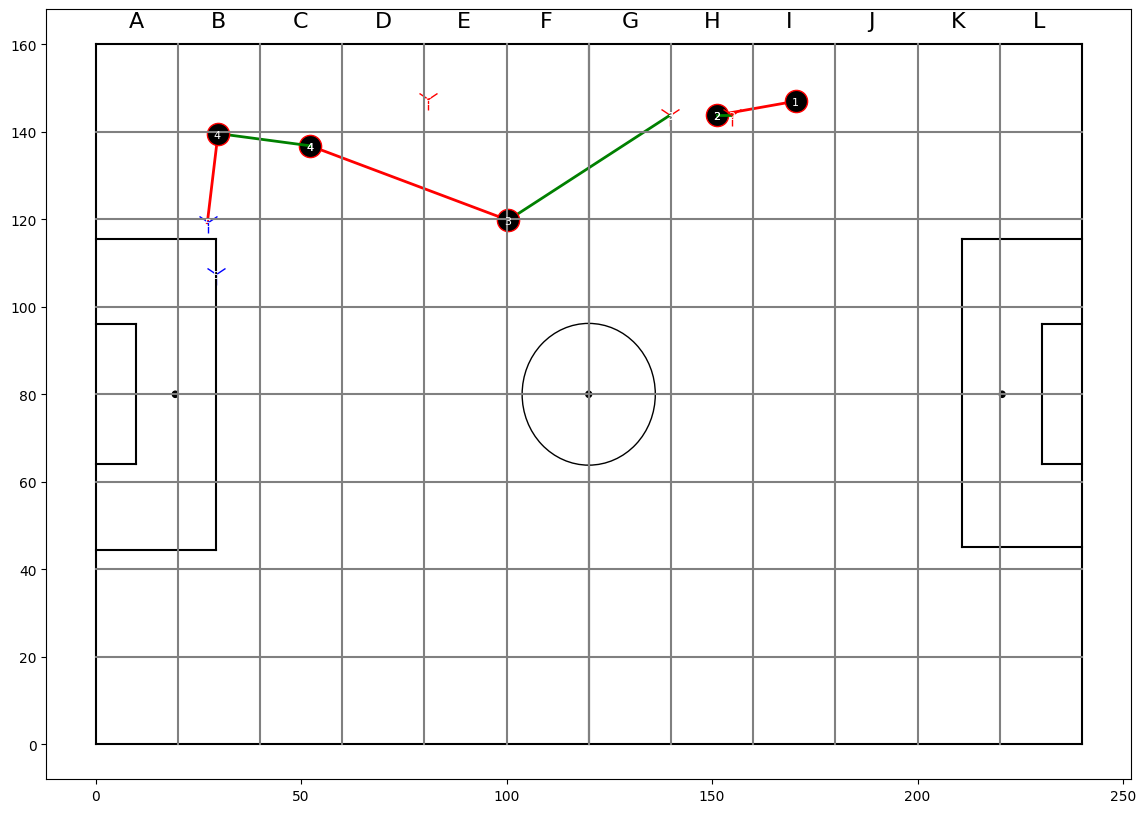

Sequence: 31
Team: Sweden
1: Mikael Lustig (Pass) <00:15:33.106>
2: Sebastian Larsson (Ball Receipt*) <00:15:34.035>
2: Sebastian Larsson (Pass) <00:15:34.035>
3: Mikael Lustig (Ball Receipt*) <00:15:35.187>
3: Mikael Lustig (Pass) <00:15:35.187>
4: Robin Quaison (Foul Committed) <00:15:39.777>
5: Kamil Glik (Foul Won) <00:15:39.777>


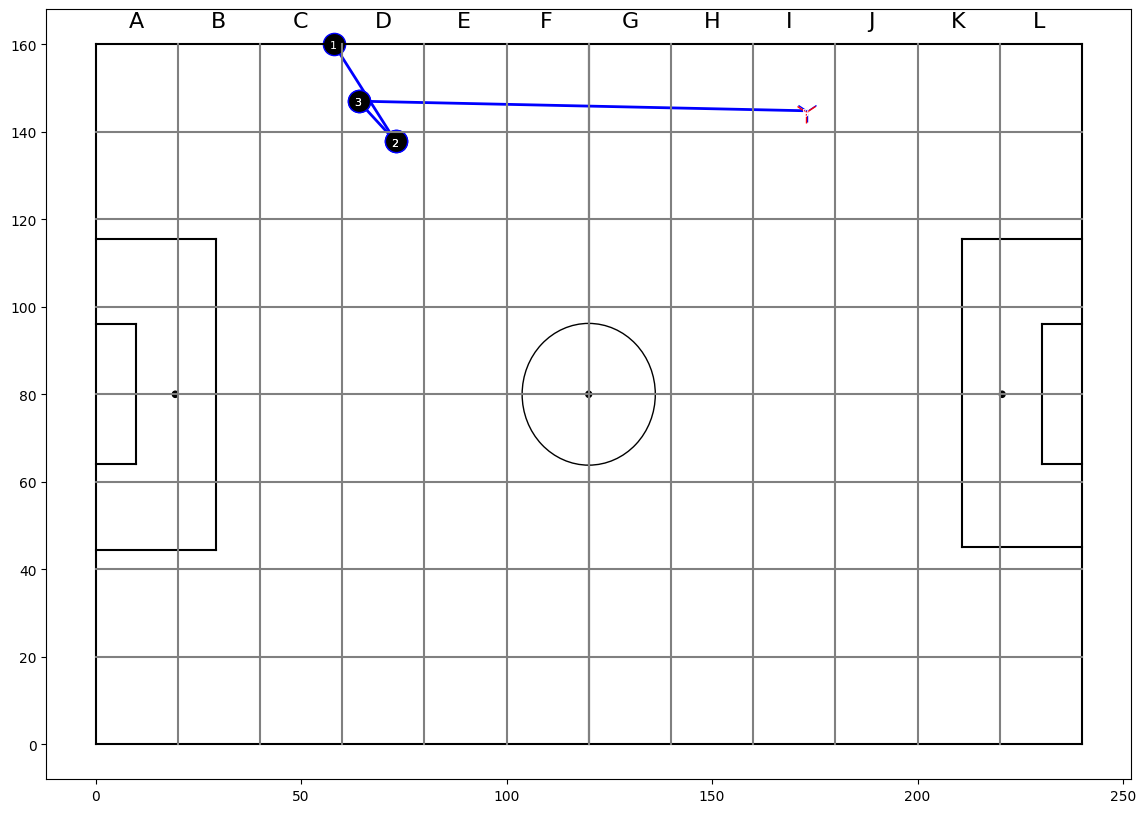

Sequence: 32
Team: Poland
1: Wojciech Szczęsny (Pass) <00:16:05.530>
2: Marcus Andreas Danielsson (Clearance) <00:16:09.421>
3: Kristoffer Olsson (Pass) <00:16:10.561>
4: Jan Bednarek (Pass) <00:16:12.281>
5: Piotr Zieliński (Ball Receipt*) <00:16:13.047>
5: Piotr Zieliński (Carry) <00:16:13.047>
5: Piotr Zieliński (Pass) <00:16:14.206>
6: Robert Lewandowski (Ball Receipt*) <00:16:15.274>
6: Robert Lewandowski (Carry) <00:16:15.274>
6: Robert Lewandowski (Shot) <00:16:18.086>
7: Marcus Andreas Danielsson (Block) <00:16:18.226>


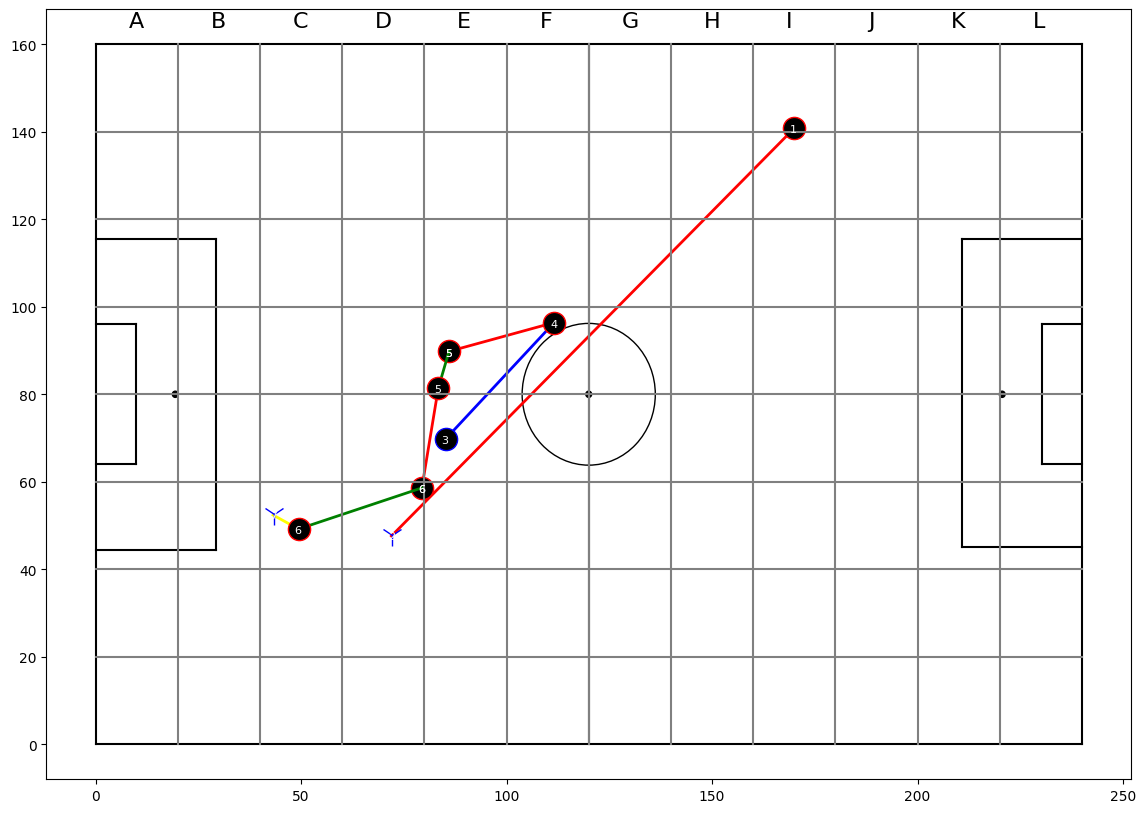

Sequence: 33
Team: Poland
1: Piotr Zieliński (Pass) <00:16:39.962>
2: Robert Lewandowski (Ball Receipt*) <00:16:41.310>
2: Robert Lewandowski (Shot) <00:16:41.361>
2: Robert Lewandowski (Ball Recovery) <00:16:42.701>
2: Robert Lewandowski (Shot) <00:16:42.804>
2: Robert Lewandowski (Ball Recovery) <00:16:43.434>
3: Grzegorz Krychowiak (Ball Recovery) <00:16:43.964>
4: Mikael Lustig (Ball Recovery) <00:16:44.194>
4: Mikael Lustig (Carry) <00:16:44.194>
4: Mikael Lustig (Pass) <00:16:47.136>
5: Kristoffer Olsson (Ball Receipt*) <00:16:51.083>
6: Bartosz Bereszyński (Pass) <00:16:51.083>
7: Wojciech Szczęsny (Ball Receipt*) <00:16:53.636>
7: Wojciech Szczęsny (Carry) <00:16:53.636>
7: Wojciech Szczęsny (Pass) <00:16:56.218>
8: Mateusz Andrzej Klich (Ball Receipt*) <00:16:57.412>
8: Mateusz Andrzej Klich (Injury Stoppage) <00:17:03.360>


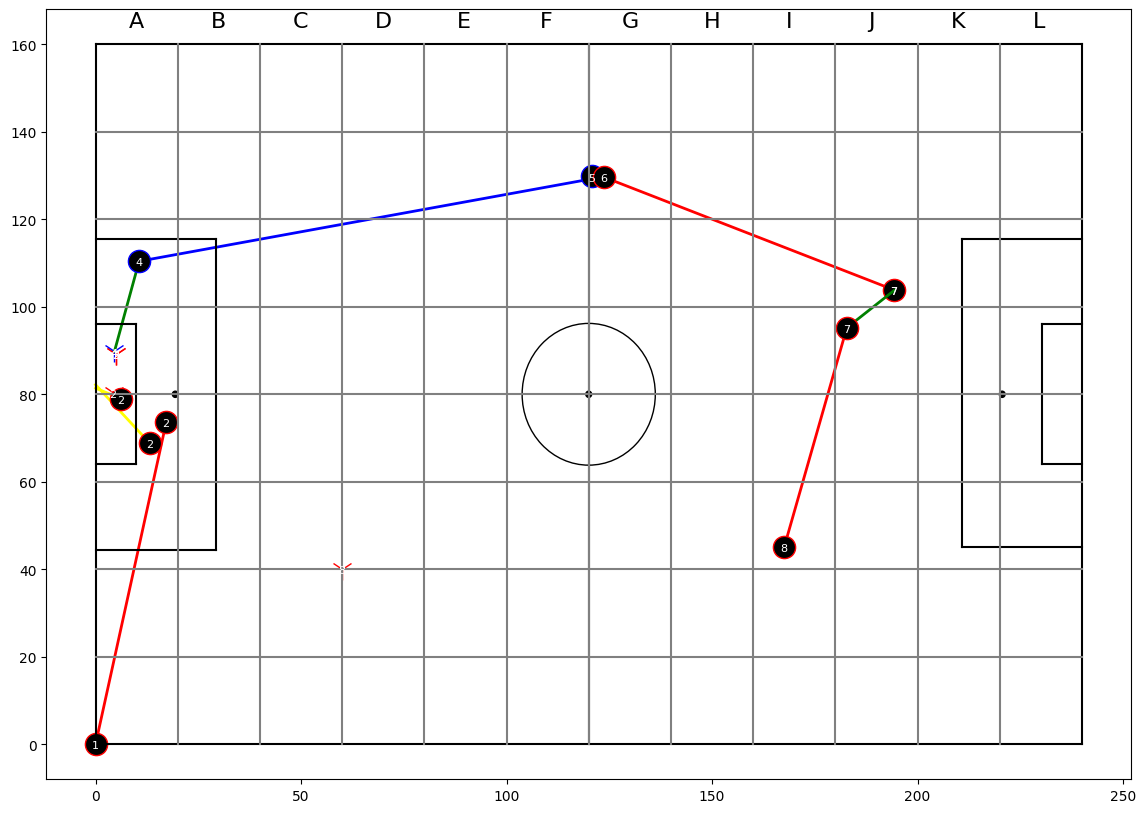

Sequence: 34
Team: Poland
1: Robin Olsen (Injury Stoppage) <00:17:10.752>


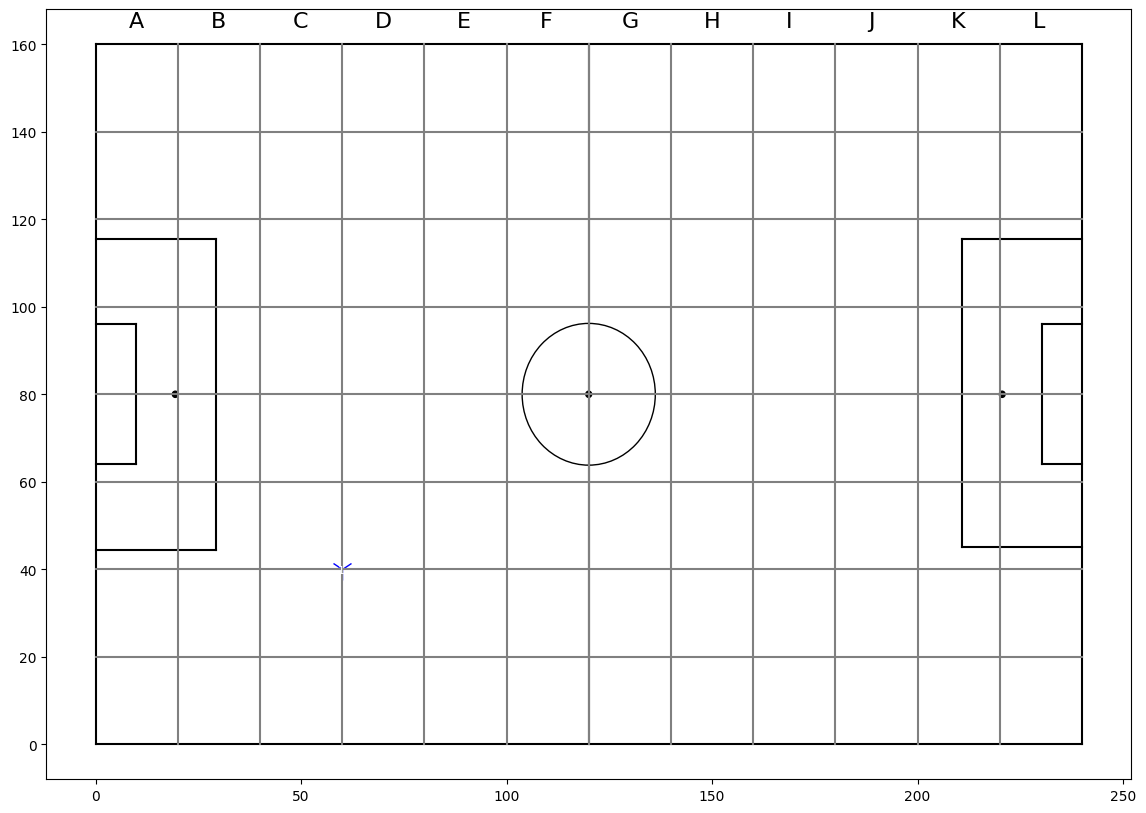

Sequence: 35
Team: Poland
1: Kamil Glik (Ball Recovery) <00:18:48.951>
1: Kamil Glik (Carry) <00:18:48.951>
1: Kamil Glik (Pass) <00:18:50.040>
2: Jan Bednarek (Ball Receipt*) <00:18:51.504>
2: Jan Bednarek (Carry) <00:18:51.504>
2: Jan Bednarek (Pass) <00:18:53.181>
3: Mateusz Andrzej Klich (Ball Receipt*) <00:18:54.193>
3: Mateusz Andrzej Klich (Carry) <00:18:54.193>
3: Mateusz Andrzej Klich (Pass) <00:18:57.576>
4: Bartosz Bereszyński (Ball Receipt*) <00:18:59.462>
4: Bartosz Bereszyński (Carry) <00:18:59.462>
4: Bartosz Bereszyński (Pass) <00:19:01.262>
5: Kamil Jóźwiak (Ball Receipt*) <00:19:02.699>
5: Kamil Jóźwiak (Carry) <00:19:02.699>
5: Kamil Jóźwiak (Pass) <00:19:03.555>
6: Karol Świderski (Ball Receipt*) <00:19:05.733>


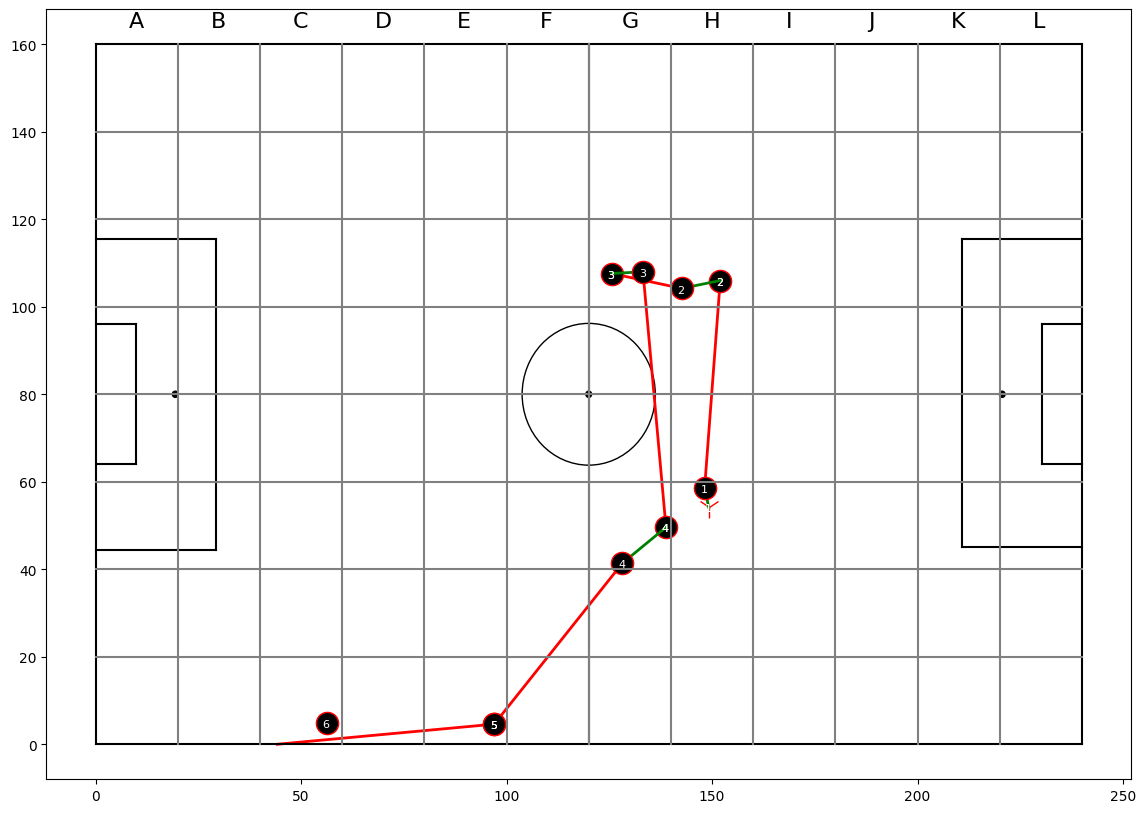

Sequence: 36
Team: Sweden
1: Ludwig Augustinsson (Pass) <00:19:21.110>
2: Robin Quaison (Ball Receipt*) <00:19:22.902>
3: Grzegorz Krychowiak (Pass) <00:19:22.902>
4: Robin Quaison (Duel) <00:19:22.902>
5: Piotr Zieliński (Duel) <00:19:24.909>
6: Kristoffer Olsson (Pass) <00:19:24.909>
7: Grzegorz Krychowiak (Pass) <00:19:26.431>
8: Karol Świderski (Ball Receipt*) <00:19:27.844>
9: Marcus Andreas Danielsson (Duel) <00:19:27.844>
10: Karol Świderski (Pass) <00:19:27.844>
11: Piotr Zieliński (Foul Committed) <00:19:29.084>
12: Albin Ekdal (Foul Won) <00:19:29.084>
13: Robin Olsen (Pass) <00:20:06.489>
14: Alexander Isak (Ball Receipt*) <00:20:11.815>
14: Alexander Isak (Carry) <00:20:11.815>
14: Alexander Isak (Pass) <00:20:13.142>
15: Sebastian Larsson (Ball Receipt*) <00:20:13.818>
15: Sebastian Larsson (Pass) <00:20:13.818>
16: Jan Bednarek (Interception) <00:20:16.201>


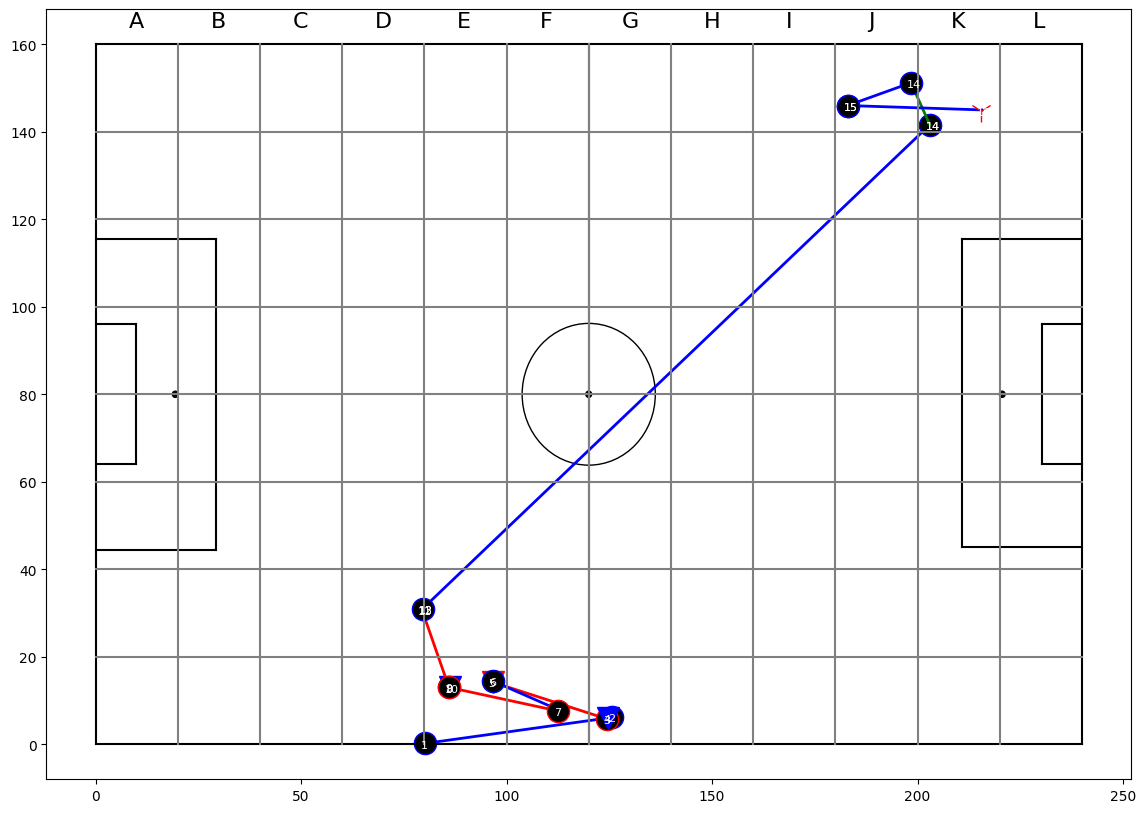

Sequence: 37
Team: Sweden
1: Victor Nilsson Lindelöf (Pass) <00:20:45.004>
2: Kamil Jóźwiak (Clearance) <00:20:46.709>
3: Victor Nilsson Lindelöf (Ball Recovery) <00:20:48.495>
3: Victor Nilsson Lindelöf (Carry) <00:20:48.495>
3: Victor Nilsson Lindelöf (Pass) <00:20:50.207>
4: Kristoffer Olsson (Ball Receipt*) <00:20:52.057>
4: Kristoffer Olsson (Carry) <00:20:52.057>
4: Kristoffer Olsson (Miscontrol) <00:20:56.266>
5: Mateusz Andrzej Klich (Block) <00:20:56.432>


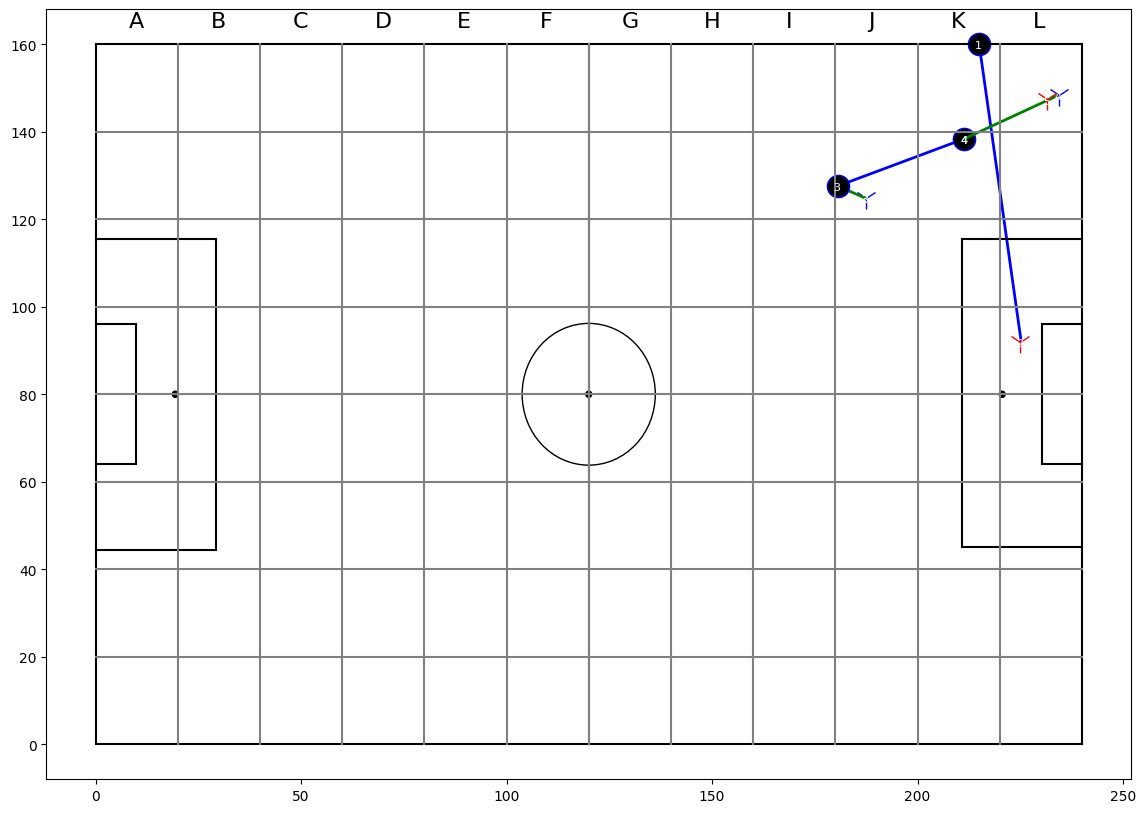

Sequence: 38
Team: Poland
1: Mateusz Andrzej Klich (Ball Recovery) <00:20:57.421>
1: Mateusz Andrzej Klich (Carry) <00:20:57.421>
1: Mateusz Andrzej Klich (Pass) <00:21:00.704>
2: Kristoffer Olsson (Block) <00:21:00.840>


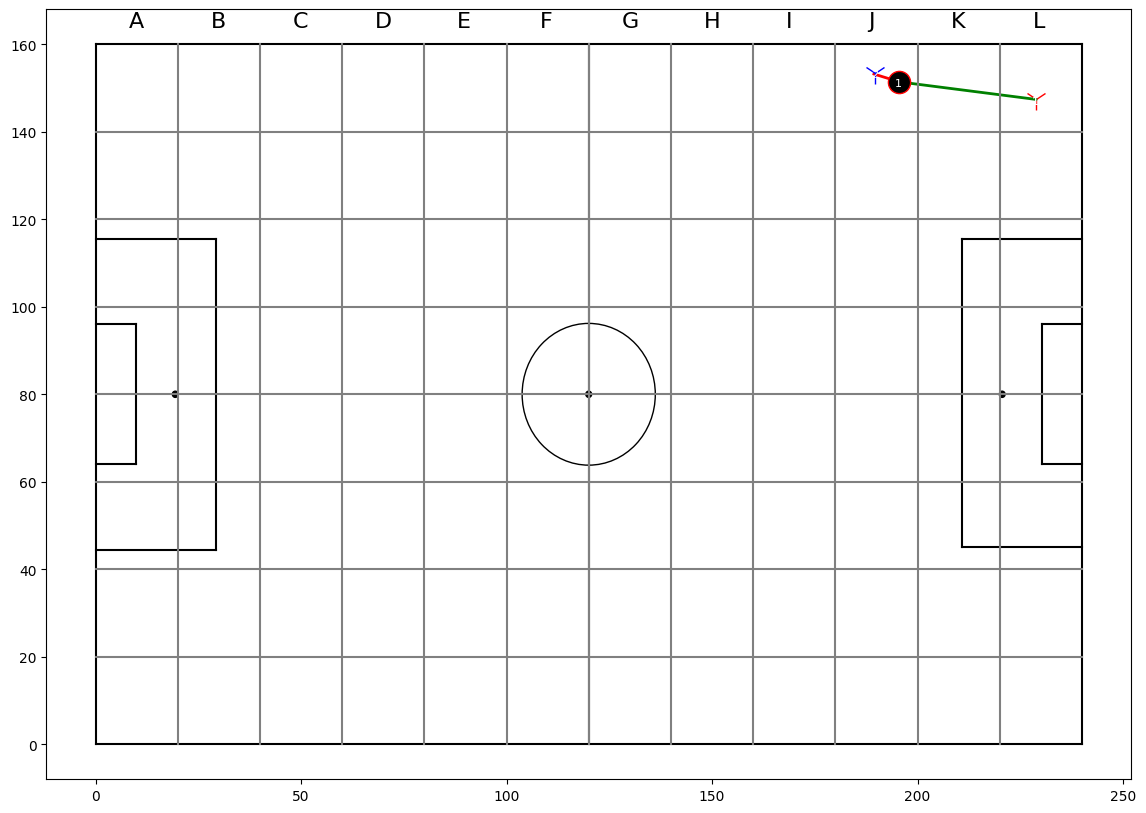

Sequence: 39
Team: Poland
1: Tymoteusz Puchacz (Pass) <00:21:19.105>
2: Grzegorz Krychowiak (Ball Receipt*) <00:21:19.925>
2: Grzegorz Krychowiak (Pass) <00:21:19.925>
3: Tymoteusz Puchacz (Ball Receipt*) <00:21:20.815>
3: Tymoteusz Puchacz (Carry) <00:21:20.815>
3: Tymoteusz Puchacz (Pass) <00:21:21.496>
4: Alexander Isak (Block) <00:21:21.516>
5: Jan Bednarek (Clearance) <00:21:24.882>


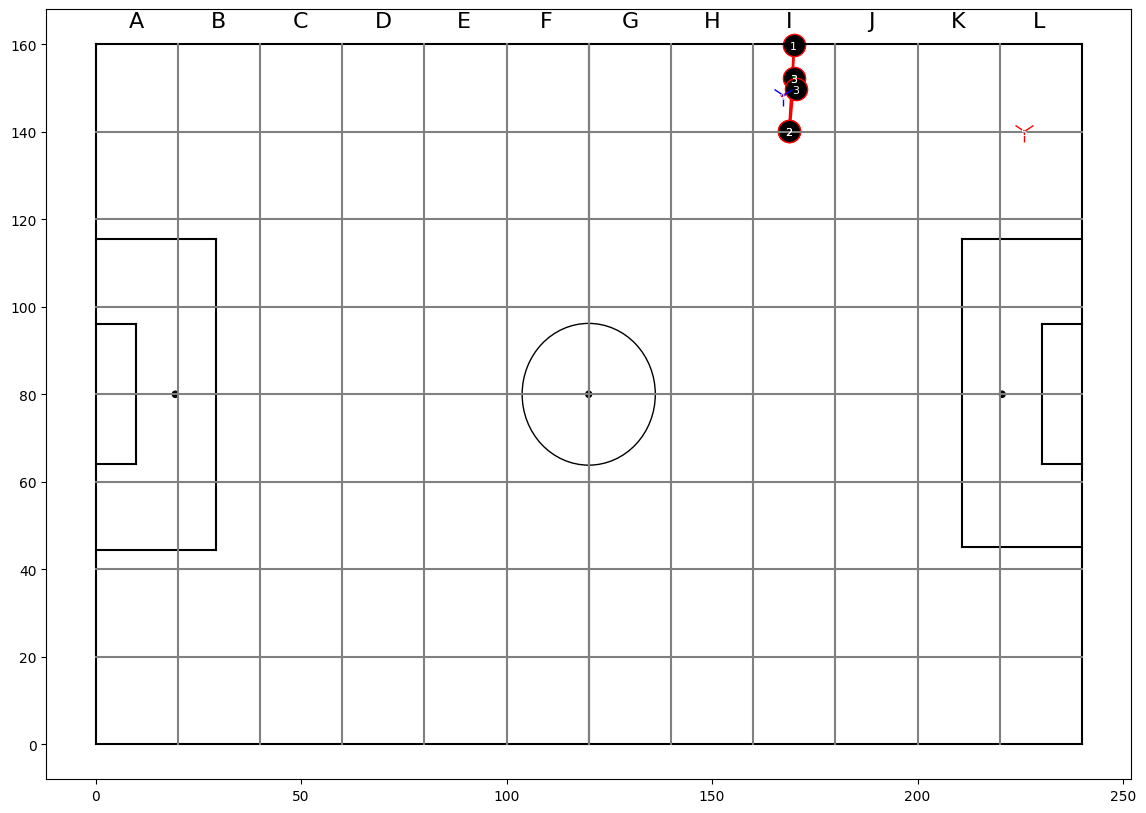

Sequence: 40
Team: Sweden
1: Victor Nilsson Lindelöf (Pass) <00:21:55.773>
2: Mikael Lustig (Duel) <00:21:57.764>
3: Bartosz Bereszyński (Clearance) <00:21:57.764>
4: Kristoffer Olsson (Ball Recovery) <00:22:01.359>
4: Kristoffer Olsson (Carry) <00:22:01.359>
5: Robert Lewandowski (Pass) <00:22:03.499>
6: Piotr Zieliński (Ball Receipt*) <00:22:03.510>
6: Piotr Zieliński (Carry) <00:22:03.510>
7: Kristoffer Olsson (Miscontrol) <00:22:03.510>
8: Piotr Zieliński (Pass) <00:22:08.056>
9: Kristoffer Olsson (Block) <00:22:08.239>


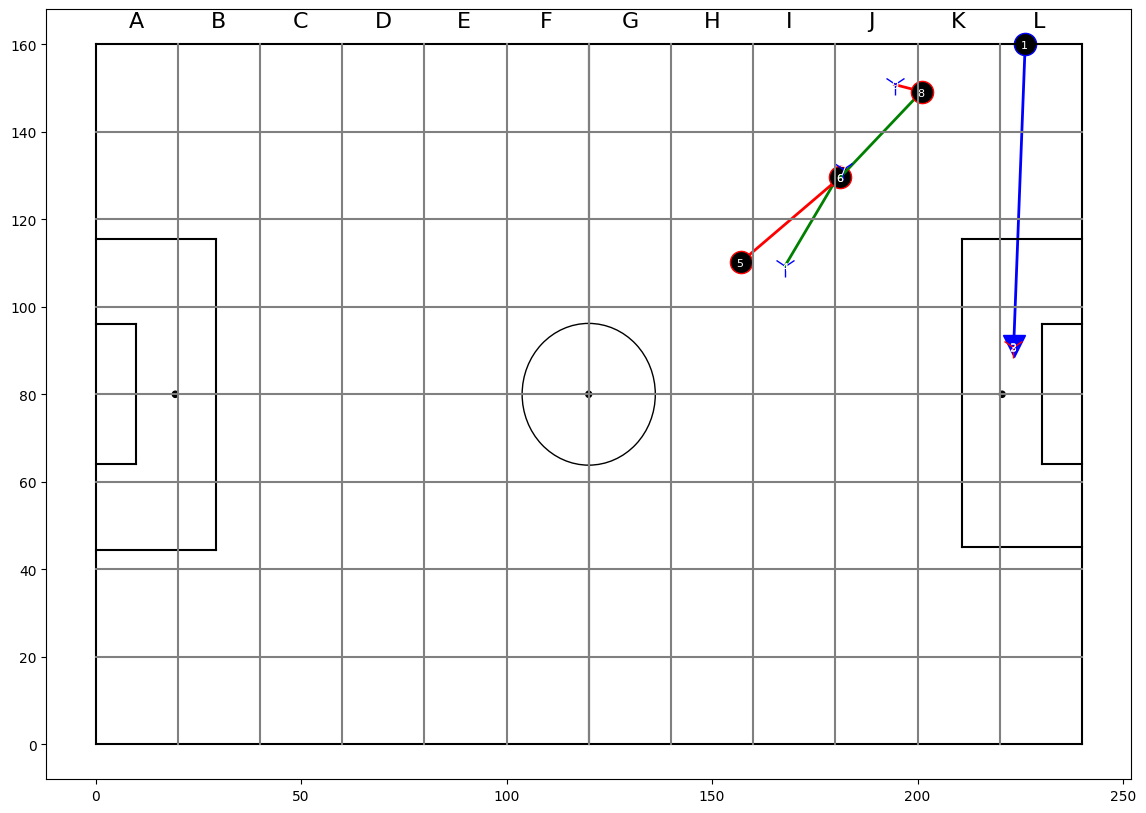

Sequence: 41
Team: Poland
1: Tymoteusz Puchacz (Pass) <00:22:21.060>
2: Kristoffer Olsson (Pass) <00:22:22.413>
3: Sebastian Larsson (Ball Receipt*) <00:22:23.581>
3: Sebastian Larsson (Pass) <00:22:23.581>
4: Wojciech Szczęsny (Ball Recovery) <00:22:28.260>
4: Wojciech Szczęsny (Carry) <00:22:28.260>
4: Wojciech Szczęsny (Pass) <00:22:29.225>
5: Bartosz Bereszyński (Ball Receipt*) <00:22:31.709>
5: Bartosz Bereszyński (Carry) <00:22:31.709>
5: Bartosz Bereszyński (Pass) <00:22:36.007>
6: Jan Bednarek (Ball Receipt*) <00:22:37.239>
6: Jan Bednarek (Carry) <00:22:37.239>
6: Jan Bednarek (Pass) <00:22:38.498>
7: Tymoteusz Puchacz (Ball Receipt*) <00:22:39.826>
7: Tymoteusz Puchacz (Carry) <00:22:39.826>
7: Tymoteusz Puchacz (Pass) <00:22:40.811>
8: Mateusz Andrzej Klich (Ball Receipt*) <00:22:41.418>
8: Mateusz Andrzej Klich (Carry) <00:22:41.418>
8: Mateusz Andrzej Klich (Dispossessed) <00:22:42.193>
9: Mikael Lustig (Duel) <00:22:42.193>


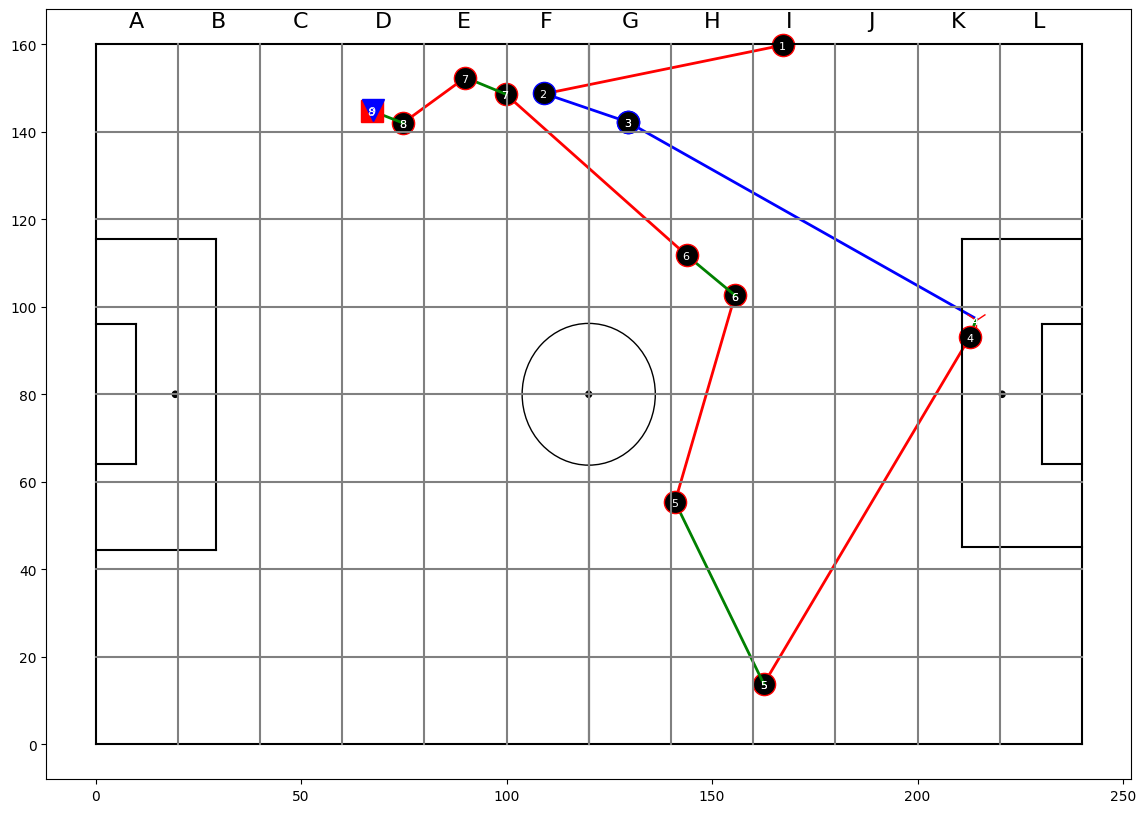

Sequence: 42
Team: Poland
1: Tymoteusz Puchacz (Pass) <00:22:49.711>
2: Piotr Zieliński (Ball Receipt*) <00:22:50.565>
2: Piotr Zieliński (Carry) <00:22:50.565>
2: Piotr Zieliński (Pass) <00:22:50.707>
3: Tymoteusz Puchacz (Ball Receipt*) <00:22:51.491>
3: Tymoteusz Puchacz (Carry) <00:22:51.491>
3: Tymoteusz Puchacz (Pass) <00:22:52.956>
4: Mateusz Andrzej Klich (Ball Receipt*) <00:22:53.614>
4: Mateusz Andrzej Klich (Carry) <00:22:53.614>
4: Mateusz Andrzej Klich (Pass) <00:22:56.034>
5: Jan Bednarek (Ball Receipt*) <00:22:57.359>
5: Jan Bednarek (Carry) <00:22:57.359>
5: Jan Bednarek (Pass) <00:22:58.240>
6: Kamil Glik (Ball Receipt*) <00:23:00.521>
6: Kamil Glik (Carry) <00:23:00.521>
6: Kamil Glik (Pass) <00:23:00.891>
7: Bartosz Bereszyński (Ball Receipt*) <00:23:02.352>
7: Bartosz Bereszyński (Carry) <00:23:02.352>
7: Bartosz Bereszyński (Pass) <00:23:03.638>
8: Emil Peter Forsberg (Block) <00:23:03.886>
9: Kamil Jóźwiak (Pass) <00:23:06.288>
10: Karol Świderski (Ball Receipt*) 

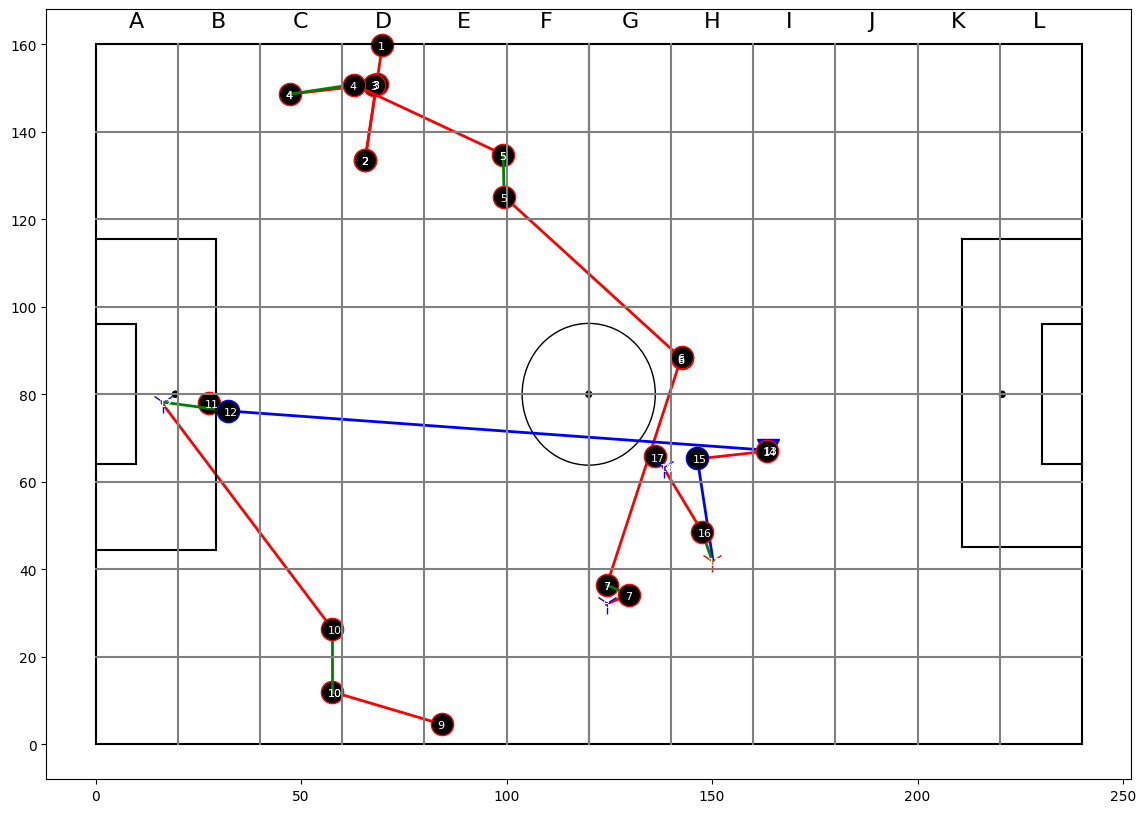

Sequence: 43
Team: Sweden
1: Victor Nilsson Lindelöf (Pass) <00:23:41.851>
2: Sebastian Larsson (Ball Receipt*) <00:23:42.483>
2: Sebastian Larsson (Carry) <00:23:42.483>
2: Sebastian Larsson (Miscontrol) <00:23:42.553>
3: Victor Nilsson Lindelöf (Pass) <00:23:44.083>
4: Mikael Lustig (Ball Receipt*) <00:23:44.646>
4: Mikael Lustig (Pass) <00:23:44.646>
5: Robin Quaison (Ball Receipt*) <00:23:48.230>
5: Robin Quaison (Carry) <00:23:48.230>
6: Bartosz Bereszyński (Ball Recovery) <00:23:48.230>
7: Robin Quaison (Pass) <00:23:49.605>
8: Ludwig Augustinsson (Ball Receipt*) <00:23:51.198>
8: Ludwig Augustinsson (Carry) <00:23:51.198>
8: Ludwig Augustinsson (Pass) <00:23:53.333>
9: Marcus Andreas Danielsson (Ball Receipt*) <00:23:54.352>
9: Marcus Andreas Danielsson (Carry) <00:23:54.352>
9: Marcus Andreas Danielsson (Pass) <00:23:57.268>
10: Robin Olsen (Ball Receipt*) <00:24:00.111>
10: Robin Olsen (Carry) <00:24:00.111>
10: Robin Olsen (Pass) <00:24:02.167>
11: Alexander Isak (Ball Receip

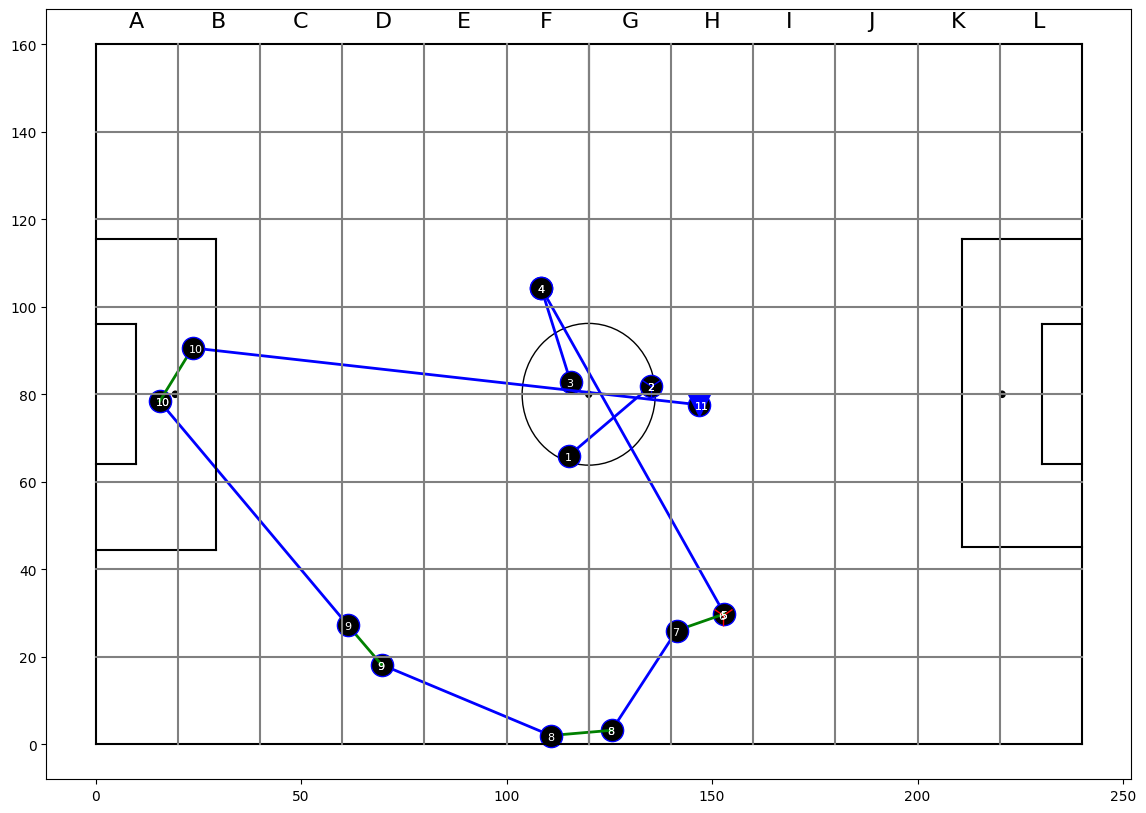

Sequence: 44
Team: Poland
1: Kamil Glik (Pass) <00:24:05.478>
2: Robert Lewandowski (Ball Receipt*) <00:24:07.295>
2: Robert Lewandowski (Pass) <00:24:07.319>
3: Piotr Zieliński (Ball Receipt*) <00:24:08.362>
3: Piotr Zieliński (Carry) <00:24:08.362>
4: Sebastian Larsson (Foul Committed) <00:24:11.284>
5: Piotr Zieliński (Foul Won) <00:24:11.284>
5: Piotr Zieliński (Pass) <00:24:39.702>
6: Robert Lewandowski (Duel) <00:24:41.341>
7: Marcus Andreas Danielsson (Clearance) <00:24:41.341>
8: Albin Ekdal (Ball Recovery) <00:24:46.010>
8: Albin Ekdal (Carry) <00:24:46.010>
8: Albin Ekdal (Pass) <00:24:48.427>
9: Emil Peter Forsberg (Ball Receipt*) <00:24:49.531>
9: Emil Peter Forsberg (Carry) <00:24:49.531>
10: Mateusz Andrzej Klich (Foul Committed) <00:24:50.183>
11: Emil Peter Forsberg (Foul Won) <00:24:50.183>
12: Robin Olsen (Injury Stoppage) <00:25:05.028>


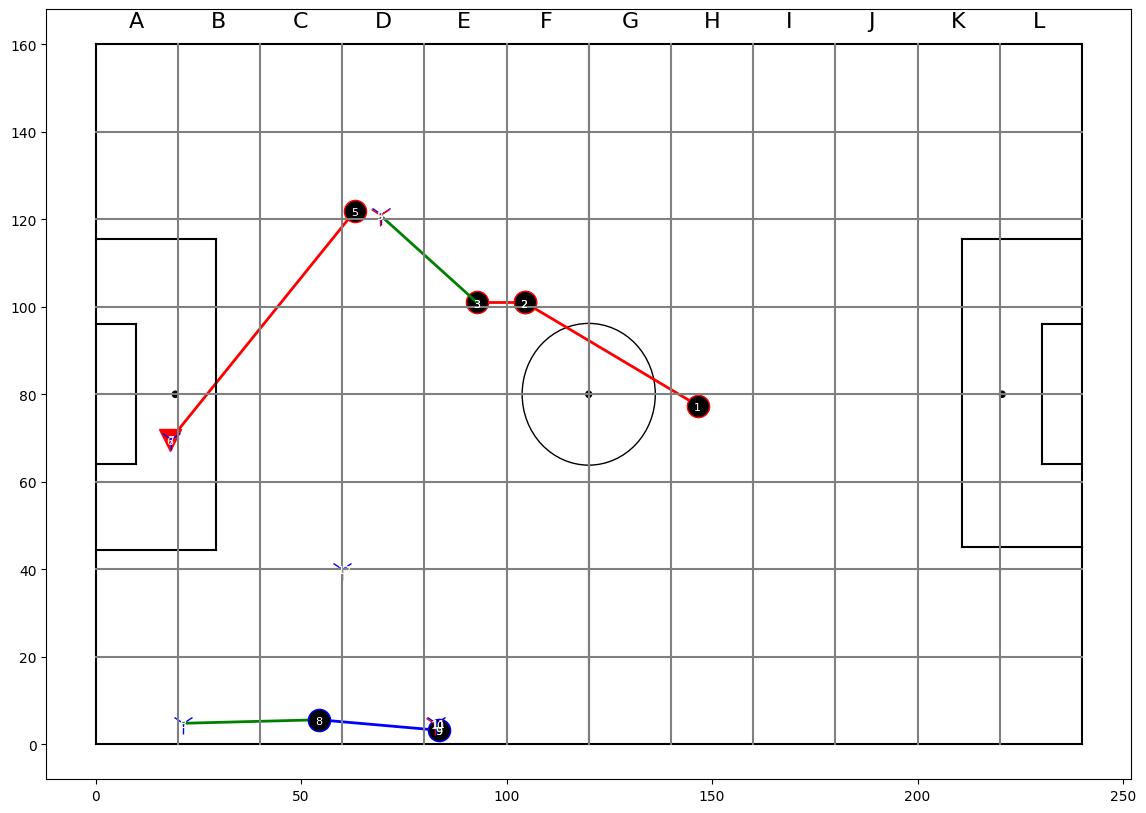

Sequence: 45
Team: Poland
1: Robert Lewandowski (Injury Stoppage) <00:25:15.002>


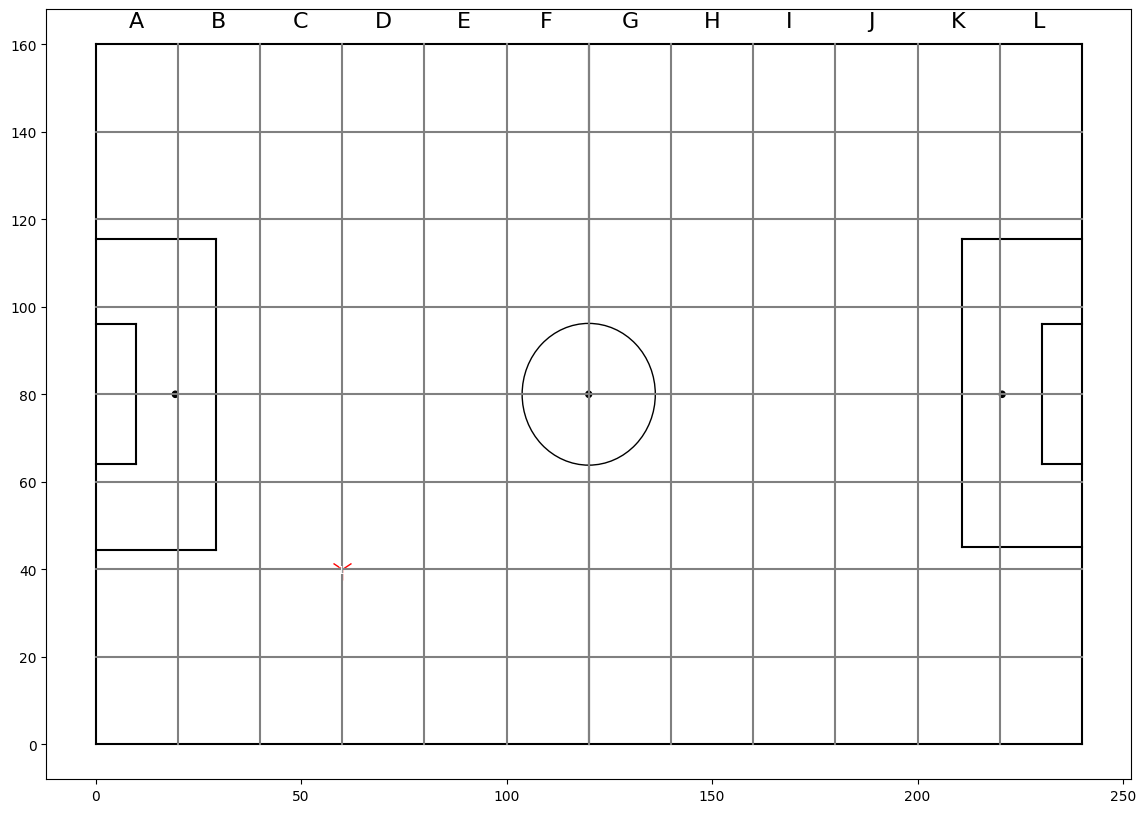

Sequence: 46
Team: Sweden
1: Ludwig Augustinsson (Pass) <00:27:07.725>
2: Grzegorz Krychowiak (Clearance) <00:27:10.623>
3: Robin Quaison (Foul Committed) <00:27:12.937>
4: Tymoteusz Puchacz (Foul Won) <00:27:12.937>


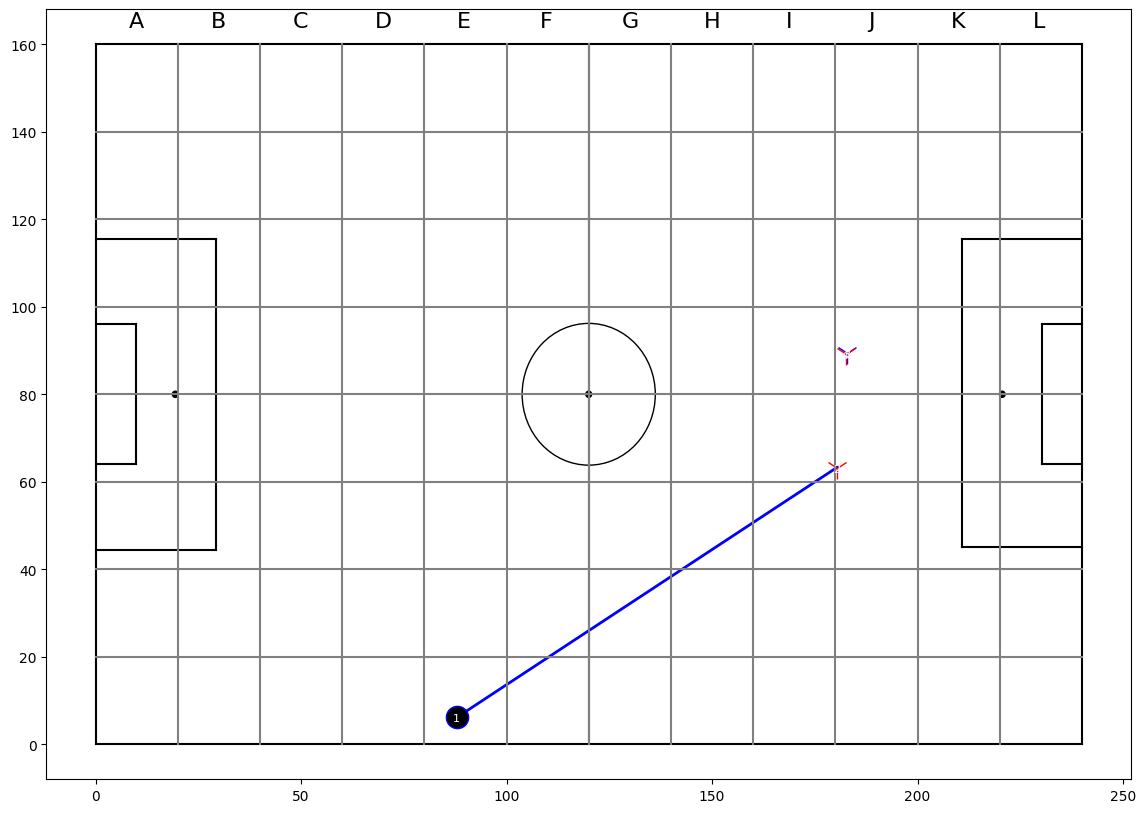

Sequence: 47
Team: Poland
1: Kamil Glik (Pass) <00:27:25.356>
2: Jan Bednarek (Ball Receipt*) <00:27:26.116>
2: Jan Bednarek (Pass) <00:27:30.202>
3: Bartosz Bereszyński (Ball Receipt*) <00:27:31.731>
3: Bartosz Bereszyński (Carry) <00:27:31.731>
3: Bartosz Bereszyński (Pass) <00:27:32.796>
4: Grzegorz Krychowiak (Ball Receipt*) <00:27:33.772>
4: Grzegorz Krychowiak (Carry) <00:27:33.772>
4: Grzegorz Krychowiak (Pass) <00:27:34.464>
5: Kamil Jóźwiak (Ball Receipt*) <00:27:35.442>
5: Kamil Jóźwiak (Carry) <00:27:35.442>
5: Kamil Jóźwiak (Pass) <00:27:39.105>
6: Piotr Zieliński (Ball Receipt*) <00:27:39.686>
6: Piotr Zieliński (Carry) <00:27:39.686>
6: Piotr Zieliński (Pass) <00:27:41.030>
7: Grzegorz Krychowiak (Ball Receipt*) <00:27:42.445>
7: Grzegorz Krychowiak (Carry) <00:27:42.445>
7: Grzegorz Krychowiak (Pass) <00:27:42.532>
8: Bartosz Bereszyński (Ball Receipt*) <00:27:43.875>
8: Bartosz Bereszyński (Carry) <00:27:43.875>
8: Bartosz Bereszyński (Pass) <00:27:45.166>
9: Jan Bednar

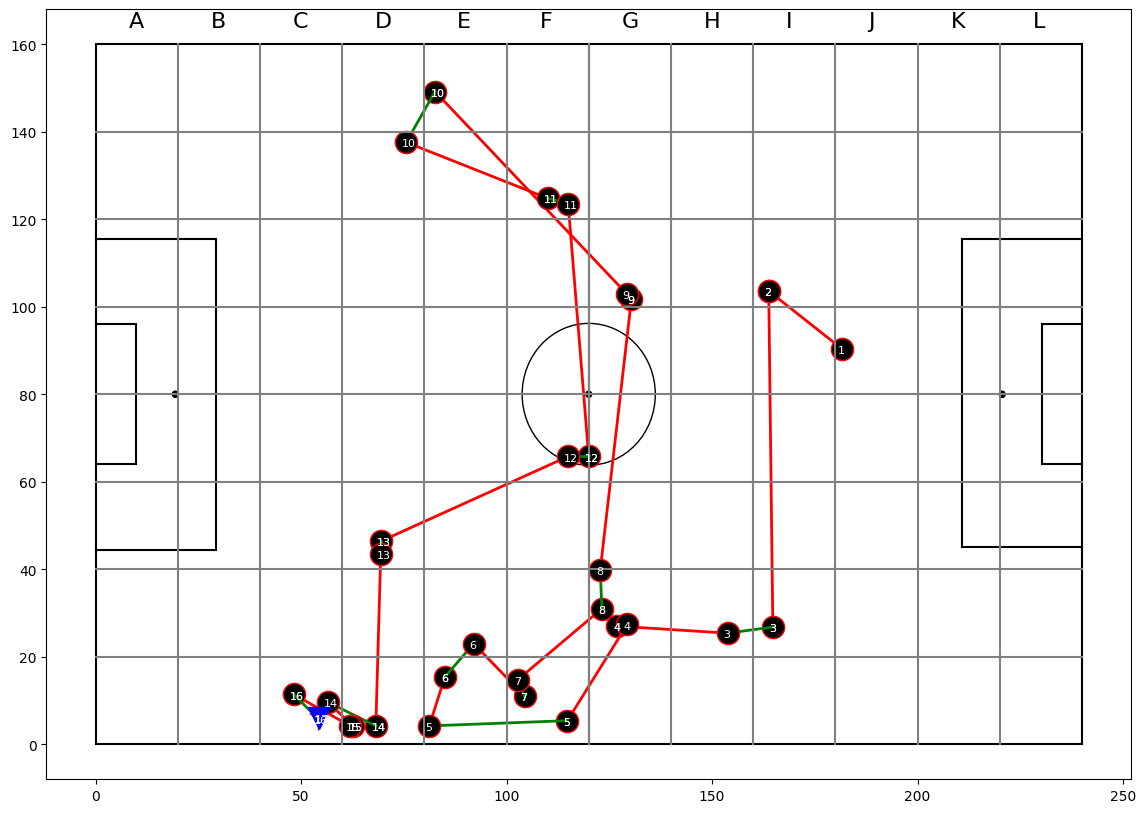

Sequence: 48
Team: Poland
1: Bartosz Bereszyński (Pass) <00:28:17.261>
2: Mateusz Andrzej Klich (Ball Receipt*) <00:28:18.219>
2: Mateusz Andrzej Klich (Pass) <00:28:18.219>
3: Bartosz Bereszyński (Ball Receipt*) <00:28:19.195>
3: Bartosz Bereszyński (Carry) <00:28:19.195>
3: Bartosz Bereszyński (Pass) <00:28:20.284>
4: Kamil Jóźwiak (Ball Receipt*) <00:28:21.234>
4: Kamil Jóźwiak (Carry) <00:28:21.234>
4: Kamil Jóźwiak (Pass) <00:28:22.267>
5: Ludwig Augustinsson (Block) <00:28:22.420>
6: Grzegorz Krychowiak (Pass) <00:28:23.005>
7: Mateusz Andrzej Klich (Ball Receipt*) <00:28:23.105>
7: Mateusz Andrzej Klich (Carry) <00:28:23.105>
7: Mateusz Andrzej Klich (Pass) <00:28:25.155>
8: Marcus Andreas Danielsson (Clearance) <00:28:26.365>
9: Tymoteusz Puchacz (Ball Recovery) <00:28:28.595>
9: Tymoteusz Puchacz (Carry) <00:28:28.595>
9: Tymoteusz Puchacz (Pass) <00:28:29.652>
10: Karol Świderski (Ball Receipt*) <00:28:31.531>
11: Ludwig Augustinsson (Duel) <00:28:31.571>
12: Karol Świderski 

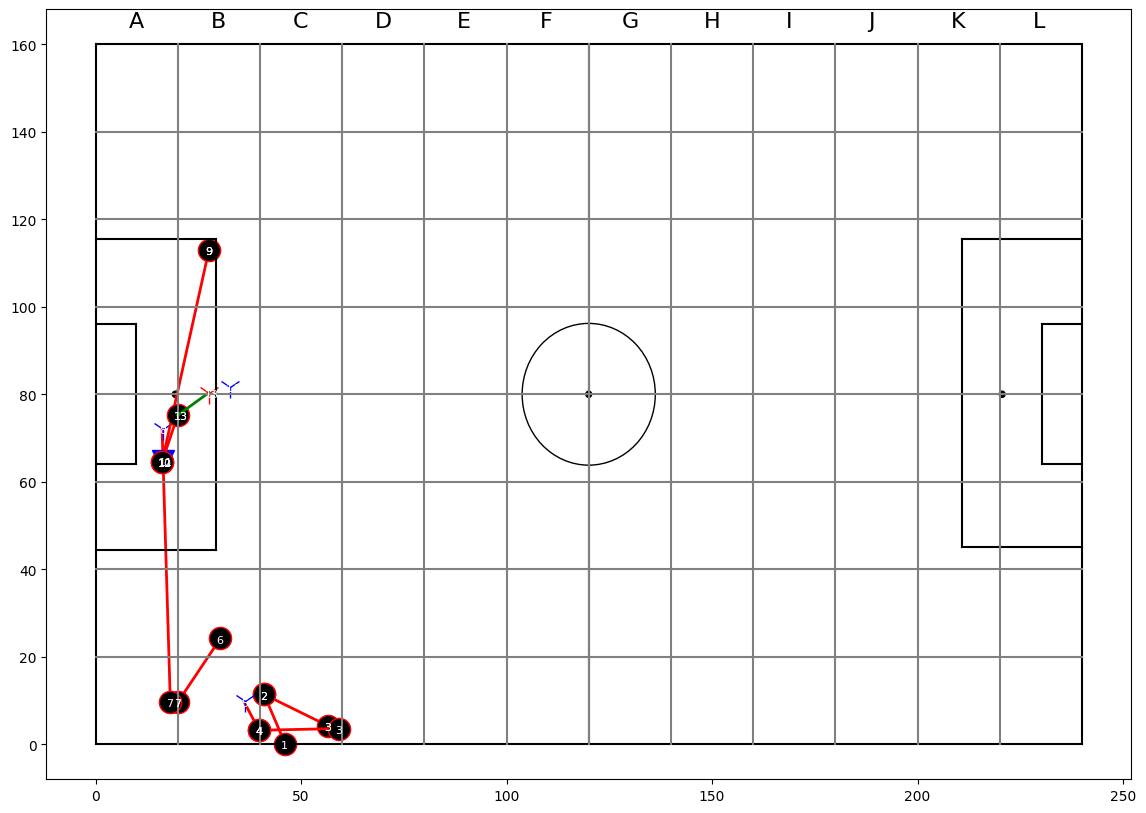

Sequence: 49
Team: Poland
1: Bartosz Bereszyński (Pass) <00:28:52.980>
2: Kamil Glik (Ball Receipt*) <00:28:53.854>
2: Kamil Glik (Pass) <00:28:55.172>
3: Bartosz Bereszyński (Ball Receipt*) <00:28:56.302>
3: Bartosz Bereszyński (Carry) <00:28:56.302>
3: Bartosz Bereszyński (Pass) <00:28:57.648>
4: Jan Bednarek (Ball Receipt*) <00:28:59.061>
4: Jan Bednarek (Carry) <00:28:59.061>
4: Jan Bednarek (Pass) <00:29:01.783>
5: Wojciech Szczęsny (Ball Receipt*) <00:29:04.158>
5: Wojciech Szczęsny (Carry) <00:29:04.158>
5: Wojciech Szczęsny (Pass) <00:29:08.367>
6: Mikael Lustig (Pass) <00:29:11.141>


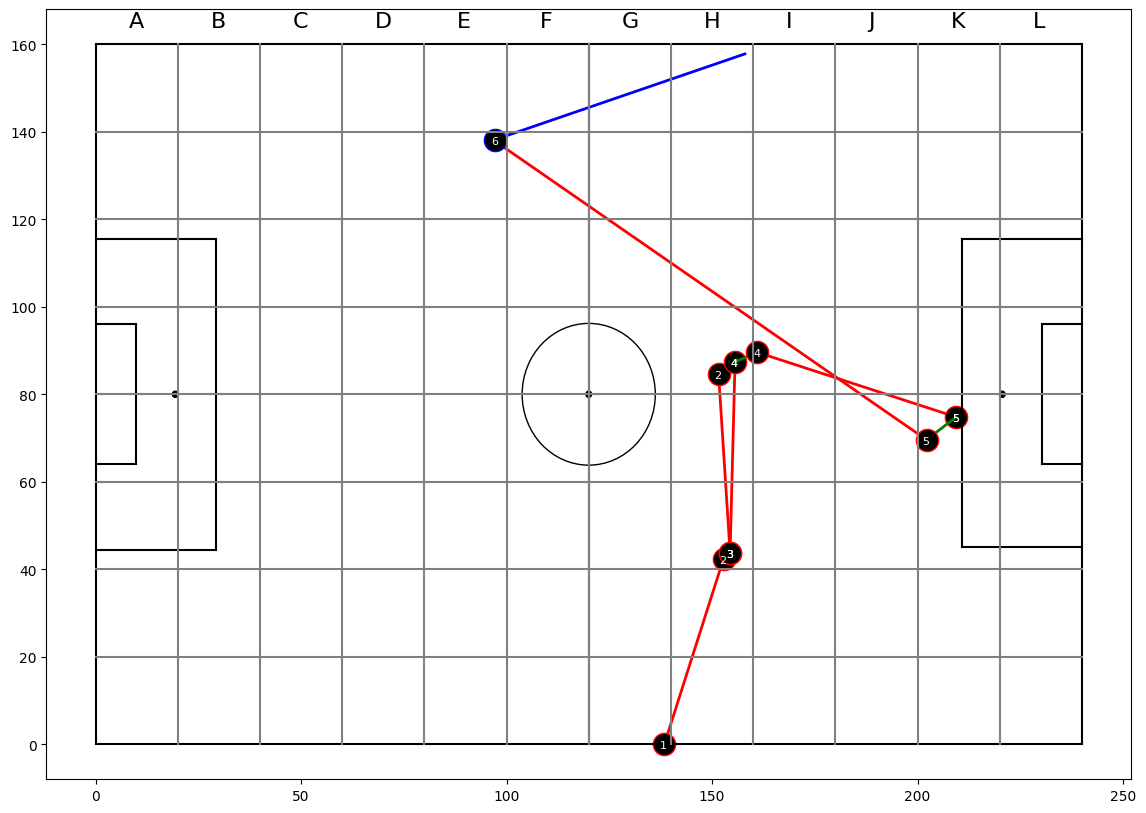

Sequence: 50
Team: Poland
1: Jan Bednarek (Pass) <00:29:19.274>
2: Wojciech Szczęsny (Ball Receipt*) <00:29:21.956>
2: Wojciech Szczęsny (Carry) <00:29:21.956>
2: Wojciech Szczęsny (Pass) <00:29:23.540>
3: Bartosz Bereszyński (Ball Receipt*) <00:29:24.879>
3: Bartosz Bereszyński (Carry) <00:29:24.879>
3: Bartosz Bereszyński (Pass) <00:29:26.206>
4: Kamil Jóźwiak (Ball Receipt*) <00:29:27.839>
4: Kamil Jóźwiak (Carry) <00:29:27.839>
4: Kamil Jóźwiak (Pass) <00:29:30.827>
5: Bartosz Bereszyński (Ball Receipt*) <00:29:32.045>
5: Bartosz Bereszyński (Carry) <00:29:32.045>
5: Bartosz Bereszyński (Pass) <00:29:34.205>
6: Piotr Zieliński (Ball Receipt*) <00:29:34.887>
6: Piotr Zieliński (Pass) <00:29:34.887>
7: Kamil Glik (Ball Receipt*) <00:29:36.576>
8: Robin Quaison (Ball Recovery) <00:29:36.576>
8: Robin Quaison (Carry) <00:29:36.576>
8: Robin Quaison (Pass) <00:29:37.787>
9: Mikael Lustig (Ball Receipt*) <00:29:39.877>
10: Tymoteusz Puchacz (Ball Recovery) <00:29:39.877>
10: Tymoteusz Pu

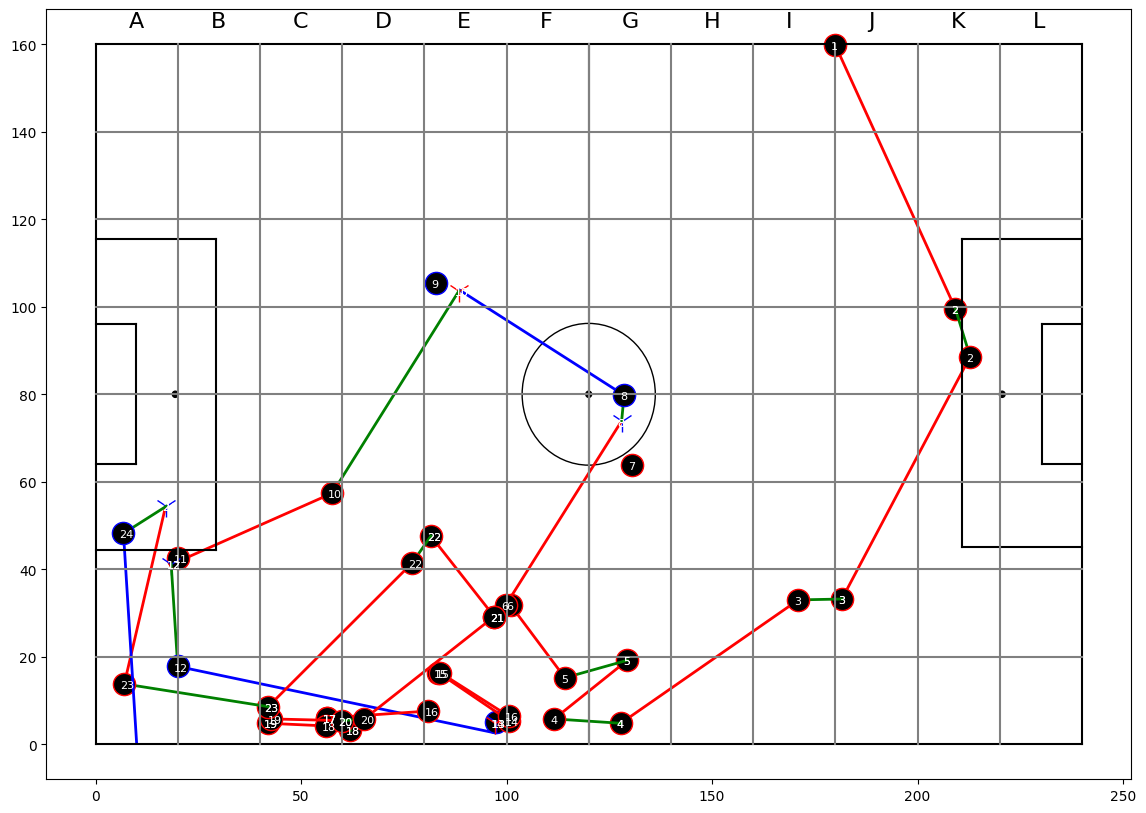

Sequence: 51
Team: Poland
1: Kamil Jóźwiak (Pass) <00:30:33.002>
2: Mateusz Andrzej Klich (Ball Receipt*) <00:30:33.980>
2: Mateusz Andrzej Klich (Carry) <00:30:33.980>
2: Mateusz Andrzej Klich (Pass) <00:30:37.098>
3: Ludwig Augustinsson (Pass) <00:30:39.893>
4: Kamil Glik (Pass) <00:30:43.667>
5: Marcus Andreas Danielsson (Clearance) <00:30:46.158>


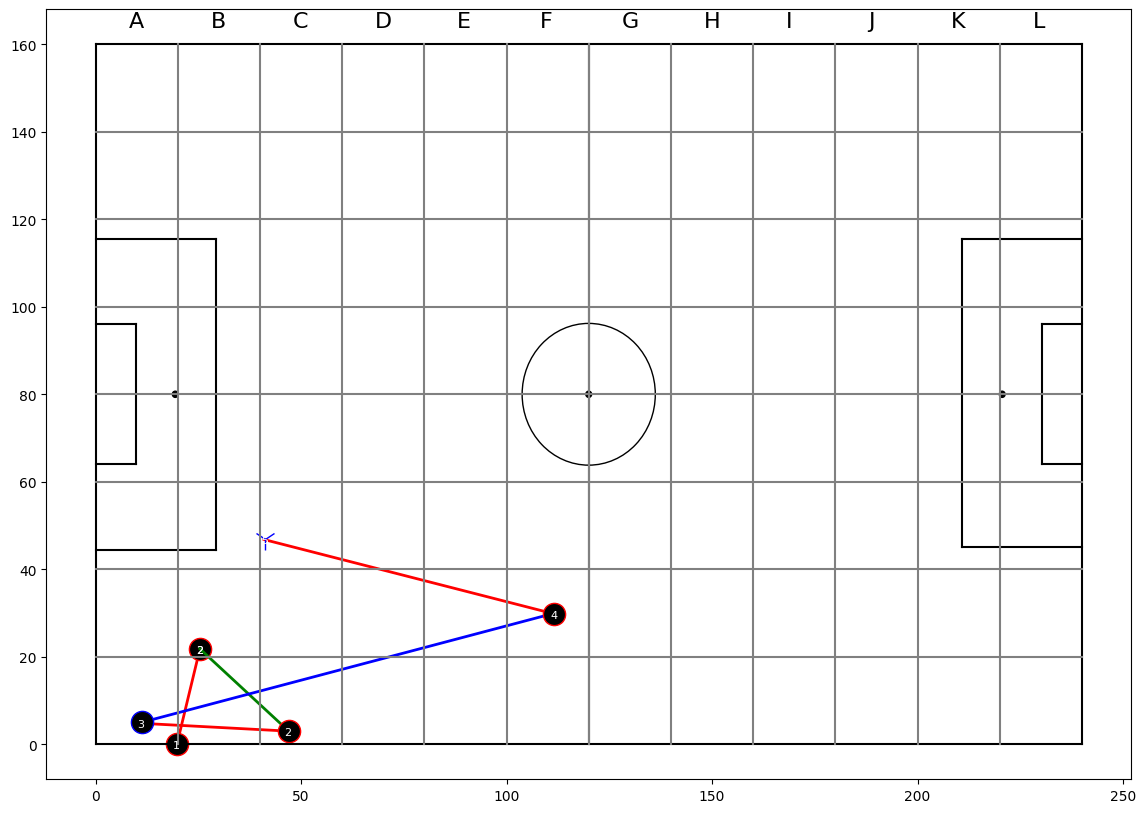

Sequence: 52
Team: Sweden
1: Emil Peter Forsberg (Ball Recovery) <00:30:49.052>
1: Emil Peter Forsberg (Carry) <00:30:49.052>
2: Kamil Jóźwiak (Foul Committed) <00:30:50.761>
3: Emil Peter Forsberg (Foul Won) <00:30:50.761>
4: Ludwig Augustinsson (Pass) <00:31:23.349>
5: Mikael Lustig (Ball Receipt*) <00:31:26.515>
5: Mikael Lustig (Carry) <00:31:26.515>
6: Tymoteusz Puchacz (Foul Committed) <00:31:27.596>
7: Mikael Lustig (Foul Won) <00:31:27.596>
8: Sebastian Larsson (Pass) <00:32:24.742>
9: Bartosz Bereszyński (Clearance) <00:32:25.707>


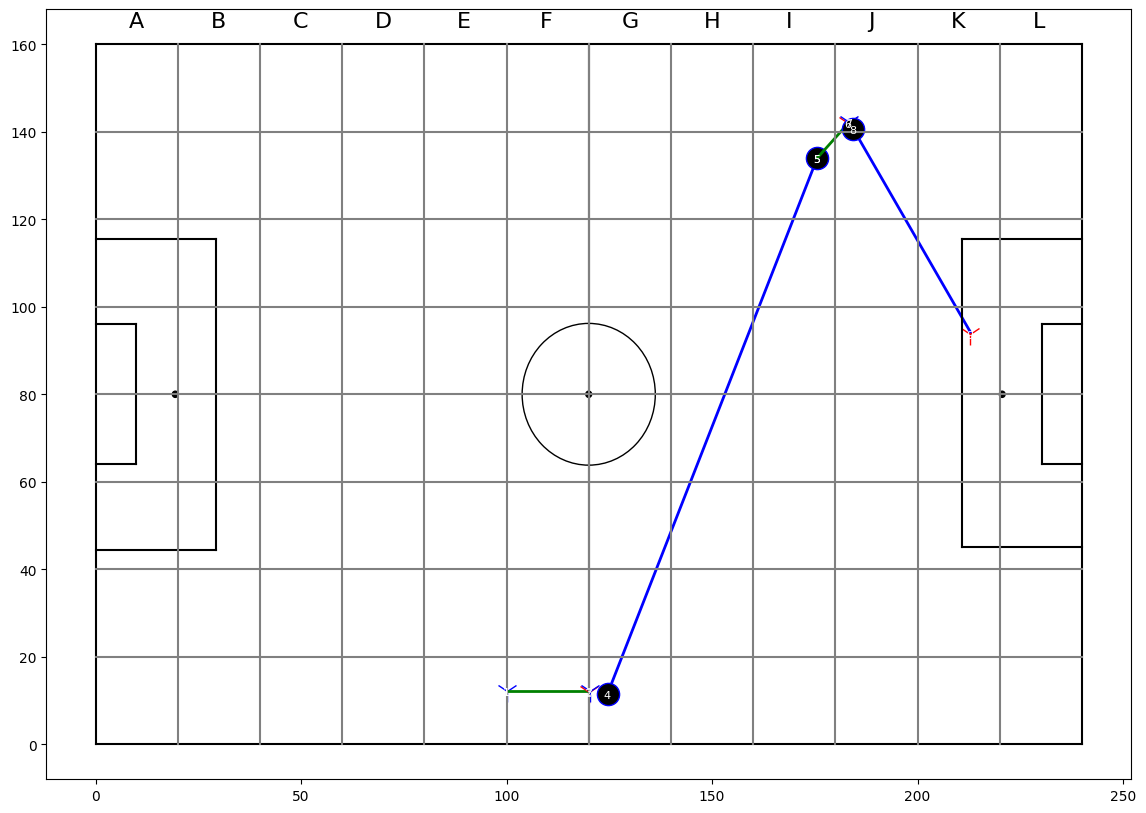

Sequence: 53
Team: Poland
1: Robert Lewandowski (Ball Recovery) <00:32:26.411>
1: Robert Lewandowski (Carry) <00:32:26.411>
1: Robert Lewandowski (Pass) <00:32:28.381>
2: Kamil Jóźwiak (Ball Receipt*) <00:32:28.478>
3: Emil Peter Forsberg (Block) <00:32:28.478>
3: Emil Peter Forsberg (Ball Recovery) <00:32:29.582>
4: Piotr Zieliński (Ball Recovery) <00:32:31.226>
4: Piotr Zieliński (Carry) <00:32:31.226>
4: Piotr Zieliński (Dispossessed) <00:32:32.967>
5: Albin Ekdal (Duel) <00:32:32.967>
6: Piotr Zieliński (Pass) <00:32:34.446>
7: Robert Lewandowski (Ball Receipt*) <00:32:35.239>
7: Robert Lewandowski (Carry) <00:32:35.239>
7: Robert Lewandowski (Pass) <00:32:36.960>
8: Ludwig Augustinsson (Block) <00:32:37.064>
9: Sebastian Larsson (Foul Committed) <00:32:41.223>
10: Kamil Jóźwiak (Foul Won) <00:32:41.223>
11: Piotr Zieliński (Pass) <00:33:05.326>
12: Grzegorz Krychowiak (Ball Receipt*) <00:33:07.313>
13: Albin Ekdal (Clearance) <00:33:07.313>
14: Kamil Jóźwiak (Ball Recovery) <00:33

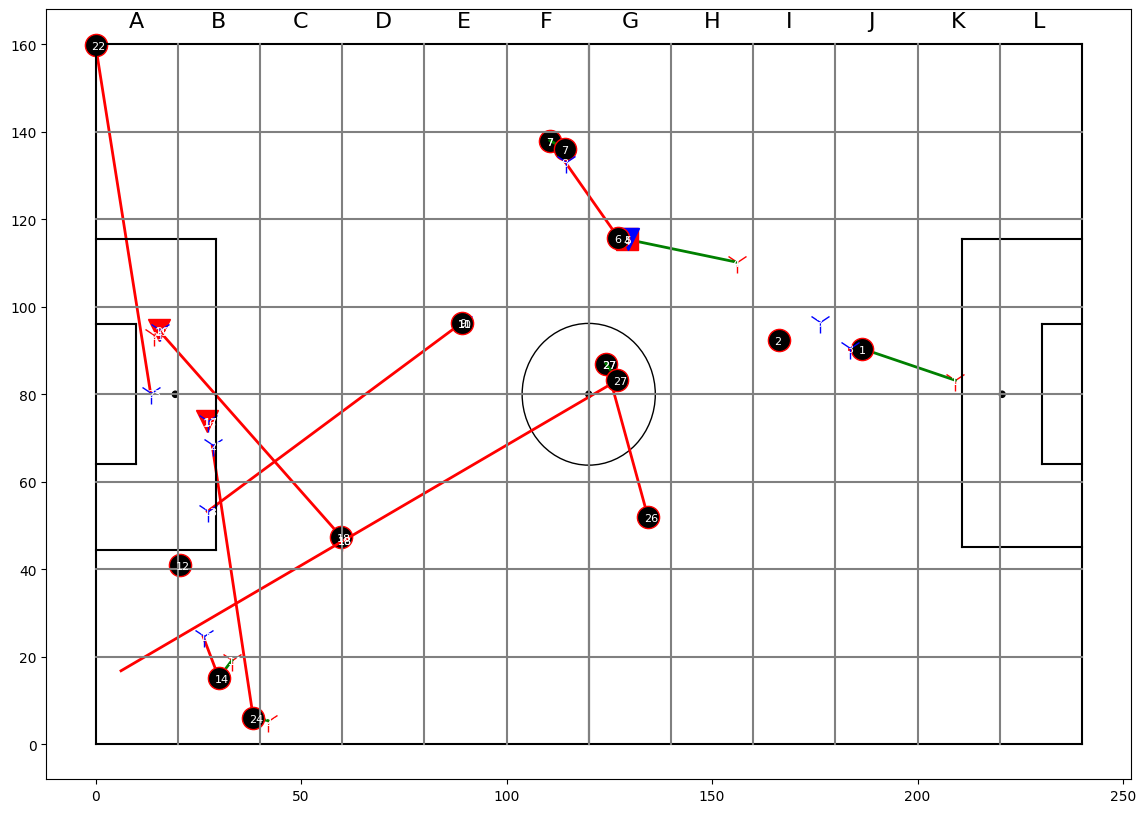

Sequence: 54
Team: Sweden
1: Robin Olsen (Pass) <00:34:33.848>
2: Robin Quaison (Ball Receipt*) <00:34:37.626>
2: Robin Quaison (Duel) <00:34:37.626>
3: Kamil Glik (Clearance) <00:34:37.626>
4: Emil Peter Forsberg (Pass) <00:34:39.356>
5: Robin Quaison (Ball Receipt*) <00:34:42.220>
5: Robin Quaison (Carry) <00:34:42.220>
5: Robin Quaison (Pass) <00:34:44.038>
6: Kamil Glik (Block) <00:34:44.200>


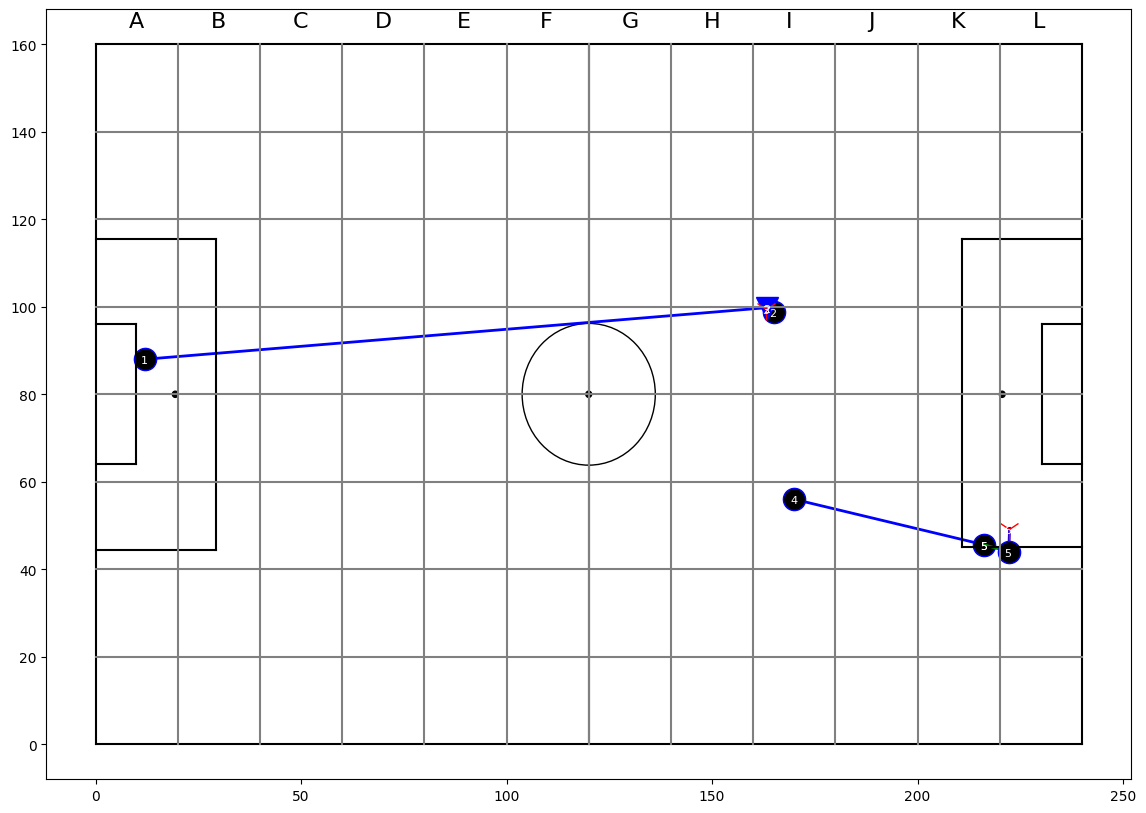

Sequence: 55
Team: Sweden
1: Emil Peter Forsberg (Pass) <00:35:11.737>
2: Robin Quaison (Duel) <00:35:12.804>
3: Robert Lewandowski (Clearance) <00:35:12.804>
4: Ludwig Augustinsson (Ball Recovery) <00:35:17.436>
4: Ludwig Augustinsson (Carry) <00:35:17.436>
4: Ludwig Augustinsson (Pass) <00:35:20.034>
5: Robin Quaison (Ball Receipt*) <00:35:21.755>
6: Kamil Glik (Pass) <00:35:21.755>
7: Victor Nilsson Lindelöf (Clearance) <00:35:23.576>
8: Robert Lewandowski (Ball Recovery) <00:35:25.920>
8: Robert Lewandowski (Carry) <00:35:25.920>
8: Robert Lewandowski (Miscontrol) <00:35:27.698>


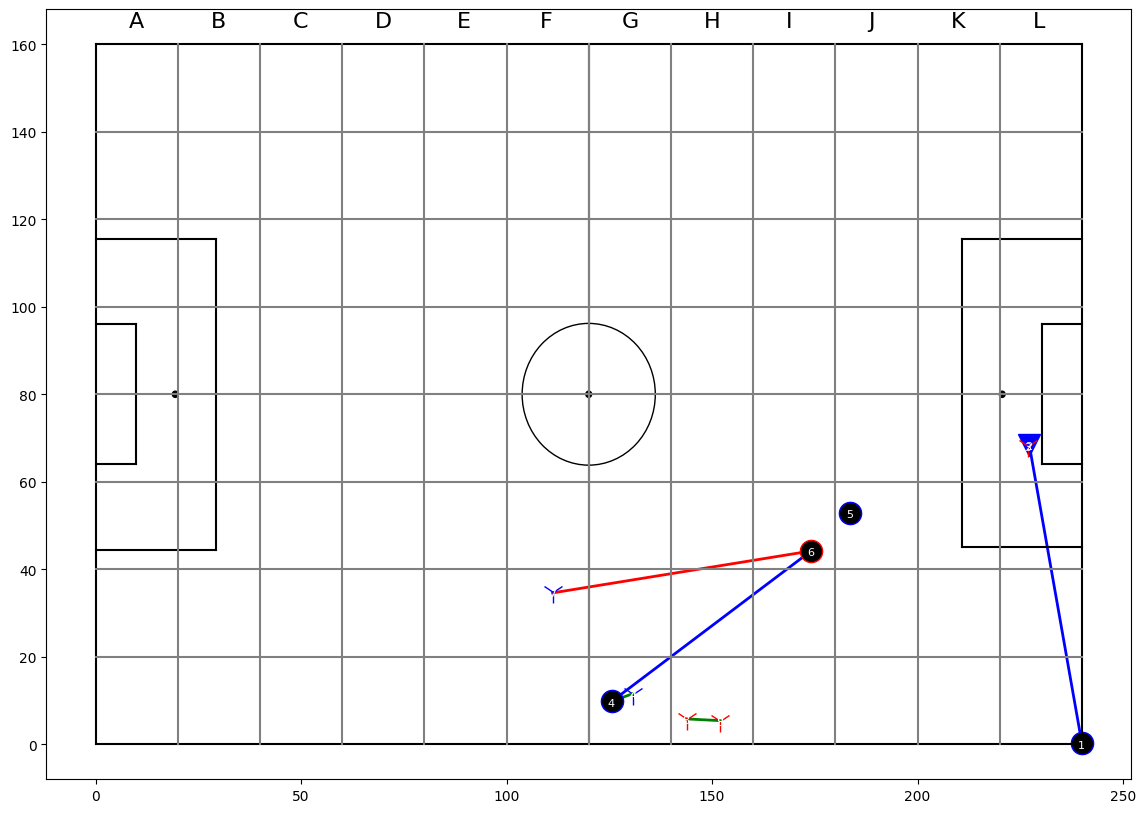

Sequence: 56
Team: Sweden
1: Ludwig Augustinsson (Pass) <00:35:53.961>
2: Robin Quaison (Ball Receipt*) <00:35:54.779>
2: Robin Quaison (Carry) <00:35:54.779>
2: Robin Quaison (Pass) <00:35:56.162>
3: Ludwig Augustinsson (Ball Receipt*) <00:35:56.925>
3: Ludwig Augustinsson (Pass) <00:35:56.925>


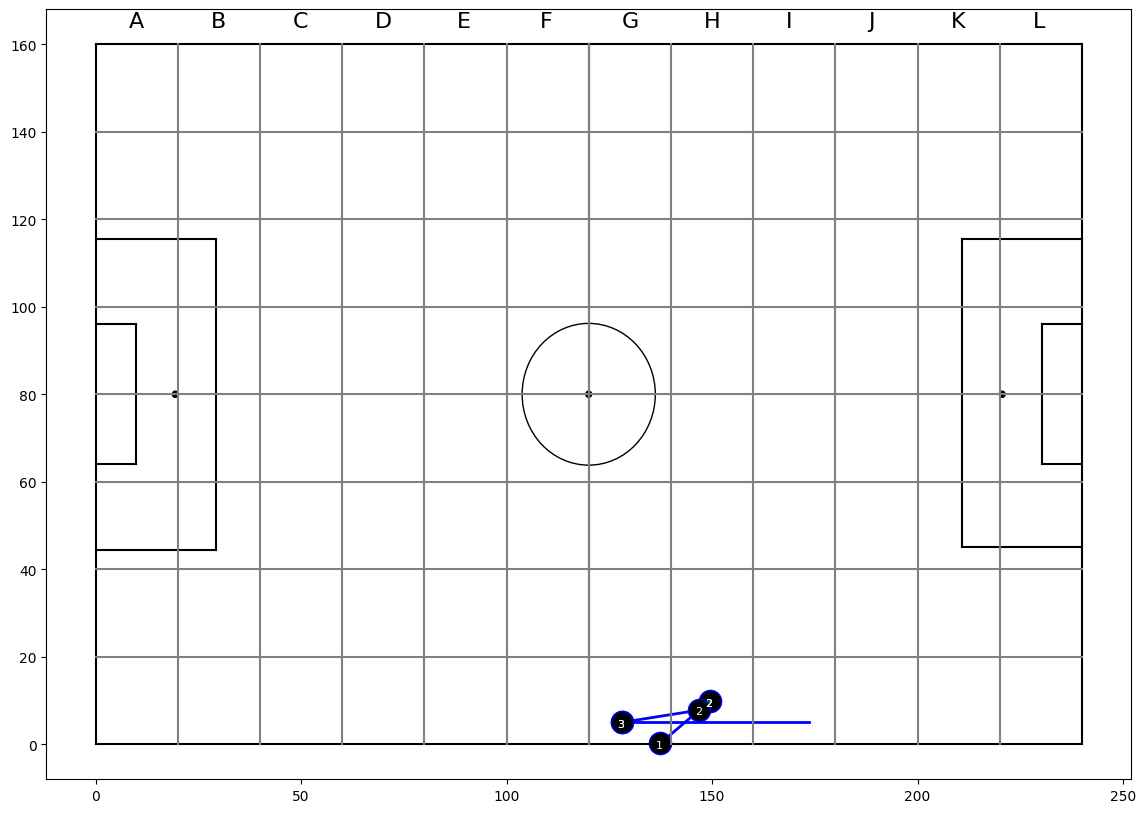

Sequence: 57
Team: Poland
1: Bartosz Bereszyński (Pass) <00:35:58.685>
2: Kamil Jóźwiak (Ball Receipt*) <00:36:00.116>
2: Kamil Jóźwiak (Pass) <00:36:00.116>
3: Piotr Zieliński (Ball Receipt*) <00:36:01.558>
3: Piotr Zieliński (Carry) <00:36:01.558>
4: Albin Ekdal (Foul Committed) <00:36:02.431>
5: Piotr Zieliński (Foul Won) <00:36:02.431>
6: Bartosz Bereszyński (Pass) <00:36:21.505>
7: Kamil Glik (Ball Receipt*) <00:36:22.528>
7: Kamil Glik (Pass) <00:36:23.136>
8: Jan Bednarek (Ball Receipt*) <00:36:24.245>
8: Jan Bednarek (Carry) <00:36:24.245>
8: Jan Bednarek (Pass) <00:36:25.360>
9: Tymoteusz Puchacz (Ball Receipt*) <00:36:26.646>
9: Tymoteusz Puchacz (Carry) <00:36:26.646>
9: Tymoteusz Puchacz (Dribble) <00:36:29.516>
10: Sebastian Larsson (Duel) <00:36:29.516>
10: Sebastian Larsson (Carry) <00:36:29.516>
10: Sebastian Larsson (Pass) <00:36:30.642>
11: Alexander Isak (Ball Receipt*) <00:36:32.175>
12: Jan Bednarek (Ball Recovery) <00:36:32.175>
12: Jan Bednarek (Carry) <00:36:32.

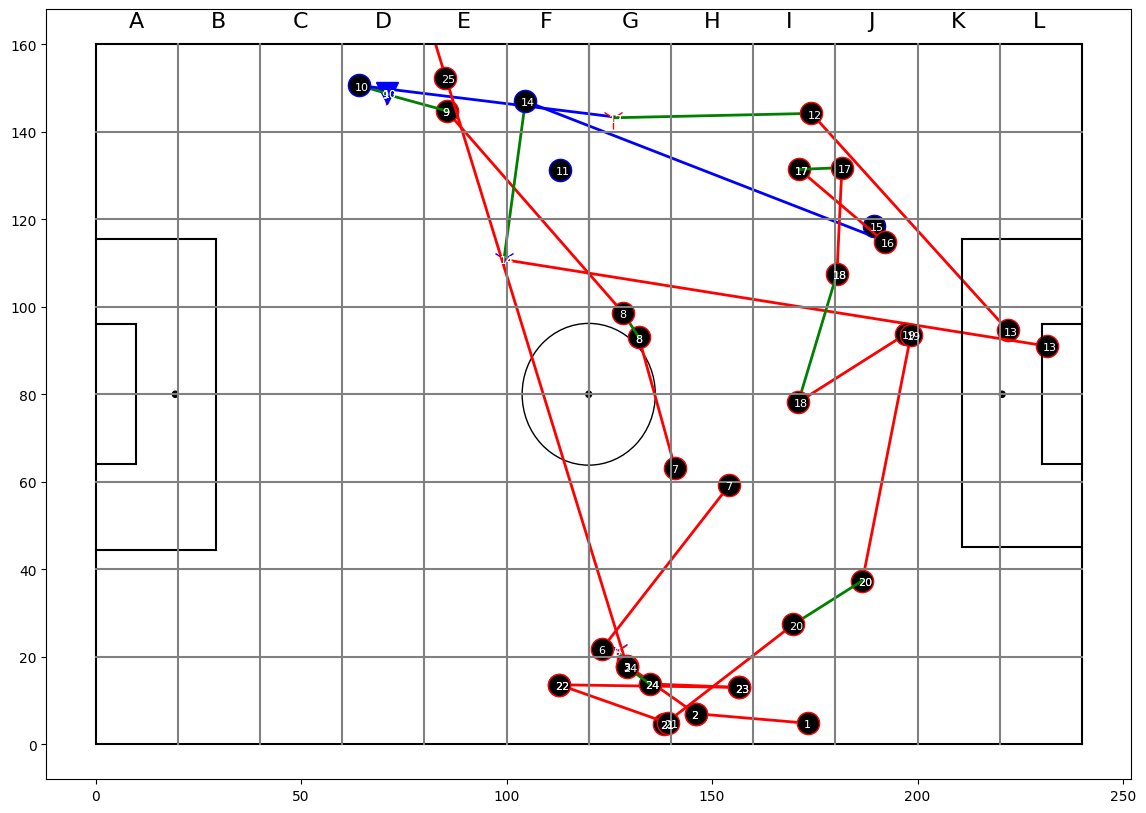

Sequence: 58
Team: Sweden
1: Mikael Lustig (Pass) <00:37:50.928>
2: Robin Quaison (Ball Receipt*) <00:37:51.911>
2: Robin Quaison (Carry) <00:37:51.911>
2: Robin Quaison (Pass) <00:37:53.254>
3: Tymoteusz Puchacz (Block) <00:37:53.331>


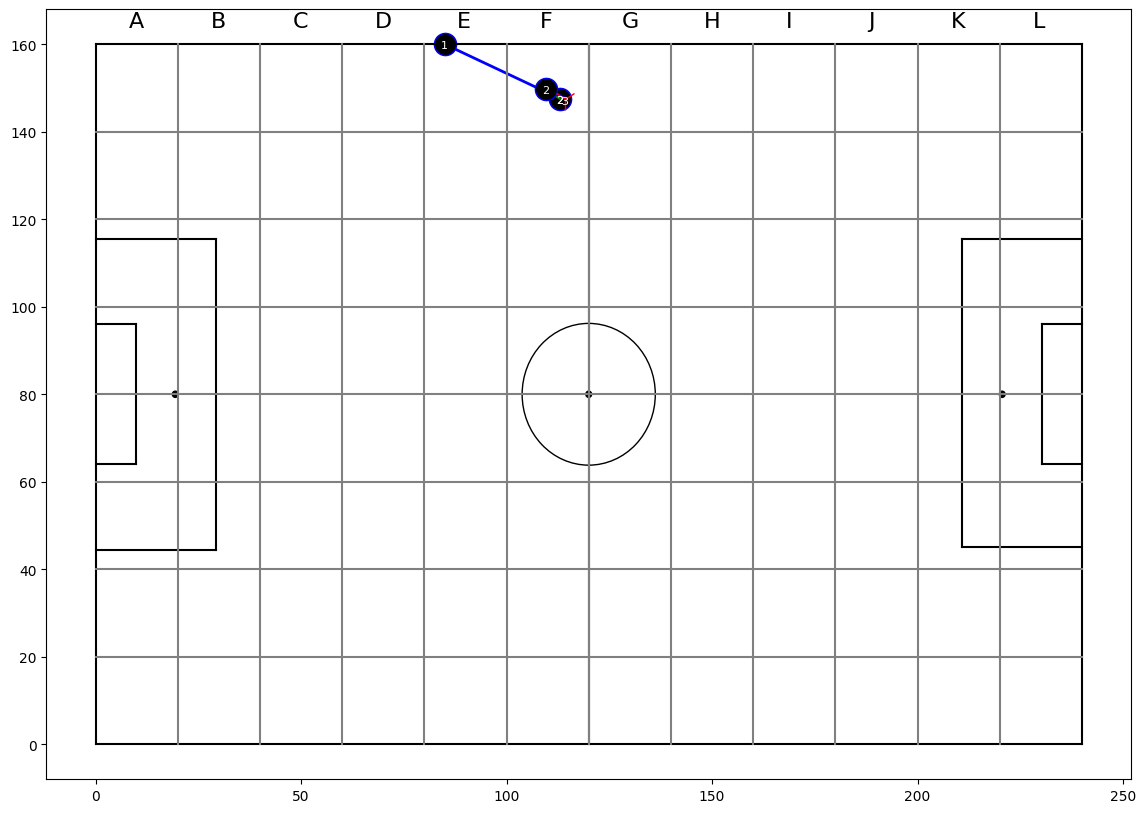

Sequence: 59
Team: Sweden
1: Mikael Lustig (Pass) <00:38:14.107>
2: Alexander Isak (Ball Receipt*) <00:38:15.937>
2: Alexander Isak (Miscontrol) <00:38:15.937>
3: Tymoteusz Puchacz (Ball Recovery) <00:38:16.610>
3: Tymoteusz Puchacz (Carry) <00:38:16.610>
3: Tymoteusz Puchacz (Dispossessed) <00:38:16.962>
4: Robin Quaison (Duel) <00:38:16.962>
4: Robin Quaison (Carry) <00:38:16.962>
4: Robin Quaison (Dribble) <00:38:18.221>
4: Robin Quaison (Carry) <00:38:18.221>
4: Robin Quaison (Pass) <00:38:19.529>
5: Sebastian Larsson (Ball Receipt*) <00:38:20.085>
5: Sebastian Larsson (Carry) <00:38:20.085>
5: Sebastian Larsson (Pass) <00:38:22.141>
6: Jan Bednarek (Block) <00:38:22.486>


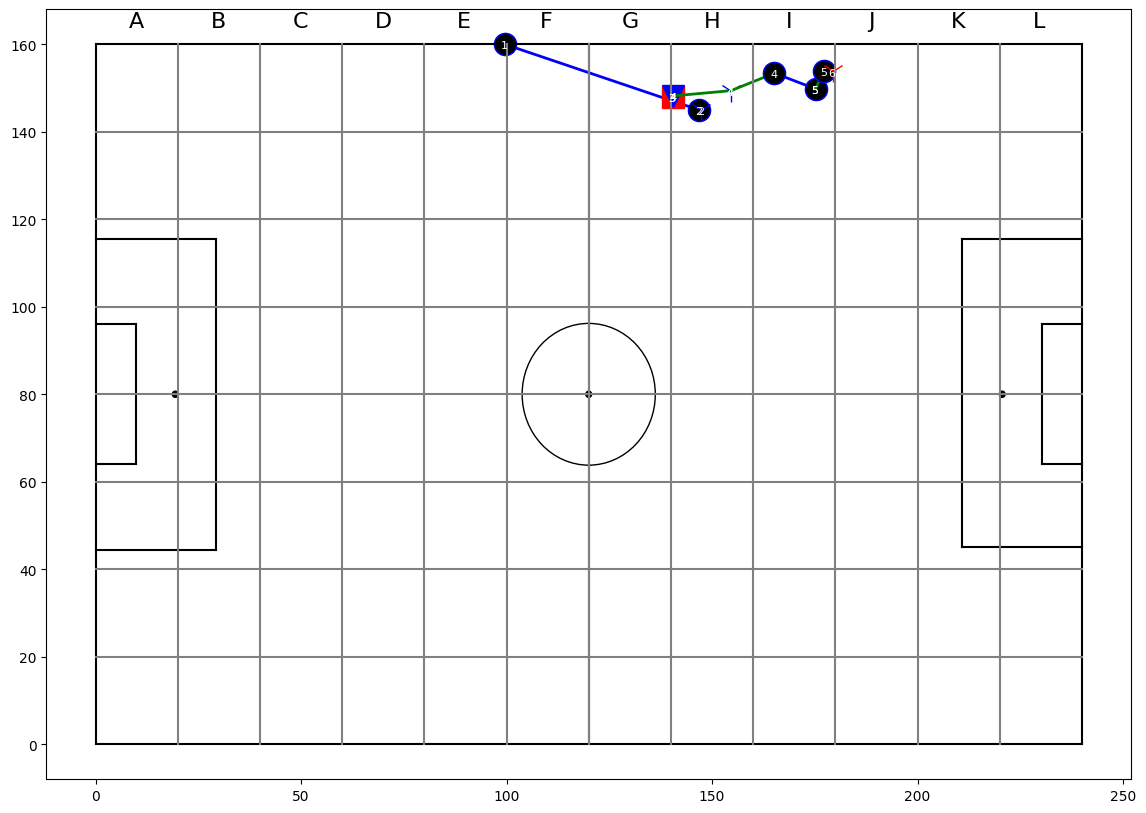

Sequence: 60
Team: Poland
1: Tymoteusz Puchacz (Ball Recovery) <00:38:24.020>
1: Tymoteusz Puchacz (Carry) <00:38:24.020>
1: Tymoteusz Puchacz (Pass) <00:38:25.645>
2: Karol Świderski (Ball Receipt*) <00:38:26.712>
2: Karol Świderski (Carry) <00:38:26.712>
2: Karol Świderski (Dribble) <00:38:27.872>
2: Karol Świderski (Carry) <00:38:27.872>
2: Karol Świderski (Pass) <00:38:30.980>
3: Tymoteusz Puchacz (Ball Receipt*) <00:38:32.767>
3: Tymoteusz Puchacz (Carry) <00:38:32.767>
3: Tymoteusz Puchacz (Pass) <00:38:35.355>
4: Kamil Jóźwiak (Ball Receipt*) <00:38:39.483>
4: Kamil Jóźwiak (Carry) <00:38:39.483>
4: Kamil Jóźwiak (Pass) <00:38:46.172>
5: Bartosz Bereszyński (Ball Receipt*) <00:38:47.241>
5: Bartosz Bereszyński (Carry) <00:38:47.241>
5: Bartosz Bereszyński (Pass) <00:38:49.014>
6: Sebastian Larsson (Clearance) <00:38:51.622>


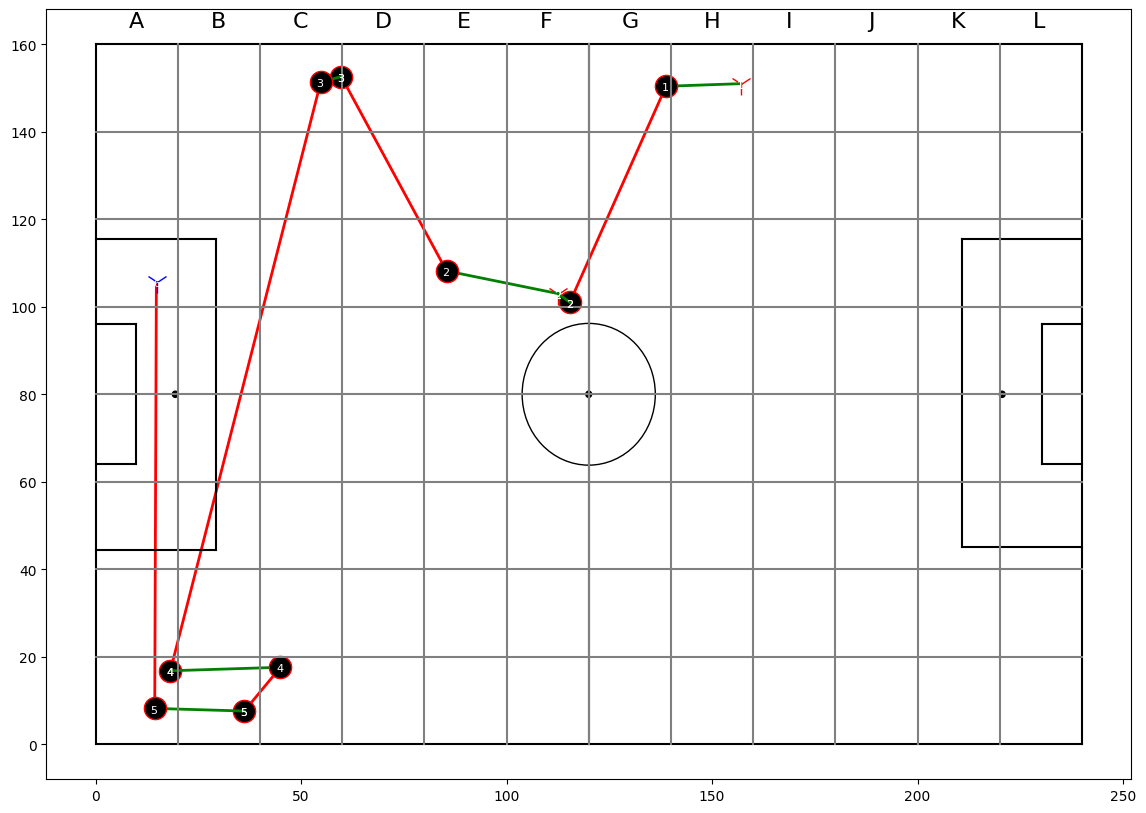

Sequence: 61
Team: Poland
1: Piotr Zieliński (Pass) <00:39:12.964>
2: Robin Quaison (Clearance) <00:39:14.317>


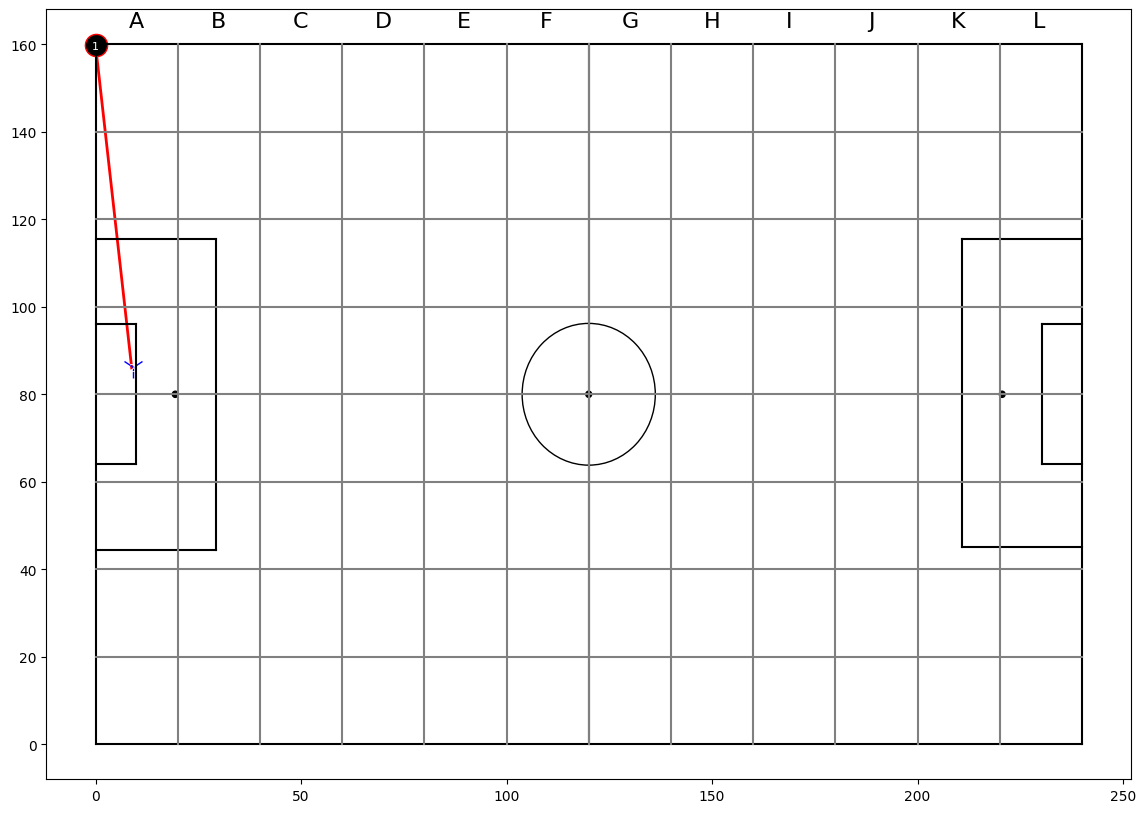

Sequence: 62
Team: Poland
1: Piotr Zieliński (Pass) <00:39:30.412>
2: Robert Lewandowski (Duel) <00:39:31.984>
3: Victor Nilsson Lindelöf (Clearance) <00:39:31.984>
4: Robert Lewandowski (Block) <00:39:32.031>
5: Kristoffer Olsson (Pass) <00:39:33.483>
6: Mikael Lustig (Ball Receipt*) <00:39:38.106>
6: Mikael Lustig (Carry) <00:39:38.106>
6: Mikael Lustig (Pass) <00:39:40.061>
7: Emil Peter Forsberg (Ball Receipt*) <00:39:43.774>
8: Mateusz Andrzej Klich (Pass) <00:39:43.774>
9: Bartosz Bereszyński (Ball Receipt*) <00:39:45.333>
9: Bartosz Bereszyński (Carry) <00:39:45.333>
9: Bartosz Bereszyński (Pass) <00:39:48.252>
10: Grzegorz Krychowiak (Ball Receipt*) <00:39:49.609>
10: Grzegorz Krychowiak (Carry) <00:39:49.609>
10: Grzegorz Krychowiak (Pass) <00:39:51.611>
11: Marcus Andreas Danielsson (Clearance) <00:39:53.007>
12: Mikael Lustig (Clearance) <00:39:54.390>
13: Alexander Isak (Foul Committed) <00:39:58.079>
14: Jan Bednarek (Foul Won) <00:39:58.079>
15: Mateusz Andrzej Klich (Pas

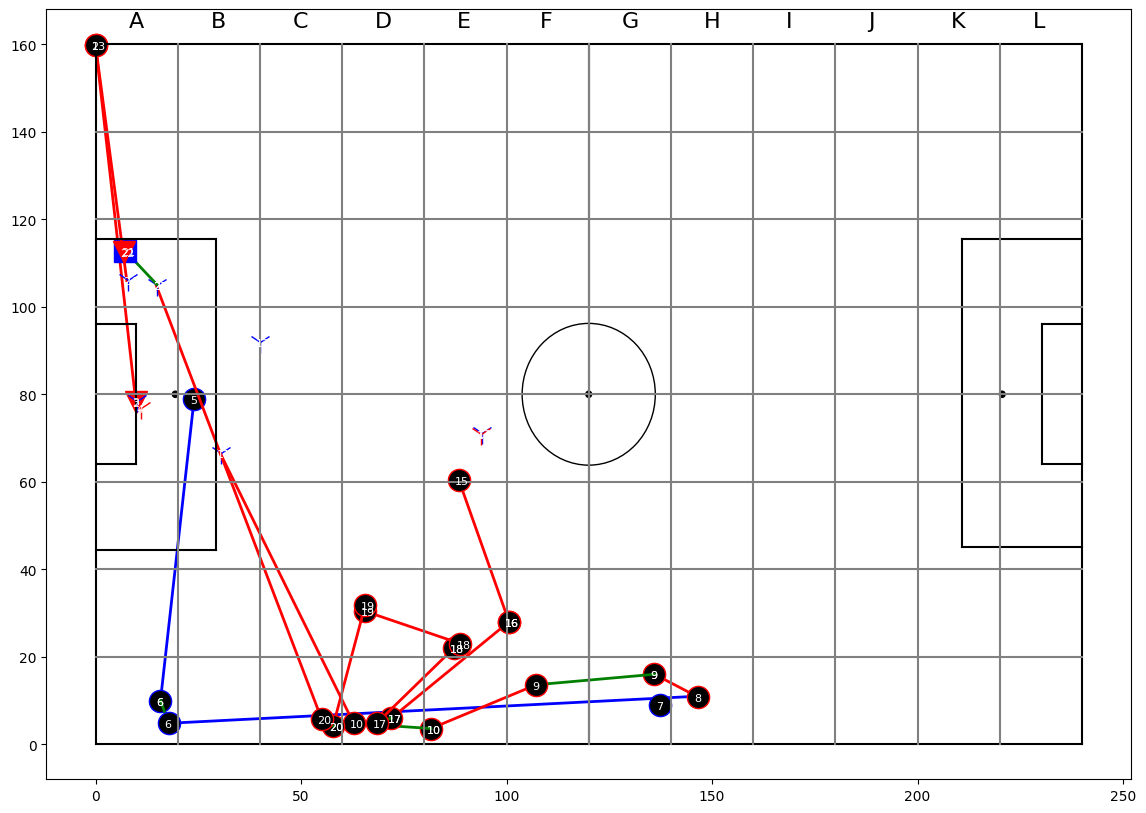

Sequence: 63
Team: Poland
1: Piotr Zieliński (Pass) <00:40:52.422>
2: Tymoteusz Puchacz (Ball Receipt*) <00:40:53.678>
2: Tymoteusz Puchacz (Carry) <00:40:53.678>
2: Tymoteusz Puchacz (Dispossessed) <00:40:54.175>
3: Kristoffer Olsson (Duel) <00:40:54.175>


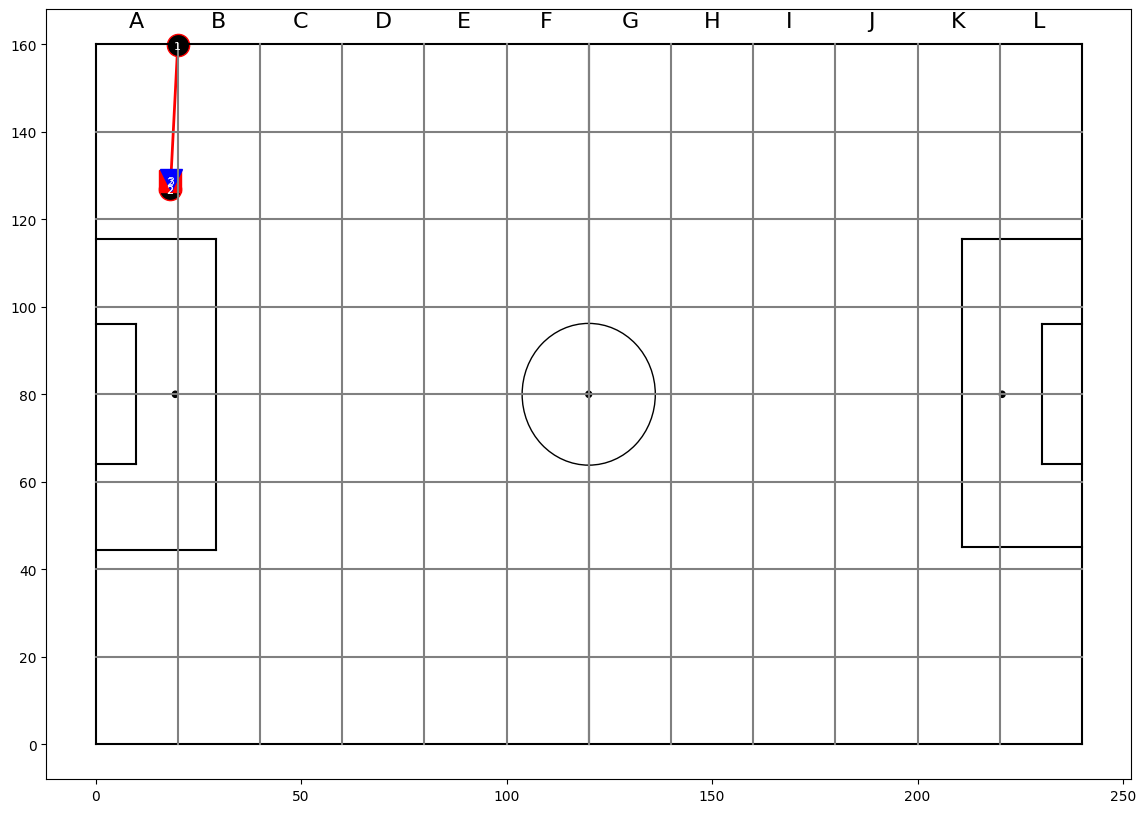

Sequence: 64
Team: Poland
1: Piotr Zieliński (Pass) <00:41:08.497>
2: Mateusz Andrzej Klich (Ball Receipt*) <00:41:08.821>
2: Mateusz Andrzej Klich (Carry) <00:41:08.821>
2: Mateusz Andrzej Klich (Pass) <00:41:10.517>
3: Grzegorz Krychowiak (Duel) <00:41:12.368>
4: Victor Nilsson Lindelöf (Clearance) <00:41:12.368>
5: Bartosz Bereszyński (Ball Recovery) <00:41:14.391>
5: Bartosz Bereszyński (Shot) <00:41:14.474>
6: Kamil Glik (Ball Recovery) <00:41:15.604>
6: Kamil Glik (Carry) <00:41:15.604>
6: Kamil Glik (Pass) <00:41:16.414>
7: Piotr Zieliński (Ball Receipt*) <00:41:17.218>
7: Piotr Zieliński (Shot) <00:41:17.235>
8: Alexander Isak (Block) <00:41:17.471>
9: Ludwig Augustinsson (Clearance) <00:41:18.705>
10: Mateusz Andrzej Klich (Pass) <00:41:24.283>
11: Wojciech Szczęsny (Ball Receipt*) <00:41:27.034>
11: Wojciech Szczęsny (Carry) <00:41:27.034>
11: Wojciech Szczęsny (Pass) <00:41:29.158>
12: Robert Lewandowski (Ball Receipt*) <00:41:32.071>
12: Robert Lewandowski (Duel) <00:41:32.

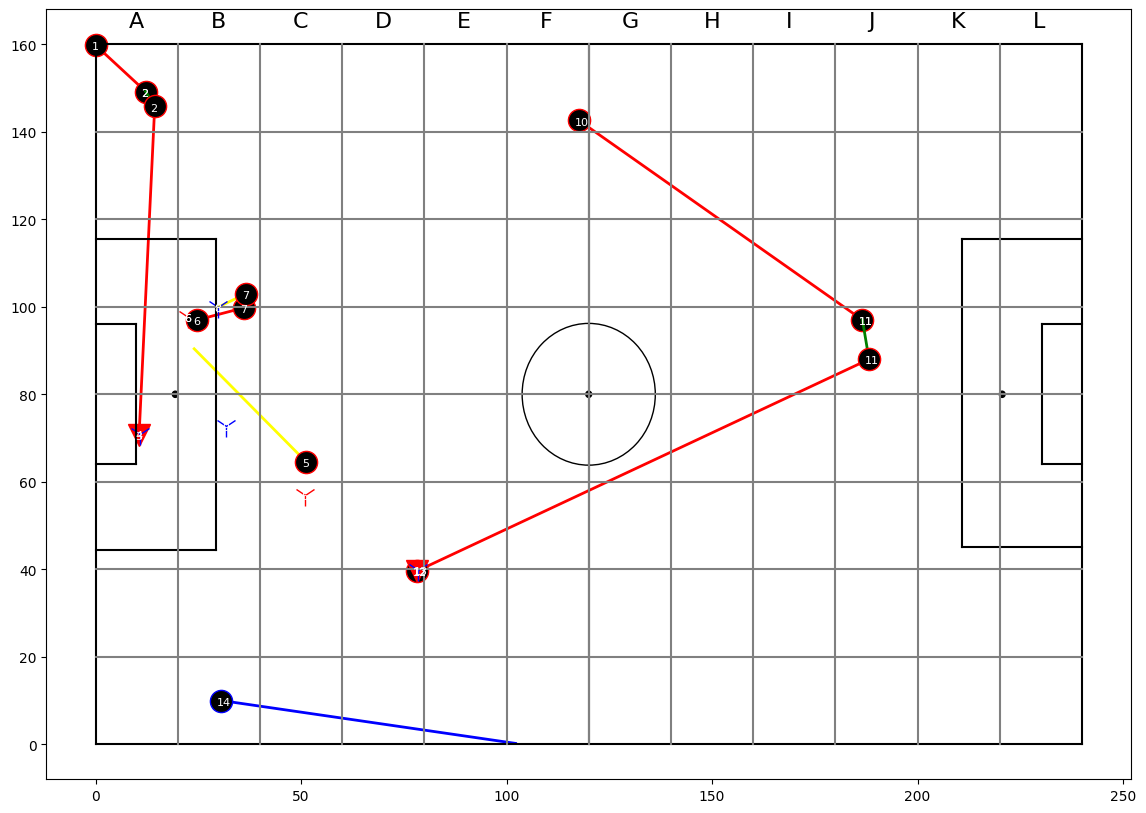

Sequence: 65
Team: Poland
1: Bartosz Bereszyński (Pass) <00:41:41.573>
2: Grzegorz Krychowiak (Ball Receipt*) <00:41:42.616>
2: Grzegorz Krychowiak (Carry) <00:41:42.616>
2: Grzegorz Krychowiak (Pass) <00:41:46.277>
3: Mateusz Andrzej Klich (Ball Receipt*) <00:41:47.093>
3: Mateusz Andrzej Klich (Carry) <00:41:47.093>
3: Mateusz Andrzej Klich (Pass) <00:41:48.210>
4: Tymoteusz Puchacz (Ball Receipt*) <00:41:49.776>
4: Tymoteusz Puchacz (Carry) <00:41:49.776>
4: Tymoteusz Puchacz (Pass) <00:41:52.234>
5: Mikael Lustig (Clearance) <00:41:52.930>
6: Emil Peter Forsberg (Pass) <00:41:54.377>
7: Robin Quaison (Ball Receipt*) <00:41:55.647>
7: Robin Quaison (Carry) <00:41:55.647>
7: Robin Quaison (Dribble) <00:41:56.240>
8: Bartosz Bereszyński (Duel) <00:41:56.240>
9: Jan Bednarek (Pass) <00:41:58.381>
10: Kamil Jóźwiak (Ball Receipt*) <00:42:00.188>
10: Kamil Jóźwiak (Carry) <00:42:00.188>
10: Kamil Jóźwiak (Pass) <00:42:02.464>
11: Marcus Andreas Danielsson (Clearance) <00:42:03.760>


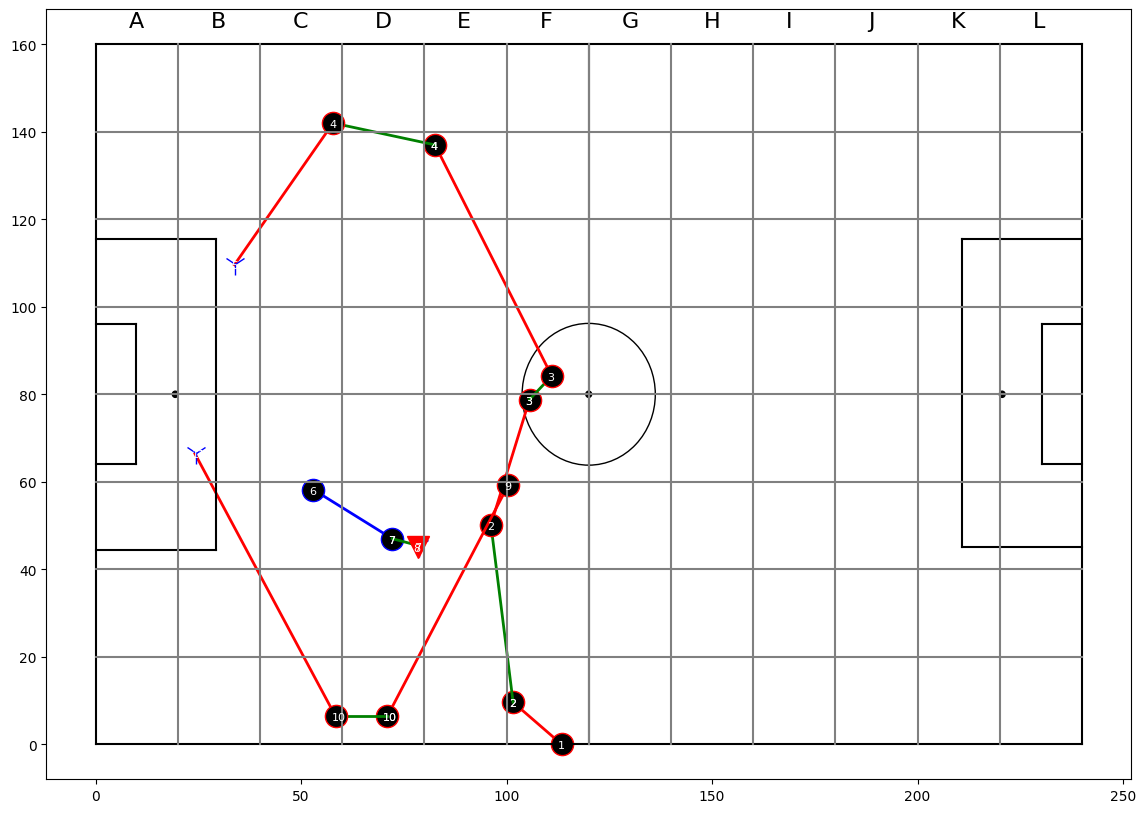

Sequence: 66
Team: Poland
1: Kamil Jóźwiak (Pass) <00:42:13.977>
2: Mateusz Andrzej Klich (Ball Receipt*) <00:42:15.484>
2: Mateusz Andrzej Klich (Carry) <00:42:15.484>
2: Mateusz Andrzej Klich (Pass) <00:42:16.701>
3: Robert Lewandowski (Ball Receipt*) <00:42:18.424>


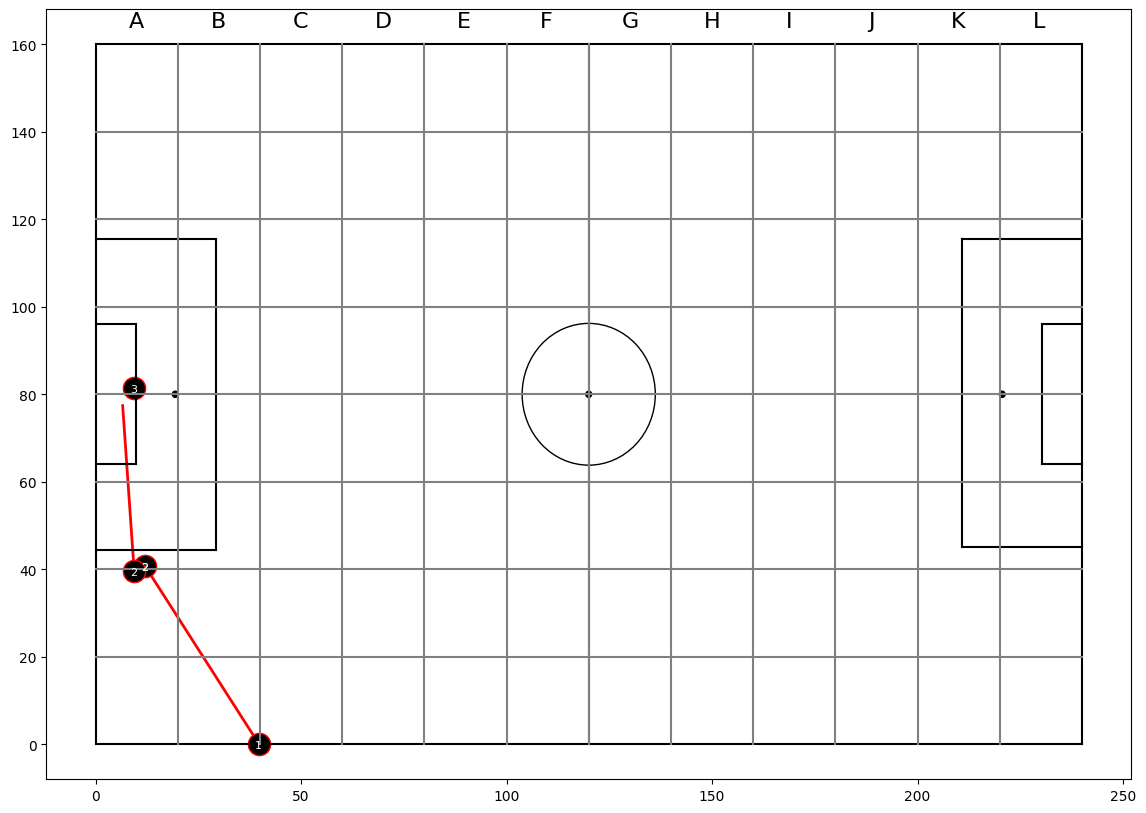

Sequence: 67
Team: Sweden
1: Robin Olsen (Carry) <00:42:18.424>
1: Robin Olsen (Pass) <00:42:35.731>
2: Robin Quaison (Foul Committed) <00:42:39.880>
3: Kamil Glik (Foul Won) <00:42:39.880>


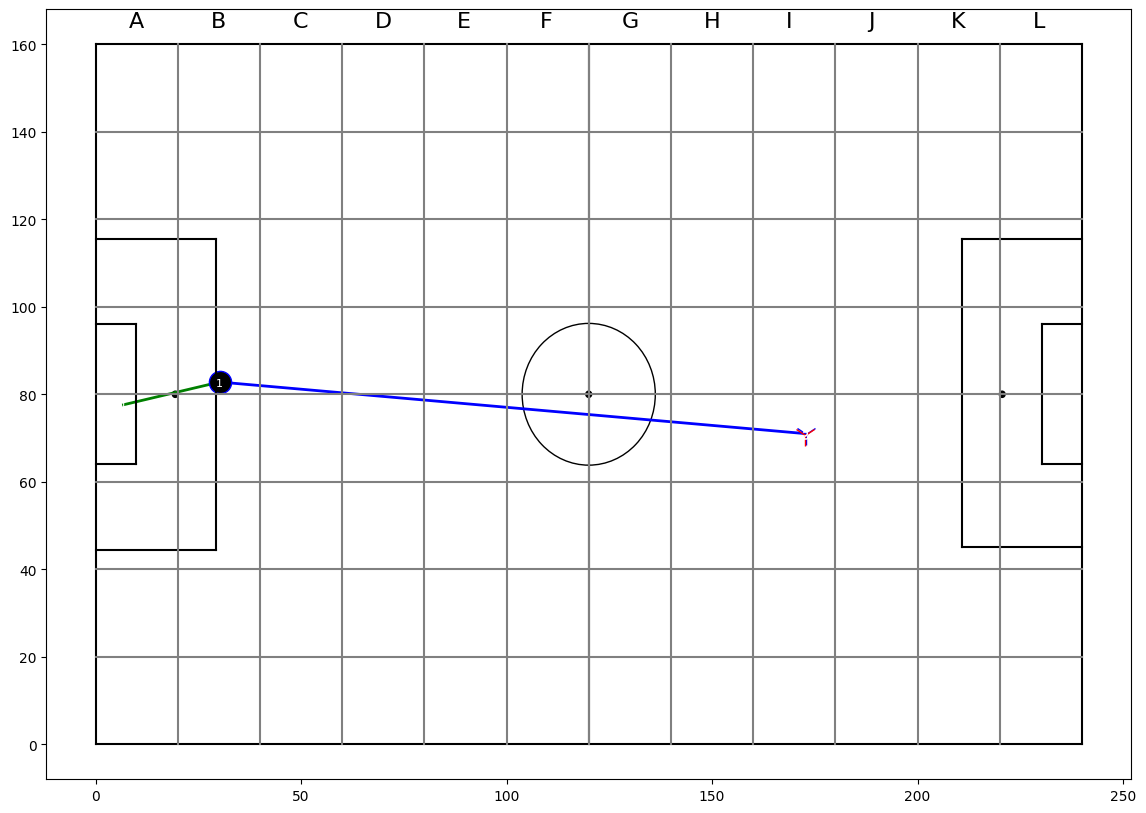

Sequence: 68
Team: Poland
1: Kamil Glik (Pass) <00:42:53.974>
2: Bartosz Bereszyński (Ball Receipt*) <00:42:54.789>
2: Bartosz Bereszyński (Pass) <00:42:55.463>
3: Kamil Jóźwiak (Ball Receipt*) <00:42:56.783>
3: Kamil Jóźwiak (Pass) <00:42:57.868>
4: Grzegorz Krychowiak (Ball Receipt*) <00:42:58.916>
4: Grzegorz Krychowiak (Carry) <00:42:58.916>
4: Grzegorz Krychowiak (Pass) <00:43:00.454>
5: Bartosz Bereszyński (Ball Receipt*) <00:43:01.781>
5: Bartosz Bereszyński (Carry) <00:43:01.781>
5: Bartosz Bereszyński (Pass) <00:43:02.136>
6: Grzegorz Krychowiak (Ball Receipt*) <00:43:02.872>
6: Grzegorz Krychowiak (Carry) <00:43:02.872>
6: Grzegorz Krychowiak (Pass) <00:43:04.381>
7: Piotr Zieliński (Ball Receipt*) <00:43:05.227>
7: Piotr Zieliński (Carry) <00:43:05.227>
7: Piotr Zieliński (Pass) <00:43:07.800>
8: Kamil Jóźwiak (Ball Receipt*) <00:43:09.295>
8: Kamil Jóźwiak (Carry) <00:43:09.295>
8: Kamil Jóźwiak (Pass) <00:43:12.583>


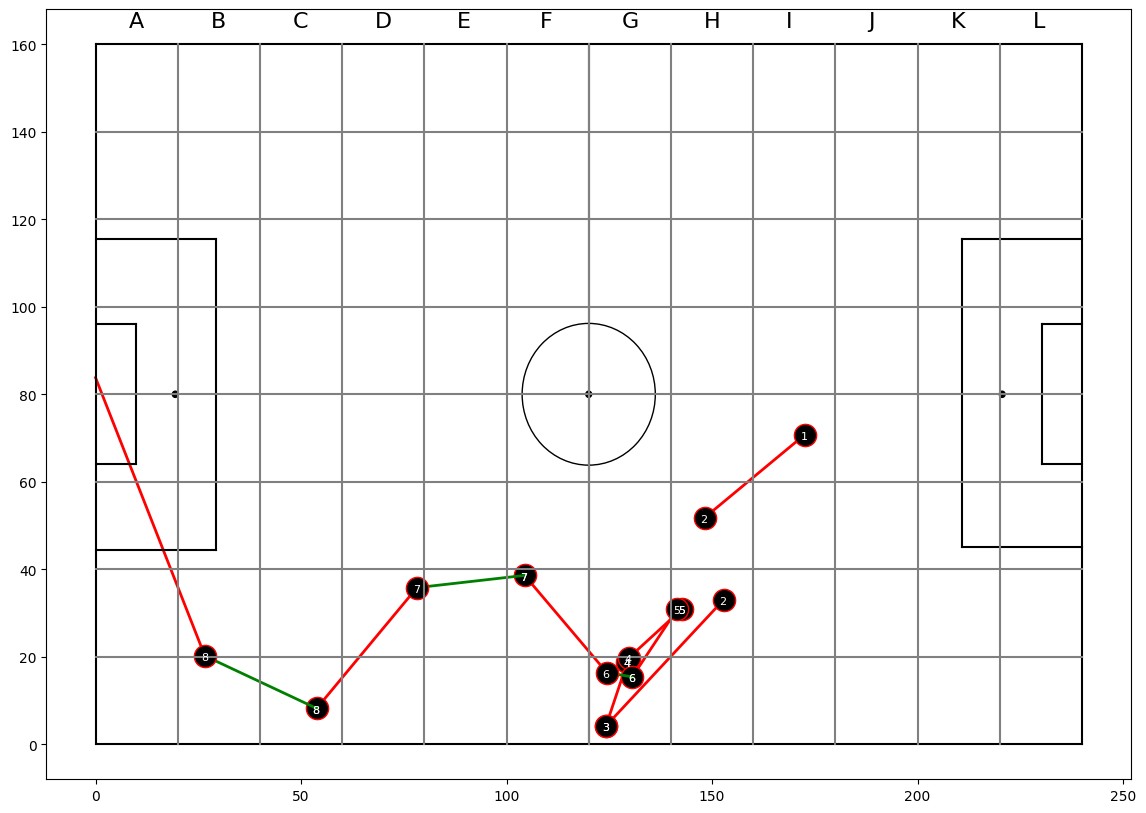

Sequence: 69
Team: Sweden
1: Robin Olsen (Pass) <00:43:43.529>
2: Sebastian Larsson (Ball Receipt*) <00:43:47.215>
2: Sebastian Larsson (Duel) <00:43:47.215>
3: Tymoteusz Puchacz (Pass) <00:43:47.215>
4: Sebastian Larsson (Block) <00:43:47.295>


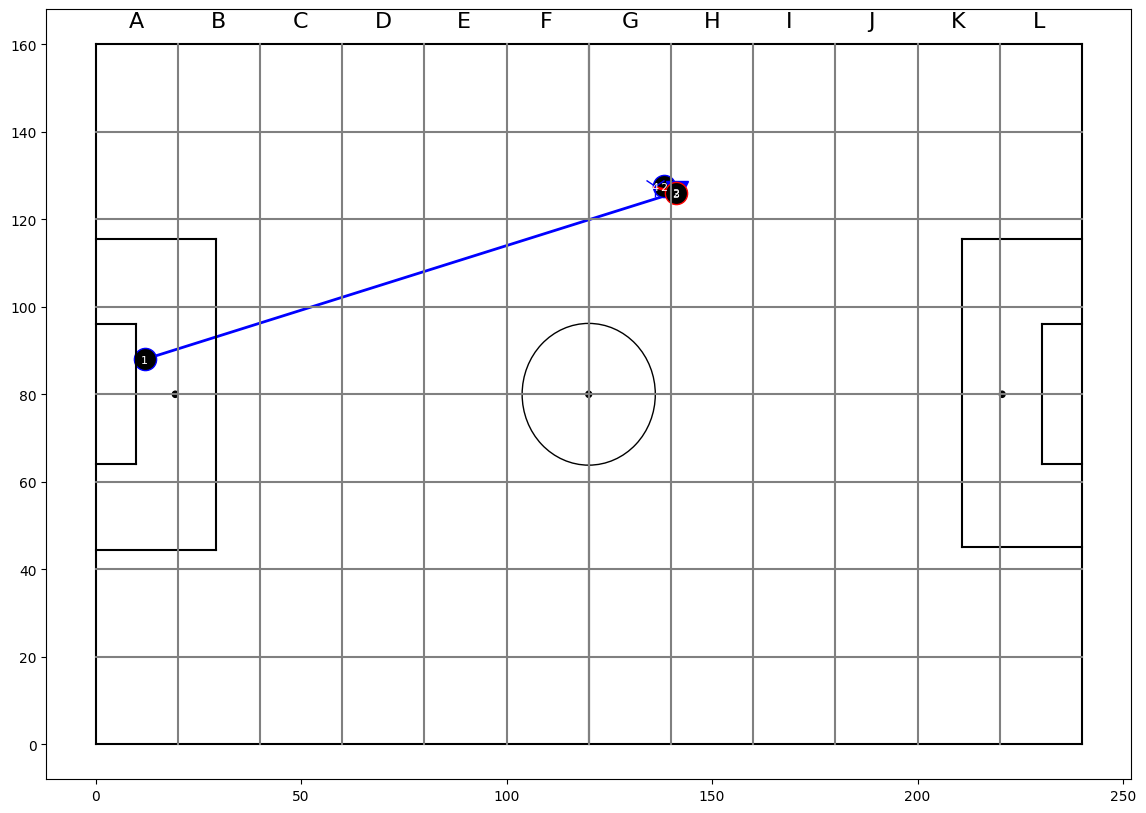

Sequence: 70
Team: Poland
1: Tymoteusz Puchacz (Pass) <00:43:48.629>
2: Grzegorz Krychowiak (Ball Receipt*) <00:43:50.233>
2: Grzegorz Krychowiak (Carry) <00:43:50.233>
2: Grzegorz Krychowiak (Pass) <00:43:50.238>
3: Piotr Zieliński (Ball Receipt*) <00:43:51.068>
3: Piotr Zieliński (Carry) <00:43:51.068>
3: Piotr Zieliński (Pass) <00:43:53.479>
4: Mateusz Andrzej Klich (Ball Receipt*) <00:43:55.497>
4: Mateusz Andrzej Klich (Carry) <00:43:55.497>
4: Mateusz Andrzej Klich (Pass) <00:43:57.550>
5: Emil Peter Forsberg (Clearance) <00:44:00.282>
6: Bartosz Bereszyński (Ball Recovery) <00:44:03.419>
6: Bartosz Bereszyński (Carry) <00:44:03.419>
6: Bartosz Bereszyński (Pass) <00:44:05.825>
7: Mateusz Andrzej Klich (Ball Receipt*) <00:44:06.801>
7: Mateusz Andrzej Klich (Carry) <00:44:06.801>
7: Mateusz Andrzej Klich (Pass) <00:44:08.293>
8: Bartosz Bereszyński (Ball Receipt*) <00:44:09.300>
8: Bartosz Bereszyński (Carry) <00:44:09.300>
8: Bartosz Bereszyński (Pass) <00:44:10.401>
9: Kamil Jó

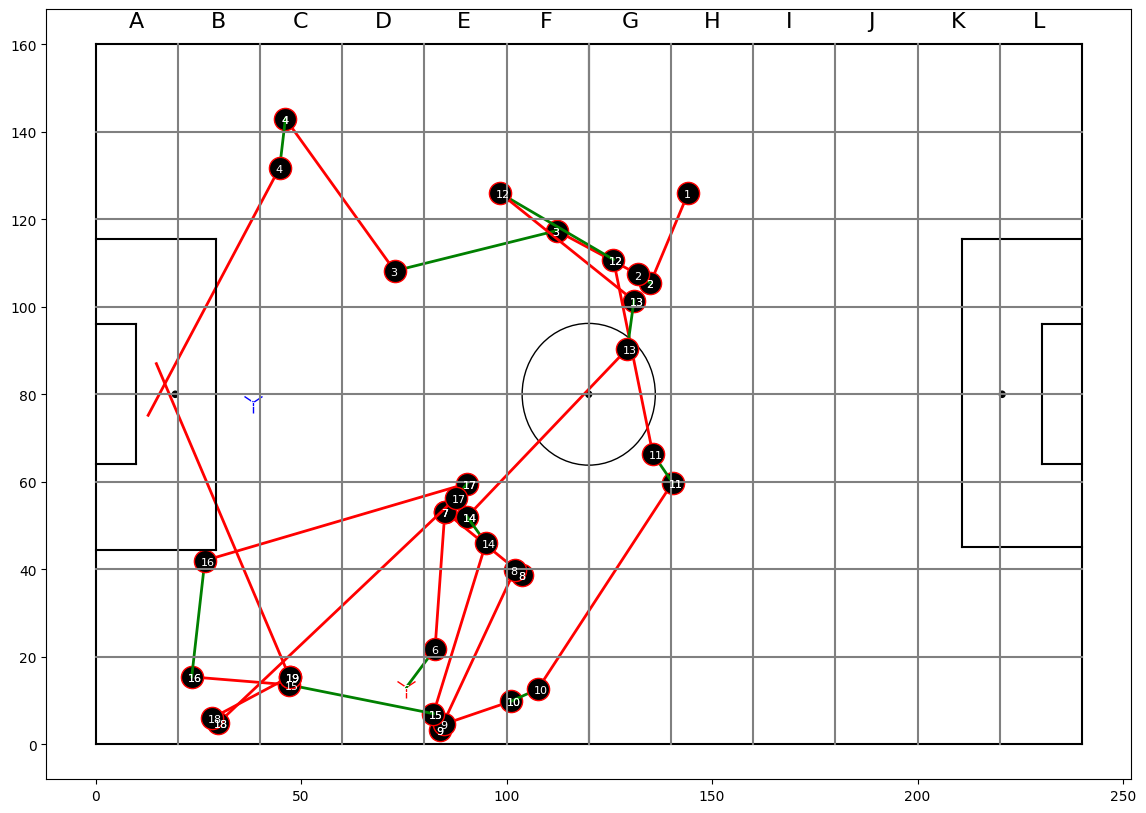

Sequence: 71
Team: Sweden
1: Robin Olsen (Carry) <00:44:56.811>
1: Robin Olsen (Pass) <00:45:12.926>
2: Alexander Isak (Ball Receipt*) <00:45:16.666>
2: Alexander Isak (Duel) <00:45:16.666>
3: Jan Bednarek (Pass) <00:45:16.666>
4: Albin Ekdal (Pass) <00:45:18.360>
5: Robin Quaison (Ball Receipt*) <00:45:19.850>


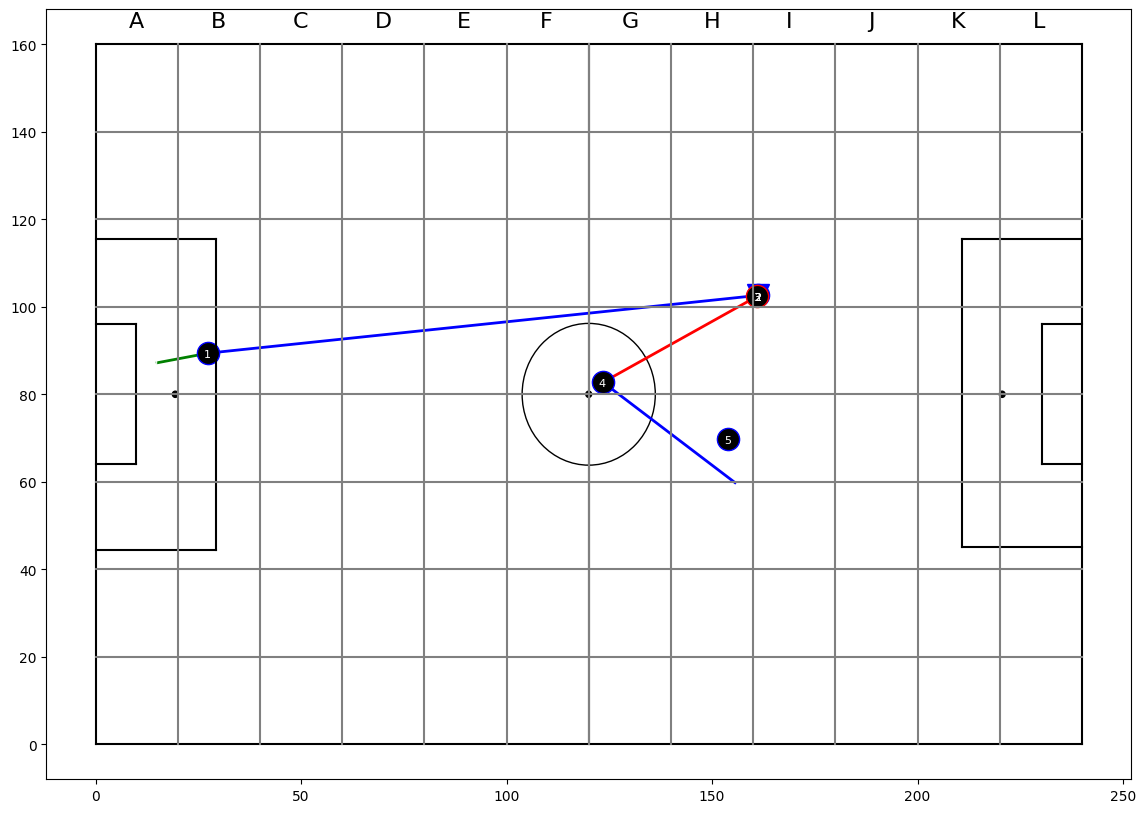

Sequence: 72
Team: Poland
1: Bartosz Bereszyński (Pass) <00:45:19.850>
2: Kamil Jóźwiak (Ball Receipt*) <00:45:20.968>
2: Kamil Jóźwiak (Carry) <00:45:20.968>
2: Kamil Jóźwiak (Pass) <00:45:26.995>
3: Piotr Zieliński (Ball Receipt*) <00:45:28.009>
3: Piotr Zieliński (Pass) <00:45:28.009>
4: Robert Lewandowski (Ball Receipt*) <00:45:28.625>
4: Robert Lewandowski (Pass) <00:45:28.625>
5: Piotr Zieliński (Ball Receipt*) <00:45:29.849>
5: Piotr Zieliński (Carry) <00:45:29.849>
5: Piotr Zieliński (Shot) <00:45:31.002>
5: Piotr Zieliński (Pass) <00:45:50.895>
6: Robert Lewandowski (Duel) <00:45:52.552>
7: Victor Nilsson Lindelöf (Clearance) <00:45:52.552>
8: Kristoffer Olsson (Clearance) <00:45:54.154>
9: Wojciech Szczęsny (Pass) <00:45:58.979>
10: Bartosz Bereszyński (Ball Receipt*) <00:46:00.628>
10: Bartosz Bereszyński (Carry) <00:46:00.628>
10: Bartosz Bereszyński (Pass) <00:46:02.652>
11: Karol Świderski (Ball Receipt*) <00:46:05.533>
12: Mikael Lustig (Duel) <00:46:05.533>
13: Karol Św

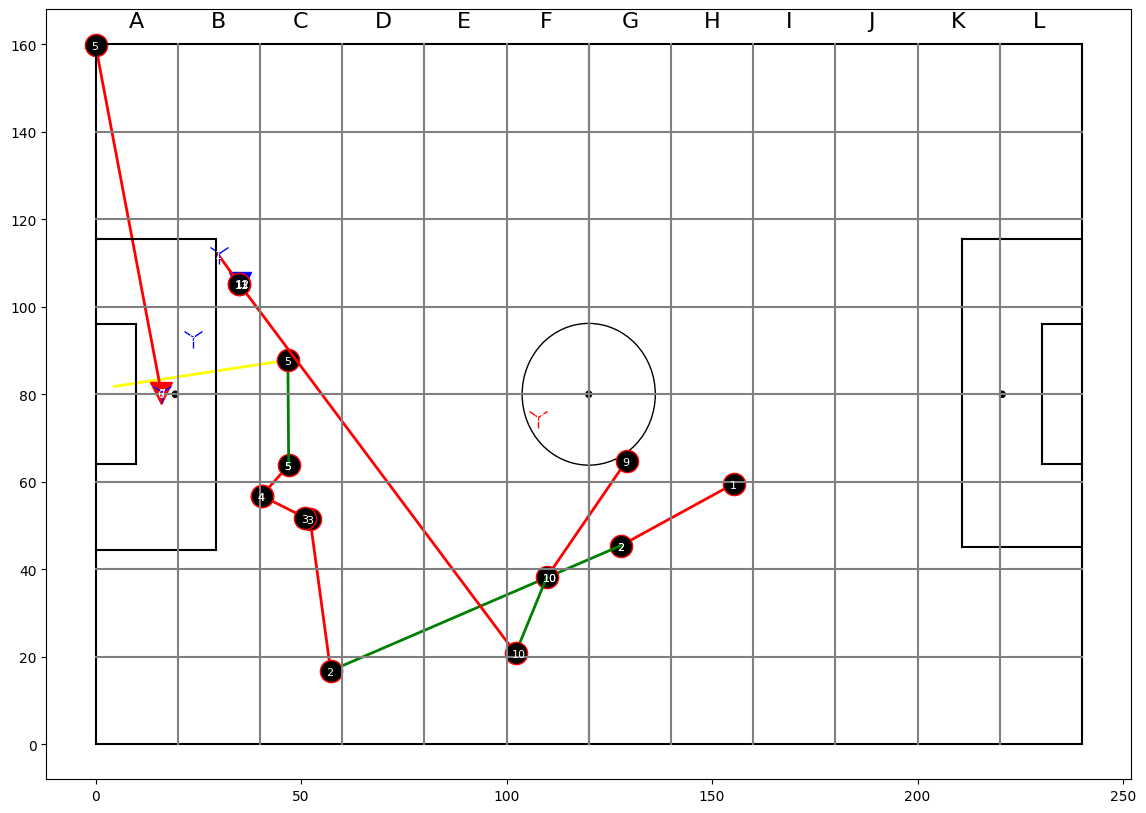

Sequence: 73
Team: Sweden
1: Emil Peter Forsberg (Pass) <00:46:13.466>
2: Ludwig Augustinsson (Ball Receipt*) <00:46:15.420>
2: Ludwig Augustinsson (Carry) <00:46:15.420>
2: Ludwig Augustinsson (Pass) <00:46:18.306>
3: Alexander Isak (Ball Receipt*) <00:46:20.356>
3: Alexander Isak (Pass) <00:46:20.356>
4: Mateusz Andrzej Klich (Duel) <00:46:20.356>
5: Tymoteusz Puchacz (Ball Recovery) <00:46:22.268>
5: Tymoteusz Puchacz (Carry) <00:46:22.268>
5: Tymoteusz Puchacz (Pass) <00:46:30.462>
6: Robin Olsen (Ball Recovery) <00:46:33.196>
6: Robin Olsen (Carry) <00:46:33.196>
6: Robin Olsen (Pass) <00:46:52.483>


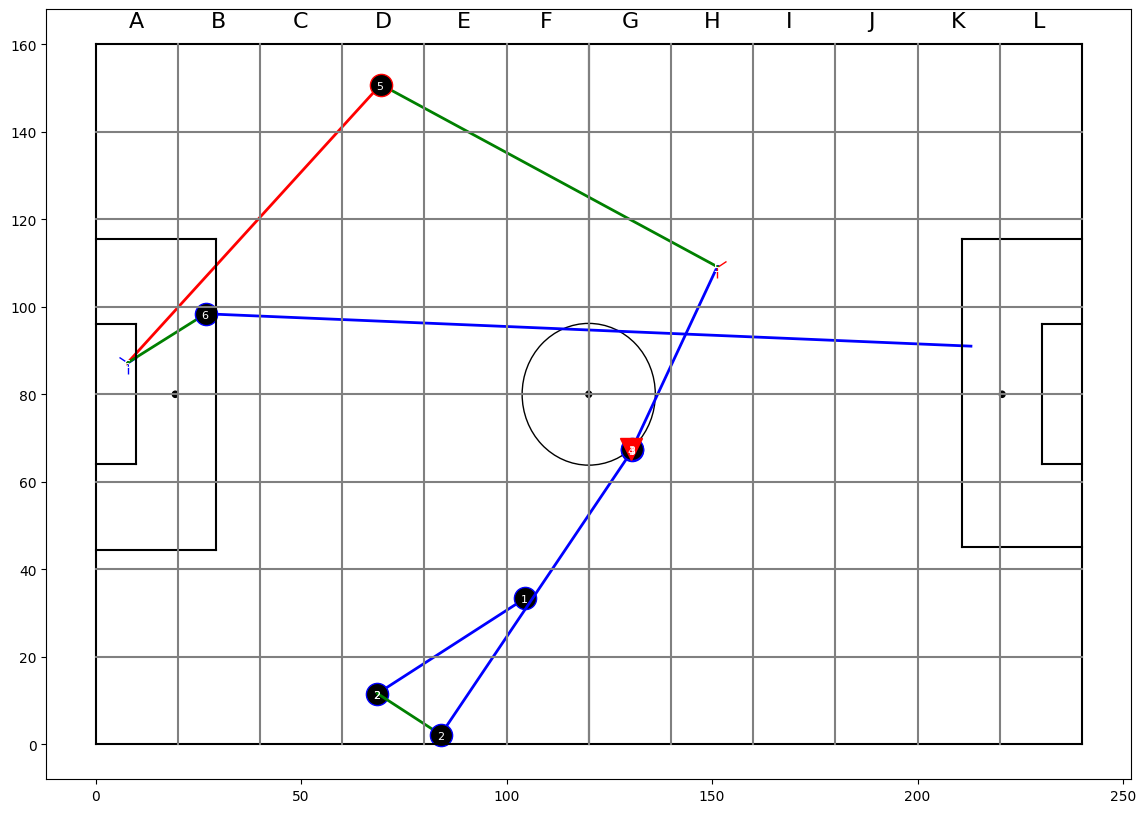

Sequence: 74
Team: Poland
1: Wojciech Szczęsny (Ball Recovery) <00:46:58.334>
1: Wojciech Szczęsny (Carry) <00:46:58.334>
1: Wojciech Szczęsny (Pass) <00:46:59.297>
2: Bartosz Bereszyński (Ball Receipt*) <00:47:00.920>
2: Bartosz Bereszyński (Carry) <00:47:00.920>
2: Bartosz Bereszyński (Pass) <00:47:03.388>
3: Kamil Jóźwiak (Ball Receipt*) <00:47:04.789>
3: Kamil Jóźwiak (Carry) <00:47:04.789>
3: Kamil Jóźwiak (Pass) <00:47:13.099>
4: Bartosz Bereszyński (Ball Receipt*) <00:47:14.054>
4: Bartosz Bereszyński (Carry) <00:47:14.054>
4: Bartosz Bereszyński (Pass) <00:47:16.172>
5: Grzegorz Krychowiak (Ball Receipt*) <00:47:17.588>
5: Grzegorz Krychowiak (Carry) <00:47:17.588>
5: Grzegorz Krychowiak (Pass) <00:47:19.394>
6: Kamil Jóźwiak (Ball Receipt*) <00:47:20.719>
6: Kamil Jóźwiak (Carry) <00:47:20.719>
6: Kamil Jóźwiak (Pass) <00:47:21.886>
7: Piotr Zieliński (Ball Receipt*) <00:47:24.044>


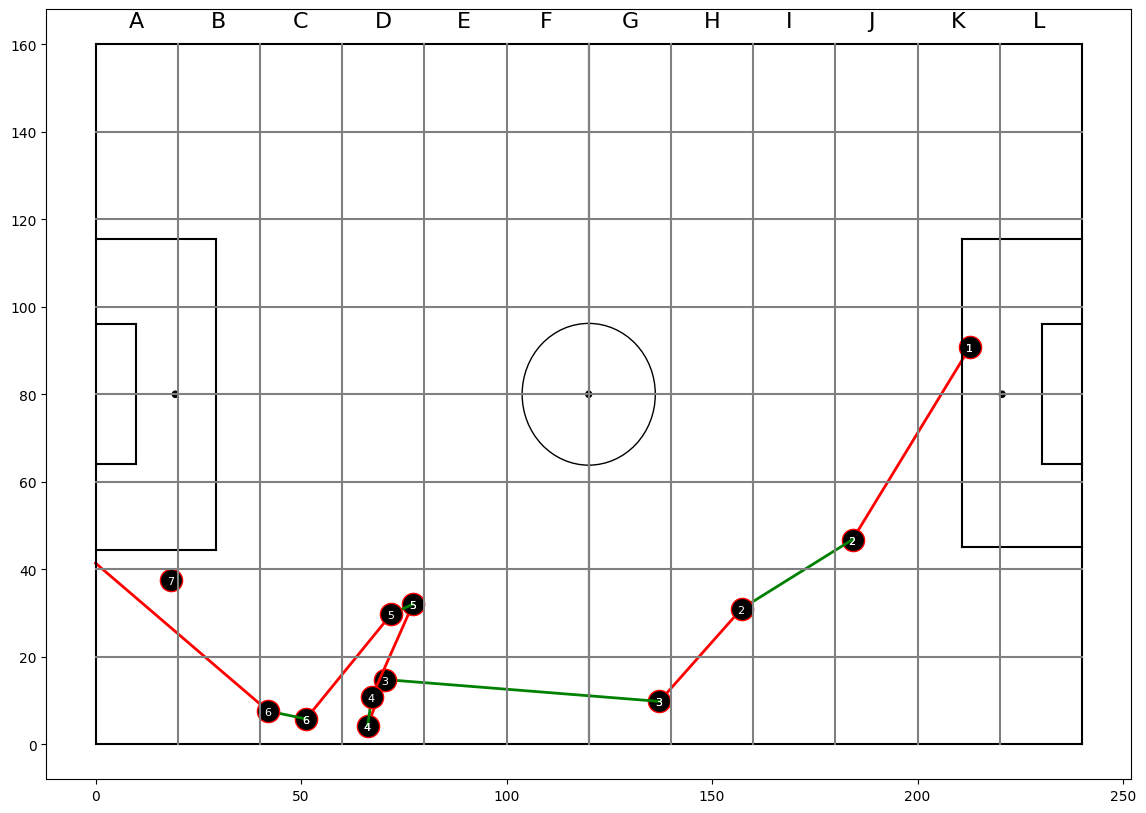

Sequence: 75
Team: Sweden
1: Robin Olsen (Pass) <00:47:53.035>
2: Alexander Isak (Ball Receipt*) <00:47:56.837>
2: Alexander Isak (Pass) <00:47:56.837>
3: Piotr Zieliński (Duel) <00:47:56.837>
4: Robin Quaison (Ball Receipt*) <00:47:58.581>
5: Kamil Glik (Pass) <00:47:58.581>
6: Robert Lewandowski (Duel) <00:48:01.069>
7: Mikael Lustig (Pass) <00:48:01.069>
8: Albin Ekdal (Ball Receipt*) <00:00:00.585>
9:  (Half End) <00:48:01.950>


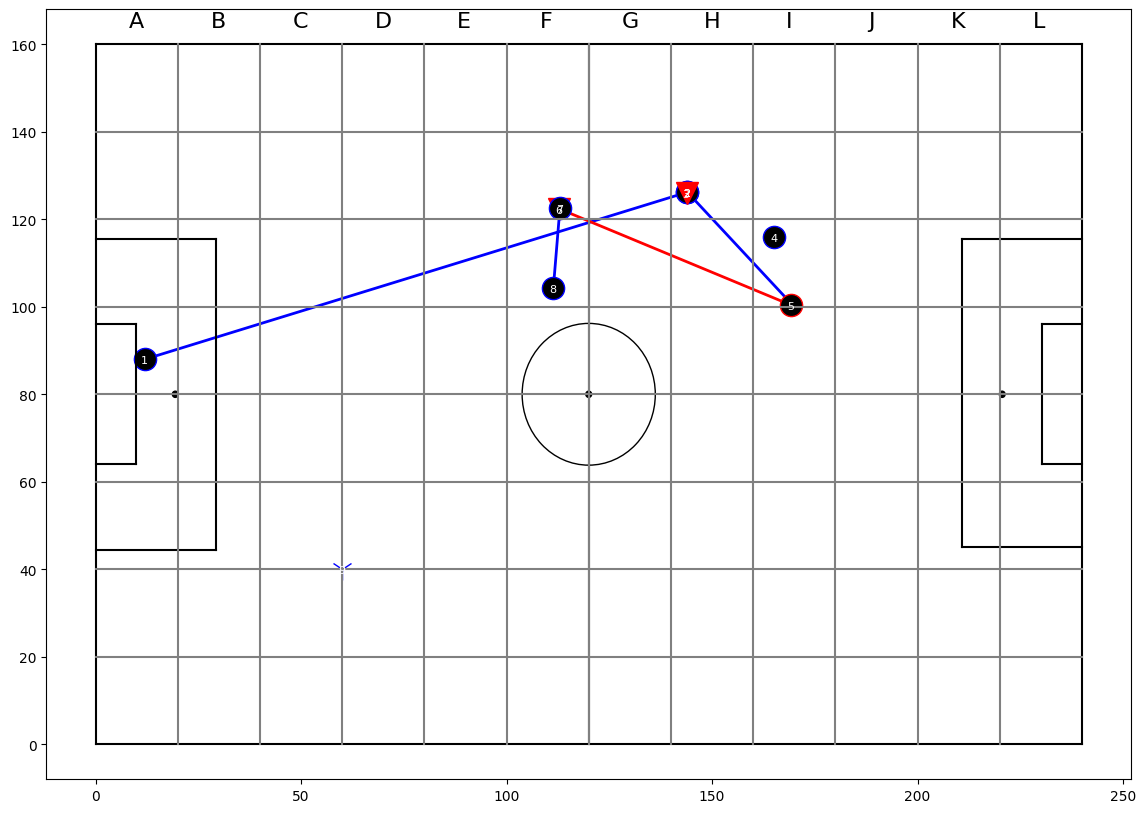

Sequence: 76
Team: Sweden
0:  (Half End) <00:48:01.950>


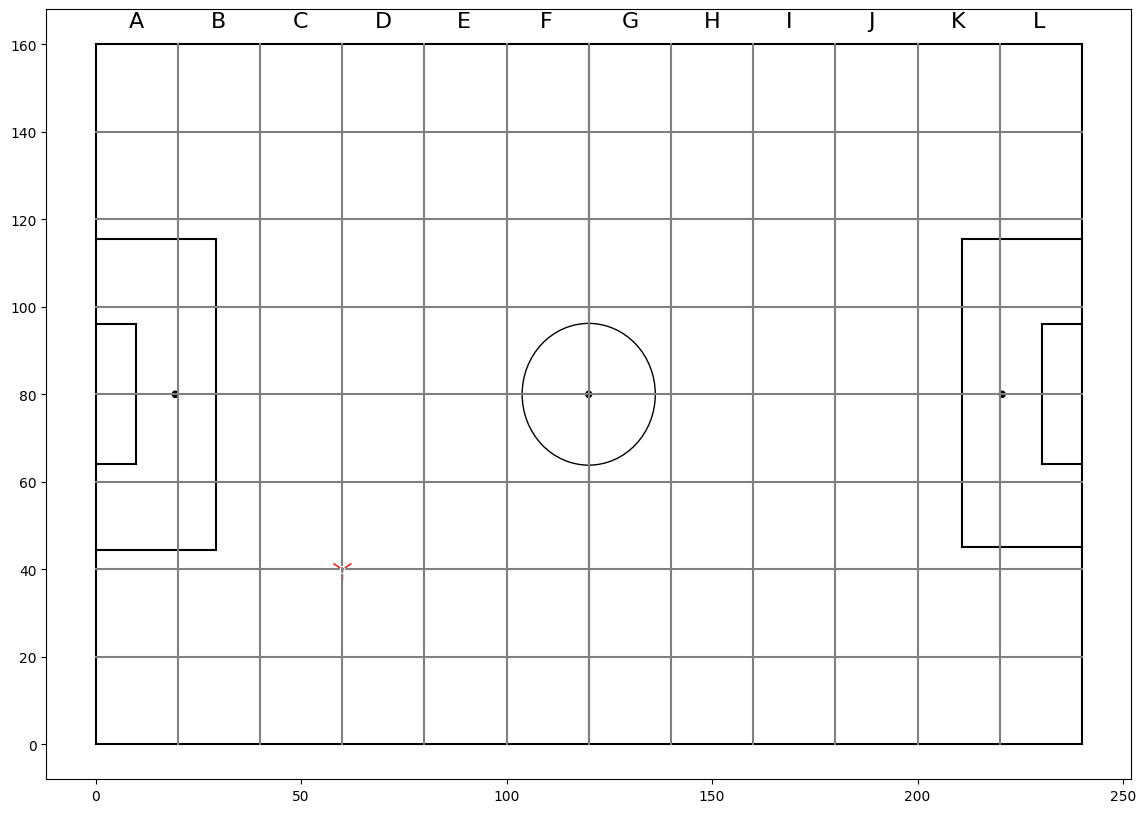

Sequence: 77
Team: Poland
1: Piotr Zieliński (Pass) <00:00:00.585>
2: Kamil Glik (Ball Receipt*) <00:00:02.113>
2: Kamil Glik (Carry) <00:00:02.113>
2: Kamil Glik (Pass) <00:00:03.811>
3: Robert Lewandowski (Duel) <00:00:06.969>
4: Victor Nilsson Lindelöf (Pass) <00:00:06.969>
5: Sebastian Larsson (Ball Receipt*) <00:00:09.248>
5: Sebastian Larsson (Pass) <00:00:09.248>


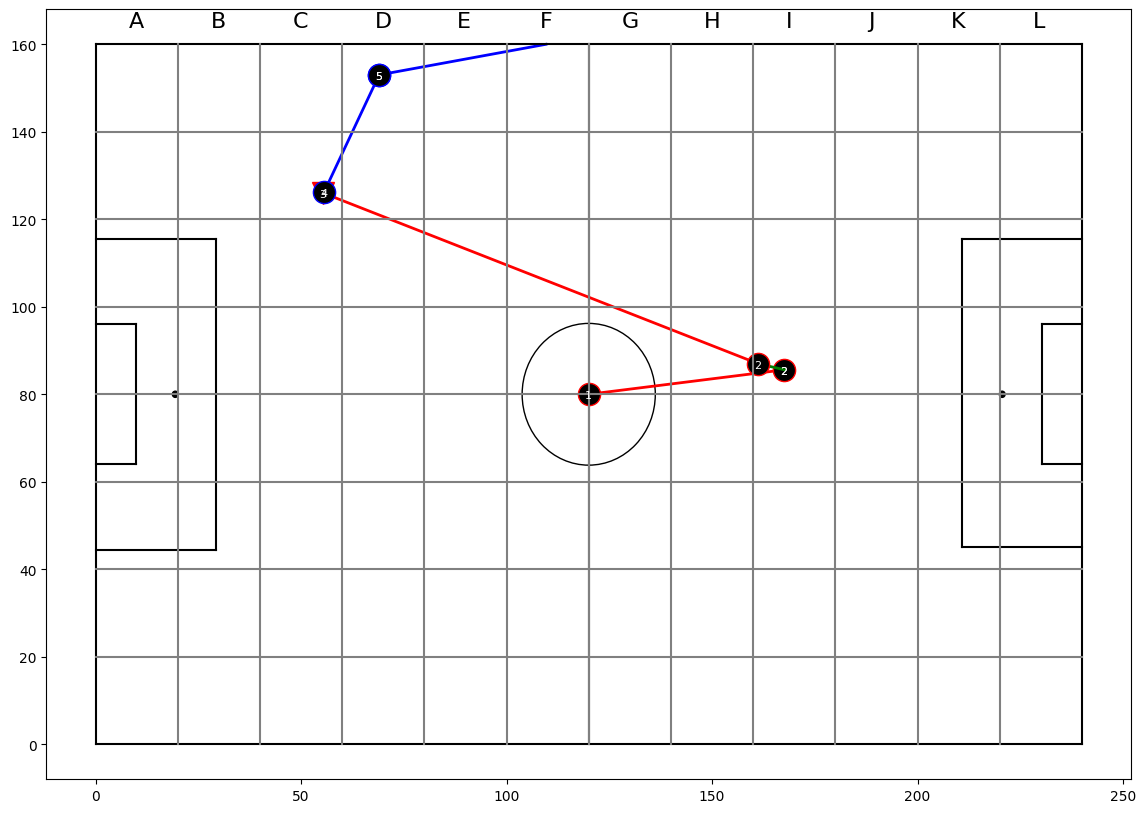

Sequence: 78
Team: Poland
1: Przemysław Frankowski (Pass) <00:00:23.609>
2: Jan Bednarek (Ball Receipt*) <00:00:25.099>
2: Jan Bednarek (Carry) <00:00:25.099>
2: Jan Bednarek (Pass) <00:00:26.725>
3: Bartosz Bereszyński (Ball Receipt*) <00:00:29.433>
3: Bartosz Bereszyński (Carry) <00:00:29.433>
3: Bartosz Bereszyński (Pass) <00:00:30.529>
4: Kamil Jóźwiak (Ball Receipt*) <00:00:32.272>
4: Kamil Jóźwiak (Carry) <00:00:32.272>
4: Kamil Jóźwiak (Pass) <00:00:35.382>
5: Kamil Glik (Ball Receipt*) <00:00:37.105>
5: Kamil Glik (Carry) <00:00:37.105>
5: Kamil Glik (Pass) <00:00:37.929>
6: Jan Bednarek (Ball Receipt*) <00:00:39.381>
6: Jan Bednarek (Carry) <00:00:39.381>
6: Jan Bednarek (Pass) <00:00:41.503>
7: Kamil Glik (Ball Receipt*) <00:00:43.930>
7: Kamil Glik (Carry) <00:00:43.930>
7: Kamil Glik (Pass) <00:00:46.187>
8: Bartosz Bereszyński (Ball Receipt*) <00:00:47.454>
8: Bartosz Bereszyński (Carry) <00:00:47.454>
8: Bartosz Bereszyński (Pass) <00:00:49.277>


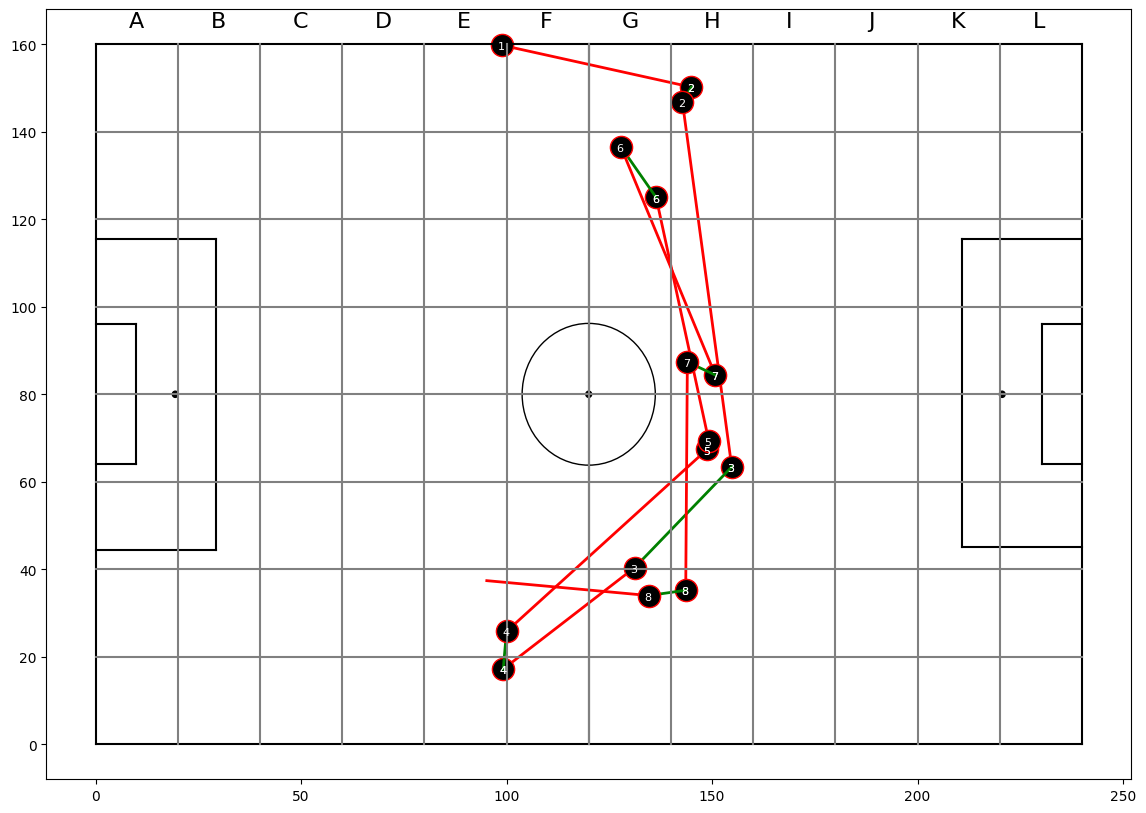

Sequence: 79
Team: Sweden
1: Emil Peter Forsberg (Ball Recovery) <00:00:49.899>
1: Emil Peter Forsberg (Carry) <00:00:49.899>
1: Emil Peter Forsberg (Dispossessed) <00:00:53.544>
2: Bartosz Bereszyński (Duel) <00:00:53.544>
3: Emil Peter Forsberg (Ball Recovery) <00:00:54.677>
3: Emil Peter Forsberg (Carry) <00:00:54.677>
4: Bartosz Bereszyński (Foul Committed) <00:00:56.129>
5: Emil Peter Forsberg (Foul Won) <00:00:56.129>
6: Albin Ekdal (Pass) <00:01:04.609>
7: Marcus Andreas Danielsson (Ball Receipt*) <00:01:06.427>
7: Marcus Andreas Danielsson (Pass) <00:01:07.754>
8: Mikael Lustig (Ball Receipt*) <00:01:10.006>
8: Mikael Lustig (Pass) <00:01:10.006>
9: Sebastian Larsson (Ball Receipt*) <00:01:12.707>


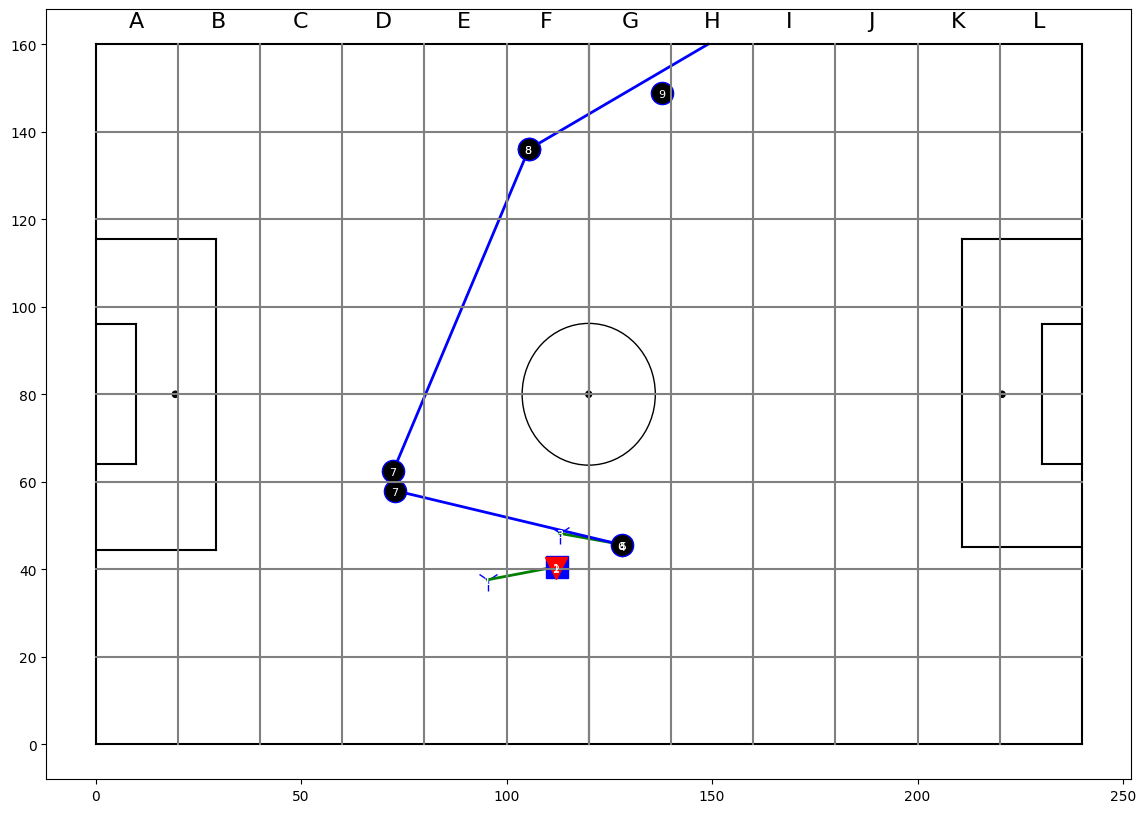

Sequence: 80
Team: Poland
1: Jan Bednarek (Pass) <00:01:17.751>
2: Kamil Glik (Ball Receipt*) <00:01:19.374>
2: Kamil Glik (Carry) <00:01:19.374>
2: Kamil Glik (Pass) <00:01:20.762>
3: Bartosz Bereszyński (Ball Receipt*) <00:01:22.165>
3: Bartosz Bereszyński (Carry) <00:01:22.165>
3: Bartosz Bereszyński (Pass) <00:01:24.218>
4: Jan Bednarek (Ball Receipt*) <00:01:25.867>
4: Jan Bednarek (Carry) <00:01:25.867>
4: Jan Bednarek (Pass) <00:01:26.927>
5: Grzegorz Krychowiak (Ball Receipt*) <00:01:28.213>
5: Grzegorz Krychowiak (Carry) <00:01:28.213>
5: Grzegorz Krychowiak (Pass) <00:01:28.517>
6: Jan Bednarek (Ball Receipt*) <00:01:29.690>
6: Jan Bednarek (Carry) <00:01:29.690>
6: Jan Bednarek (Pass) <00:01:34.856>
7: Kamil Glik (Ball Receipt*) <00:01:36.138>
7: Kamil Glik (Carry) <00:01:36.138>
7: Kamil Glik (Pass) <00:01:37.760>
8: Bartosz Bereszyński (Ball Receipt*) <00:01:38.984>
8: Bartosz Bereszyński (Carry) <00:01:38.984>
8: Bartosz Bereszyński (Pass) <00:01:39.761>
9: Kamil Jóźwiak 

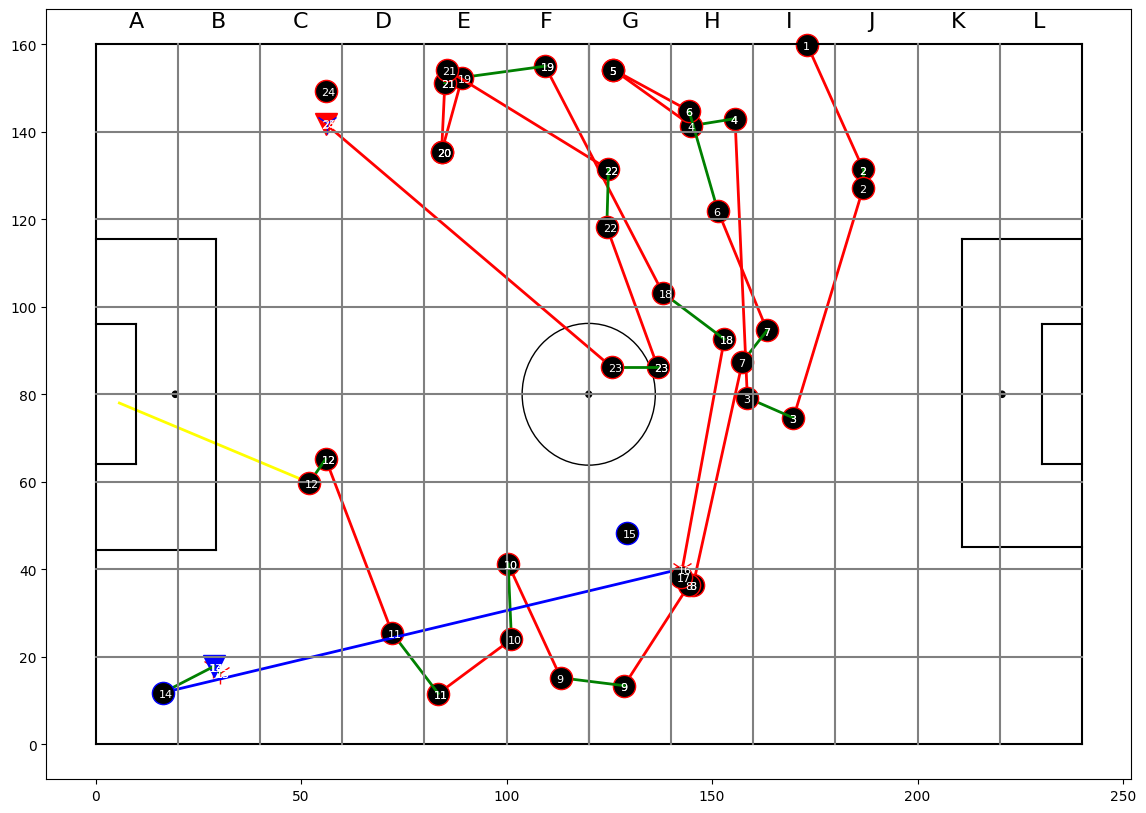

Sequence: 81
Team: Poland
1: Grzegorz Krychowiak (Pass) <00:02:37.987>
2: Przemysław Frankowski (Ball Receipt*) <00:02:38.650>
2: Przemysław Frankowski (Pass) <00:02:38.996>
3: Robert Lewandowski (Ball Receipt*) <00:02:40.244>
3: Robert Lewandowski (Pass) <00:02:40.794>
4: Jan Bednarek (Ball Receipt*) <00:02:42.395>
4: Jan Bednarek (Carry) <00:02:42.395>
4: Jan Bednarek (Pass) <00:02:43.874>
5: Kamil Glik (Ball Receipt*) <00:02:45.374>
5: Kamil Glik (Carry) <00:02:45.374>
5: Kamil Glik (Pass) <00:02:46.560>
6: Bartosz Bereszyński (Ball Receipt*) <00:02:47.847>
6: Bartosz Bereszyński (Carry) <00:02:47.847>
6: Bartosz Bereszyński (Pass) <00:02:49.086>
7: Kamil Jóźwiak (Ball Receipt*) <00:02:50.578>
7: Kamil Jóźwiak (Carry) <00:02:50.578>
7: Kamil Jóźwiak (Pass) <00:02:53.129>
8: Piotr Zieliński (Ball Receipt*) <00:02:54.189>
8: Piotr Zieliński (Pass) <00:02:54.189>
9: Kamil Jóźwiak (Ball Receipt*) <00:02:55.258>
9: Kamil Jóźwiak (Carry) <00:02:55.258>
9: Kamil Jóźwiak (Pass) <00:02:56.15

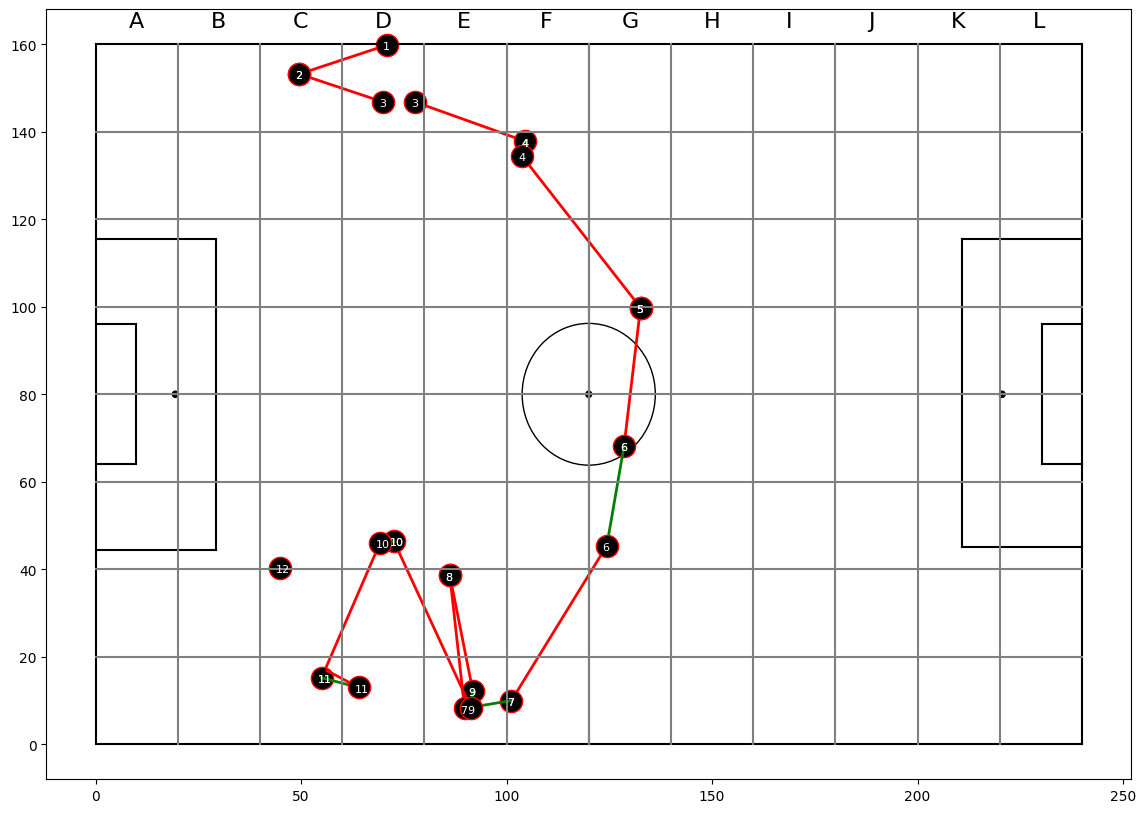

Sequence: 82
Team: Sweden
1: Ludwig Augustinsson (Pass) <00:03:01.734>
2: Kristoffer Olsson (Ball Receipt*) <00:03:04.079>
2: Kristoffer Olsson (Pass) <00:03:04.079>
3: Alexander Isak (Ball Receipt*) <00:03:08.321>
3: Alexander Isak (Carry) <00:03:08.321>
3: Alexander Isak (Miscontrol) <00:03:08.379>
3: Alexander Isak (Duel) <00:03:09.440>
4: Bartosz Bereszyński (Pass) <00:03:09.440>
5: Kamil Jóźwiak (Ball Receipt*) <00:03:11.553>
5: Kamil Jóźwiak (Carry) <00:03:11.553>
5: Kamil Jóźwiak (Miscontrol) <00:03:11.631>
6: Albin Ekdal (Ball Recovery) <00:03:13.767>
6: Albin Ekdal (Carry) <00:03:13.767>
6: Albin Ekdal (Pass) <00:03:13.982>
7: Ludwig Augustinsson (Ball Receipt*) <00:03:15.104>
7: Ludwig Augustinsson (Pass) <00:03:15.104>


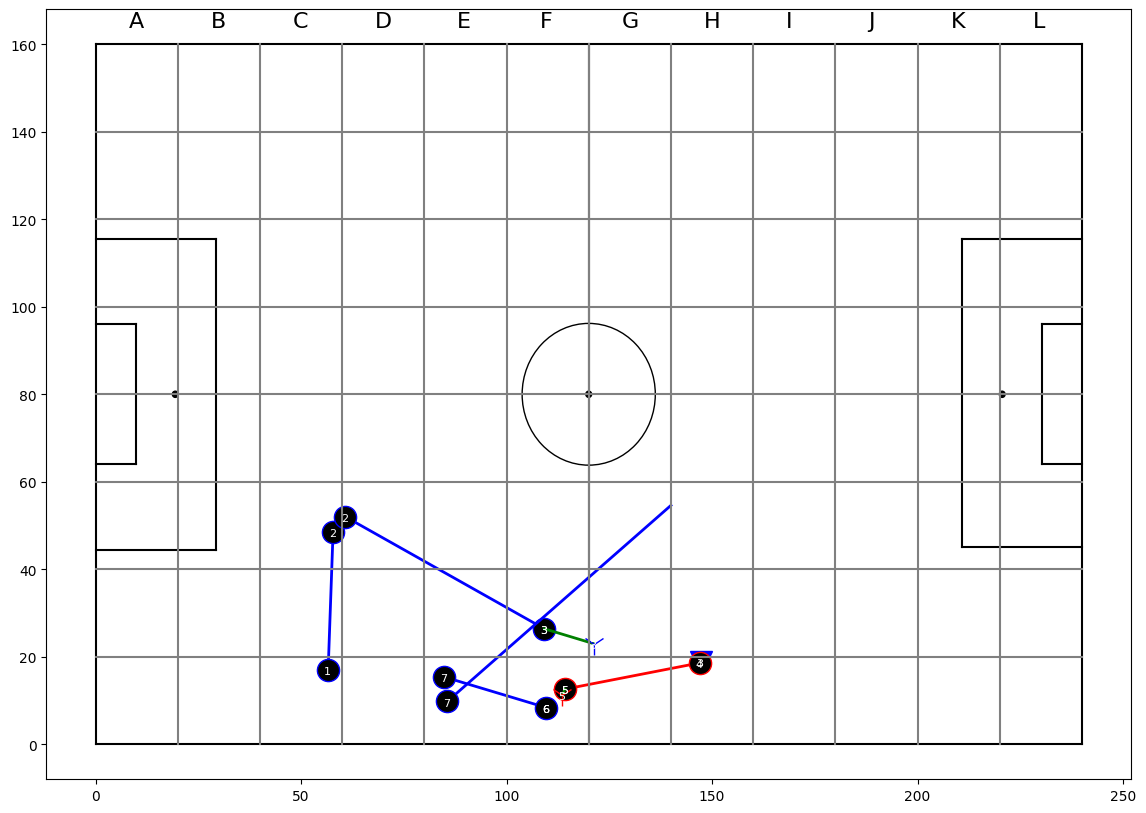

Sequence: 83
Team: Poland
1: Jan Bednarek (Ball Recovery) <00:03:18.133>
1: Jan Bednarek (Carry) <00:03:18.133>
1: Jan Bednarek (Pass) <00:03:19.179>
2: Przemysław Frankowski (Ball Receipt*) <00:03:20.861>
2: Przemysław Frankowski (Carry) <00:03:20.861>
2: Przemysław Frankowski (Pass) <00:03:24.993>
3: Piotr Zieliński (Ball Receipt*) <00:03:25.839>
3: Piotr Zieliński (Carry) <00:03:25.839>
3: Piotr Zieliński (Shot) <00:03:26.916>
4: Victor Nilsson Lindelöf (Block) <00:03:27.171>


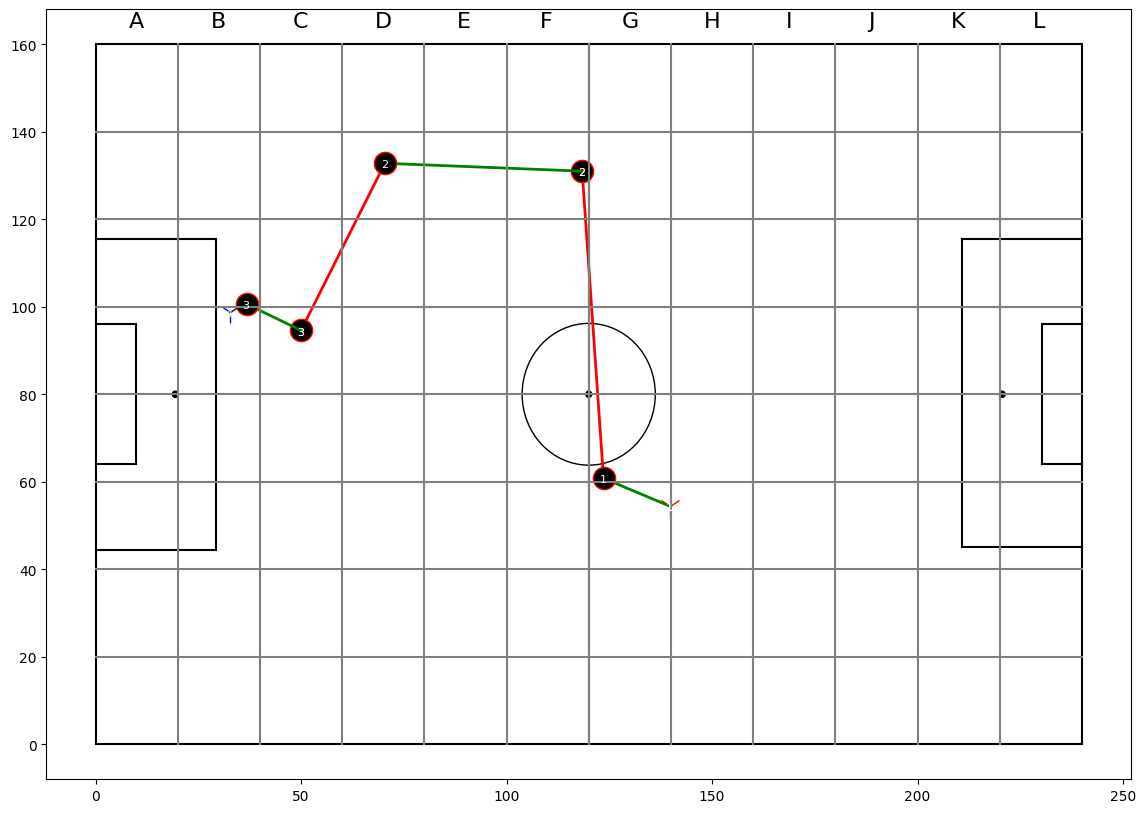

Sequence: 84
Team: Poland
1: Piotr Zieliński (Pass) <00:03:43.912>
2: Mateusz Andrzej Klich (Ball Receipt*) <00:03:45.126>
2: Mateusz Andrzej Klich (Carry) <00:03:45.126>
2: Mateusz Andrzej Klich (Pass) <00:03:45.982>
3: Piotr Zieliński (Ball Receipt*) <00:03:47.062>
3: Piotr Zieliński (Carry) <00:03:47.062>
3: Piotr Zieliński (Pass) <00:03:47.241>
4: Przemysław Frankowski (Ball Receipt*) <00:03:48.271>
4: Przemysław Frankowski (Carry) <00:03:48.271>
4: Przemysław Frankowski (Pass) <00:03:49.693>
5: Karol Świderski (Ball Receipt*) <00:03:50.686>
6: Marcus Andreas Danielsson (Duel) <00:03:50.707>
7: Karol Świderski (Shot) <00:03:50.707>


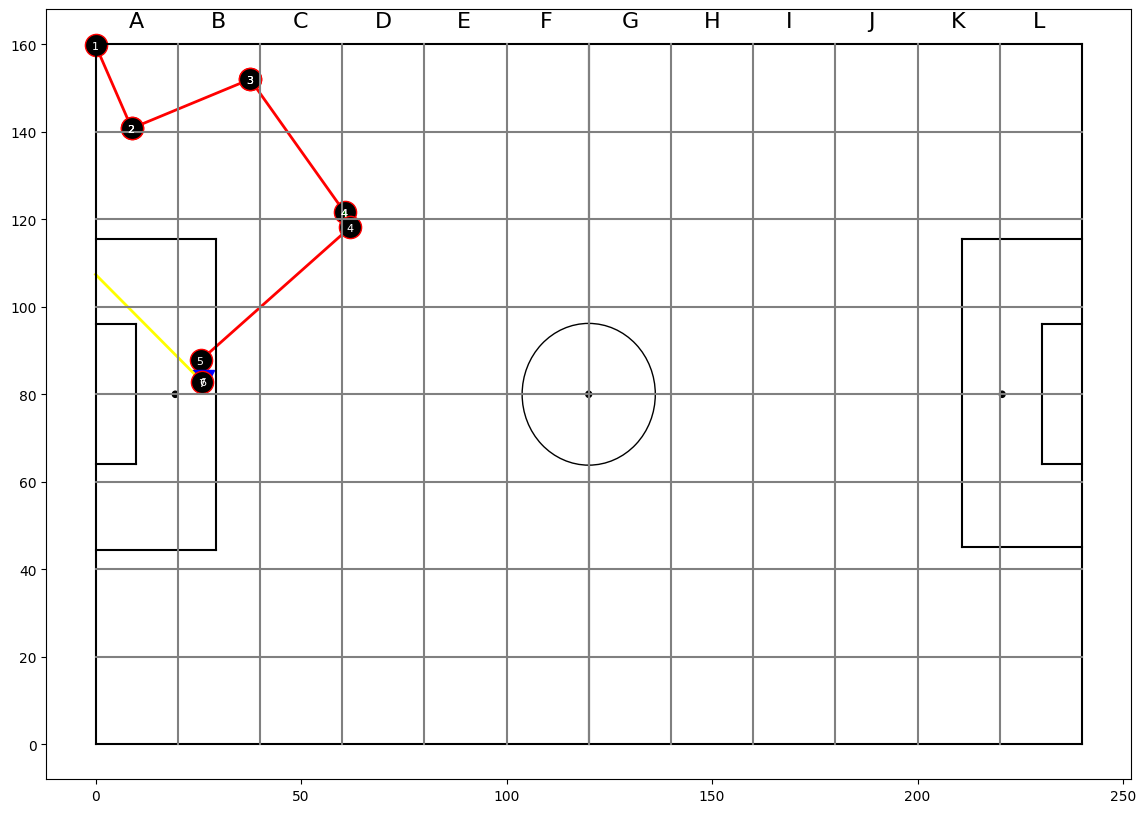

Sequence: 85
Team: Sweden
1: Robin Olsen (Pass) <00:04:16.105>
2: Jan Bednarek (Ball Recovery) <00:04:22.912>
2: Jan Bednarek (Carry) <00:04:22.912>
2: Jan Bednarek (Pass) <00:04:23.604>
3: Sebastian Larsson (Pass) <00:04:24.676>
4: Robin Quaison (Ball Receipt*) <00:04:26.491>
4: Robin Quaison (Carry) <00:04:26.491>
4: Robin Quaison (Shot) <00:04:28.639>
5: Emil Peter Forsberg (Ball Recovery) <00:04:30.584>
5: Emil Peter Forsberg (Shot) <00:04:30.660>
6: Bartosz Bereszyński (Block) <00:04:30.897>


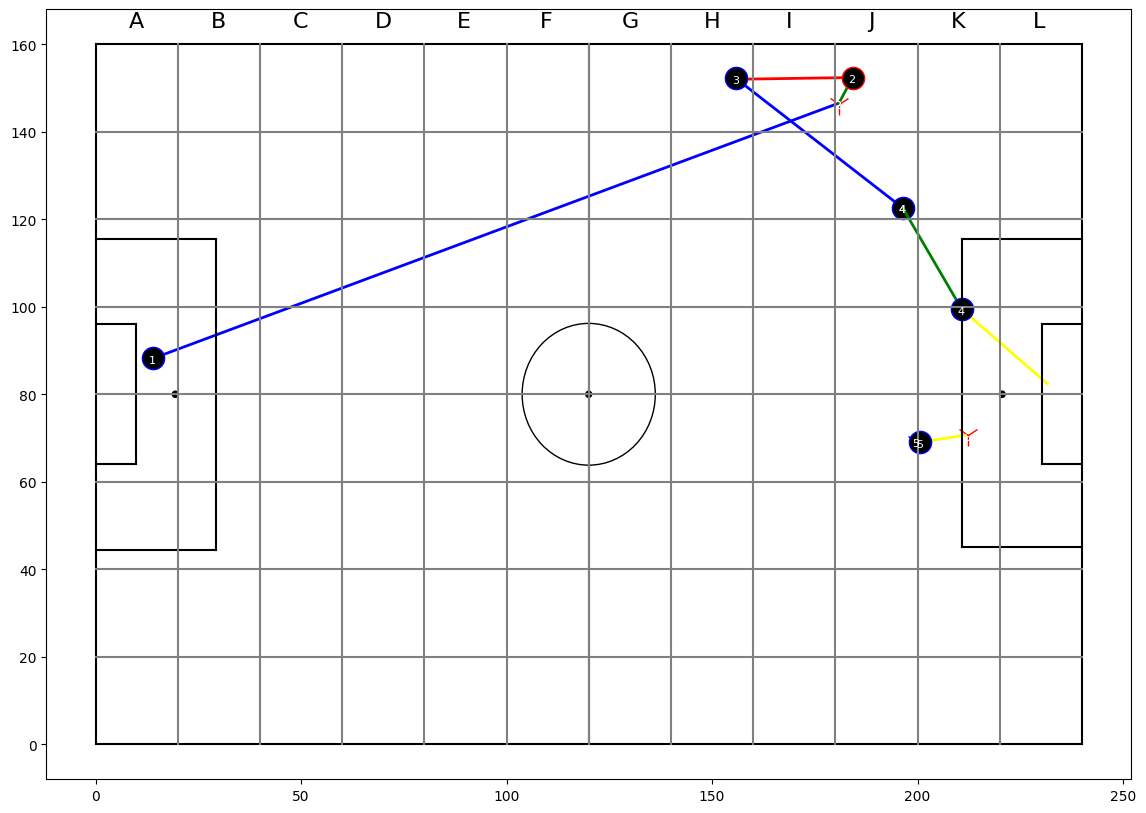

Sequence: 86
Team: Sweden
1: Emil Peter Forsberg (Pass) <00:04:57.066>
2: Mikael Lustig (Ball Recovery) <00:05:01.244>
3: Kamil Jóźwiak (Duel) <00:05:01.297>
4: Mikael Lustig (Shot) <00:05:01.297>


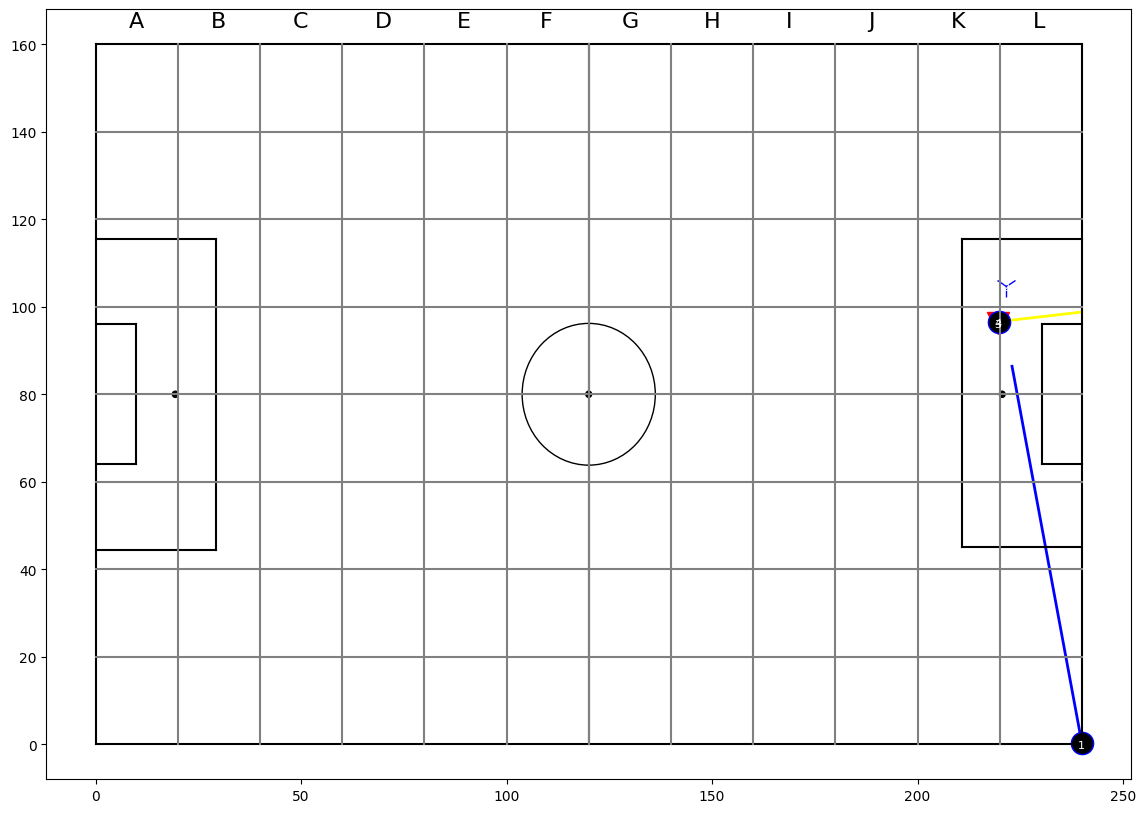

Sequence: 87
Team: Poland
1: Wojciech Szczęsny (Pass) <00:05:07.855>
2: Karol Świderski (Ball Receipt*) <00:05:11.643>
3: Emil Peter Forsberg (Duel) <00:05:11.643>
4: Karol Świderski (Miscontrol) <00:05:11.643>
5: Robin Olsen (Ball Recovery) <00:05:15.783>
5: Robin Olsen (Carry) <00:05:15.783>
5: Robin Olsen (Pass) <00:05:26.638>
6: Mateusz Andrzej Klich (Ball Recovery) <00:05:28.495>
7: Kamil Jóźwiak (Ball Recovery) <00:05:30.474>
7: Kamil Jóźwiak (Carry) <00:05:30.474>
7: Kamil Jóźwiak (Pass) <00:05:33.360>
8: Grzegorz Krychowiak (Ball Receipt*) <00:05:34.566>
8: Grzegorz Krychowiak (Carry) <00:05:34.566>
8: Grzegorz Krychowiak (Pass) <00:05:35.268>
9: Kamil Jóźwiak (Ball Receipt*) <00:05:36.065>
9: Kamil Jóźwiak (Carry) <00:05:36.065>
9: Kamil Jóźwiak (Pass) <00:05:38.613>


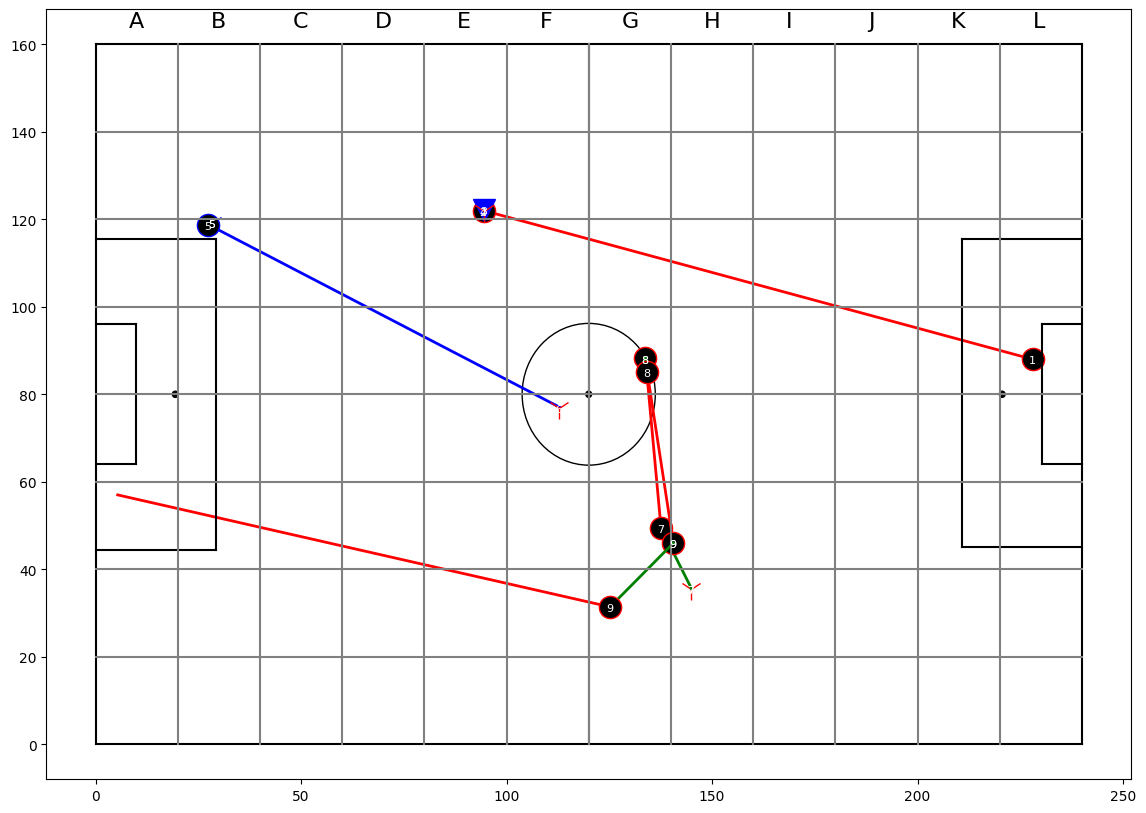

Sequence: 88
Team: Sweden
1: Robin Olsen (Ball Recovery) <00:05:43.804>
1: Robin Olsen (Carry) <00:05:43.804>
1: Robin Olsen (Pass) <00:05:47.650>
2: Victor Nilsson Lindelöf (Ball Receipt*) <00:05:49.581>
2: Victor Nilsson Lindelöf (Carry) <00:05:49.581>
2: Victor Nilsson Lindelöf (Pass) <00:05:52.241>
3: Mikael Lustig (Ball Receipt*) <00:05:53.415>
3: Mikael Lustig (Carry) <00:05:53.415>
3: Mikael Lustig (Pass) <00:05:55.786>


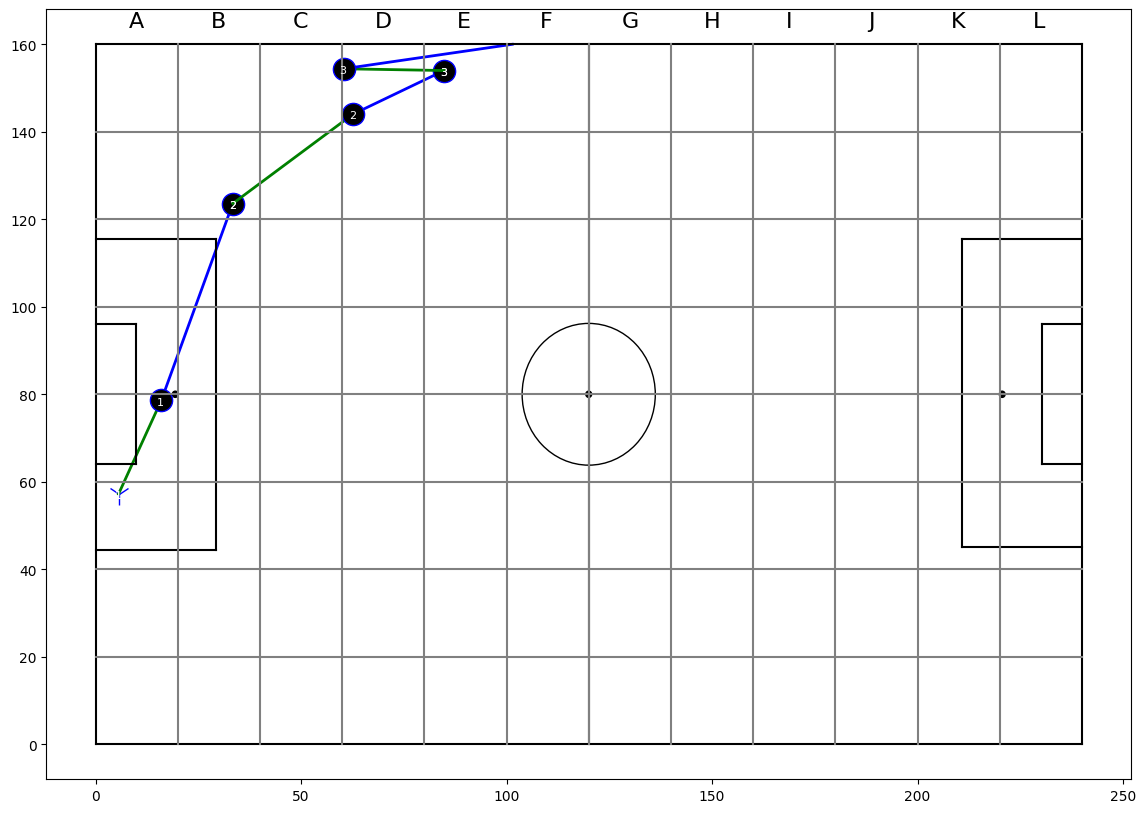

Sequence: 89
Team: Poland
1: Przemysław Frankowski (Pass) <00:06:10.624>
2: Jan Bednarek (Ball Receipt*) <00:06:11.521>
2: Jan Bednarek (Carry) <00:06:11.521>
2: Jan Bednarek (Pass) <00:06:13.057>
3: Bartosz Bereszyński (Ball Receipt*) <00:06:15.081>
3: Bartosz Bereszyński (Carry) <00:06:15.081>
3: Bartosz Bereszyński (Pass) <00:06:16.240>
4: Kamil Jóźwiak (Ball Receipt*) <00:06:18.495>
4: Kamil Jóźwiak (Carry) <00:06:18.495>
4: Kamil Jóźwiak (Dribble) <00:06:22.148>
4: Kamil Jóźwiak (Carry) <00:06:22.148>
4: Kamil Jóźwiak (Pass) <00:06:23.835>
5: Grzegorz Krychowiak (Ball Receipt*) <00:06:25.478>
5: Grzegorz Krychowiak (Carry) <00:06:25.478>
5: Grzegorz Krychowiak (Shot) <00:06:26.571>
6: Marcus Andreas Danielsson (Clearance) <00:06:28.729>


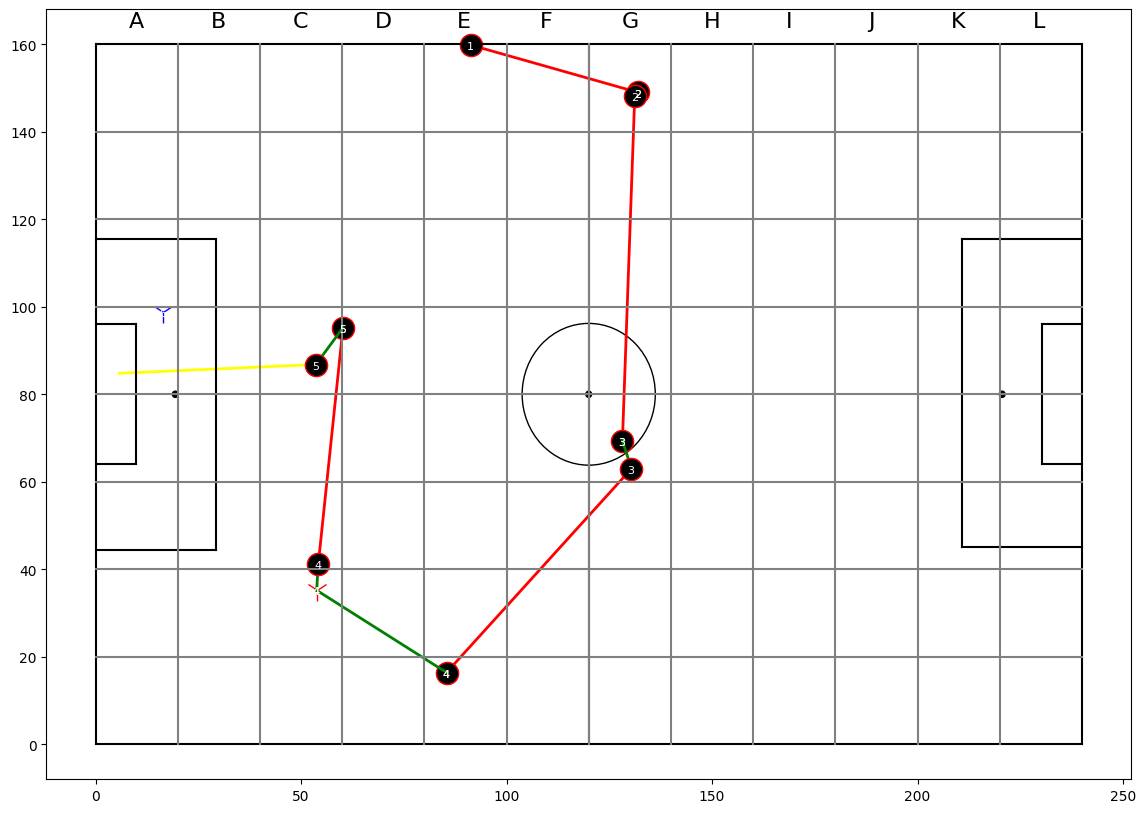

Sequence: 90
Team: Poland
1: Przemysław Frankowski (Pass) <00:06:36.910>
2: Piotr Zieliński (Ball Receipt*) <00:06:37.844>
2: Piotr Zieliński (Carry) <00:06:37.844>
2: Piotr Zieliński (Pass) <00:06:39.469>
3: Przemysław Frankowski (Ball Receipt*) <00:06:40.692>
3: Przemysław Frankowski (Carry) <00:06:40.692>
3: Przemysław Frankowski (Pass) <00:06:43.985>
4: Mateusz Andrzej Klich (Ball Receipt*) <00:06:45.149>
4: Mateusz Andrzej Klich (Carry) <00:06:45.149>
4: Mateusz Andrzej Klich (Pass) <00:06:45.464>
5: Przemysław Frankowski (Ball Receipt*) <00:06:46.325>
5: Przemysław Frankowski (Carry) <00:06:46.325>
5: Przemysław Frankowski (Pass) <00:06:47.120>
6: Piotr Zieliński (Ball Receipt*) <00:06:48.233>
6: Piotr Zieliński (Carry) <00:06:48.233>
6: Piotr Zieliński (Pass) <00:06:50.951>
7: Robert Lewandowski (Foul Committed) <00:06:52.418>
8: Marcus Andreas Danielsson (Foul Won) <00:06:52.418>


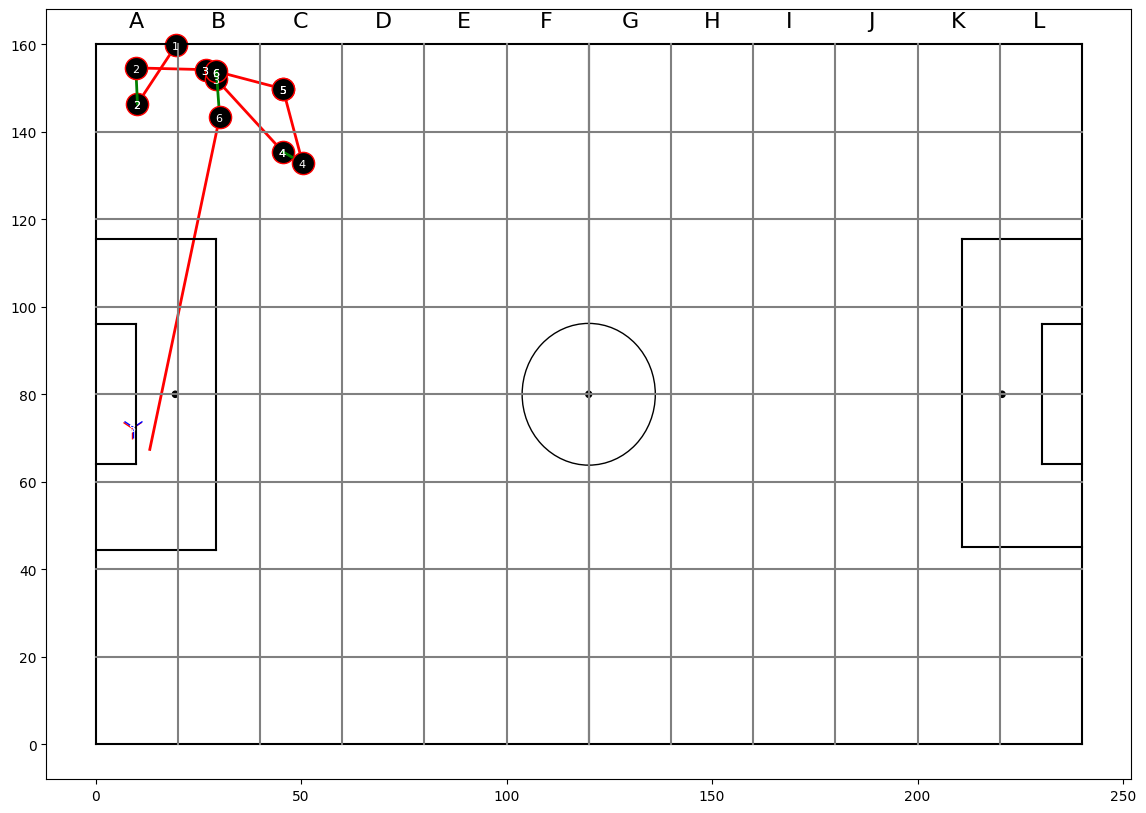

Sequence: 91
Team: Sweden
1: Robin Olsen (Pass) <00:07:27.410>
2: Alexander Isak (Duel) <00:07:31.294>


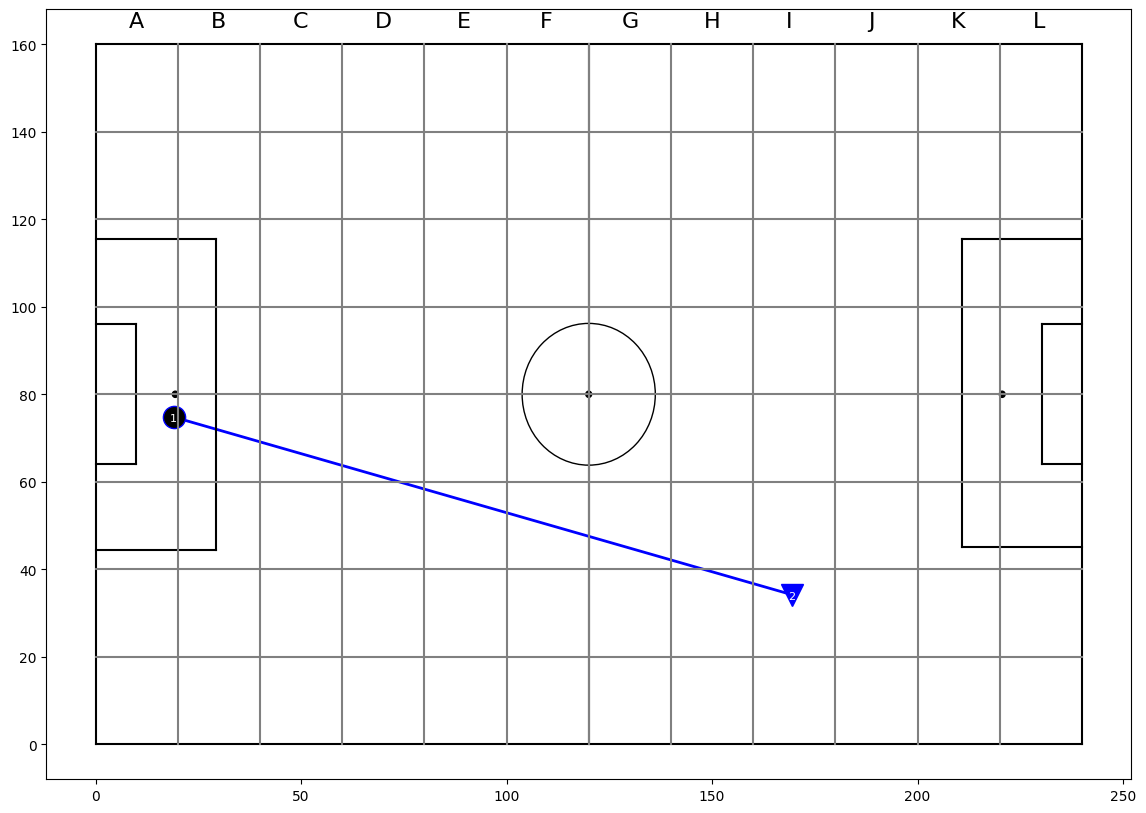

Sequence: 92
Team: Poland
1: Kamil Glik (Pass) <00:07:31.294>
2: Robert Lewandowski (Ball Receipt*) <00:07:33.695>
3: Victor Nilsson Lindelöf (Duel) <00:07:33.721>
4: Robert Lewandowski (Pass) <00:07:33.721>
5: Karol Świderski (Ball Receipt*) <00:07:33.795>
5: Karol Świderski (Carry) <00:07:33.795>
6: Victor Nilsson Lindelöf (Block) <00:07:33.795>
7: Karol Świderski (Pass) <00:07:34.987>
8: Albin Ekdal (Ball Recovery) <00:07:36.291>
8: Albin Ekdal (Carry) <00:07:36.291>
8: Albin Ekdal (Dispossessed) <00:07:36.567>
9: Robert Lewandowski (Duel) <00:07:36.567>
9: Robert Lewandowski (Carry) <00:07:36.567>
9: Robert Lewandowski (Pass) <00:07:41.567>
10: Kamil Jóźwiak (Ball Receipt*) <00:07:42.842>
10: Kamil Jóźwiak (Carry) <00:07:42.842>
10: Kamil Jóźwiak (Pass) <00:07:46.357>


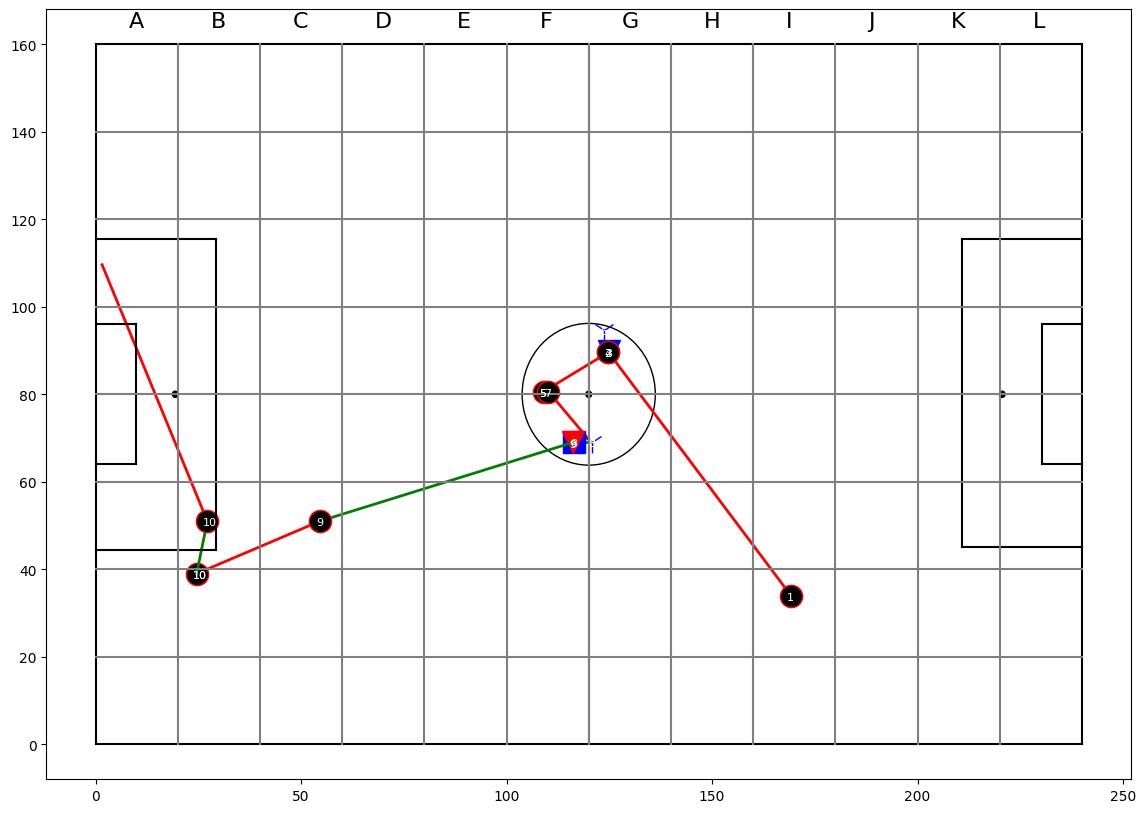

Sequence: 93
Team: Sweden
1: Robin Olsen (Pass) <00:08:18.679>
2: Sebastian Larsson (Ball Receipt*) <00:08:22.422>
3: Grzegorz Krychowiak (Pass) <00:08:22.422>
4: Robert Lewandowski (Duel) <00:08:24.592>
5: Victor Nilsson Lindelöf (Pass) <00:08:24.592>
6: Sebastian Larsson (Ball Receipt*) <00:08:26.054>
6: Sebastian Larsson (Pass) <00:08:26.054>
7: Alexander Isak (Ball Receipt*) <00:08:30.430>


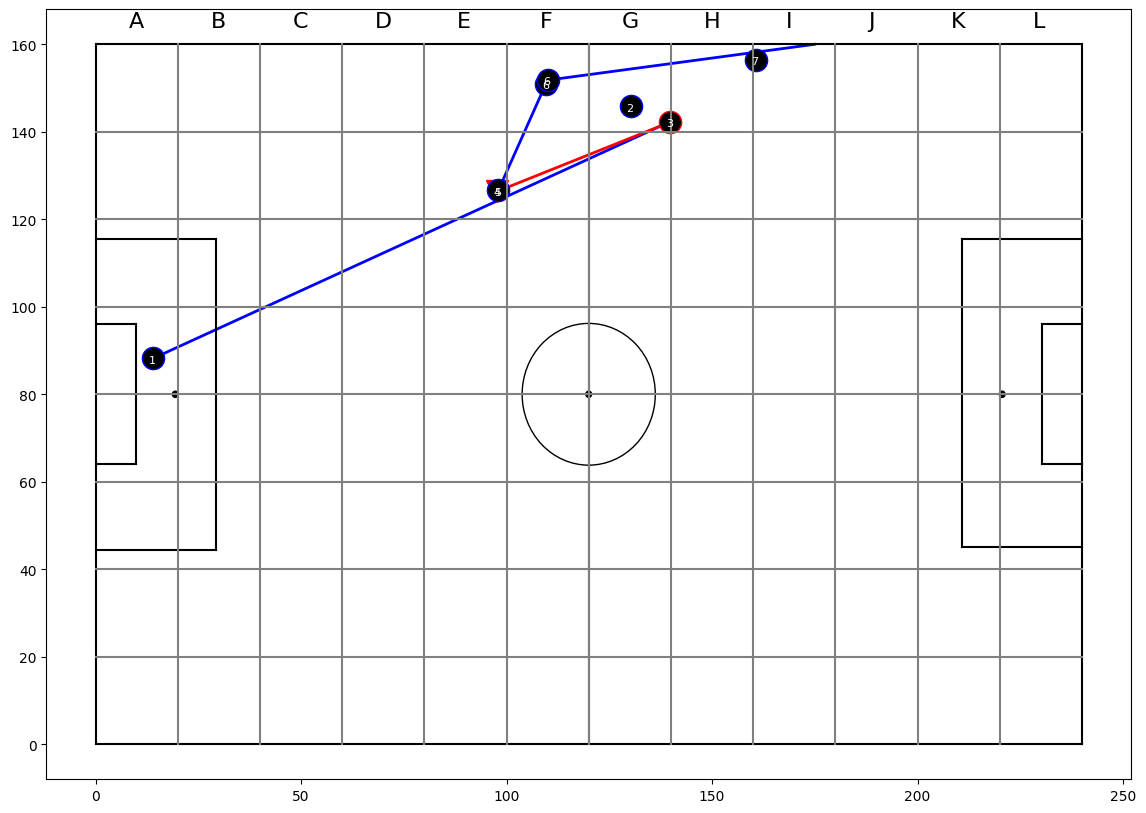

Sequence: 94
Team: Poland
1: Przemysław Frankowski (Pass) <00:08:38.723>
2: Mateusz Andrzej Klich (Ball Receipt*) <00:08:39.311>
2: Mateusz Andrzej Klich (Pass) <00:08:39.311>
3: Przemysław Frankowski (Ball Receipt*) <00:08:40.001>
3: Przemysław Frankowski (Carry) <00:08:40.001>
3: Przemysław Frankowski (Pass) <00:08:40.201>
4: Grzegorz Krychowiak (Ball Receipt*) <00:08:40.932>
4: Grzegorz Krychowiak (Carry) <00:08:40.932>
4: Grzegorz Krychowiak (Pass) <00:08:43.644>
5: Kamil Glik (Ball Receipt*) <00:08:44.596>
5: Kamil Glik (Carry) <00:08:44.596>
5: Kamil Glik (Pass) <00:08:46.782>
6: Wojciech Szczęsny (Ball Receipt*) <00:08:49.137>
6: Wojciech Szczęsny (Carry) <00:08:49.137>
6: Wojciech Szczęsny (Pass) <00:08:50.353>
7: Kamil Jóźwiak (Duel) <00:08:53.268>
8: Ludwig Augustinsson (Pass) <00:08:53.268>


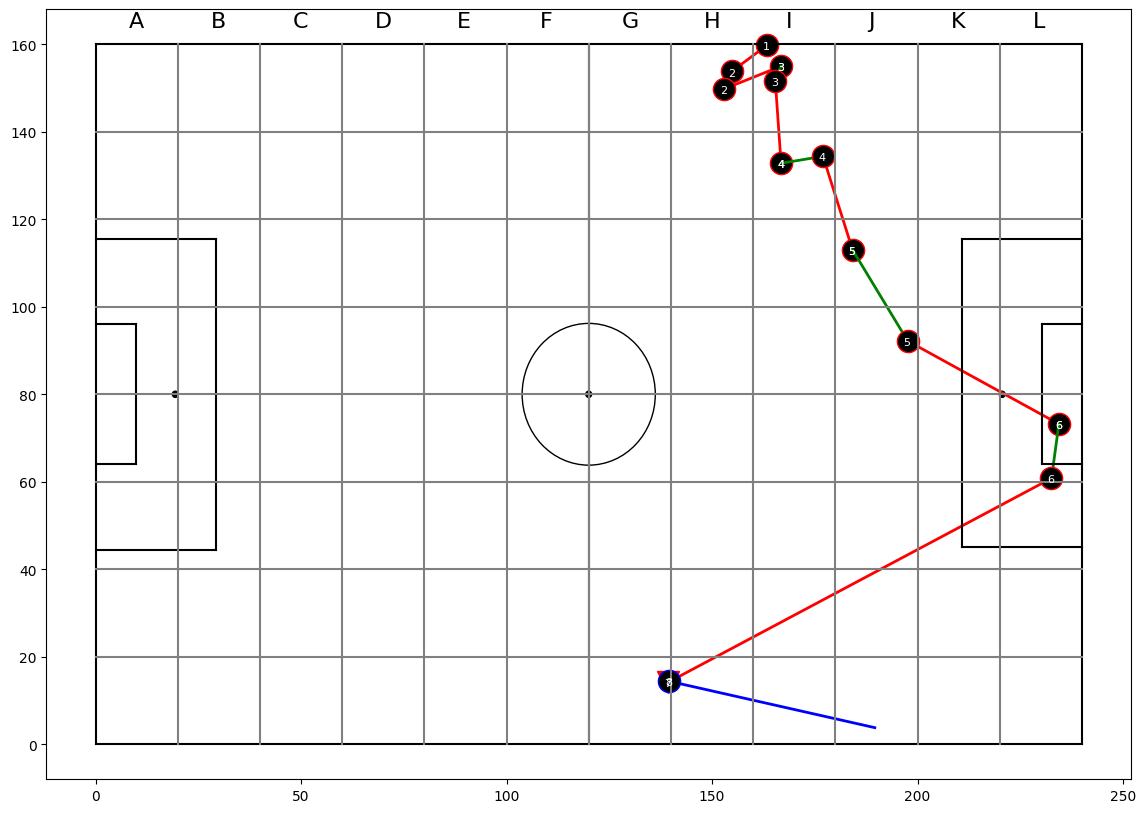

Sequence: 95
Team: Poland
1: Bartosz Bereszyński (Pass) <00:08:58.965>
2: Mateusz Andrzej Klich (Ball Receipt*) <00:08:59.793>
2: Mateusz Andrzej Klich (Carry) <00:08:59.793>
2: Mateusz Andrzej Klich (Pass) <00:09:00.585>
3: Kamil Glik (Ball Receipt*) <00:09:02.616>
3: Kamil Glik (Carry) <00:09:02.616>
3: Kamil Glik (Pass) <00:09:02.682>
4: Grzegorz Krychowiak (Ball Receipt*) <00:09:04.170>
4: Grzegorz Krychowiak (Carry) <00:09:04.170>
4: Grzegorz Krychowiak (Pass) <00:09:06.393>
5: Kamil Jóźwiak (Ball Receipt*) <00:09:08.107>
5: Kamil Jóźwiak (Carry) <00:09:08.107>
5: Kamil Jóźwiak (Pass) <00:09:12.942>
6: Przemysław Frankowski (Ball Receipt*) <00:09:14.654>


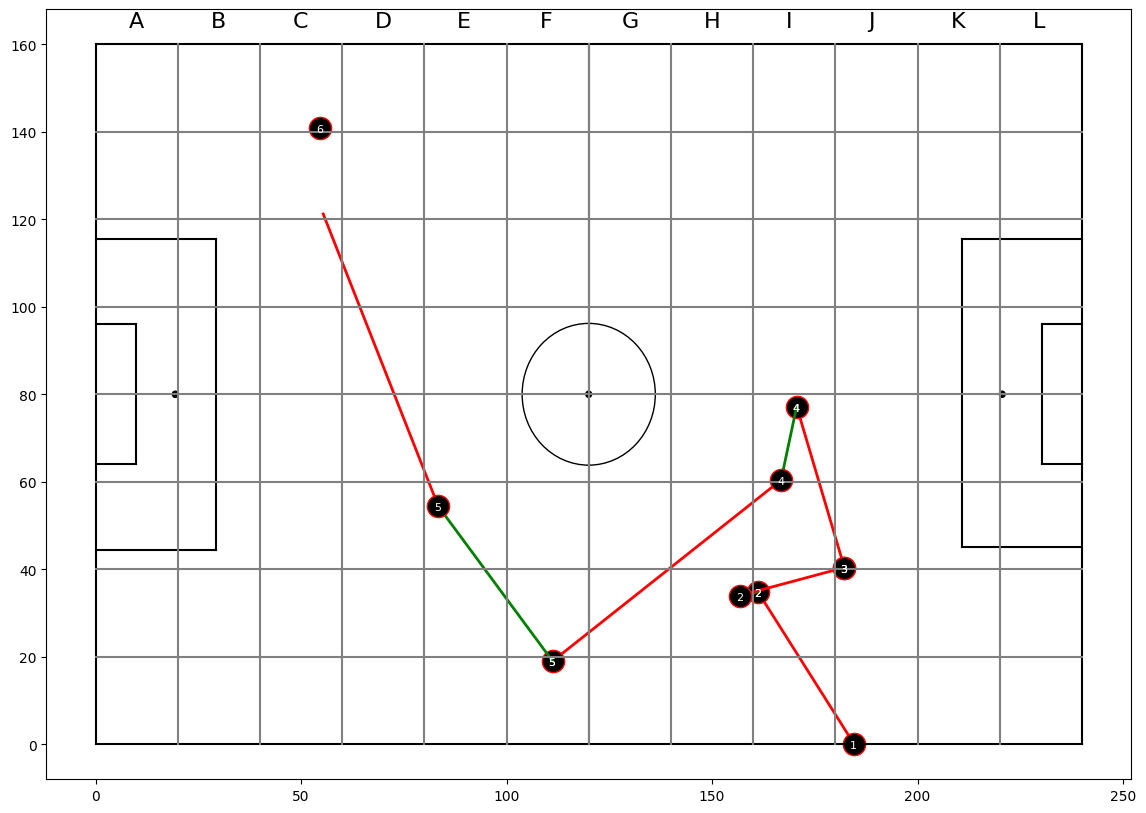

Sequence: 96
Team: Sweden
1: Sebastian Larsson (Pass) <00:09:14.654>
2: Alexander Isak (Ball Receipt*) <00:09:16.867>
2: Alexander Isak (Carry) <00:09:16.867>
2: Alexander Isak (Dribble) <00:09:17.605>
3: Jan Bednarek (Duel) <00:09:17.605>


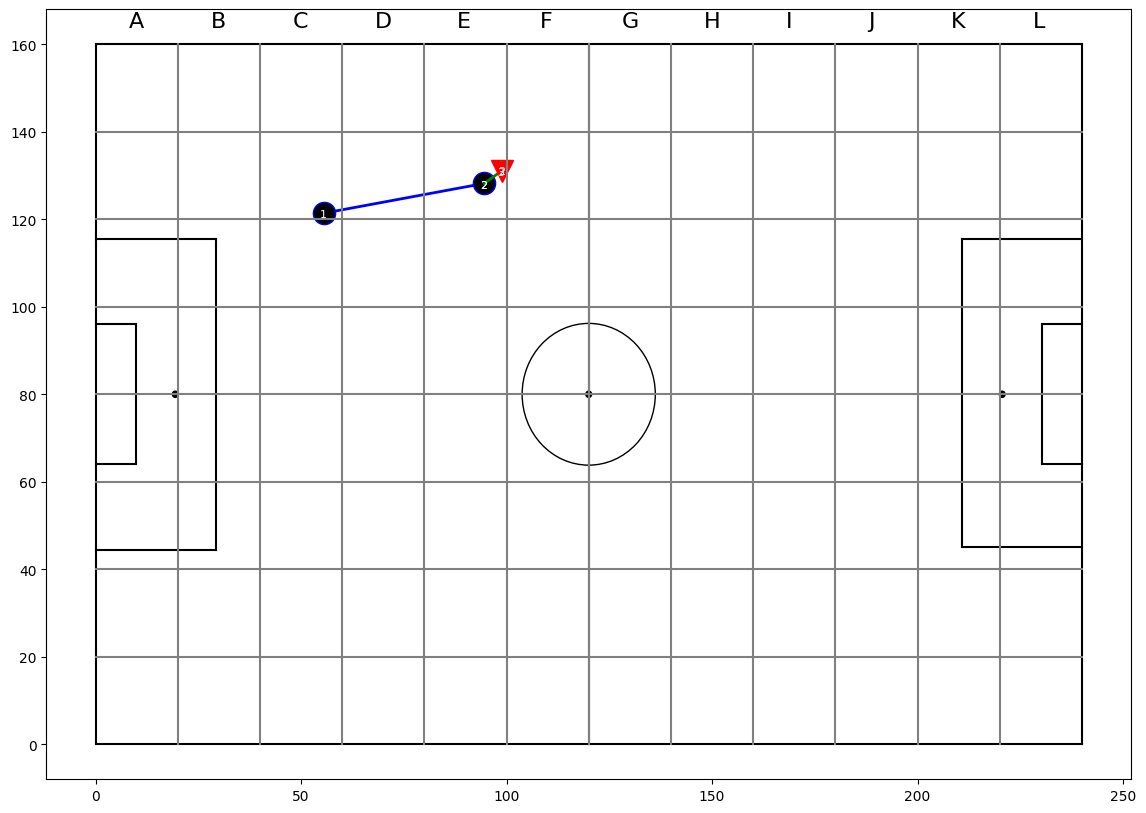

Sequence: 97
Team: Sweden
1: Mikael Lustig (Pass) <00:10:01.117>
2: Victor Nilsson Lindelöf (Ball Receipt*) <00:10:01.916>
2: Victor Nilsson Lindelöf (Pass) <00:10:02.006>
3: Mikael Lustig (Ball Receipt*) <00:10:03.060>
3: Mikael Lustig (Pass) <00:10:04.478>
4: Dejan Kulusevski (Ball Receipt*) <00:10:07.376>
5: Kamil Glik (Pass) <00:10:07.376>
6: Grzegorz Krychowiak (Ball Receipt*) <00:10:08.665>
6: Grzegorz Krychowiak (Carry) <00:10:08.665>
6: Grzegorz Krychowiak (Pass) <00:10:08.696>
7: Victor Nilsson Lindelöf (Pass) <00:10:10.889>
8: Sebastian Larsson (Ball Receipt*) <00:10:12.284>
8: Sebastian Larsson (Pass) <00:10:12.284>
9: Mikael Lustig (Ball Receipt*) <00:10:13.309>
9: Mikael Lustig (Carry) <00:10:13.309>
9: Mikael Lustig (Pass) <00:10:13.315>


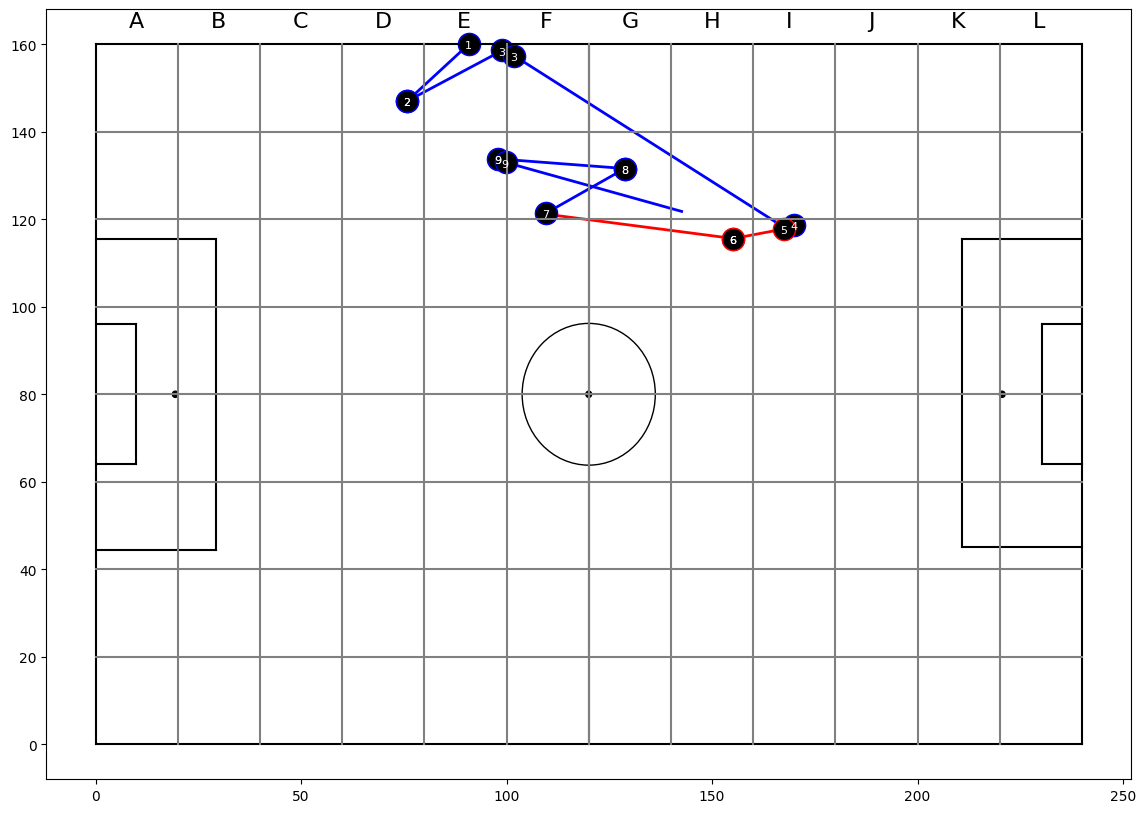

Sequence: 98
Team: Poland
1: Grzegorz Krychowiak (Ball Recovery) <00:10:14.522>
1: Grzegorz Krychowiak (Carry) <00:10:14.522>
1: Grzegorz Krychowiak (Pass) <00:10:15.864>
2: Marcus Andreas Danielsson (Pass) <00:10:20.119>
3: Emil Peter Forsberg (Ball Receipt*) <00:10:21.767>
4: Mateusz Andrzej Klich (Pass) <00:10:21.767>
5: Karol Świderski (Ball Receipt*) <00:10:22.530>
5: Karol Świderski (Carry) <00:10:22.530>
5: Karol Świderski (Miscontrol) <00:10:22.580>


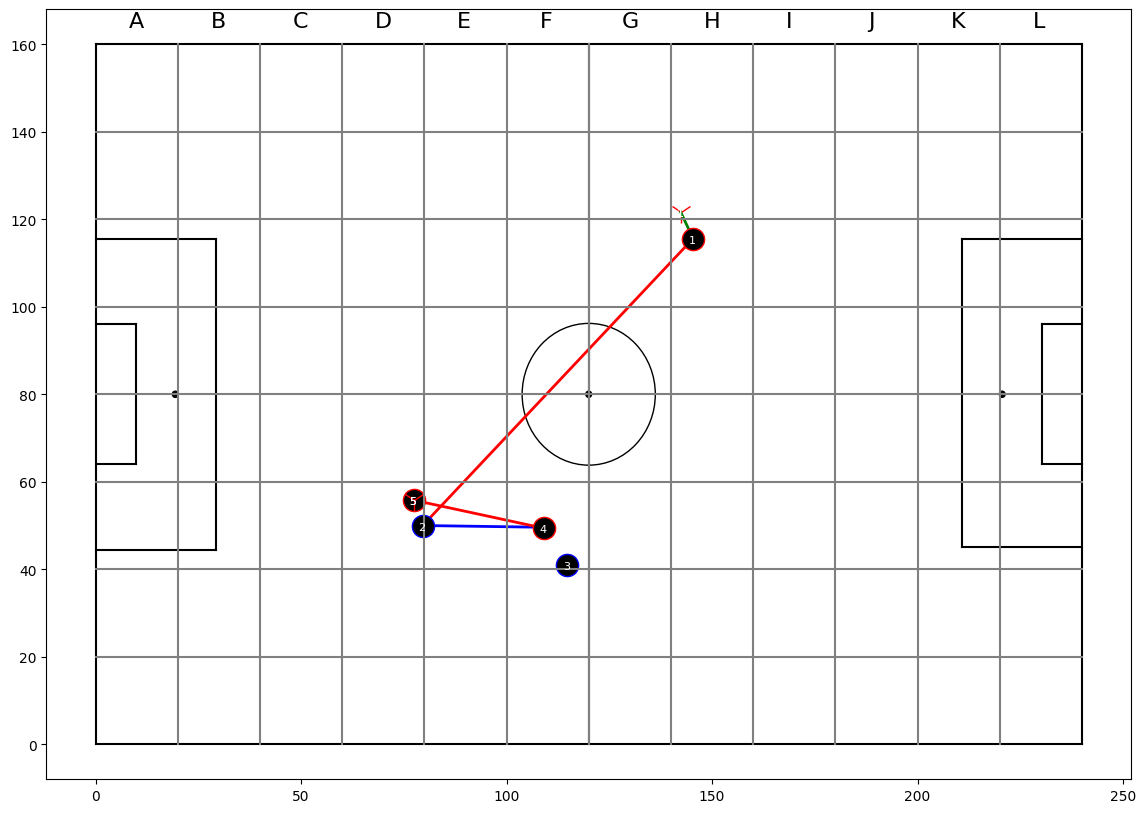

Sequence: 99
Team: Sweden
1: Robin Olsen (Ball Recovery) <00:10:26.507>
1: Robin Olsen (Carry) <00:10:26.507>
1: Robin Olsen (Pass) <00:10:29.115>
2: Marcus Andreas Danielsson (Ball Receipt*) <00:10:30.474>
2: Marcus Andreas Danielsson (Carry) <00:10:30.474>
2: Marcus Andreas Danielsson (Pass) <00:10:34.821>
3: Dejan Kulusevski (Ball Receipt*) <00:10:36.337>
4: Grzegorz Krychowiak (Interception) <00:10:36.337>
5: Kristoffer Olsson (Ball Recovery) <00:10:38.148>
5: Kristoffer Olsson (Carry) <00:10:38.148>
5: Kristoffer Olsson (Shot) <00:10:43.060>
6: Jan Bednarek (Block) <00:10:43.349>
7: Piotr Zieliński (Ball Recovery) <00:10:45.331>
7: Piotr Zieliński (Carry) <00:10:45.331>
7: Piotr Zieliński (Pass) <00:10:46.779>
8: Kamil Jóźwiak (Ball Receipt*) <00:10:49.706>
8: Kamil Jóźwiak (Carry) <00:10:49.706>
8: Kamil Jóźwiak (Dispossessed) <00:10:49.759>
9: Albin Ekdal (Duel) <00:10:49.759>
9: Albin Ekdal (Carry) <00:10:49.759>
9: Albin Ekdal (Pass) <00:10:54.025>
10: Emil Peter Forsberg (Bal

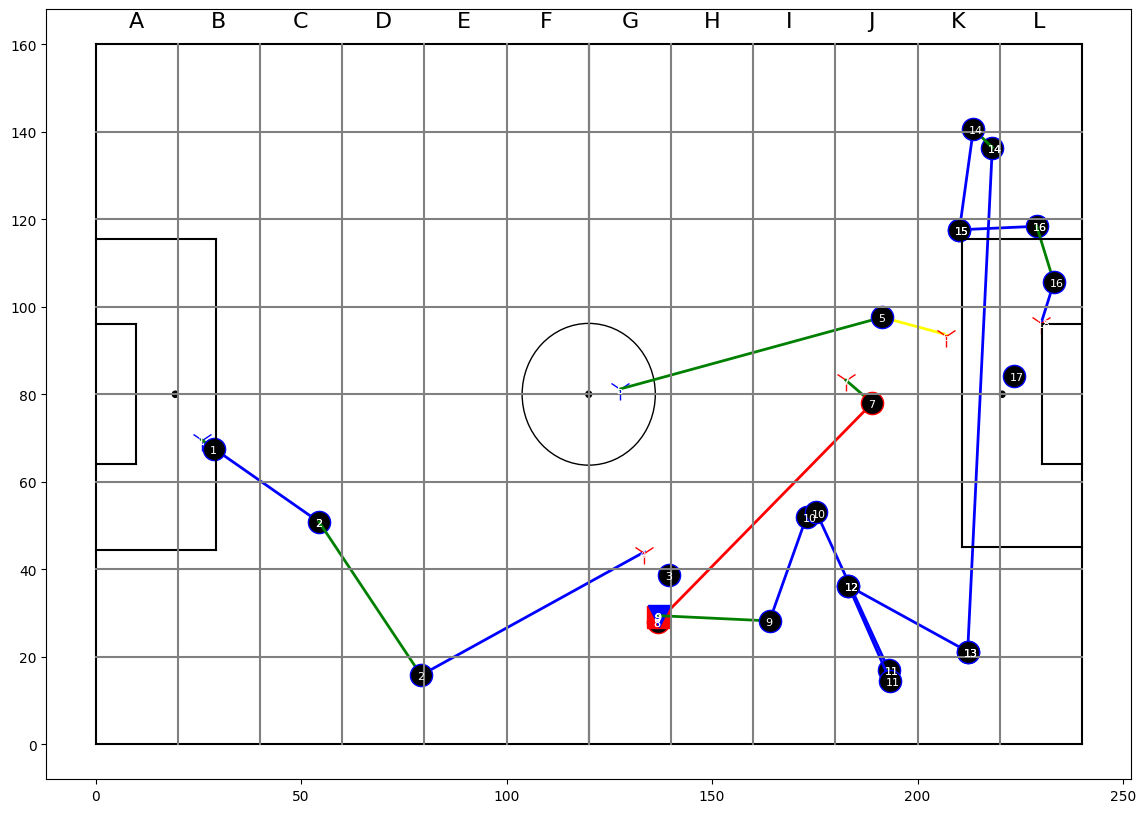

Sequence: 100
Team: Sweden
1: Sebastian Larsson (Pass) <00:11:46.075>
2: Mateusz Andrzej Klich (Clearance) <00:11:47.202>


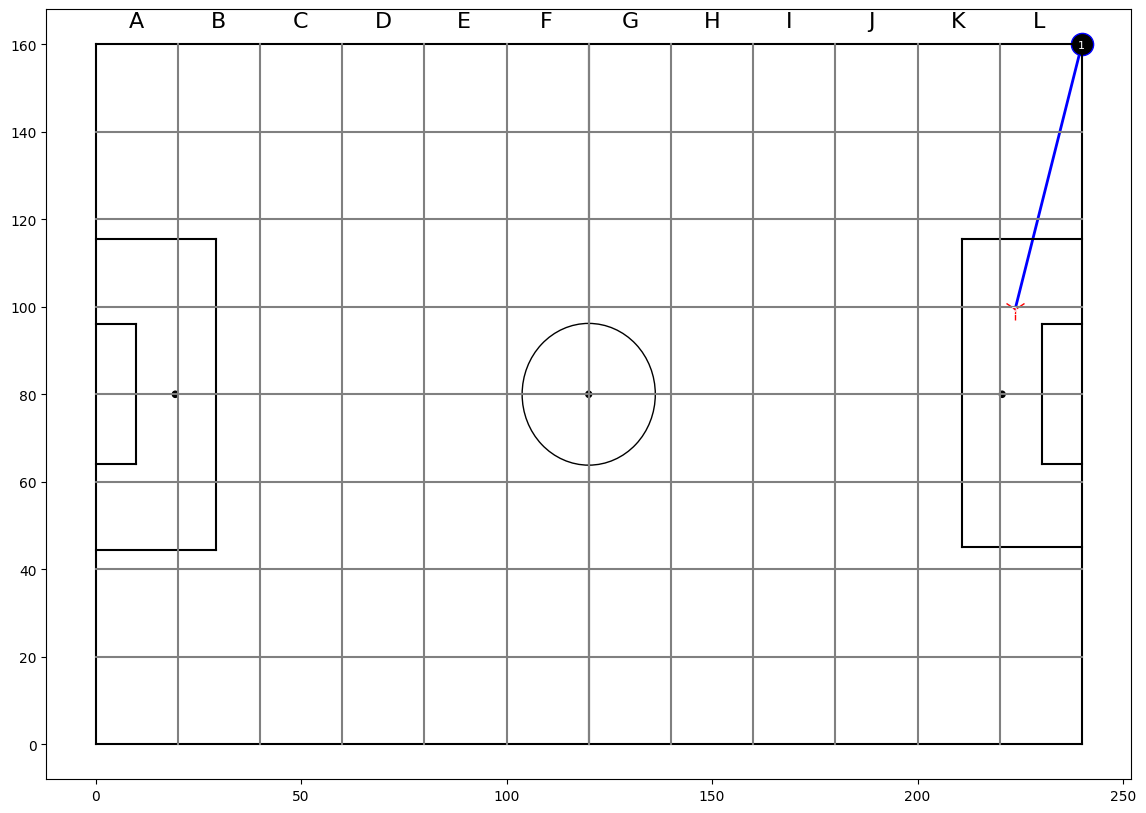

Sequence: 101
Team: Sweden
1: Sebastian Larsson (Pass) <00:12:17.401>
2: Emil Peter Forsberg (Ball Receipt*) <00:12:20.825>
2: Emil Peter Forsberg (Shot) <00:12:20.825>


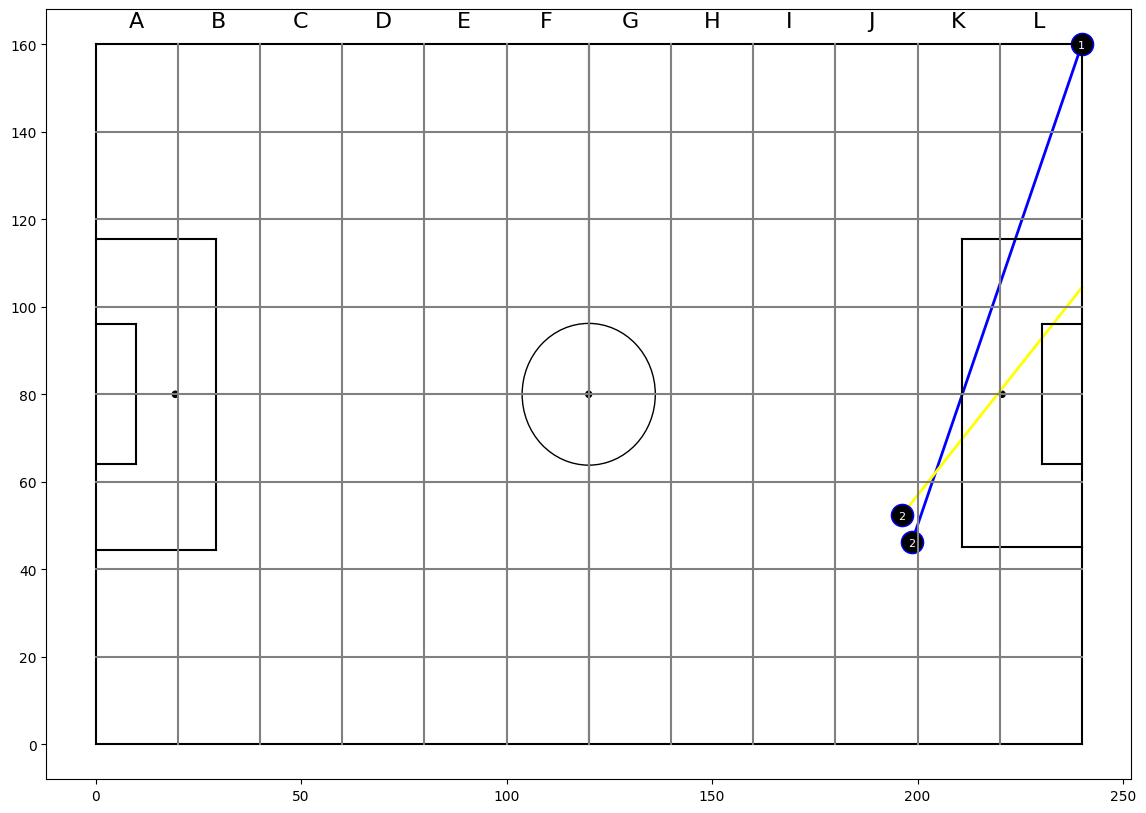

Sequence: 102
Team: Poland
1: Wojciech Szczęsny (Pass) <00:12:42.082>
2: Karol Świderski (Ball Receipt*) <00:12:45.761>
2: Karol Świderski (Pass) <00:12:45.761>
3: Piotr Zieliński (Duel) <00:12:47.706>
4: Marcus Andreas Danielsson (Clearance) <00:12:47.706>
5: Mateusz Andrzej Klich (Pass) <00:12:49.268>
6: Kamil Jóźwiak (Ball Receipt*) <00:12:51.172>
7: Ludwig Augustinsson (Duel) <00:12:51.172>
8: Kamil Jóźwiak (Pass) <00:12:51.172>
9: Piotr Zieliński (Ball Receipt*) <00:12:52.263>
9: Piotr Zieliński (Carry) <00:12:52.263>
9: Piotr Zieliński (Pass) <00:12:57.517>
10: Grzegorz Krychowiak (Ball Receipt*) <00:12:58.684>
10: Grzegorz Krychowiak (Carry) <00:12:58.684>
10: Grzegorz Krychowiak (Shot) <00:13:00.263>
11: Kristoffer Olsson (Block) <00:13:00.304>


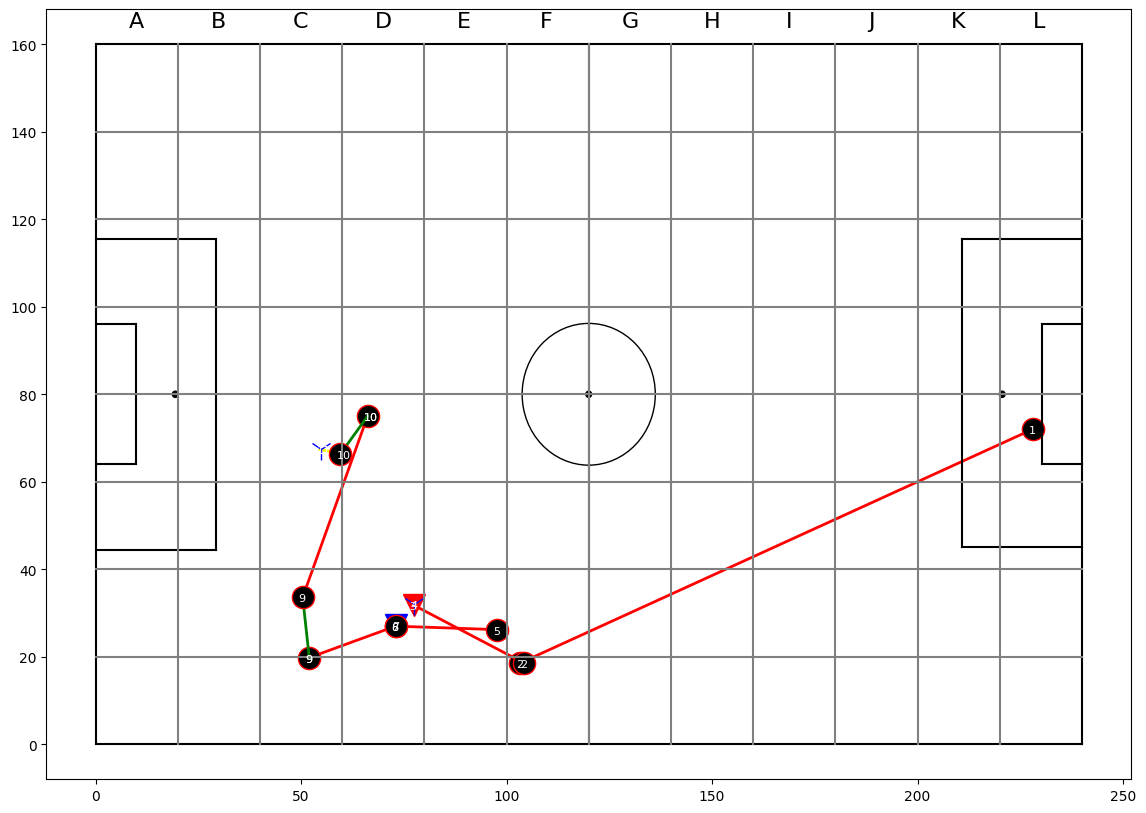

Sequence: 103
Team: Sweden
1: Sebastian Larsson (Pass) <00:13:01.913>
2: Dejan Kulusevski (Ball Receipt*) <00:13:03.771>
2: Dejan Kulusevski (Carry) <00:13:03.771>
3: Przemysław Frankowski (Foul Committed) <00:13:04.574>
4: Dejan Kulusevski (Foul Won) <00:13:04.574>
4: Dejan Kulusevski (Carry) <00:13:04.574>
4: Dejan Kulusevski (Pass) <00:13:14.095>
5: Emil Peter Forsberg (Ball Receipt*) <00:13:14.699>
5: Emil Peter Forsberg (Shot) <00:13:14.699>


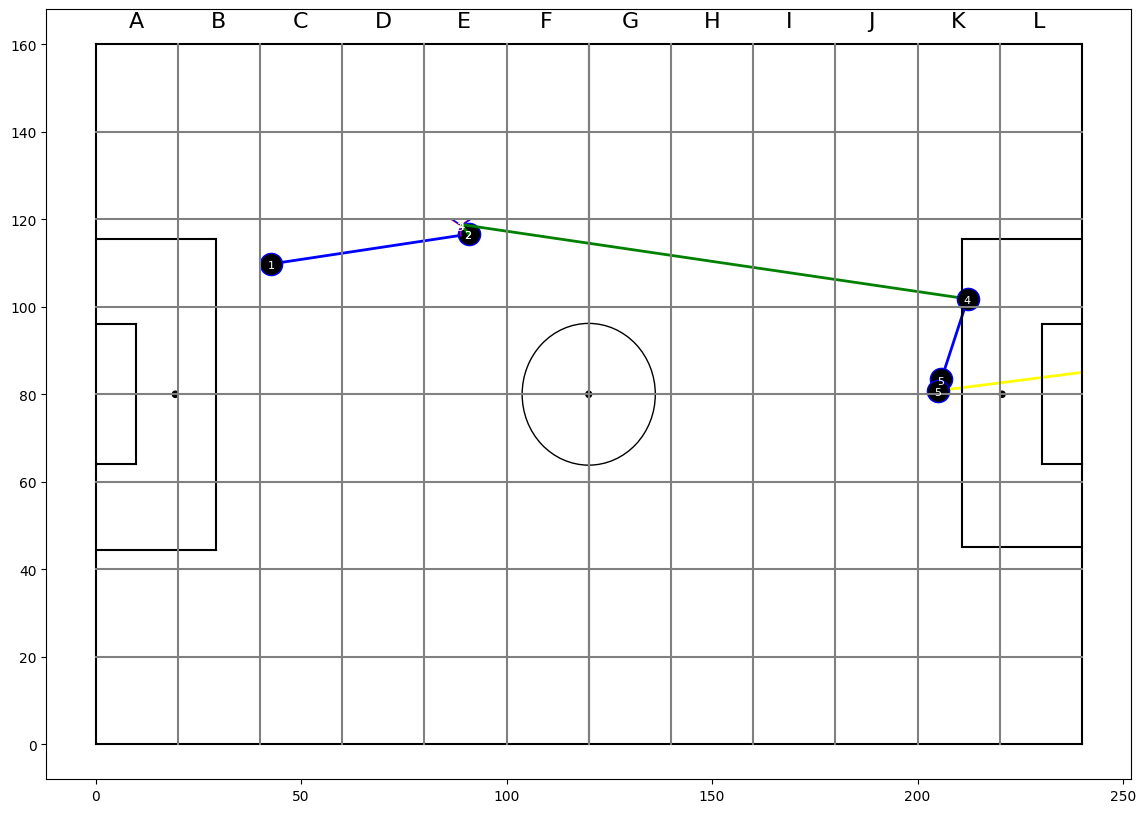

Sequence: 104
Team: Poland
1: Robert Lewandowski (Pass) <00:14:27.949>
2: Mateusz Andrzej Klich (Ball Receipt*) <00:14:28.657>
2: Mateusz Andrzej Klich (Pass) <00:14:28.704>
3: Grzegorz Krychowiak (Ball Receipt*) <00:14:29.569>
3: Grzegorz Krychowiak (Carry) <00:14:29.569>
3: Grzegorz Krychowiak (Pass) <00:14:31.228>
4: Jan Bednarek (Ball Receipt*) <00:14:32.305>
4: Jan Bednarek (Carry) <00:14:32.305>
4: Jan Bednarek (Pass) <00:14:33.116>
5: Bartosz Bereszyński (Ball Receipt*) <00:14:34.375>
5: Bartosz Bereszyński (Carry) <00:14:34.375>
5: Bartosz Bereszyński (Pass) <00:14:36.171>
6: Kamil Jóźwiak (Ball Receipt*) <00:14:37.447>
6: Kamil Jóźwiak (Carry) <00:14:37.447>
6: Kamil Jóźwiak (Pass) <00:14:38.357>
7: Piotr Zieliński (Ball Receipt*) <00:14:39.336>
7: Piotr Zieliński (Carry) <00:14:39.336>
7: Piotr Zieliński (Dribble) <00:14:41.137>
7: Piotr Zieliński (Carry) <00:14:41.137>
7: Piotr Zieliński (Pass) <00:14:45.214>
8: Mateusz Andrzej Klich (Ball Receipt*) <00:14:46.029>
8: Mateusz

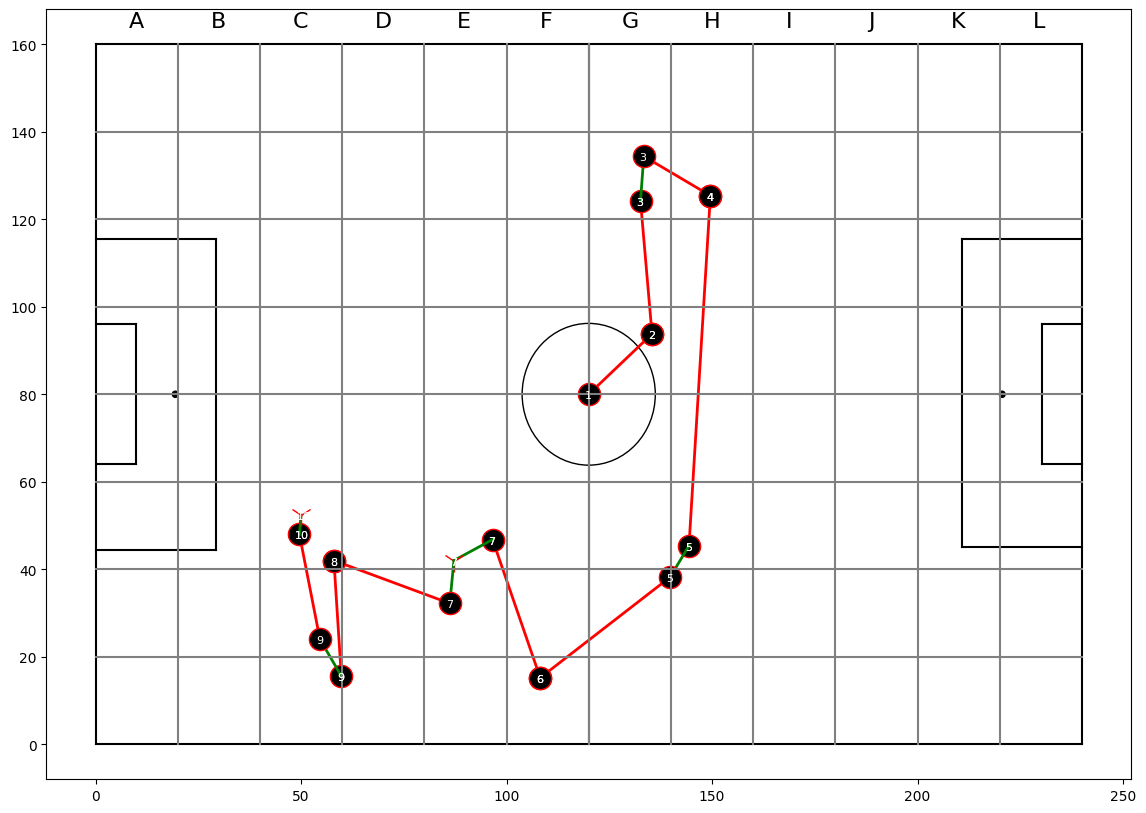

Sequence: 105
Team: Sweden
1: Dejan Kulusevski (Pass) <00:14:51.079>
2: Alexander Isak (Ball Receipt*) <00:14:51.914>
2: Alexander Isak (Pass) <00:14:51.914>
3: Dejan Kulusevski (Ball Receipt*) <00:14:53.132>
3: Dejan Kulusevski (Pass) <00:14:53.132>
4: Alexander Isak (Ball Receipt*) <00:14:54.878>
4: Alexander Isak (Carry) <00:14:54.878>
4: Alexander Isak (Pass) <00:15:03.932>
5: Emil Peter Forsberg (Ball Receipt*) <00:15:05.484>
5: Emil Peter Forsberg (Carry) <00:15:05.484>
5: Emil Peter Forsberg (Pass) <00:15:06.161>
6: Ludwig Augustinsson (Ball Receipt*) <00:15:07.660>
6: Ludwig Augustinsson (Carry) <00:15:07.660>
6: Ludwig Augustinsson (Dribble) <00:15:09.908>


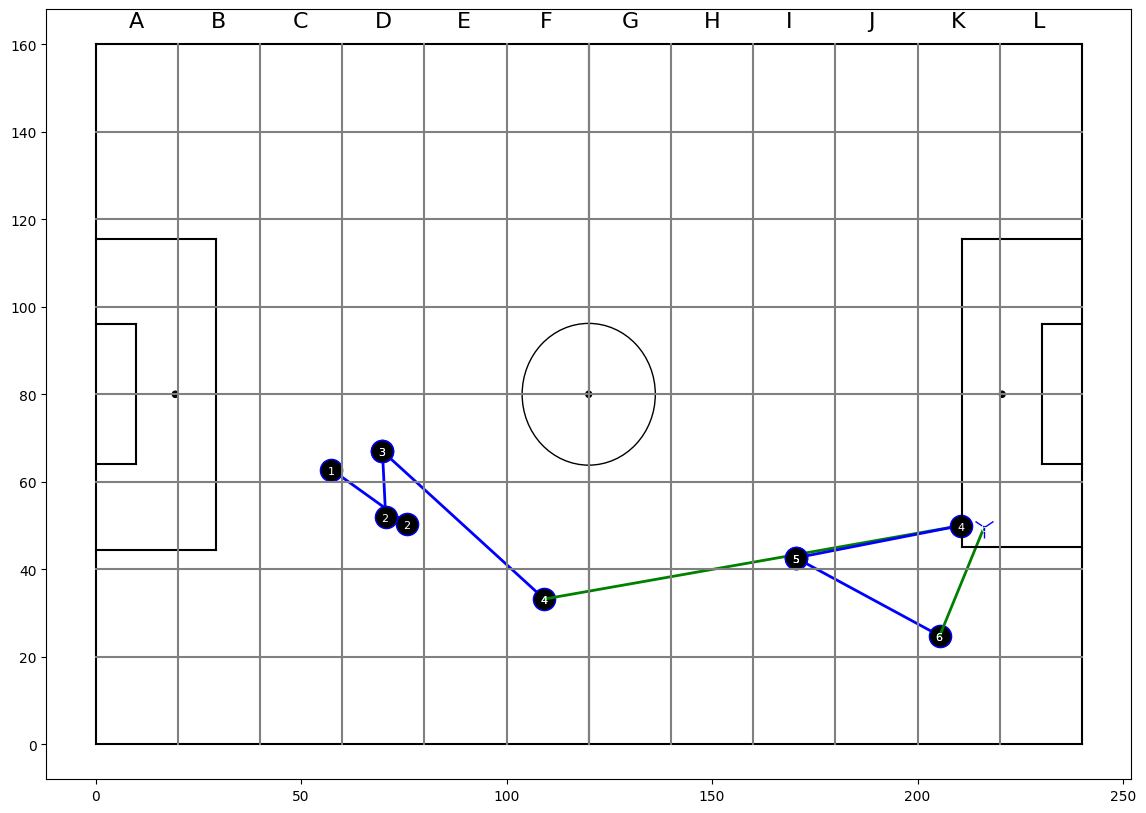

Sequence: 106
Team: Poland
1: Kamil Jóźwiak (Duel) <00:15:09.908>
2: Piotr Zieliński (Ball Recovery) <00:15:11.780>
2: Piotr Zieliński (Carry) <00:15:11.780>
2: Piotr Zieliński (Pass) <00:15:13.019>
3: Robert Lewandowski (Ball Receipt*) <00:15:17.271>
3: Robert Lewandowski (Carry) <00:15:17.271>
3: Robert Lewandowski (Shot) <00:15:19.870>


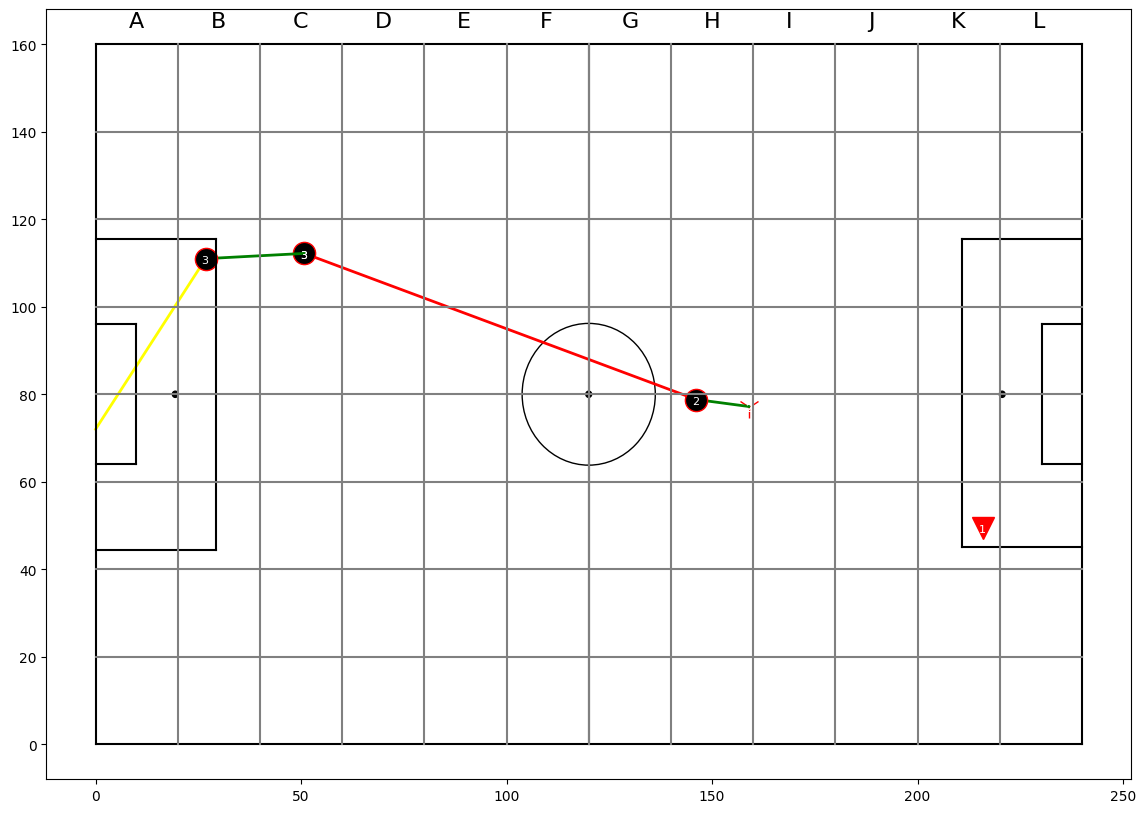

Sequence: 107
Team: Sweden
1: Alexander Isak (Pass) <00:16:03.661>
2: Kristoffer Olsson (Ball Receipt*) <00:16:06.621>
2: Kristoffer Olsson (Carry) <00:16:06.621>
2: Kristoffer Olsson (Pass) <00:16:09.471>
3: Alexander Isak (Ball Receipt*) <00:16:10.282>
3: Alexander Isak (Carry) <00:16:10.282>
3: Alexander Isak (Pass) <00:16:11.445>
4: Dejan Kulusevski (Ball Receipt*) <00:16:12.306>
4: Dejan Kulusevski (Carry) <00:16:12.306>
4: Dejan Kulusevski (Dispossessed) <00:16:14.413>


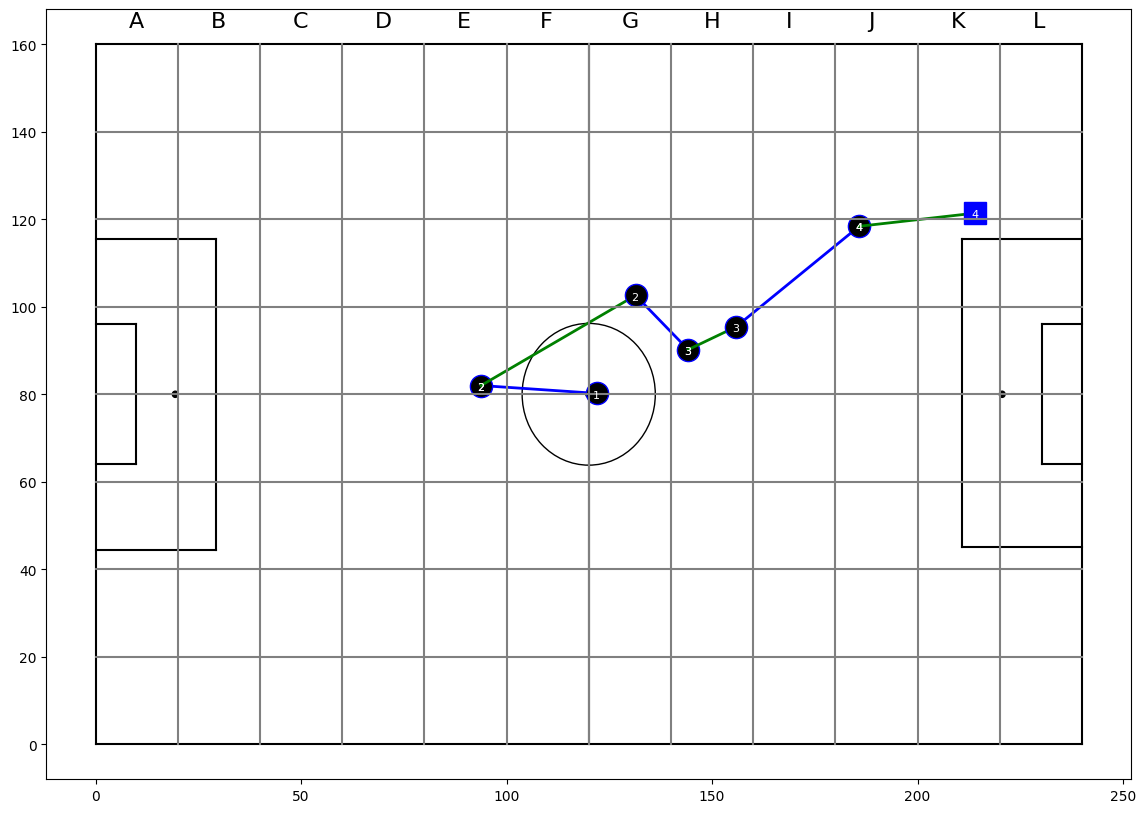

Sequence: 108
Team: Poland
1: Jan Bednarek (Duel) <00:16:14.413>
2: Przemysław Frankowski (Ball Recovery) <00:16:15.671>
2: Przemysław Frankowski (Carry) <00:16:15.671>
2: Przemysław Frankowski (Pass) <00:16:16.477>
3: Jan Bednarek (Ball Receipt*) <00:16:17.273>
3: Jan Bednarek (Carry) <00:16:17.273>
3: Jan Bednarek (Pass) <00:16:18.047>
4: Grzegorz Krychowiak (Ball Receipt*) <00:16:18.912>
4: Grzegorz Krychowiak (Carry) <00:16:18.912>
4: Grzegorz Krychowiak (Pass) <00:16:19.425>
5: Przemysław Frankowski (Ball Receipt*) <00:16:20.951>
5: Przemysław Frankowski (Carry) <00:16:20.951>
5: Przemysław Frankowski (Pass) <00:16:26.572>
6: Piotr Zieliński (Ball Receipt*) <00:16:27.457>
6: Piotr Zieliński (Carry) <00:16:27.457>
6: Piotr Zieliński (Pass) <00:16:32.448>
7: Karol Świderski (Ball Receipt*) <00:16:34.715>
7: Karol Świderski (Carry) <00:16:34.715>
7: Karol Świderski (Pass) <00:16:37.367>
8: Marcus Andreas Danielsson (Clearance) <00:16:38.063>
9: Piotr Zieliński (Ball Recovery) <00:16:

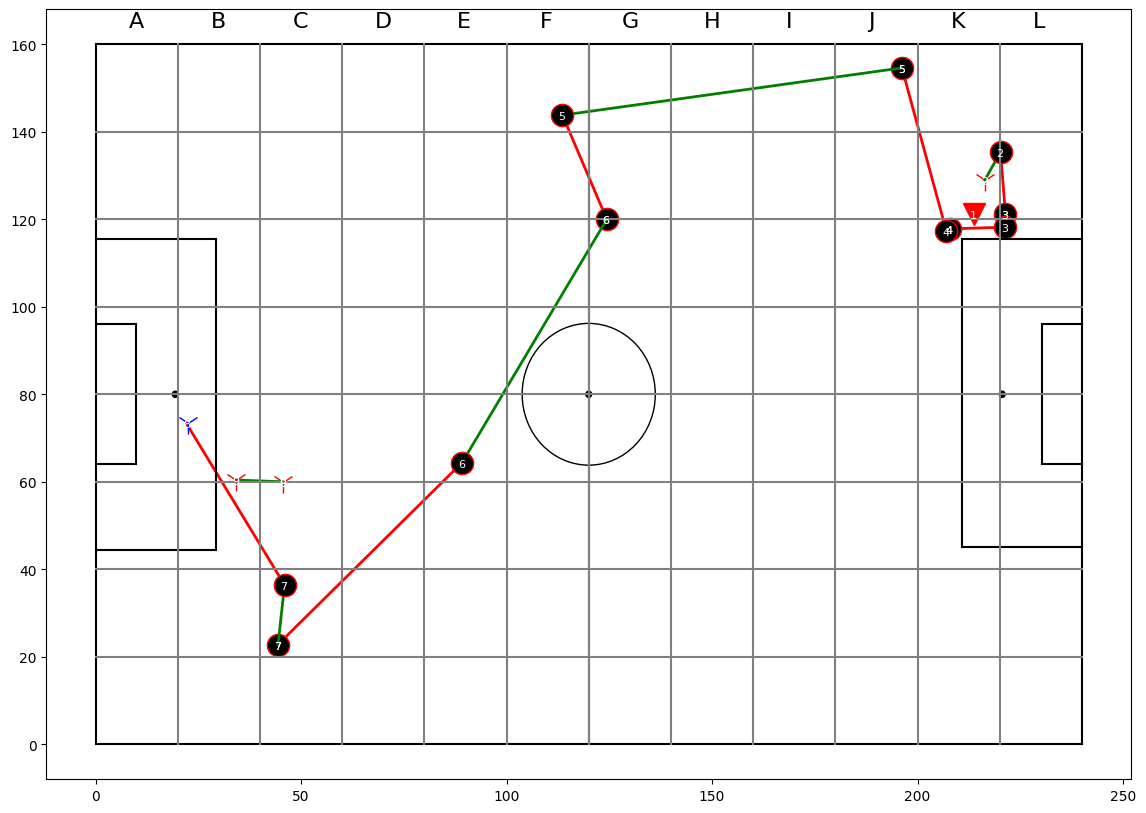

Sequence: 109
Team: Sweden
1: Albin Ekdal (Duel) <00:16:40.529>
1: Albin Ekdal (Carry) <00:16:40.529>
1: Albin Ekdal (Pass) <00:16:41.577>
2: Kristoffer Olsson (Ball Receipt*) <00:16:42.523>
2: Kristoffer Olsson (Pass) <00:16:42.523>
3: Dejan Kulusevski (Ball Receipt*) <00:16:45.043>
4: Kamil Glik (Duel) <00:16:45.043>
5: Dejan Kulusevski (Pass) <00:16:45.043>
6: Emil Peter Forsberg (Ball Receipt*) <00:16:46.155>
6: Emil Peter Forsberg (Carry) <00:16:46.155>
6: Emil Peter Forsberg (Pass) <00:16:46.734>
7: Dejan Kulusevski (Ball Receipt*) <00:16:51.241>


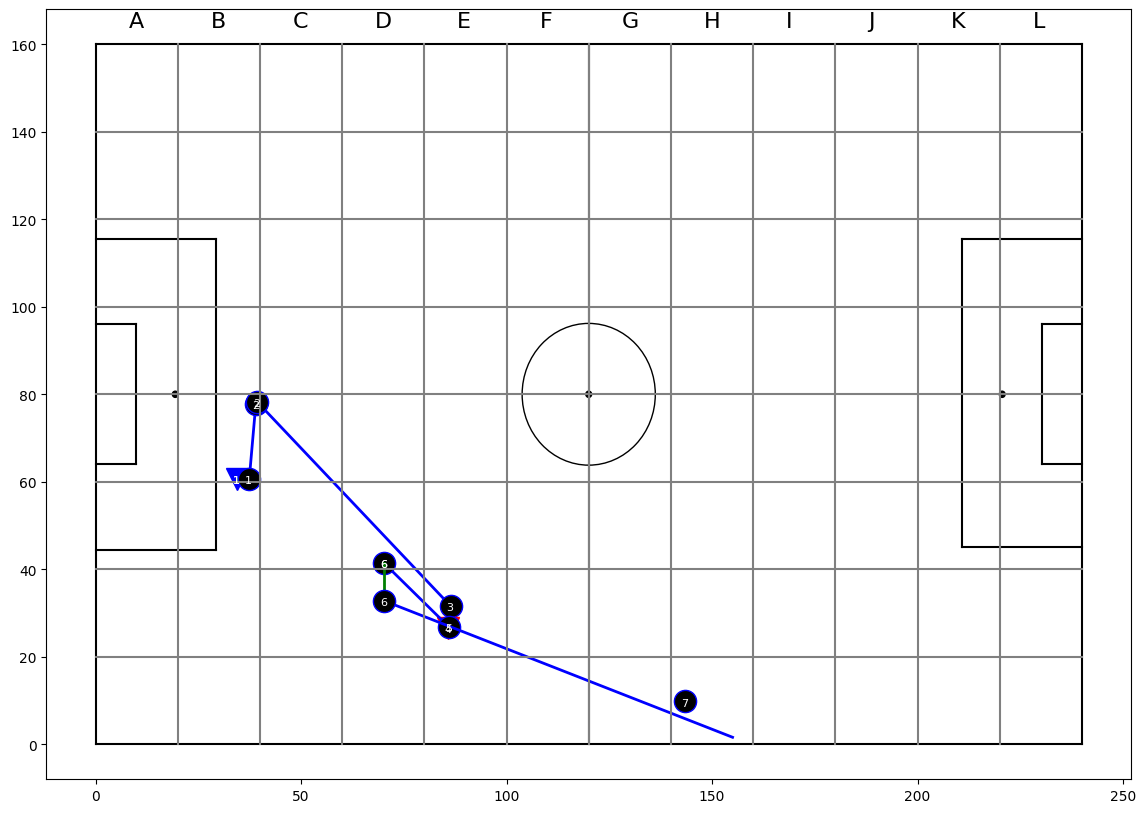

Sequence: 110
Team: Poland
1: Kamil Glik (Pass) <00:16:55.574>
2: Jan Bednarek (Ball Receipt*) <00:16:58.019>
2: Jan Bednarek (Carry) <00:16:58.019>
2: Jan Bednarek (Pass) <00:16:59.104>
3: Grzegorz Krychowiak (Ball Receipt*) <00:17:00.395>
3: Grzegorz Krychowiak (Carry) <00:17:00.395>
3: Grzegorz Krychowiak (Pass) <00:17:01.860>
4: Robert Lewandowski (Ball Receipt*) <00:17:04.898>
4: Robert Lewandowski (Duel) <00:17:04.898>
5: Mikael Lustig (Clearance) <00:17:04.898>
6: Przemysław Frankowski (Ball Recovery) <00:17:08.460>
6: Przemysław Frankowski (Carry) <00:17:08.460>
6: Przemysław Frankowski (Pass) <00:17:10.843>
7: Robert Lewandowski (Ball Receipt*) <00:17:12.285>
8: Marcus Andreas Danielsson (Duel) <00:17:12.285>
9: Robert Lewandowski (Miscontrol) <00:17:12.285>


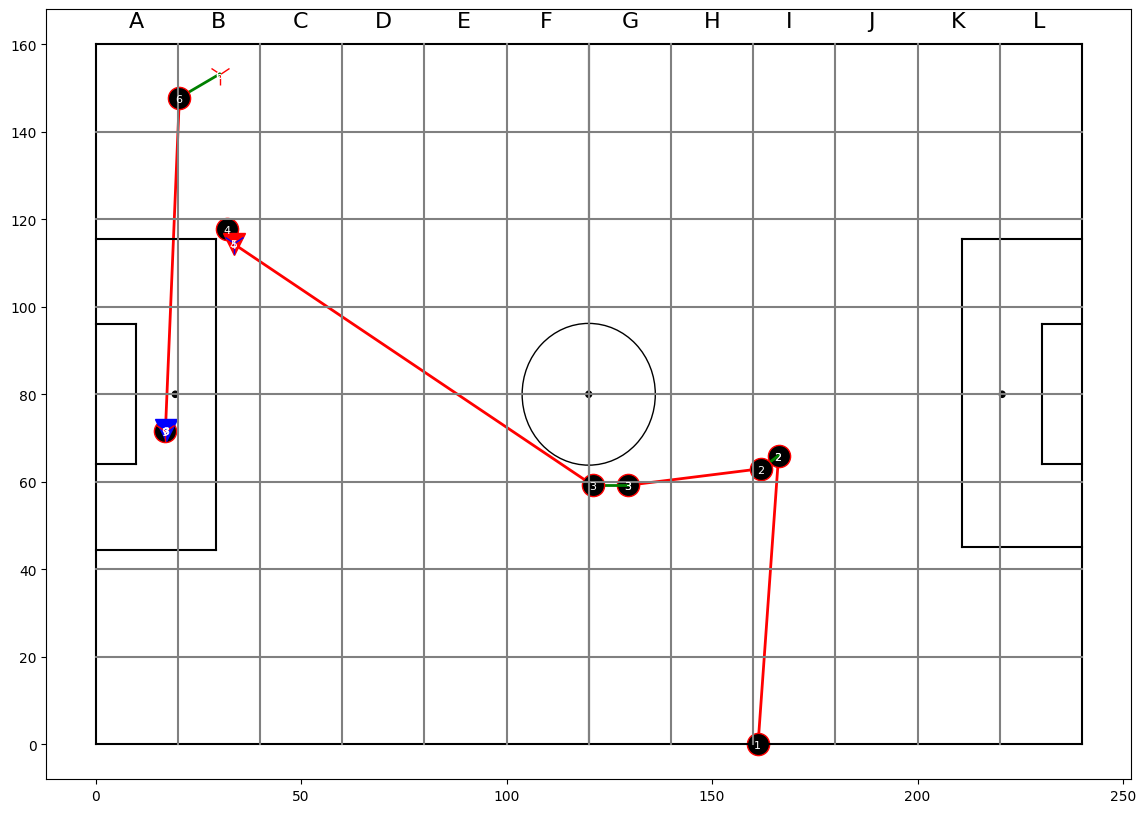

Sequence: 111
Team: Sweden
1: Robin Olsen (Pass) <00:17:44.687>
2: Alexander Isak (Foul Committed) <00:17:48.441>
3: Grzegorz Krychowiak (Foul Won) <00:17:48.441>


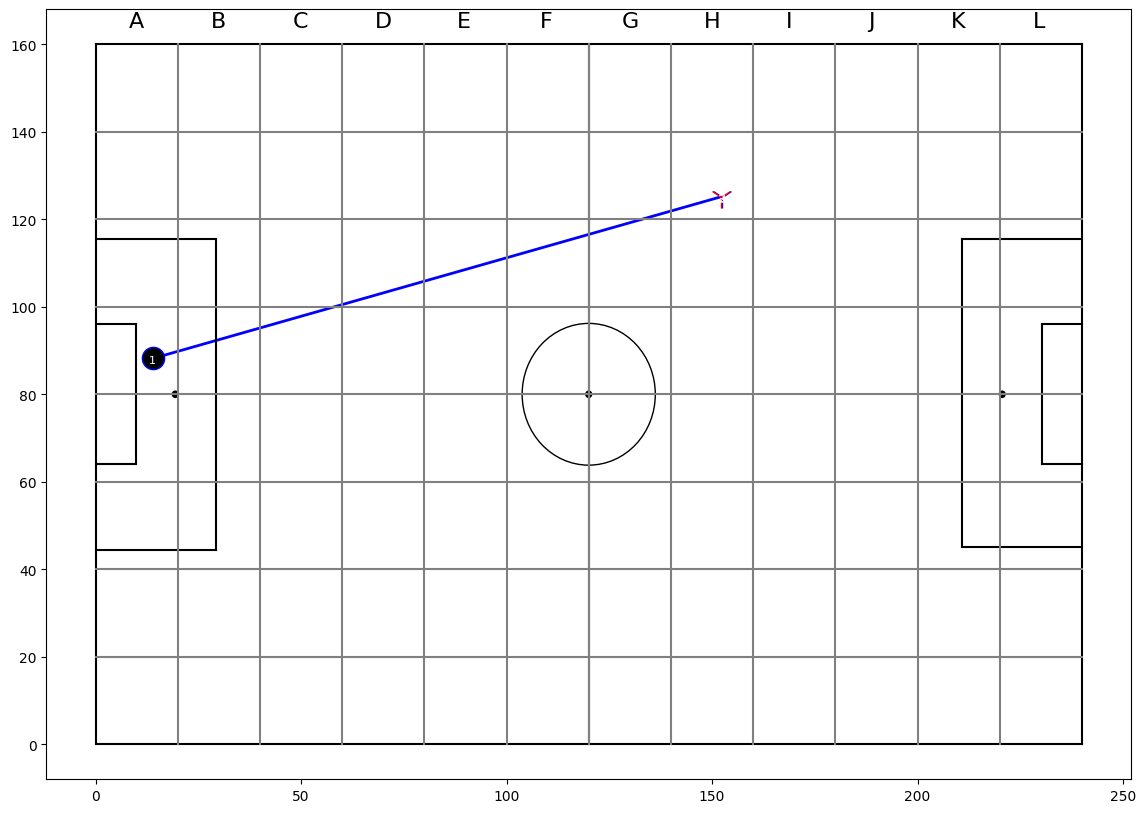

Sequence: 112
Team: Poland
1: Mateusz Andrzej Klich (Pass) <00:17:54.177>
2: Przemysław Frankowski (Ball Receipt*) <00:17:56.574>
2: Przemysław Frankowski (Carry) <00:17:56.574>
2: Przemysław Frankowski (Pass) <00:17:57.972>
3: Grzegorz Krychowiak (Ball Receipt*) <00:17:58.917>
3: Grzegorz Krychowiak (Carry) <00:17:58.917>
3: Grzegorz Krychowiak (Pass) <00:18:00.397>
4: Bartosz Bereszyński (Ball Receipt*) <00:18:02.213>
4: Bartosz Bereszyński (Carry) <00:18:02.213>
4: Bartosz Bereszyński (Pass) <00:18:05.020>
5: Karol Świderski (Ball Receipt*) <00:18:06.741>
5: Karol Świderski (Carry) <00:18:06.741>
5: Karol Świderski (Pass) <00:18:09.893>
6: Kamil Glik (Ball Receipt*) <00:18:11.475>
6: Kamil Glik (Carry) <00:18:11.475>
6: Kamil Glik (Pass) <00:18:12.532>
7: Jan Bednarek (Ball Receipt*) <00:18:13.678>
7: Jan Bednarek (Carry) <00:18:13.678>
7: Jan Bednarek (Pass) <00:18:16.072>
8: Bartosz Bereszyński (Ball Receipt*) <00:18:17.384>
8: Bartosz Bereszyński (Carry) <00:18:17.384>
8: Bartosz

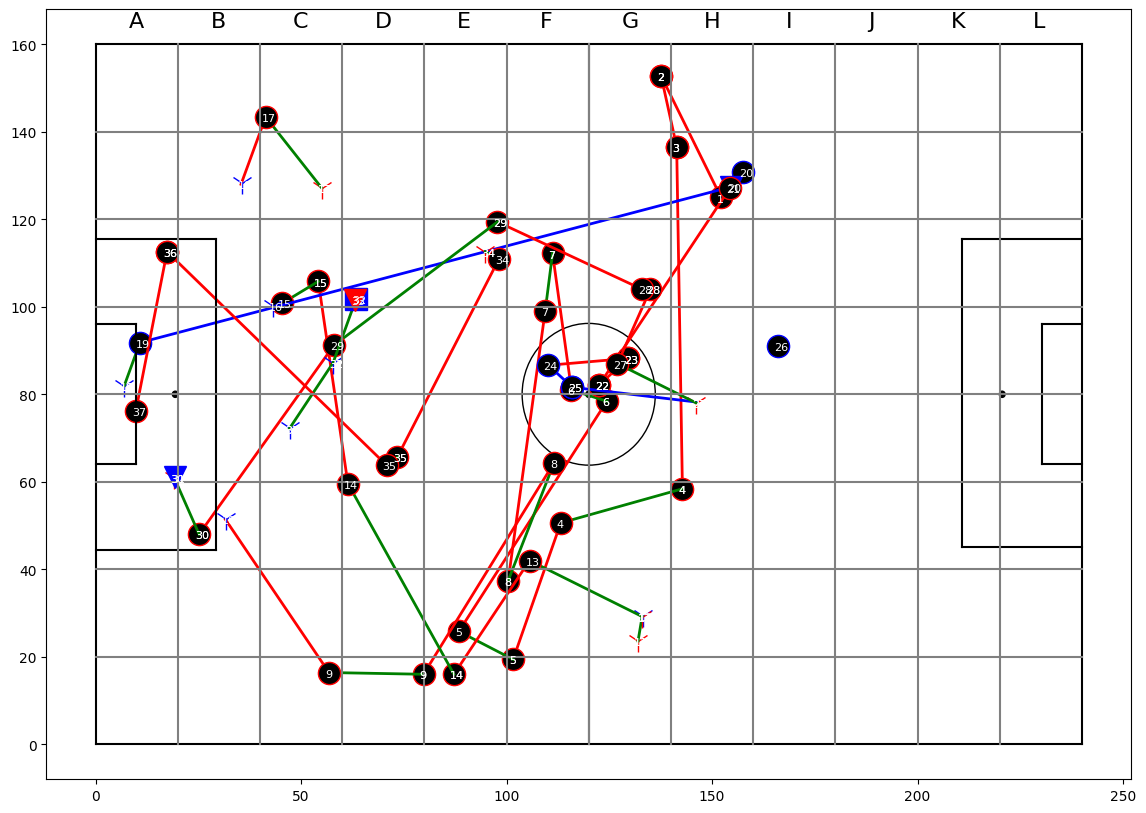

Sequence: 113
Team: Sweden
1: Robin Olsen (Pass) <00:21:22.578>
2: Emil Peter Forsberg (Ball Receipt*) <00:21:25.768>
3: Bartosz Bereszyński (Pass) <00:21:25.768>
4: Ludwig Augustinsson (Pass) <00:21:28.117>
5: Emil Peter Forsberg (Ball Receipt*) <00:21:30.585>
5: Emil Peter Forsberg (Miscontrol) <00:21:30.585>


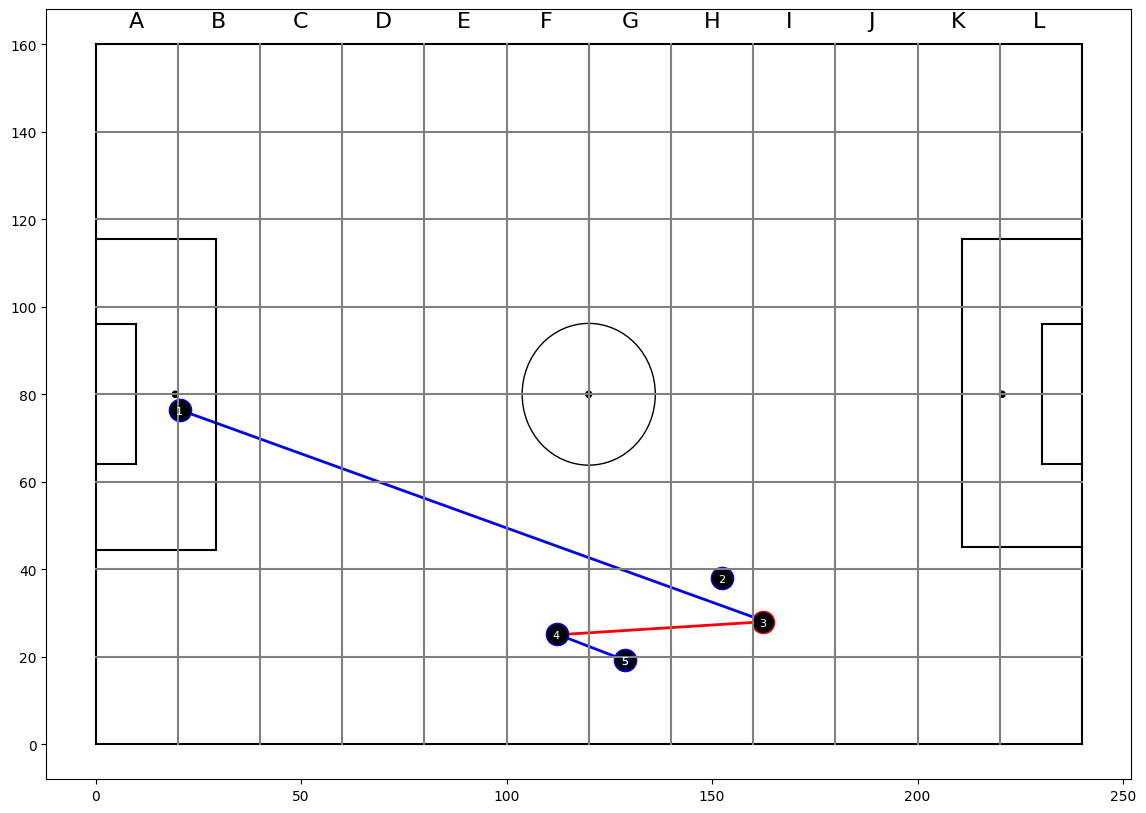

Sequence: 114
Team: Poland
1: Piotr Zieliński (Ball Recovery) <00:21:32.143>
1: Piotr Zieliński (Carry) <00:21:32.143>
1: Piotr Zieliński (Pass) <00:21:38.036>
2: Mateusz Andrzej Klich (Ball Receipt*) <00:21:39.229>
2: Mateusz Andrzej Klich (Carry) <00:21:39.229>
2: Mateusz Andrzej Klich (Pass) <00:21:41.473>
3: Karol Świderski (Ball Receipt*) <00:21:42.587>
3: Karol Świderski (Carry) <00:21:42.587>
3: Karol Świderski (Pass) <00:21:44.720>
4: Mateusz Andrzej Klich (Ball Receipt*) <00:21:45.868>
4: Mateusz Andrzej Klich (Carry) <00:21:45.868>
4: Mateusz Andrzej Klich (Pass) <00:21:46.618>
5: Bartosz Bereszyński (Ball Receipt*) <00:21:47.142>
5: Bartosz Bereszyński (Carry) <00:21:47.142>
5: Bartosz Bereszyński (Pass) <00:21:50.096>
6: Mateusz Andrzej Klich (Ball Receipt*) <00:21:51.374>
6: Mateusz Andrzej Klich (Carry) <00:21:51.374>
6: Mateusz Andrzej Klich (Pass) <00:21:53.404>
7: Marcus Andreas Danielsson (Clearance) <00:21:55.292>
8: Sebastian Larsson (Pass) <00:21:57.172>
9: Alexand

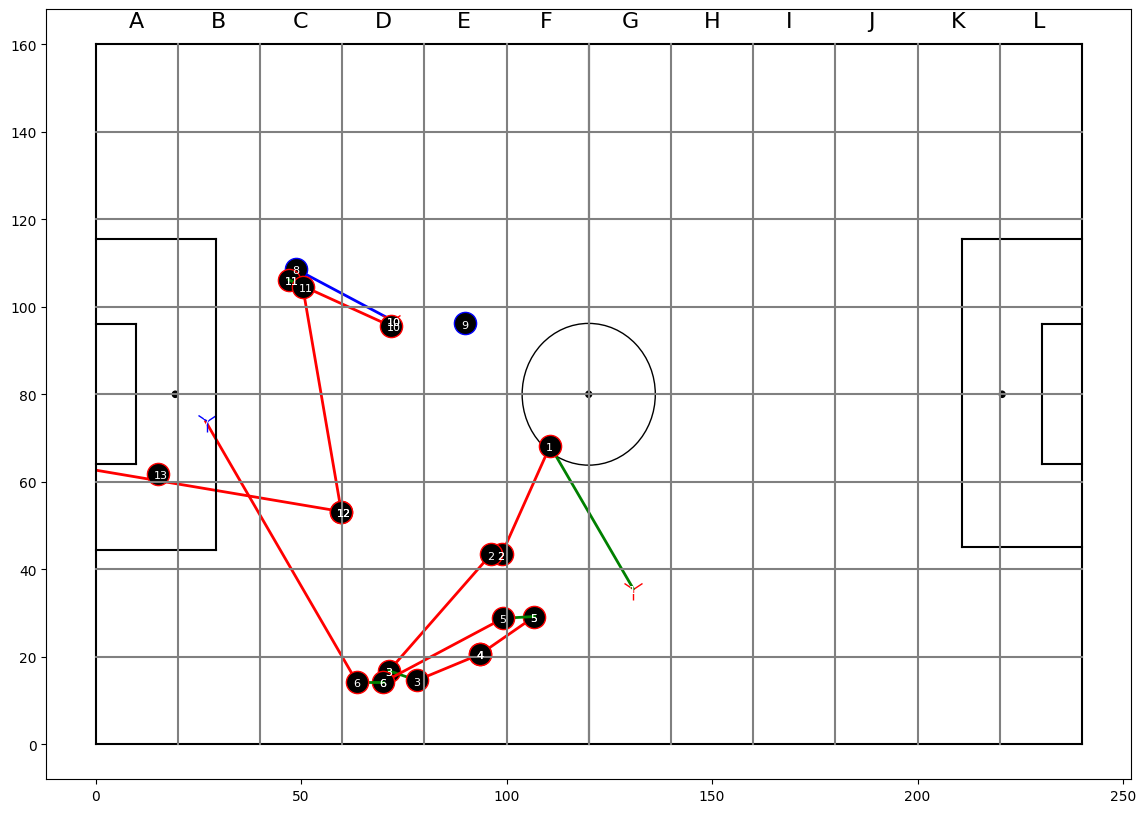

Sequence: 115
Team: Sweden
1: Robin Olsen (Pass) <00:23:05.084>
2: Marcus Berg (Ball Receipt*) <00:23:08.877>
2: Marcus Berg (Duel) <00:23:08.877>
3: Kamil Glik (Pass) <00:23:08.877>
4: Emil Peter Forsberg (Ball Recovery) <00:23:10.295>
4: Emil Peter Forsberg (Carry) <00:23:10.295>
4: Emil Peter Forsberg (Pass) <00:23:12.421>
5: Marcus Berg (Ball Receipt*) <00:23:12.574>
6: Bartosz Bereszyński (Block) <00:23:12.574>
7: Kamil Glik (Pass) <00:23:14.149>
8: Jakub Świerczok (Foul Committed) <00:23:17.043>
9: Emil Krafth (Foul Won) <00:23:17.043>
10: Victor Nilsson Lindelöf (Pass) <00:23:28.487>
11: Emil Krafth (Ball Receipt*) <00:23:30.376>
11: Emil Krafth (Pass) <00:23:33.684>
12: Sebastian Larsson (Ball Receipt*) <00:23:34.960>
12: Sebastian Larsson (Pass) <00:23:34.960>
13: Kristoffer Olsson (Ball Receipt*) <00:23:36.045>
13: Kristoffer Olsson (Carry) <00:23:36.045>
14: Piotr Zieliński (Foul Committed) <00:23:40.163>
15: Kristoffer Olsson (Foul Won) <00:23:40.163>
16: Sebastian Larsson 

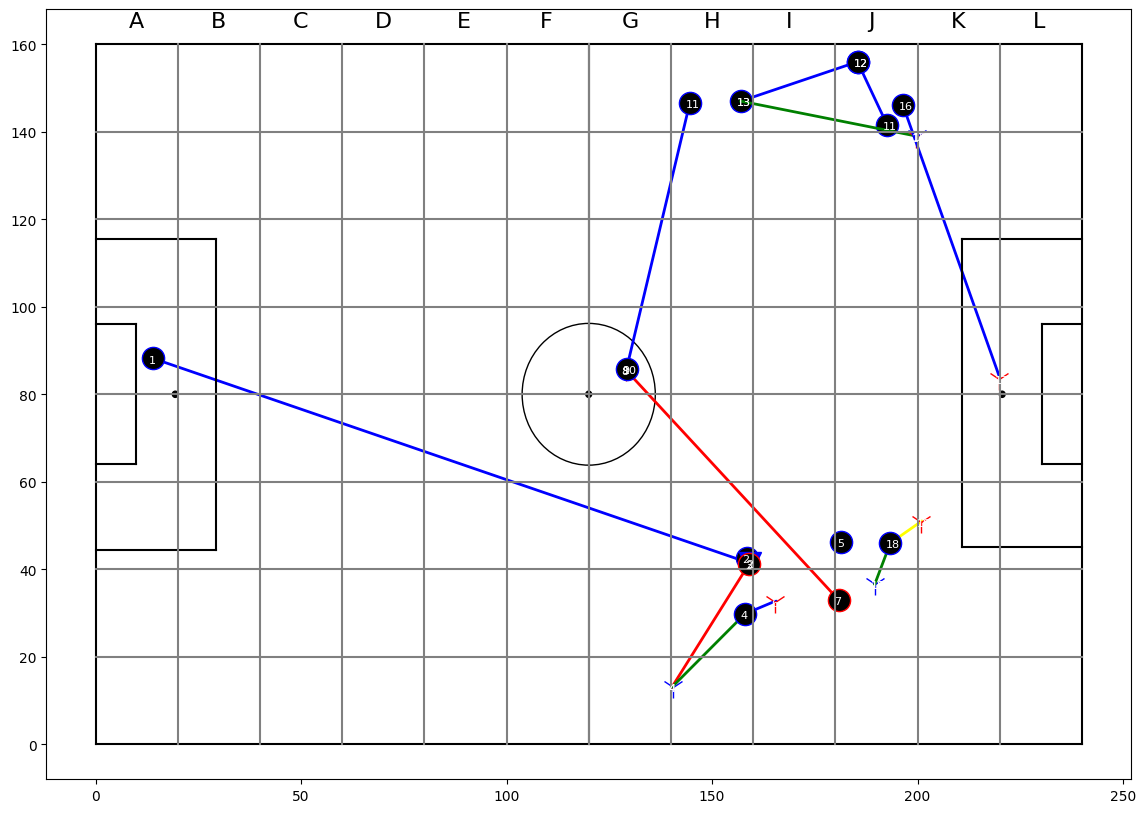

Sequence: 116
Team: Sweden
1: Emil Peter Forsberg (Pass) <00:25:05.054>
2: Karol Świderski (Clearance) <00:25:06.112>
3: Emil Krafth (Ball Recovery) <00:25:07.849>
3: Emil Krafth (Shot) <00:25:07.871>
4: Kamil Glik (Clearance) <00:25:09.104>
5: Kristoffer Olsson (Ball Recovery) <00:25:14.113>
5: Kristoffer Olsson (Carry) <00:25:14.113>
5: Kristoffer Olsson (Pass) <00:25:15.950>
6: Robin Olsen (Ball Receipt*) <00:25:20.187>
6: Robin Olsen (Pass) <00:25:20.187>
7: Jan Bednarek (Pass) <00:25:24.429>
8: Sebastian Larsson (Pass) <00:25:26.279>
9: Marcus Berg (Foul Committed) <00:25:28.324>
10: Grzegorz Krychowiak (Foul Won) <00:25:28.324>


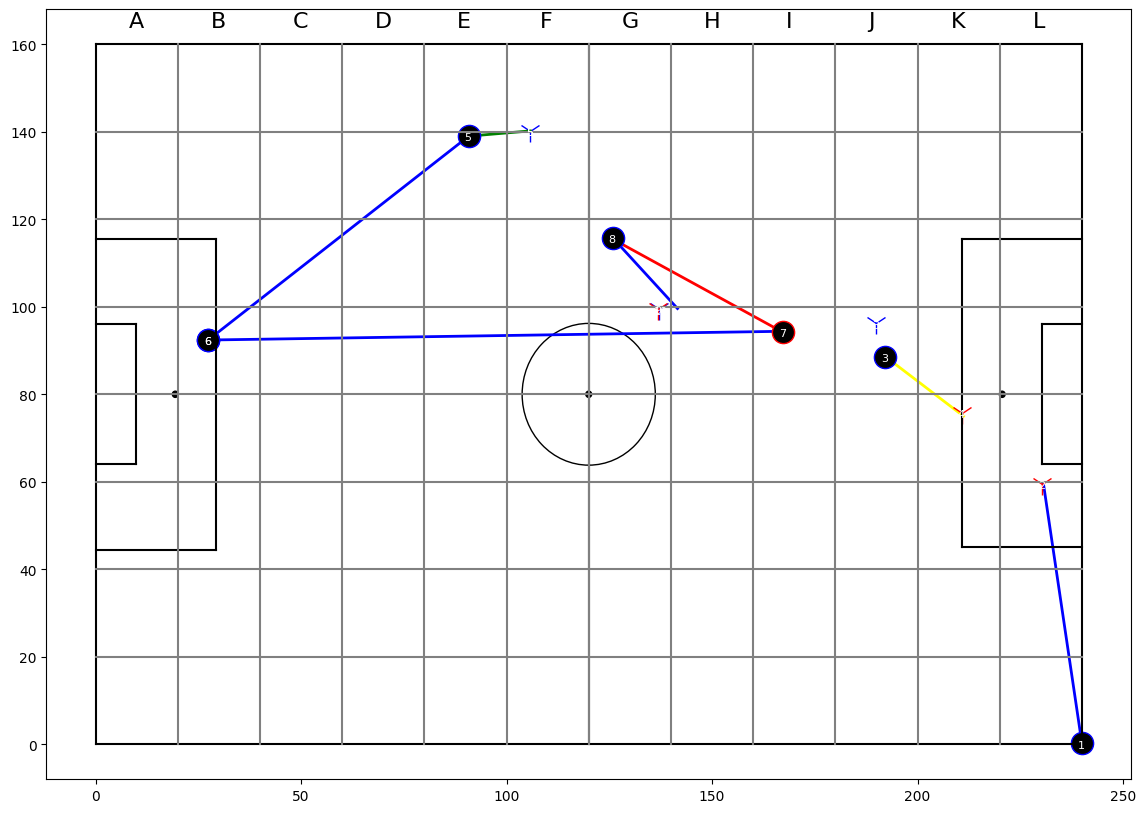

Sequence: 117
Team: Sweden
1: Albin Ekdal (Injury Stoppage) <00:25:54.665>


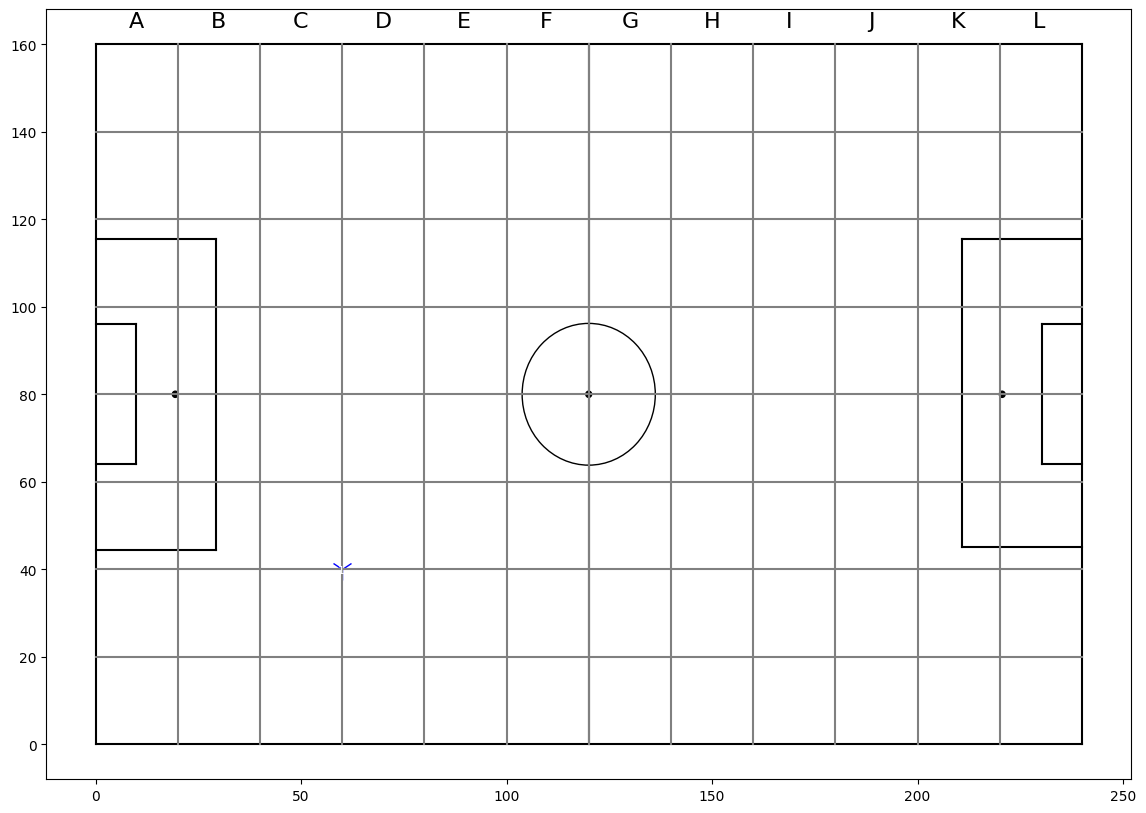

Sequence: 118
Team: Poland
1: Kamil Glik (Pass) <00:27:30.920>
2: Jan Bednarek (Ball Receipt*) <00:27:31.520>
2: Jan Bednarek (Pass) <00:27:32.130>
3: Kamil Glik (Ball Receipt*) <00:27:33.303>
3: Kamil Glik (Pass) <00:27:34.880>
4: Bartosz Bereszyński (Ball Receipt*) <00:27:36.518>
4: Bartosz Bereszyński (Carry) <00:27:36.518>
4: Bartosz Bereszyński (Pass) <00:27:37.655>
5: Karol Świderski (Ball Receipt*) <00:27:39.080>
5: Karol Świderski (Pass) <00:27:39.080>
6: Bartosz Bereszyński (Ball Receipt*) <00:27:40.144>
6: Bartosz Bereszyński (Carry) <00:27:40.144>
6: Bartosz Bereszyński (Pass) <00:27:43.571>
7: Piotr Zieliński (Ball Receipt*) <00:27:46.328>
8: Marcus Andreas Danielsson (Clearance) <00:27:46.328>
9: Kristoffer Olsson (Duel) <00:27:48.485>
10: Grzegorz Krychowiak (Pass) <00:27:48.485>
11: Emil Krafth (Pass) <00:27:50.220>
12: Marcus Berg (Ball Receipt*) <00:27:52.503>
13: Jan Bednarek (Ball Recovery) <00:27:52.503>
13: Jan Bednarek (Carry) <00:27:52.503>
13: Jan Bednarek (Pass

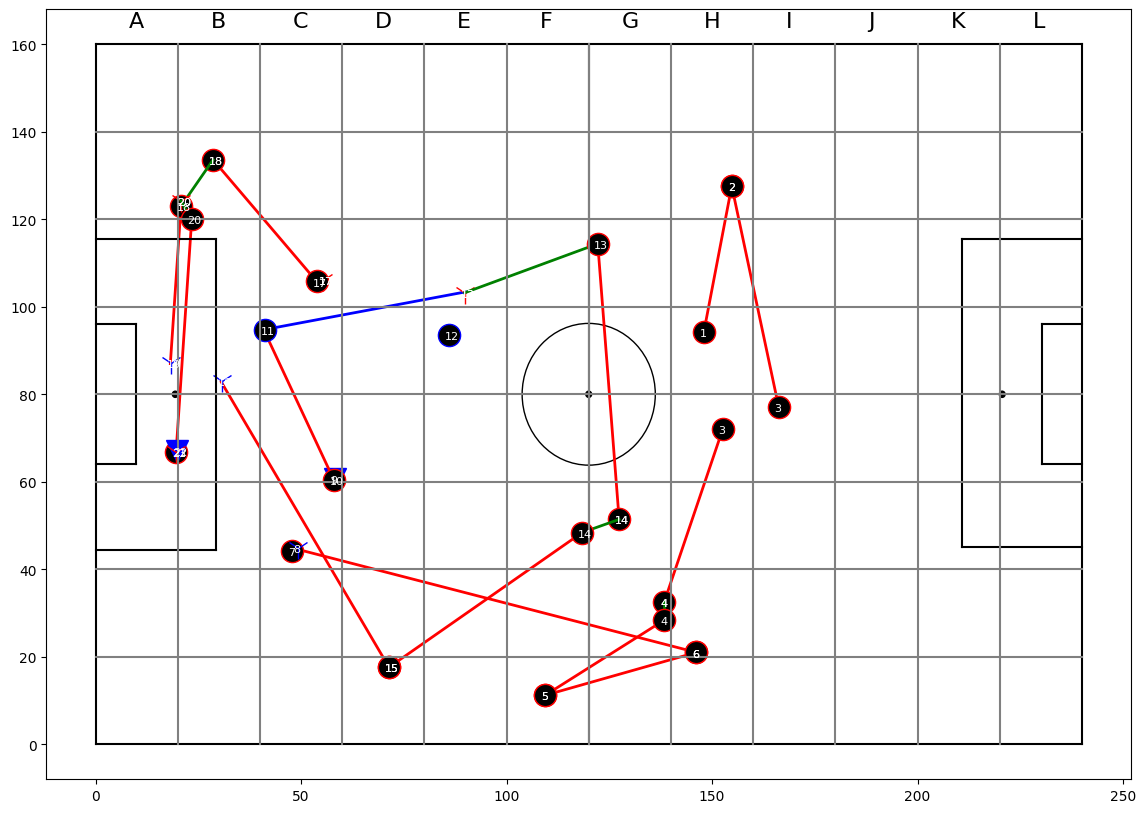

Sequence: 119
Team: Sweden
1: Ludwig Augustinsson (Pass) <00:28:35.389>
2: Marcus Berg (Ball Receipt*) <00:28:37.029>
3: Bartosz Bereszyński (Duel) <00:28:37.029>
4: Marcus Berg (Miscontrol) <00:28:37.029>
5: Bartosz Bereszyński (Ball Recovery) <00:28:38.092>
5: Bartosz Bereszyński (Carry) <00:28:38.092>
5: Bartosz Bereszyński (Pass) <00:28:38.718>
6: Kristoffer Olsson (Interception) <00:28:39.776>
6: Kristoffer Olsson (Carry) <00:28:39.776>
7: Grzegorz Krychowiak (Foul Committed) <00:28:40.009>
8: Kristoffer Olsson (Foul Won) <00:28:40.009>
8: Kristoffer Olsson (Injury Stoppage) <00:29:43.309>
9: Marcus Andreas Danielsson (Pass) <00:30:24.947>
10: Marcus Berg (Ball Receipt*) <00:30:28.649>
10: Marcus Berg (Pass) <00:30:28.649>
11: Dejan Kulusevski (Ball Receipt*) <00:30:31.162>


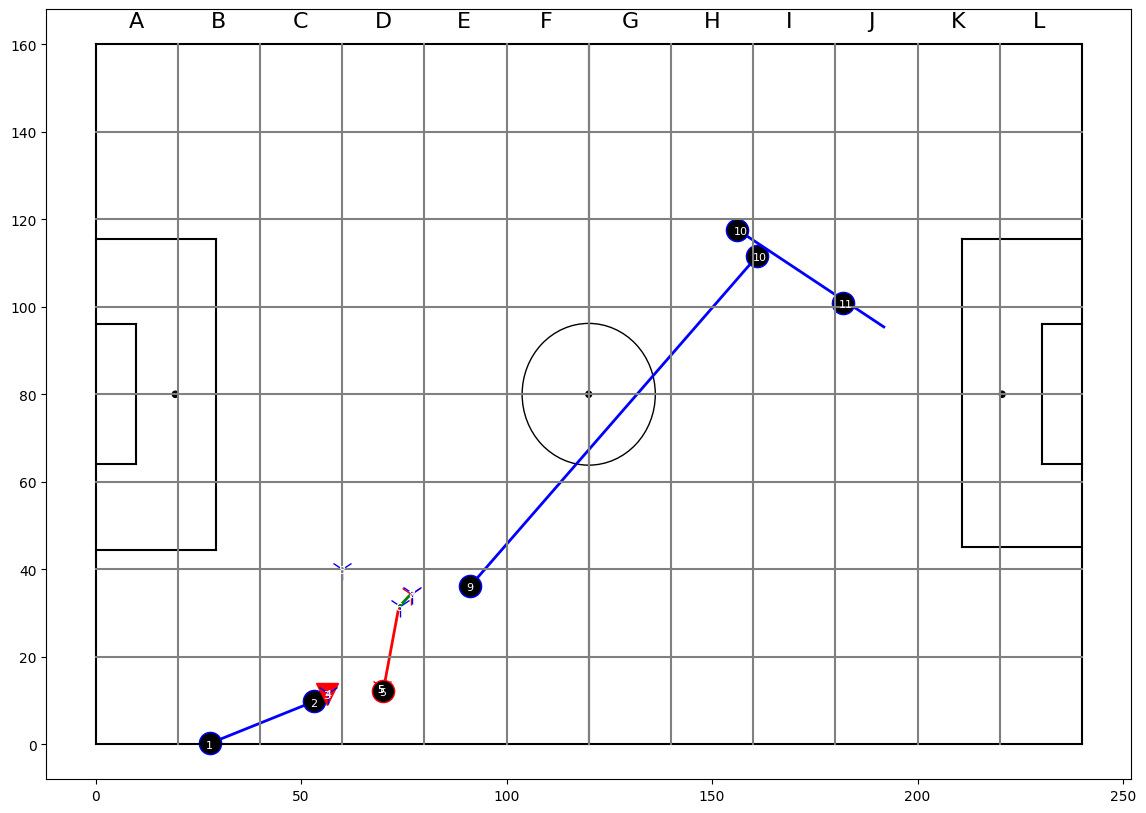

Sequence: 120
Team: Poland
1: Kamil Glik (Pass) <00:30:31.162>
2: Grzegorz Krychowiak (Ball Receipt*) <00:30:32.389>
2: Grzegorz Krychowiak (Pass) <00:30:32.389>
3: Jan Bednarek (Ball Receipt*) <00:30:33.323>
3: Jan Bednarek (Carry) <00:30:33.323>
3: Jan Bednarek (Pass) <00:30:35.492>
4: Kamil Glik (Ball Receipt*) <00:30:37.036>
4: Kamil Glik (Carry) <00:30:37.036>
4: Kamil Glik (Pass) <00:30:37.961>
5: Bartosz Bereszyński (Ball Receipt*) <00:30:39.082>
5: Bartosz Bereszyński (Carry) <00:30:39.082>
5: Bartosz Bereszyński (Pass) <00:30:40.531>
6: Kacper Kozłowski (Ball Receipt*) <00:30:41.419>
6: Kacper Kozłowski (Carry) <00:30:41.419>
6: Kacper Kozłowski (Pass) <00:30:44.398>
7: Karol Świderski (Ball Receipt*) <00:30:45.405>
7: Karol Świderski (Carry) <00:30:45.405>
7: Karol Świderski (Pass) <00:30:46.674>
8: Bartosz Bereszyński (Ball Receipt*) <00:30:48.989>
9: Marcus Andreas Danielsson (Clearance) <00:30:48.989>
10: Bartosz Bereszyński (Block) <00:30:49.080>
11: Marcus Andreas Daniel

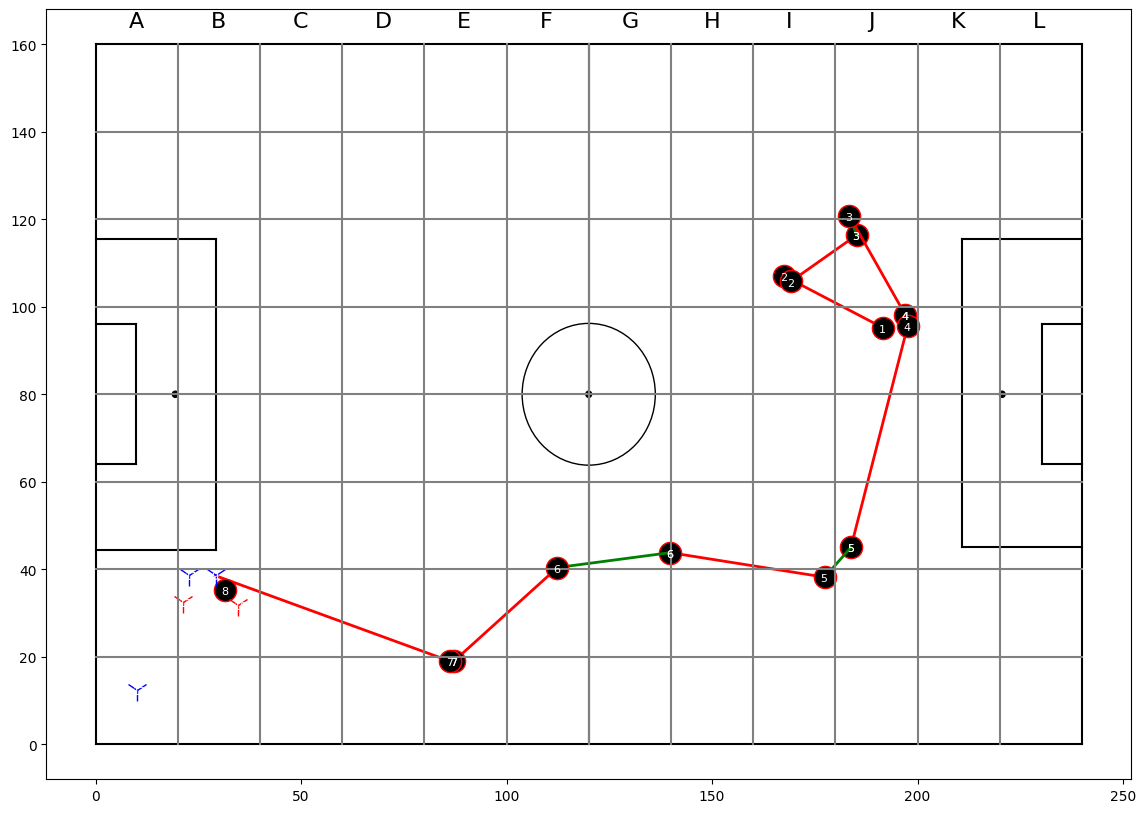

Sequence: 121
Team: Poland
1: Bartosz Bereszyński (Pass) <00:31:05.044>
2: Piotr Zieliński (Ball Receipt*) <00:31:05.797>
2: Piotr Zieliński (Pass) <00:31:05.797>
3: Bartosz Bereszyński (Ball Receipt*) <00:31:06.534>
3: Bartosz Bereszyński (Carry) <00:31:06.534>
3: Bartosz Bereszyński (Dribble) <00:31:07.126>
3: Bartosz Bereszyński (Carry) <00:31:07.126>
3: Bartosz Bereszyński (Pass) <00:31:08.416>
4: Kacper Kozłowski (Ball Receipt*) <00:31:08.909>
4: Kacper Kozłowski (Pass) <00:31:08.909>
5: Bartosz Bereszyński (Ball Receipt*) <00:31:10.062>
5: Bartosz Bereszyński (Pass) <00:31:10.062>
6: Robin Olsen (Ball Recovery) <00:31:11.266>
6: Robin Olsen (Carry) <00:31:11.266>
6: Robin Olsen (Pass) <00:31:25.316>
7: Emil Peter Forsberg (Ball Receipt*) <00:31:29.908>


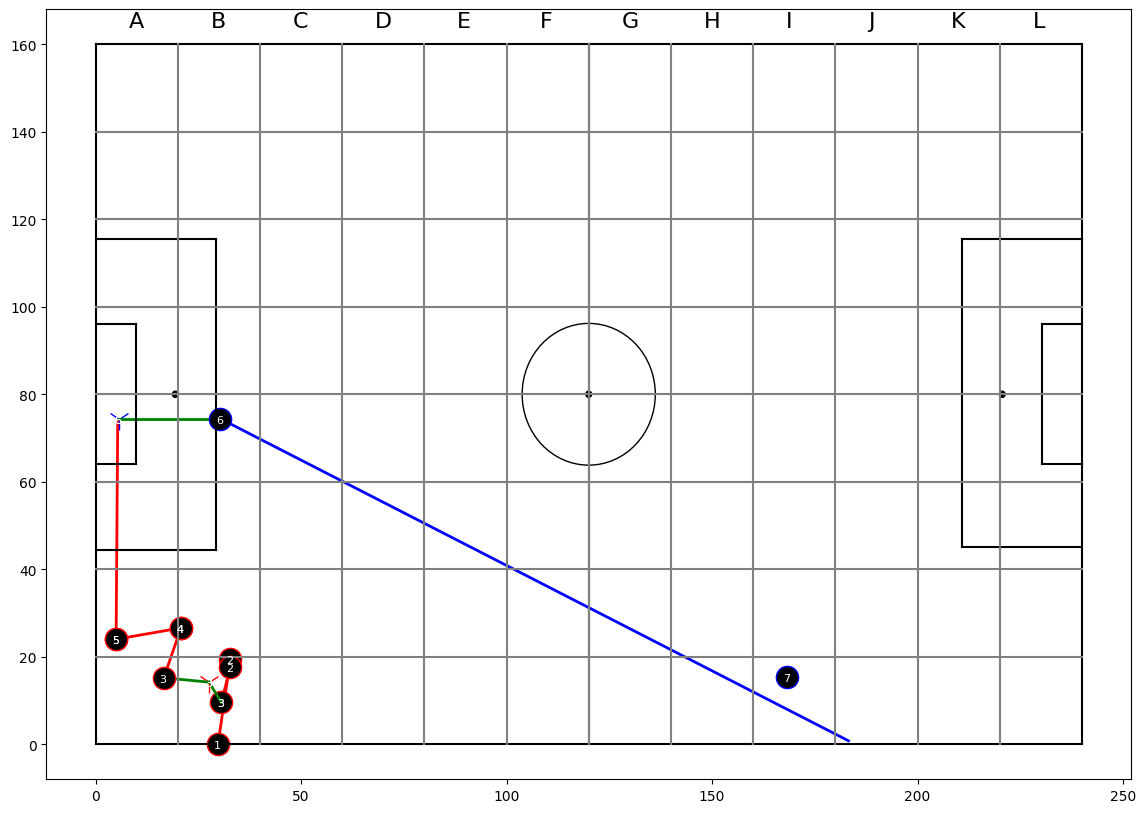

Sequence: 122
Team: Poland
1: Bartosz Bereszyński (Pass) <00:31:52.965>
2: Kamil Glik (Ball Receipt*) <00:31:53.671>
2: Kamil Glik (Carry) <00:31:53.671>
2: Kamil Glik (Pass) <00:31:55.009>
3: Jan Bednarek (Ball Receipt*) <00:31:56.750>
3: Jan Bednarek (Pass) <00:31:58.560>
4: Przemysław Frankowski (Ball Receipt*) <00:32:00.172>
4: Przemysław Frankowski (Pass) <00:32:02.688>
5: Kamil Glik (Ball Receipt*) <00:32:04.647>
5: Kamil Glik (Carry) <00:32:04.647>
5: Kamil Glik (Pass) <00:32:05.450>
6: Bartosz Bereszyński (Ball Receipt*) <00:32:06.399>
6: Bartosz Bereszyński (Carry) <00:32:06.399>
6: Bartosz Bereszyński (Pass) <00:32:08.844>
7: Karol Świderski (Ball Receipt*) <00:32:10.070>
7: Karol Świderski (Carry) <00:32:10.070>
7: Karol Świderski (Pass) <00:32:11.624>
8: Kamil Glik (Ball Receipt*) <00:32:13.407>
8: Kamil Glik (Carry) <00:32:13.407>
8: Kamil Glik (Pass) <00:32:13.673>
9: Jan Bednarek (Ball Receipt*) <00:32:14.948>
9: Jan Bednarek (Carry) <00:32:14.948>
9: Jan Bednarek (Pass)

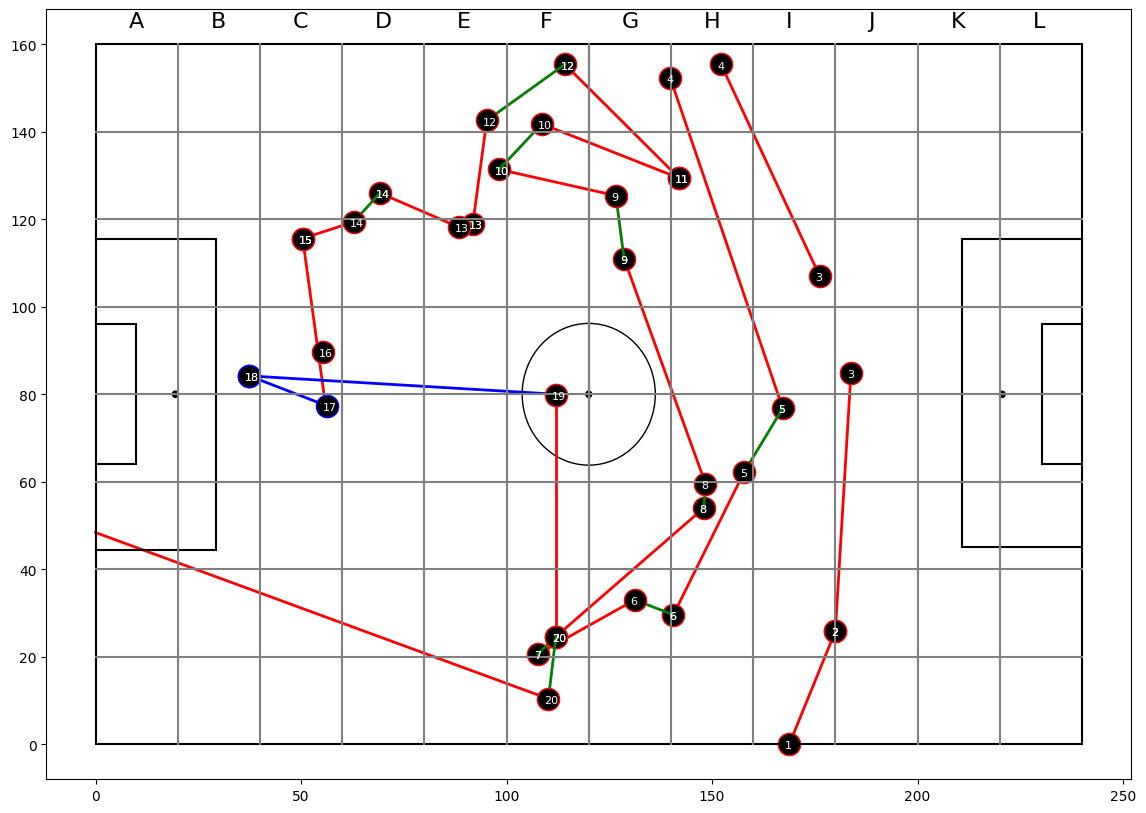

Sequence: 123
Team: Sweden
1: Robin Olsen (Pass) <00:33:13.443>


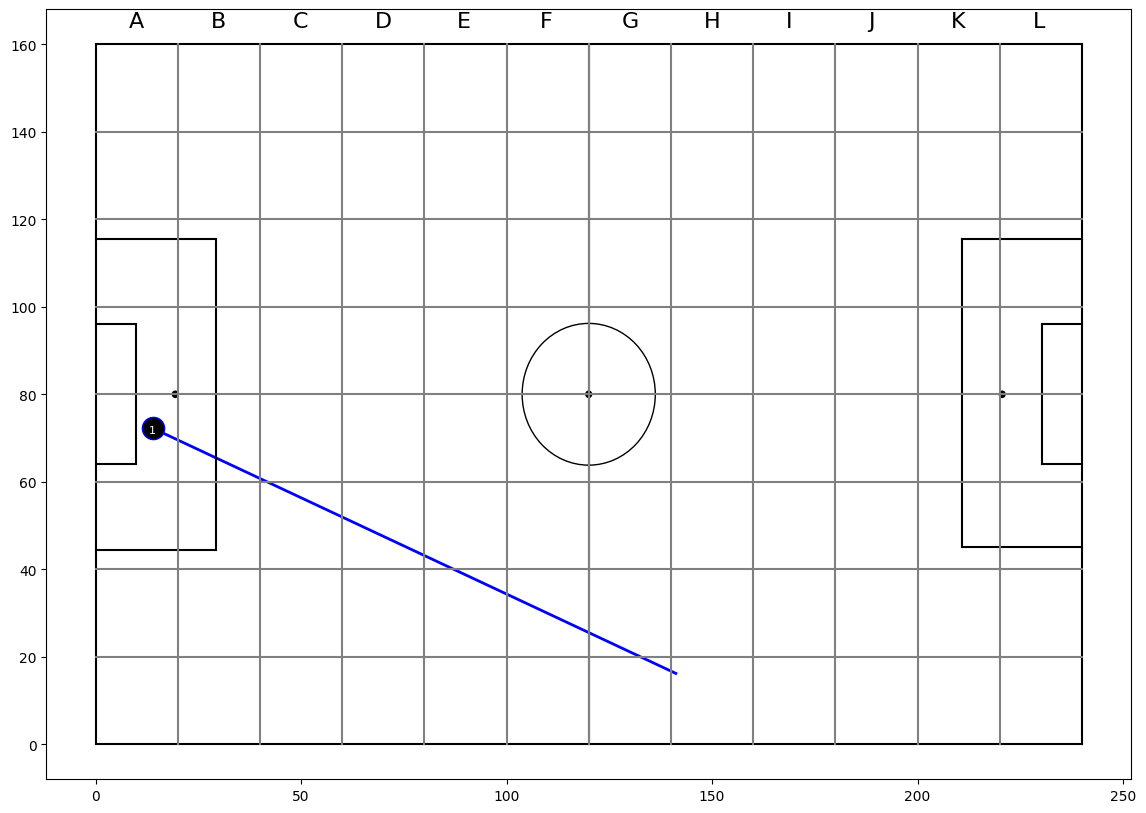

Sequence: 124
Team: Poland
1: Kamil Glik (Pass) <00:33:16.643>
2: Robert Lewandowski (Ball Receipt*) <00:33:21.280>
2: Robert Lewandowski (Pass) <00:33:22.043>
3: Jakub Świerczok (Ball Receipt*) <00:33:22.808>
3: Jakub Świerczok (Miscontrol) <00:33:22.984>
4: Robin Olsen (Ball Recovery) <00:33:24.088>
4: Robin Olsen (Pass) <00:33:40.804>
5: Viktor Claesson (Ball Receipt*) <00:33:44.299>
5: Viktor Claesson (Pass) <00:33:44.299>
6: Kamil Glik (Duel) <00:33:44.299>
6: Kamil Glik (Block) <00:33:44.334>
7: Piotr Zieliński (Ball Recovery) <00:33:46.684>
7: Piotr Zieliński (Carry) <00:33:46.684>
7: Piotr Zieliński (Dispossessed) <00:33:53.585>
8: Marcus Berg (Duel) <00:33:53.585>
9: Jan Bednarek (Pass) <00:33:55.132>
10: Bartosz Bereszyński (Ball Receipt*) <00:33:56.605>
10: Bartosz Bereszyński (Carry) <00:33:56.605>
10: Bartosz Bereszyński (Pass) <00:33:57.715>
11: Kacper Kozłowski (Ball Receipt*) <00:33:58.396>
11: Kacper Kozłowski (Carry) <00:33:58.396>
11: Kacper Kozłowski (Pass) <00:33:5

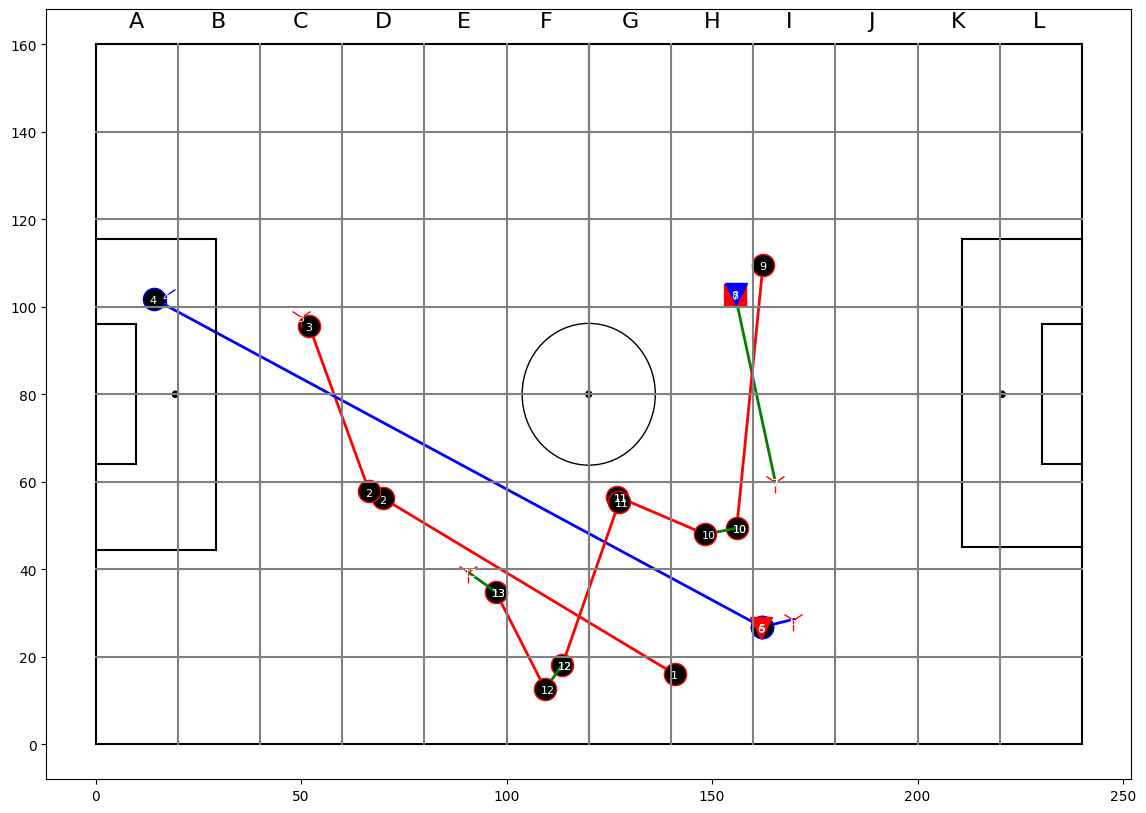

Sequence: 125
Team: Sweden
1: Albin Ekdal (Pass) <00:34:04.170>
2: Dejan Kulusevski (Ball Receipt*) <00:34:05.994>
2: Dejan Kulusevski (Carry) <00:34:05.994>
2: Dejan Kulusevski (Pass) <00:34:06.129>
3: Marcus Berg (Ball Receipt*) <00:34:07.089>
3: Marcus Berg (Carry) <00:34:07.089>
3: Marcus Berg (Dispossessed) <00:34:08.390>


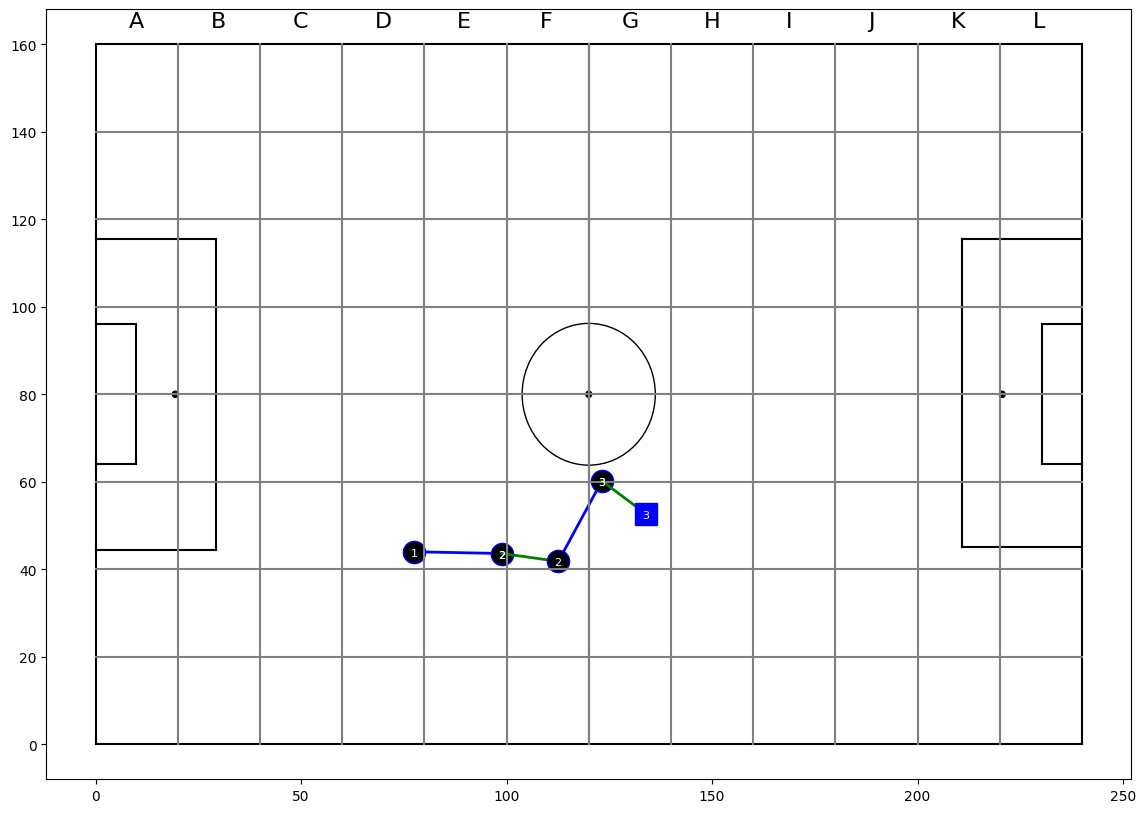

Sequence: 126
Team: Poland
1: Jan Bednarek (Duel) <00:34:08.390>
1: Jan Bednarek (Carry) <00:34:08.390>
1: Jan Bednarek (Pass) <00:34:09.405>
2: Piotr Zieliński (Ball Receipt*) <00:34:10.289>
2: Piotr Zieliński (Carry) <00:34:10.289>
2: Piotr Zieliński (Pass) <00:34:12.769>
3: Robert Lewandowski (Ball Receipt*) <00:34:14.357>
3: Robert Lewandowski (Carry) <00:34:14.357>
3: Robert Lewandowski (Pass) <00:34:15.938>
4: Przemysław Frankowski (Ball Receipt*) <00:34:17.368>
4: Przemysław Frankowski (Carry) <00:34:17.368>
4: Przemysław Frankowski (Pass) <00:34:20.427>
5: Przemysław Płacheta (Ball Receipt*) <00:34:23.502>
5: Przemysław Płacheta (Carry) <00:34:23.502>
5: Przemysław Płacheta (Pass) <00:34:28.074>
6: Sebastian Larsson (Clearance) <00:34:29.897>
7: Robert Lewandowski (Duel) <00:34:31.303>
8: Victor Nilsson Lindelöf (Clearance) <00:34:31.303>
9: Kristoffer Olsson (Clearance) <00:34:32.077>
10: Dejan Kulusevski (Foul Committed) <00:34:35.490>
11: Jan Bednarek (Foul Won) <00:34:35.49

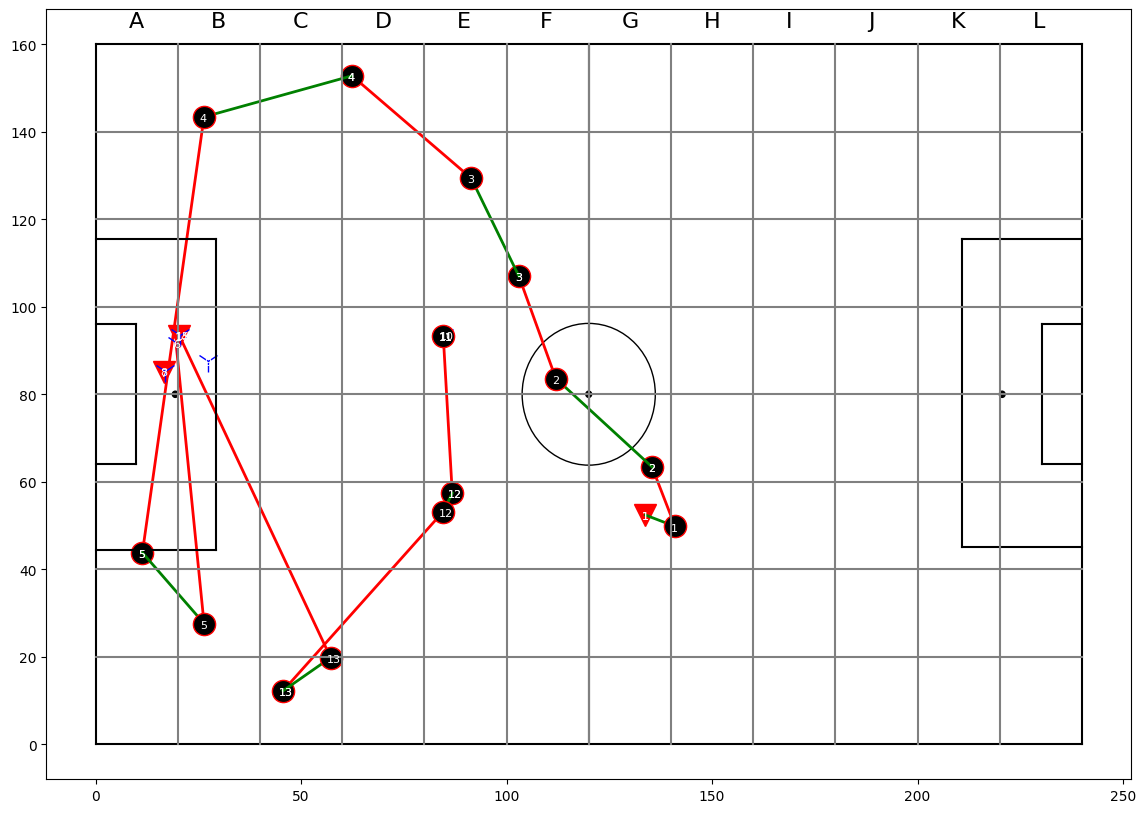

Sequence: 127
Team: Poland
1: Piotr Zieliński (Pass) <00:35:11.135>
2: Emil Krafth (Clearance) <00:35:13.066>
2: Emil Krafth (Error) <00:35:13.103>
3: Przemysław Płacheta (Ball Recovery) <00:35:14.600>
3: Przemysław Płacheta (Shot) <00:35:14.711>


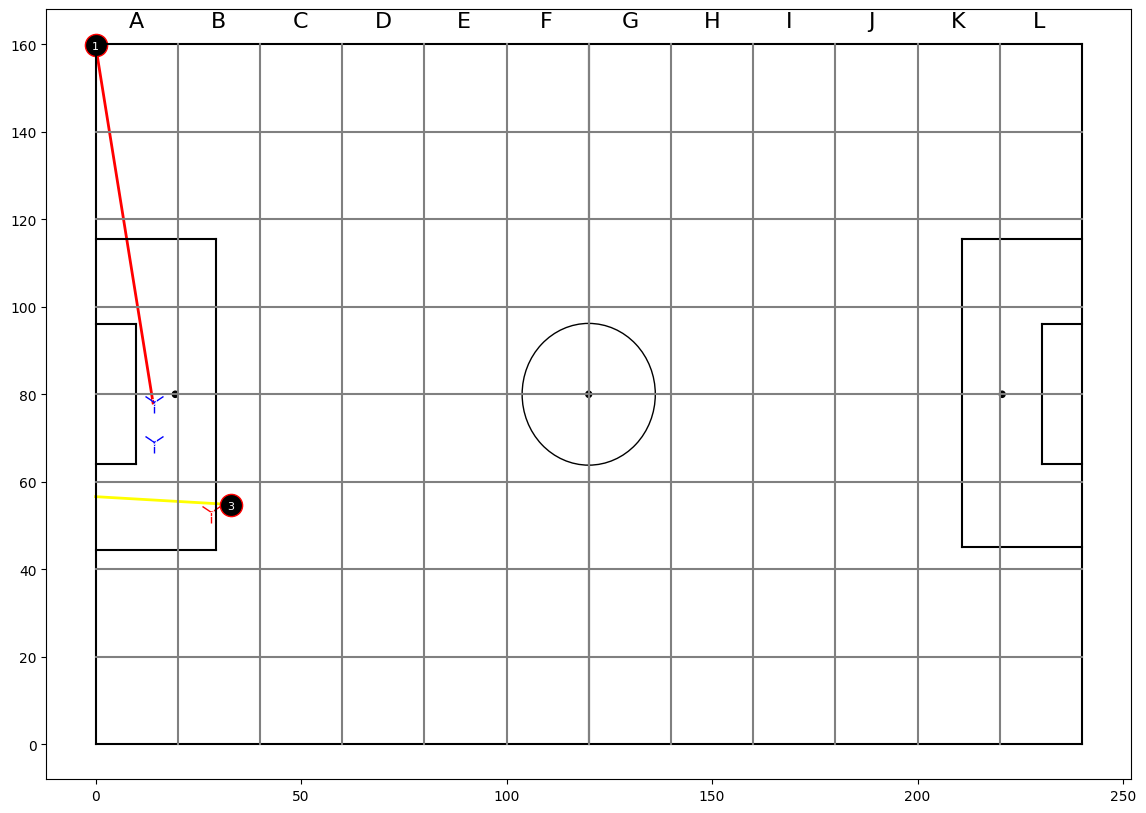

Sequence: 128
Team: Sweden
1: Robin Olsen (Pass) <00:35:47.061>
2: Marcus Berg (Duel) <00:35:50.830>
3: Kamil Glik (Pass) <00:35:50.830>
4: Sebastian Larsson (Pass) <00:35:52.888>


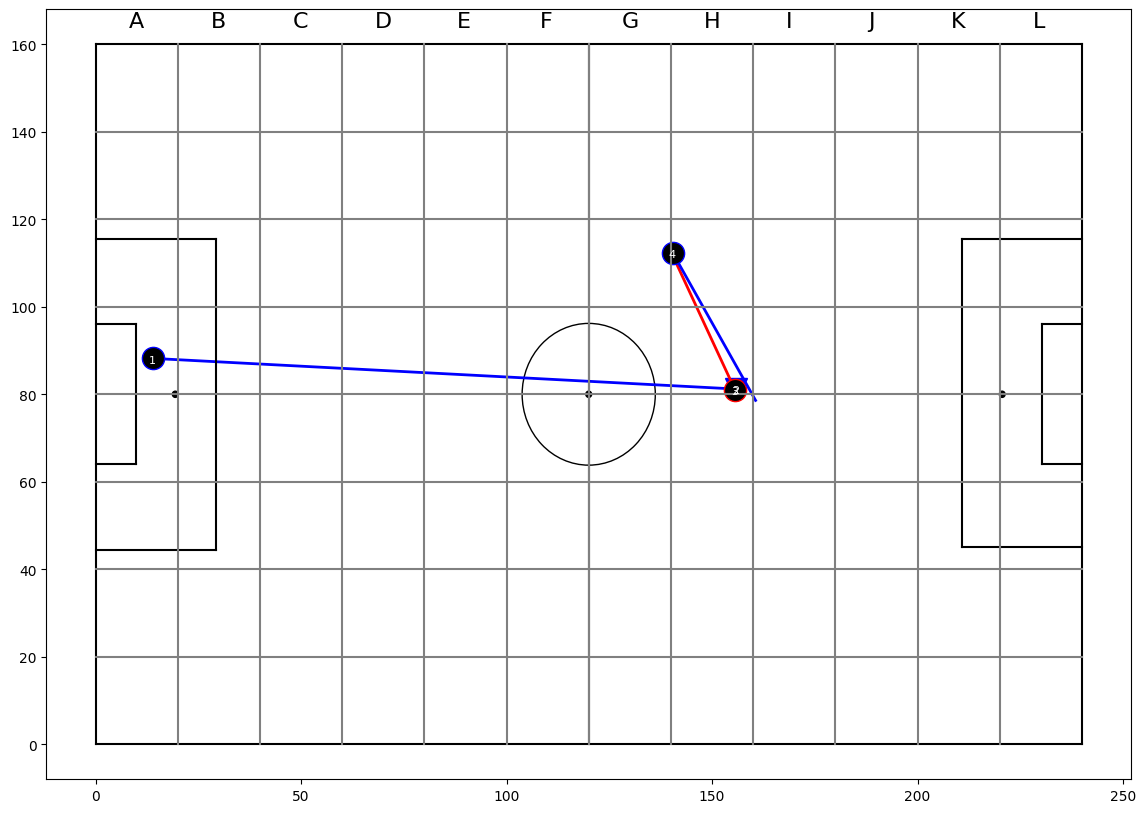

Sequence: 129
Team: Poland
1: Kamil Glik (Pass) <00:35:54.333>
2: Przemysław Frankowski (Ball Receipt*) <00:35:55.994>
2: Przemysław Frankowski (Carry) <00:35:55.994>
2: Przemysław Frankowski (Pass) <00:35:57.848>
3: Jan Bednarek (Ball Receipt*) <00:35:58.877>
3: Jan Bednarek (Carry) <00:35:58.877>
3: Jan Bednarek (Pass) <00:36:00.268>
4: Bartosz Bereszyński (Ball Receipt*) <00:36:01.708>
4: Bartosz Bereszyński (Carry) <00:36:01.708>
4: Bartosz Bereszyński (Pass) <00:36:02.564>
5: Kacper Kozłowski (Ball Receipt*) <00:36:03.474>
5: Kacper Kozłowski (Pass) <00:36:03.474>
6: Bartosz Bereszyński (Ball Receipt*) <00:36:04.434>
6: Bartosz Bereszyński (Carry) <00:36:04.434>
6: Bartosz Bereszyński (Pass) <00:36:05.518>
7: Kacper Kozłowski (Ball Receipt*) <00:36:06.621>
7: Kacper Kozłowski (Carry) <00:36:06.621>
7: Kacper Kozłowski (Pass) <00:36:07.367>
8: Kamil Glik (Ball Receipt*) <00:36:09.060>
8: Kamil Glik (Carry) <00:36:09.060>
8: Kamil Glik (Pass) <00:36:11.867>
9: Jan Bednarek (Ball Rec

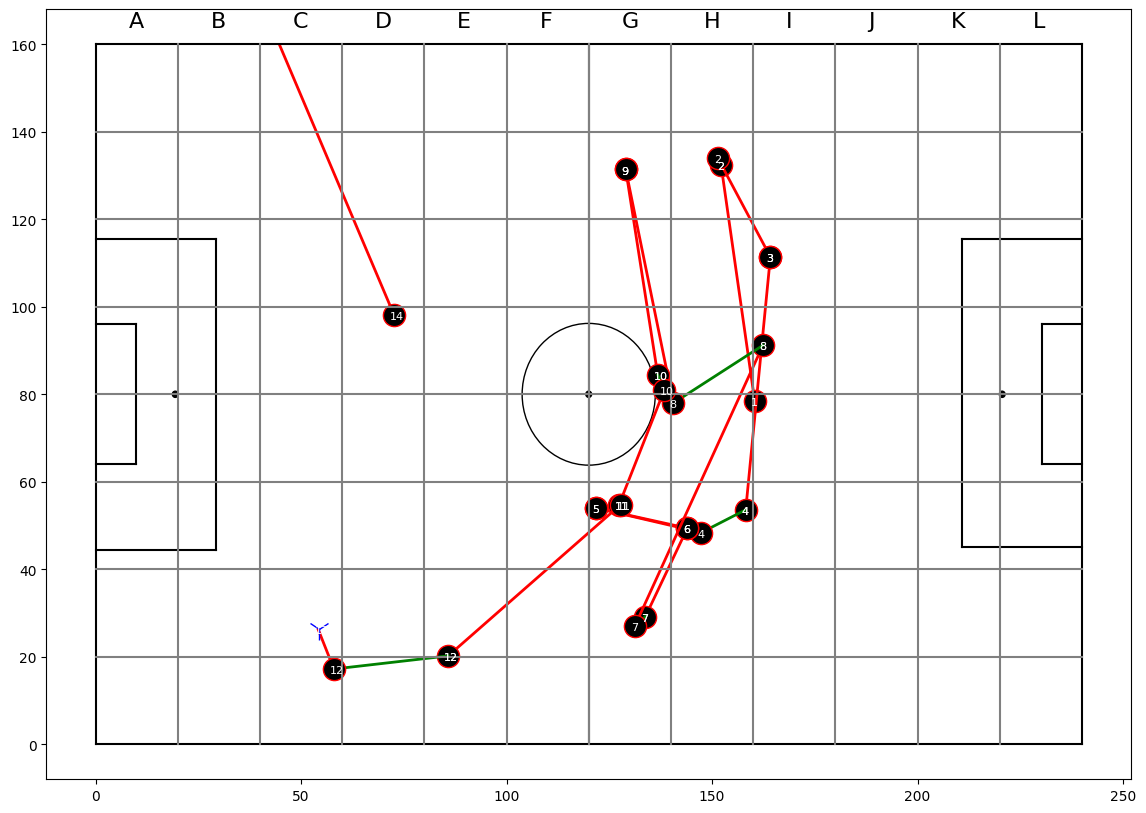

Sequence: 130
Team: Sweden
1: Emil Krafth (Pass) <00:36:53.591>
2: Dejan Kulusevski (Ball Receipt*) <00:36:54.766>
2: Dejan Kulusevski (Pass) <00:36:54.766>


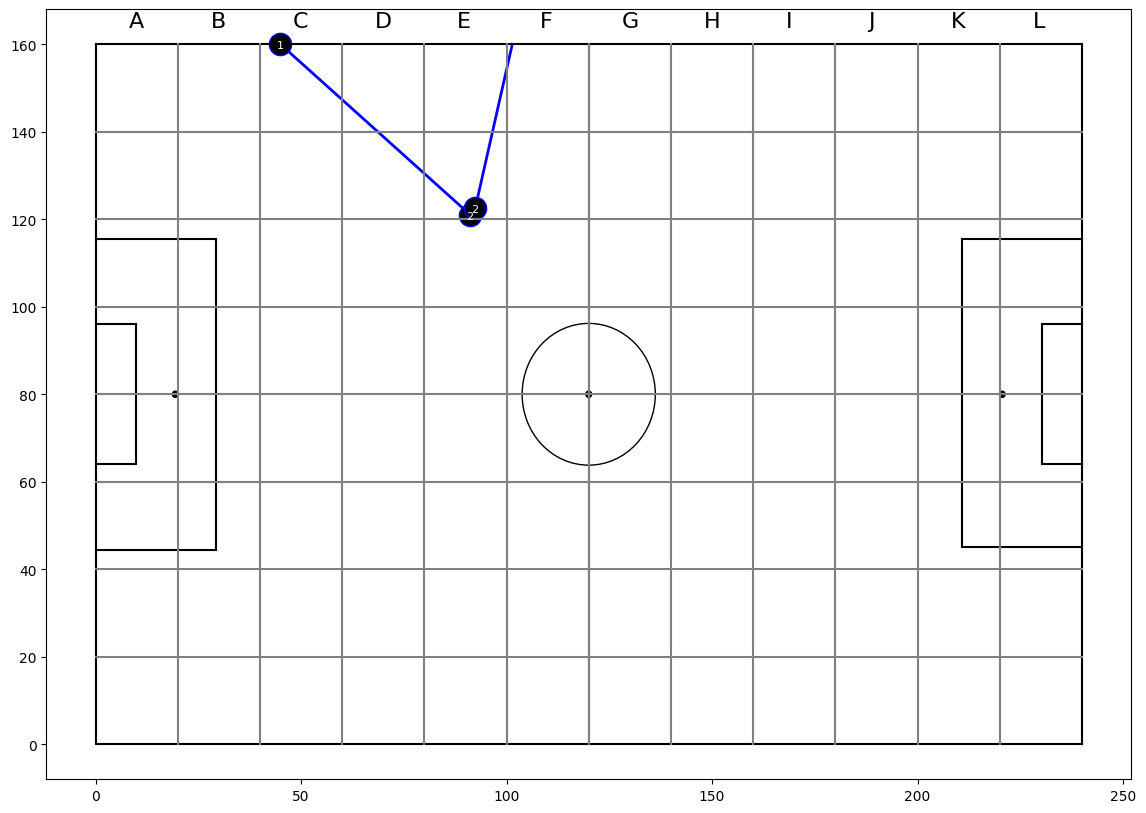

Sequence: 131
Team: Poland
1: Przemysław Frankowski (Pass) <00:37:01.239>
2: Jan Bednarek (Ball Receipt*) <00:37:02.533>
2: Jan Bednarek (Carry) <00:37:02.533>
2: Jan Bednarek (Pass) <00:37:03.579>
3: Bartosz Bereszyński (Ball Receipt*) <00:37:05.175>
3: Bartosz Bereszyński (Carry) <00:37:05.175>
3: Bartosz Bereszyński (Pass) <00:37:06.756>
4: Przemysław Płacheta (Ball Receipt*) <00:37:09.336>
4: Przemysław Płacheta (Carry) <00:37:09.336>
4: Przemysław Płacheta (Pass) <00:37:13.737>
5: Jakub Świerczok (Ball Receipt*) <00:37:14.810>
6: Marcus Andreas Danielsson (Interception) <00:37:14.810>


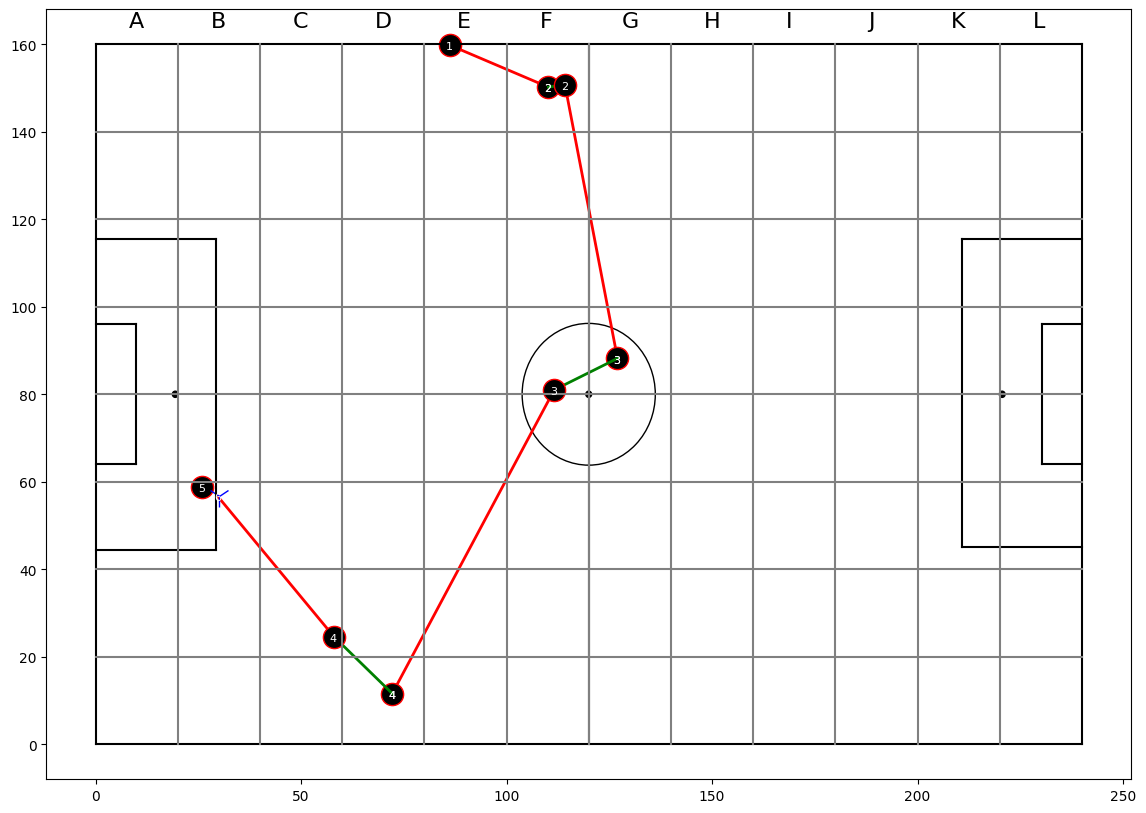

Sequence: 132
Team: Sweden
1: Ludwig Augustinsson (Pass) <00:37:15.240>
2: Marcus Andreas Danielsson (Ball Receipt*) <00:37:16.165>
2: Marcus Andreas Danielsson (Pass) <00:37:16.165>
3: Ludwig Augustinsson (Ball Receipt*) <00:37:16.985>
3: Ludwig Augustinsson (Carry) <00:37:16.985>
3: Ludwig Augustinsson (Pass) <00:37:17.960>
4: Dejan Kulusevski (Ball Receipt*) <00:37:19.962>
4: Dejan Kulusevski (Carry) <00:37:19.962>
5: Kamil Glik (Foul Committed) <00:37:20.082>
6: Dejan Kulusevski (Foul Won) <00:37:20.082>
7: Marcus Andreas Danielsson (Pass) <00:38:13.228>
8: Marcus Berg (Ball Receipt*) <00:38:15.897>
8: Marcus Berg (Duel) <00:38:15.897>


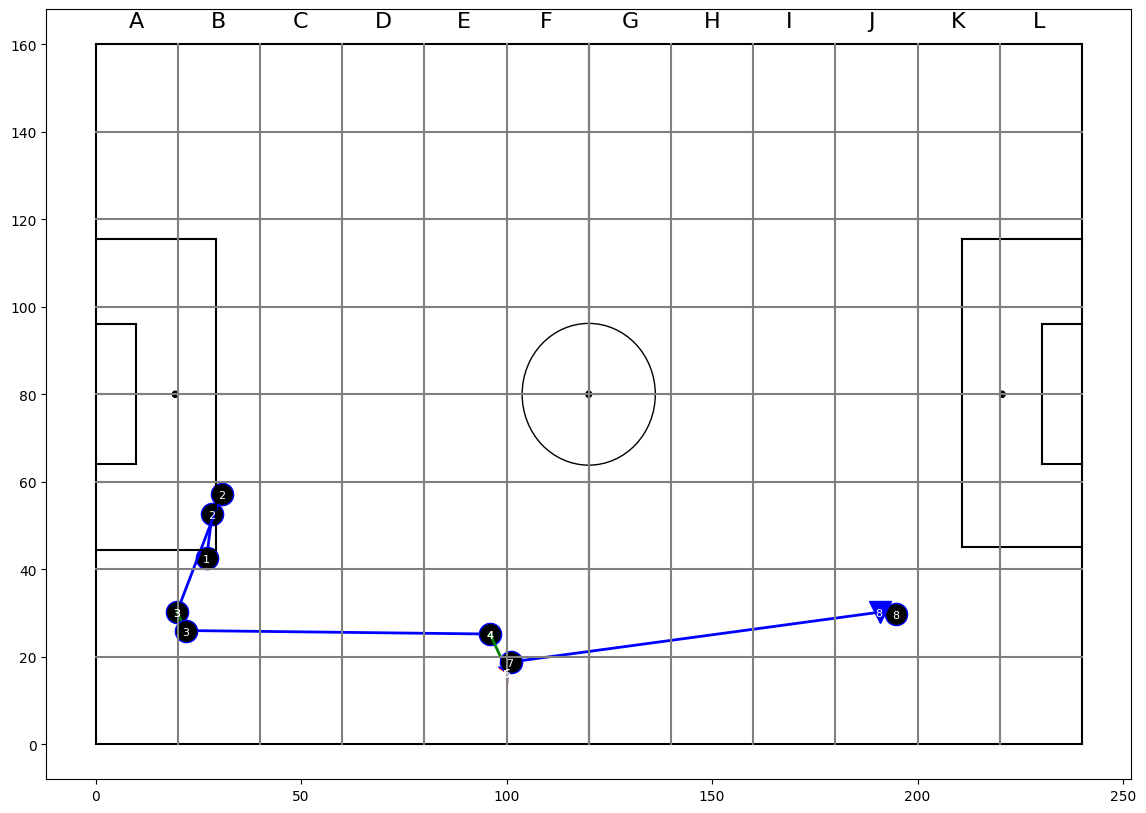

Sequence: 133
Team: Poland
1: Bartosz Bereszyński (Pass) <00:38:15.897>
2: Jakub Świerczok (Ball Receipt*) <00:38:17.761>
2: Jakub Świerczok (Carry) <00:38:17.761>
2: Jakub Świerczok (Pass) <00:38:17.784>
3: Przemysław Płacheta (Ball Receipt*) <00:38:18.816>
3: Przemysław Płacheta (Carry) <00:38:18.816>
3: Przemysław Płacheta (Pass) <00:38:20.152>
4: Jakub Świerczok (Ball Receipt*) <00:38:21.106>
4: Jakub Świerczok (Carry) <00:38:21.106>
4: Jakub Świerczok (Pass) <00:38:22.722>
5: Przemysław Frankowski (Ball Receipt*) <00:38:25.741>
5: Przemysław Frankowski (Carry) <00:38:25.741>
5: Przemysław Frankowski (Pass) <00:38:31.081>
6: Robert Lewandowski (Ball Receipt*) <00:38:32.532>
6: Robert Lewandowski (Carry) <00:38:32.532>
6: Robert Lewandowski (Shot) <00:38:33.617>


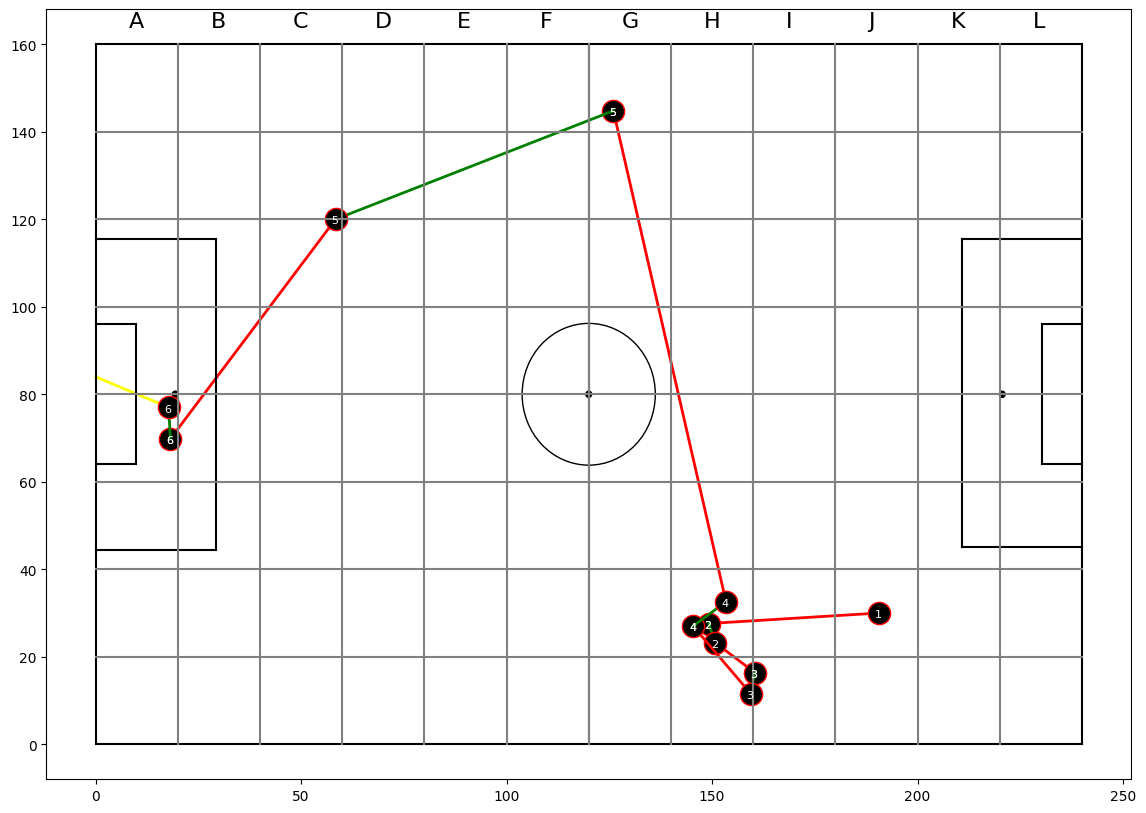

Sequence: 134
Team: Sweden
1: Sebastian Larsson (Pass) <00:39:28.777>
2: Victor Nilsson Lindelöf (Ball Receipt*) <00:39:31.666>
2: Victor Nilsson Lindelöf (Pass) <00:39:33.036>
3: Viktor Claesson (Ball Receipt*) <00:39:35.868>
3: Viktor Claesson (Duel) <00:39:35.868>
4: Bartosz Bereszyński (Clearance) <00:39:35.868>


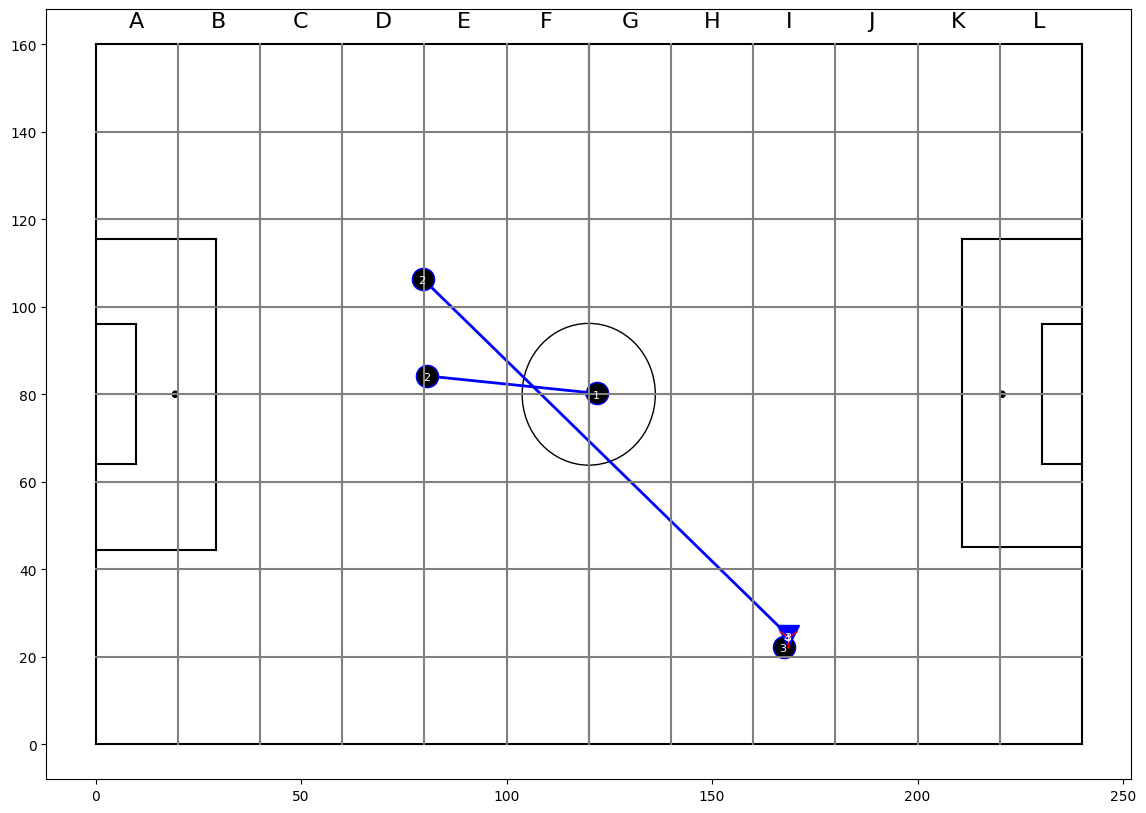

Sequence: 135
Team: Sweden
1: Ludwig Augustinsson (Pass) <00:39:49.799>
2: Dejan Kulusevski (Ball Receipt*) <00:39:50.772>
2: Dejan Kulusevski (Carry) <00:39:50.772>
2: Dejan Kulusevski (Pass) <00:39:53.026>
3: Sebastian Larsson (Ball Receipt*) <00:39:54.450>
3: Sebastian Larsson (Carry) <00:39:54.450>
3: Sebastian Larsson (Pass) <00:39:55.634>
4: Kristoffer Olsson (Ball Receipt*) <00:39:57.575>
4: Kristoffer Olsson (Carry) <00:39:57.575>
4: Kristoffer Olsson (Pass) <00:39:57.609>
5: Marcus Berg (Ball Receipt*) <00:39:58.209>
6: Kamil Glik (Clearance) <00:39:58.209>


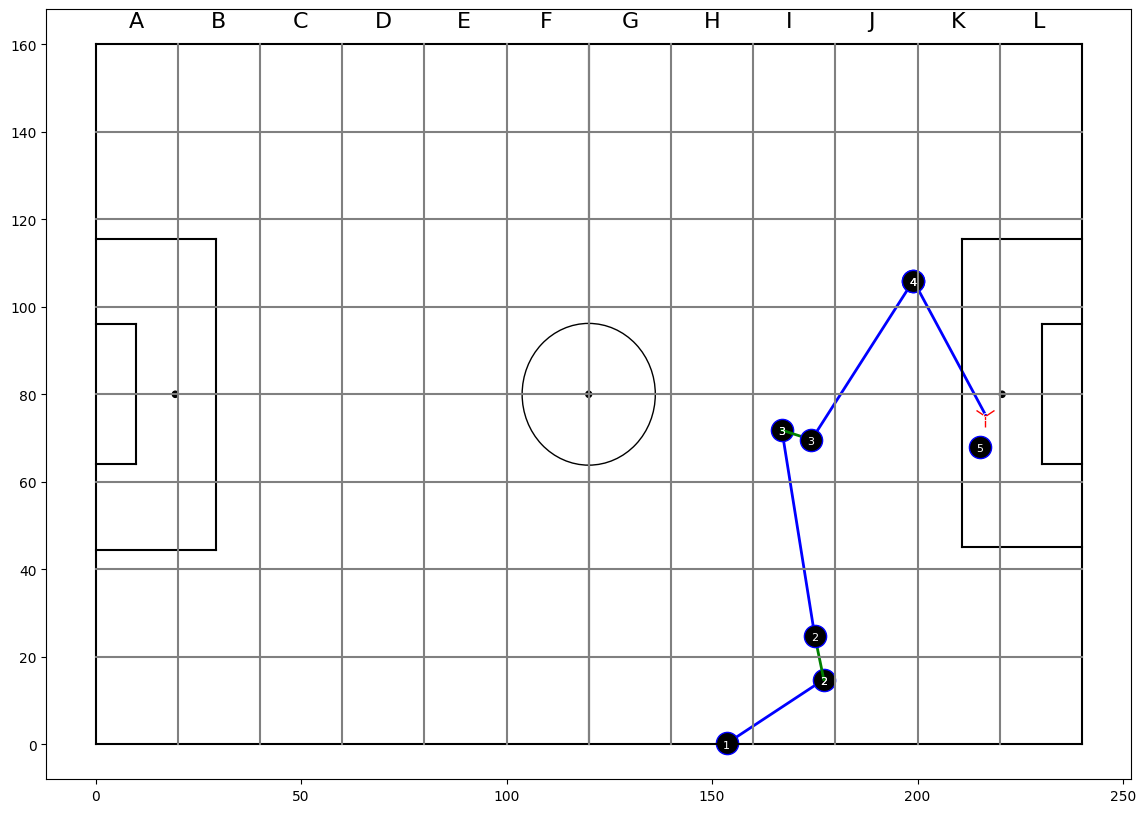

Sequence: 136
Team: Poland
1: Kacper Kozłowski (Pass) <00:40:00.164>
2: Karol Świderski (Ball Receipt*) <00:40:02.527>
2: Karol Świderski (Carry) <00:40:02.527>
2: Karol Świderski (Dribble) <00:40:07.348>
2: Karol Świderski (Carry) <00:40:07.348>
2: Karol Świderski (Pass) <00:40:08.604>
3: Przemysław Frankowski (Ball Receipt*) <00:40:10.037>
3: Przemysław Frankowski (Carry) <00:40:10.037>
3: Przemysław Frankowski (Pass) <00:40:11.418>
4: Robert Lewandowski (Ball Receipt*) <00:40:12.550>
4: Robert Lewandowski (Carry) <00:40:12.550>
4: Robert Lewandowski (Pass) <00:40:18.493>
5: Przemysław Frankowski (Ball Receipt*) <00:40:19.509>
5: Przemysław Frankowski (Carry) <00:40:19.509>
5: Przemysław Frankowski (Pass) <00:40:20.759>
6: Piotr Zieliński (Ball Receipt*) <00:40:22.245>
6: Piotr Zieliński (Carry) <00:40:22.245>
6: Piotr Zieliński (Pass) <00:40:24.736>
7: Bartosz Bereszyński (Ball Receipt*) <00:40:25.548>
7: Bartosz Bereszyński (Carry) <00:40:25.548>
7: Bartosz Bereszyński (Pass) <00:4

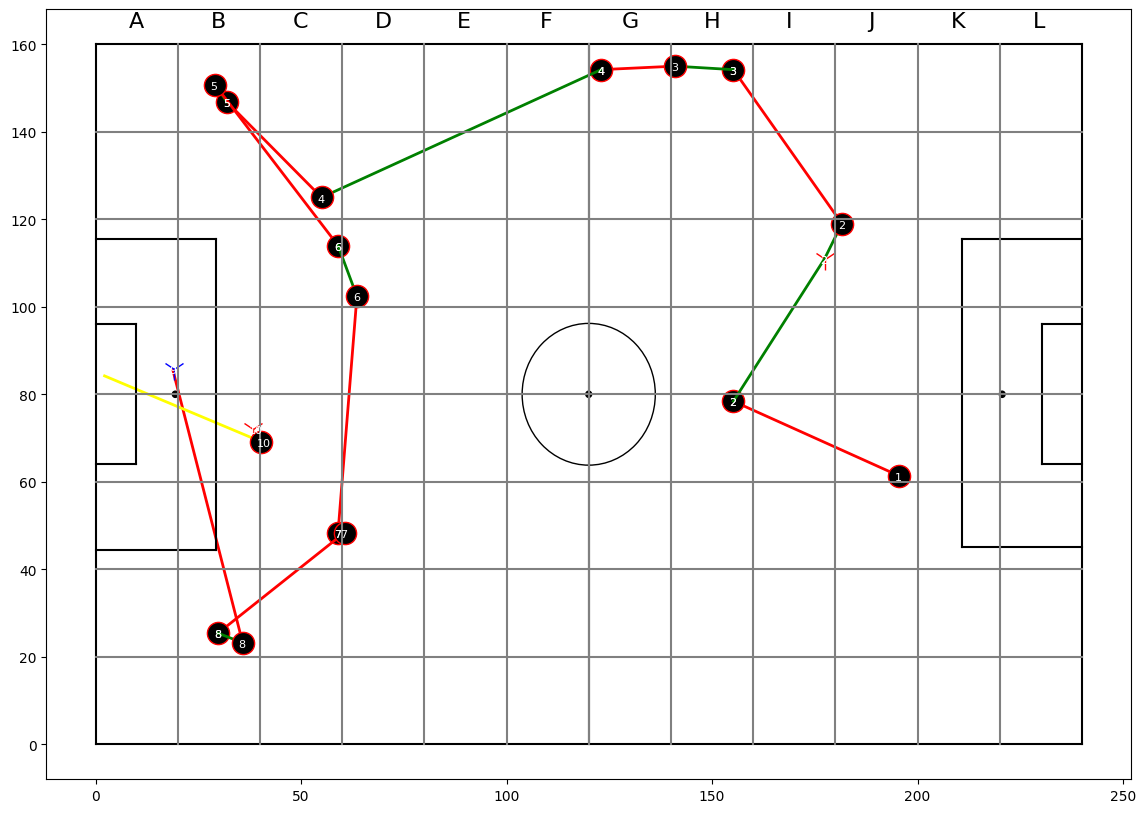

Sequence: 137
Team: Sweden
1: Robin Olsen (Pass) <00:40:52.092>
2: Dejan Kulusevski (Ball Receipt*) <00:40:58.414>


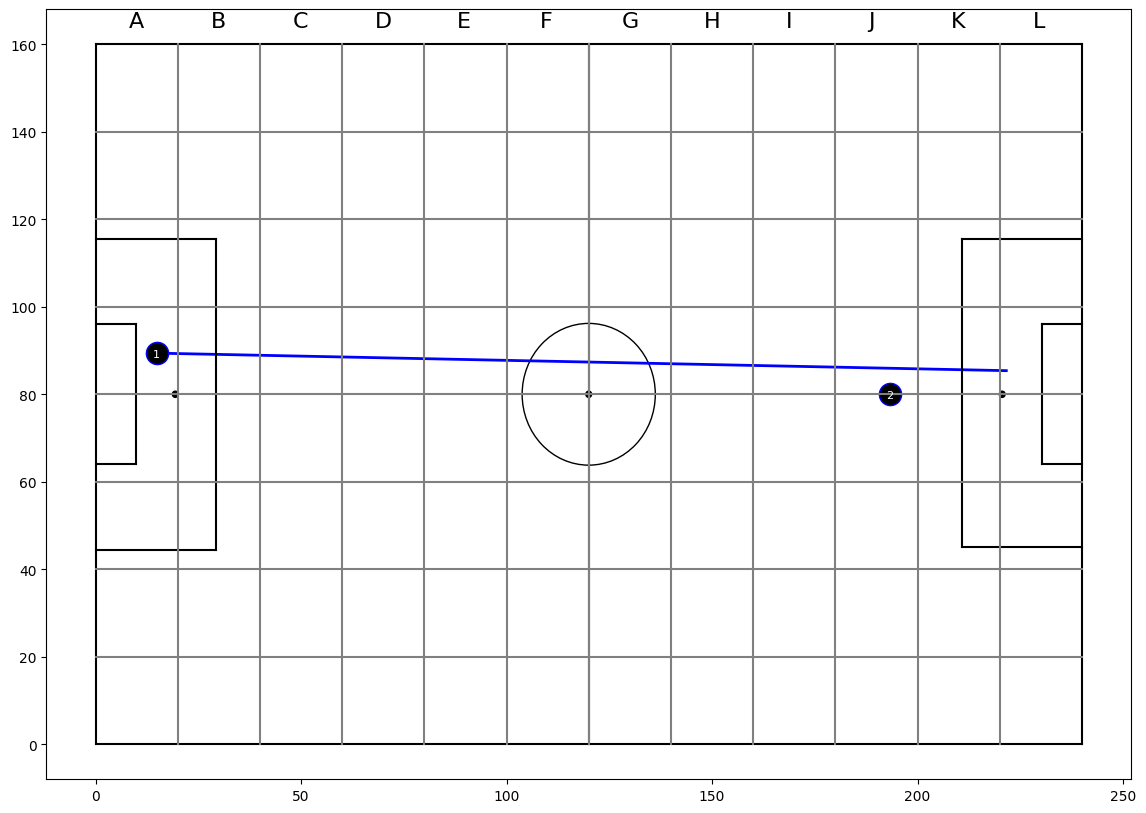

Sequence: 138
Team: Poland
1: Wojciech Szczęsny (Ball Recovery) <00:40:58.414>
1: Wojciech Szczęsny (Carry) <00:40:58.414>
1: Wojciech Szczęsny (Pass) <00:41:00.752>
2: Jan Bednarek (Ball Receipt*) <00:41:02.125>
2: Jan Bednarek (Carry) <00:41:02.125>
2: Jan Bednarek (Pass) <00:41:06.255>
3: Wojciech Szczęsny (Ball Receipt*) <00:41:09.157>
3: Wojciech Szczęsny (Carry) <00:41:09.157>
3: Wojciech Szczęsny (Pass) <00:41:10.561>
4: Kamil Glik (Ball Receipt*) <00:41:11.448>
4: Kamil Glik (Carry) <00:41:11.448>
4: Kamil Glik (Pass) <00:41:14.386>
5: Bartosz Bereszyński (Ball Receipt*) <00:41:15.605>
5: Bartosz Bereszyński (Carry) <00:41:15.605>
5: Bartosz Bereszyński (Pass) <00:41:16.220>
6: Kacper Kozłowski (Ball Receipt*) <00:41:17.175>
6: Kacper Kozłowski (Pass) <00:41:17.175>
7: Bartosz Bereszyński (Ball Receipt*) <00:41:18.519>
7: Bartosz Bereszyński (Carry) <00:41:18.519>
7: Bartosz Bereszyński (Pass) <00:41:19.010>
8: Przemysław Płacheta (Ball Receipt*) <00:41:20.131>
8: Przemysław Pł

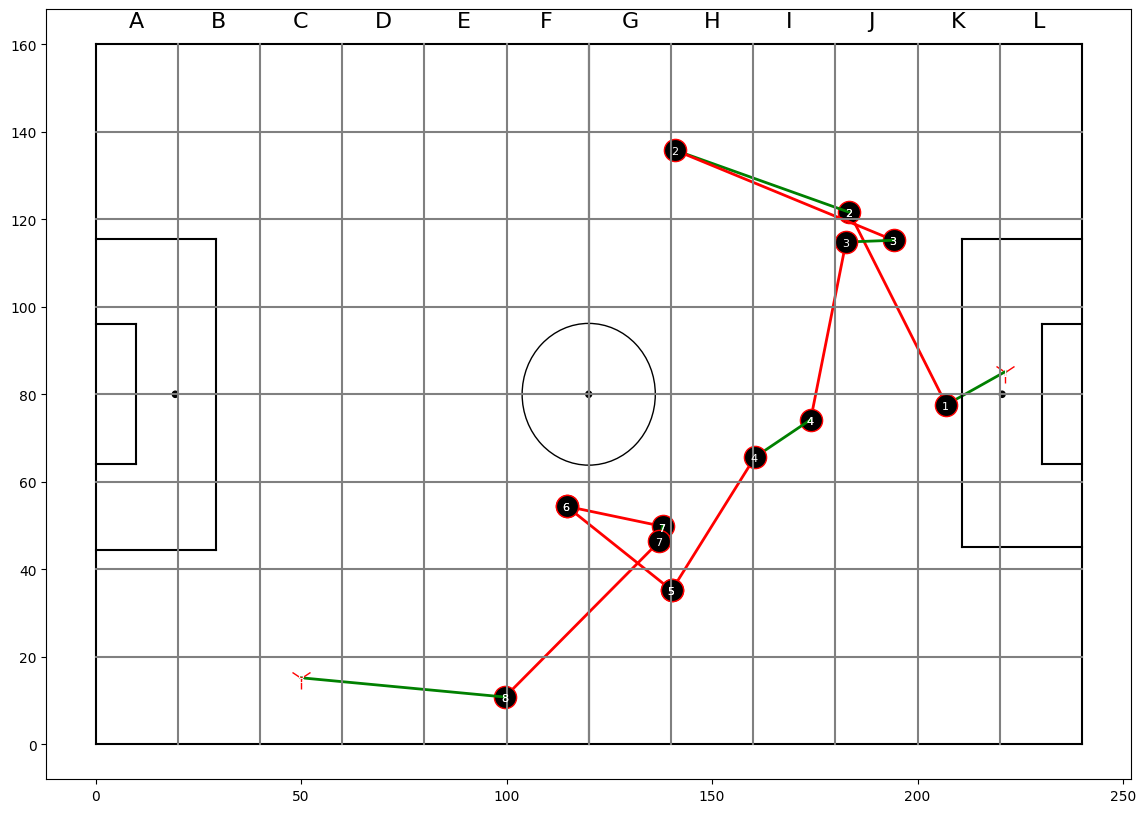

Sequence: 139
Team: Sweden
1: Viktor Claesson (Duel) <00:41:24.783>
2: Ludwig Augustinsson (Pass) <00:41:26.235>
3: Albin Ekdal (Ball Receipt*) <00:41:26.560>
3: Albin Ekdal (Pass) <00:41:26.560>
4: Viktor Claesson (Ball Receipt*) <00:41:27.600>
4: Viktor Claesson (Pass) <00:41:27.600>
5: Ludwig Augustinsson (Ball Receipt*) <00:41:28.551>
5: Ludwig Augustinsson (Pass) <00:41:28.551>
6: Bartosz Bereszyński (Foul Committed) <00:41:30.156>
7: Marcus Berg (Foul Won) <00:41:30.156>
8: Marcus Andreas Danielsson (Pass) <00:41:55.634>
9: Viktor Claesson (Ball Receipt*) <00:41:58.303>
9: Viktor Claesson (Pass) <00:41:58.343>
10: Marcus Berg (Ball Receipt*) <00:42:00.151>
10: Marcus Berg (Duel) <00:42:00.151>
11: Bartosz Bereszyński (Pass) <00:42:00.151>
12: Viktor Claesson (Pass) <00:42:01.510>
13: Dejan Kulusevski (Ball Receipt*) <00:42:02.300>
13: Dejan Kulusevski (Carry) <00:42:02.300>
13: Dejan Kulusevski (Pass) <00:42:02.577>
14: Viktor Claesson (Ball Receipt*) <00:42:02.697>
14: Viktor Cl

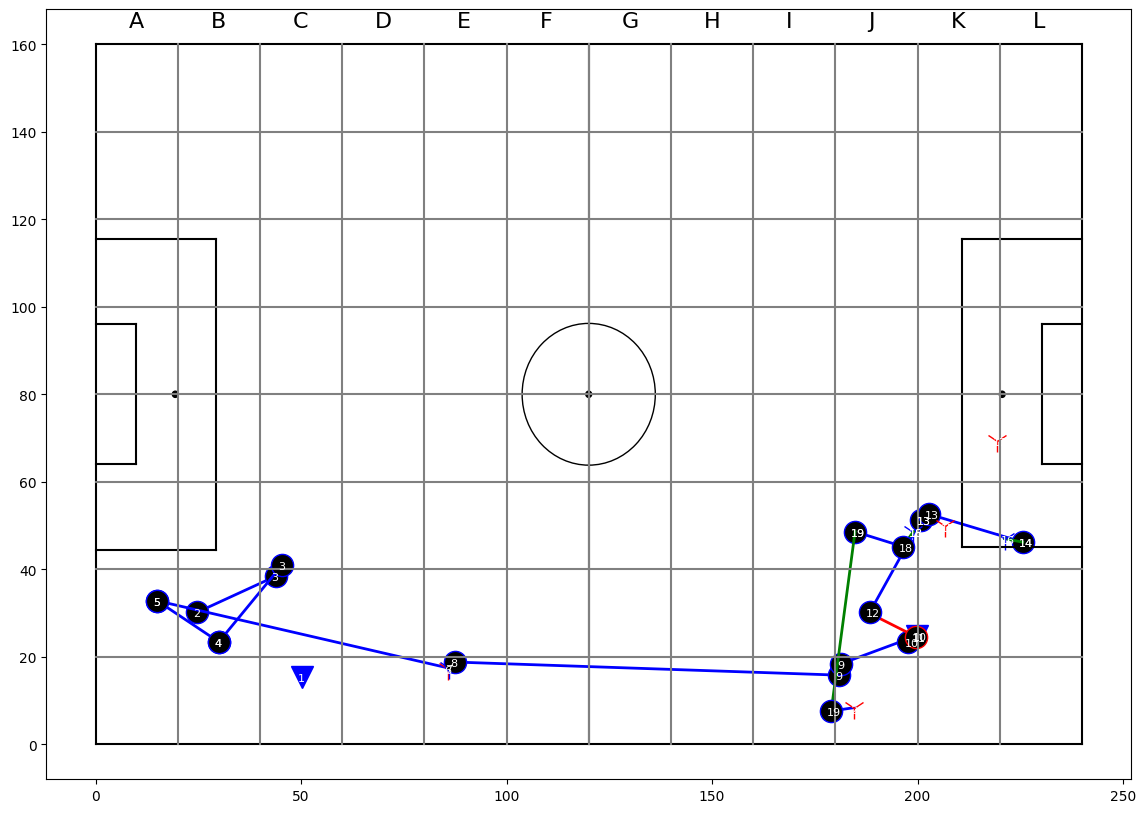

Sequence: 140
Team: Sweden
1: Ludwig Augustinsson (Pass) <00:42:20.172>
2: Dejan Kulusevski (Ball Receipt*) <00:42:21.776>


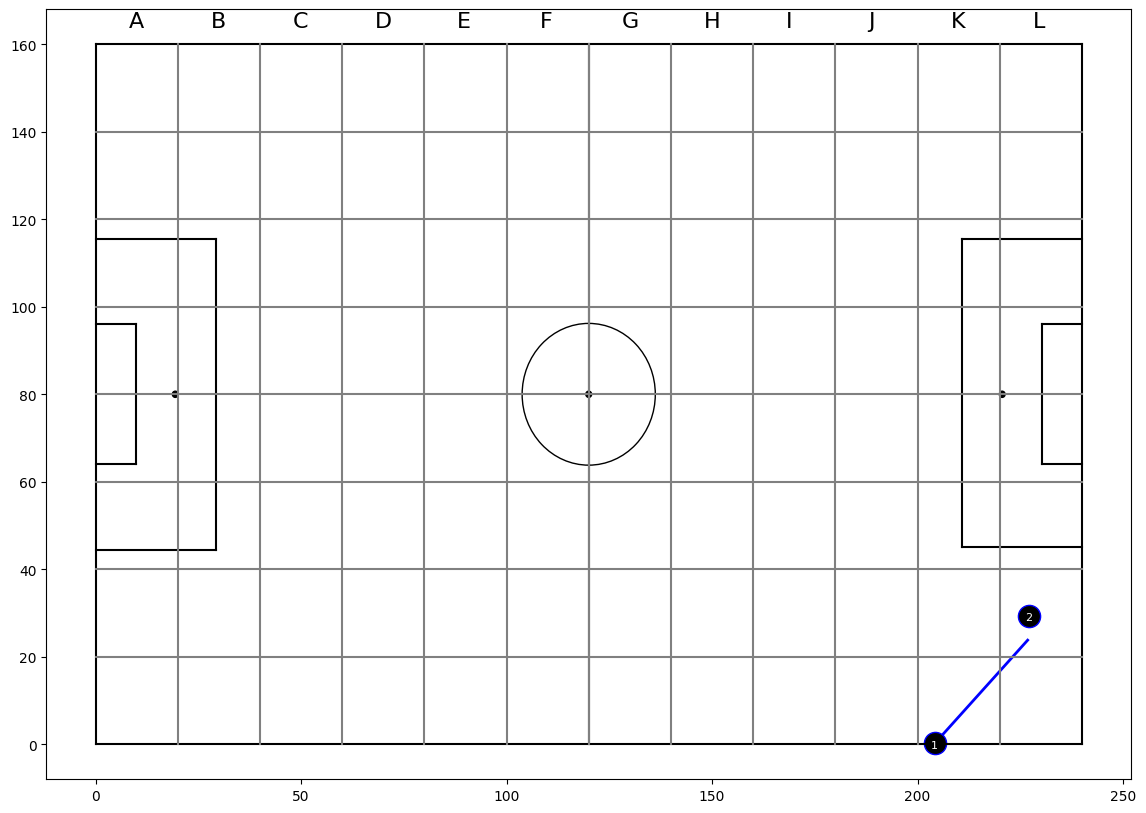

Sequence: 141
Team: Poland
1: Bartosz Bereszyński (Pass) <00:42:21.776>
2: Przemysław Płacheta (Ball Receipt*) <00:42:22.326>
2: Przemysław Płacheta (Carry) <00:42:22.326>
2: Przemysław Płacheta (Pass) <00:42:23.207>
3: Karol Świderski (Ball Receipt*) <00:42:24.308>
3: Karol Świderski (Carry) <00:42:24.308>
3: Karol Świderski (Miscontrol) <00:42:24.339>
4: Jakub Świerczok (Pass) <00:42:25.103>
5: Karol Świderski (Ball Receipt*) <00:42:25.910>
5: Karol Świderski (Carry) <00:42:25.910>
5: Karol Świderski (Pass) <00:42:27.562>
6: Kacper Kozłowski (Ball Receipt*) <00:42:28.536>
6: Kacper Kozłowski (Carry) <00:42:28.536>
6: Kacper Kozłowski (Pass) <00:42:30.177>
7: Robert Lewandowski (Ball Receipt*) <00:42:34.394>
7: Robert Lewandowski (Carry) <00:42:34.394>
7: Robert Lewandowski (Pass) <00:42:37.332>
8: Jakub Świerczok (Ball Receipt*) <00:42:39.001>
9: Marcus Andreas Danielsson (Clearance) <00:42:39.001>
10: Albin Ekdal (Ball Recovery) <00:42:41.406>
11: Piotr Zieliński (Ball Recovery) <00

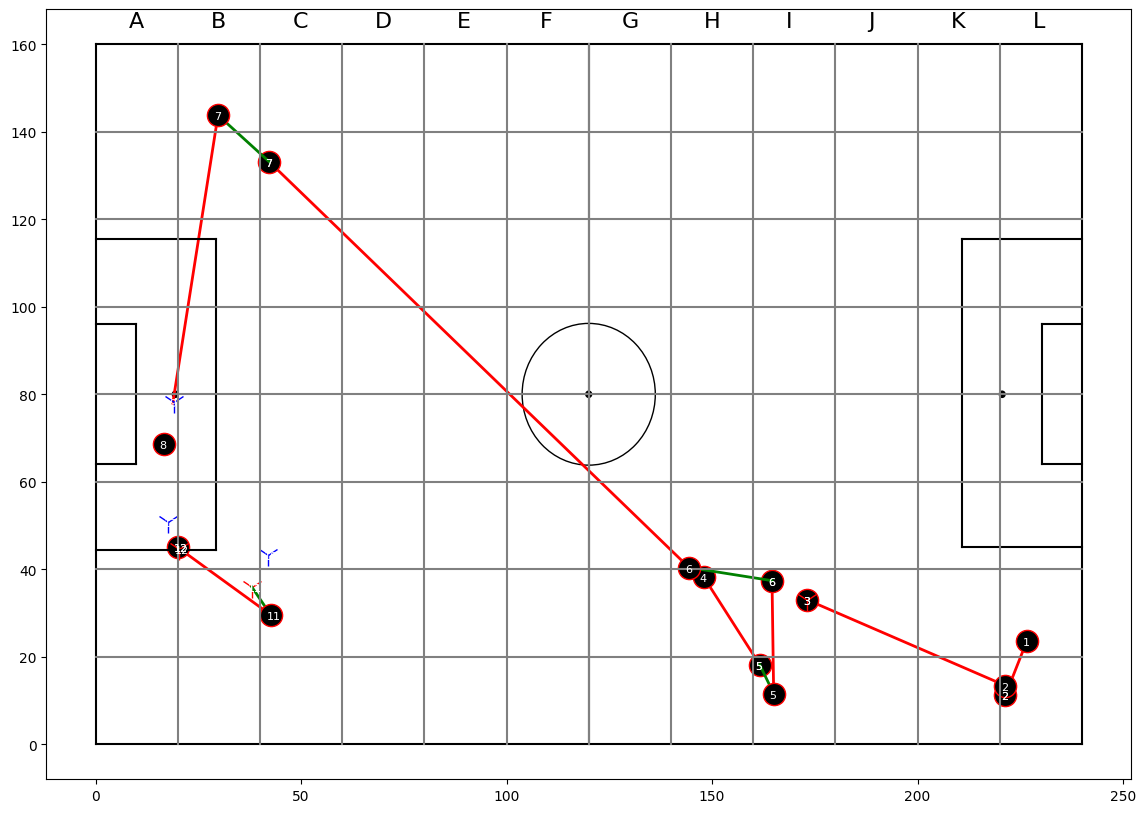

Sequence: 142
Team: Poland
1: Bartosz Bereszyński (Pass) <00:42:52.871>
2: Przemysław Płacheta (Ball Receipt*) <00:42:53.870>
2: Przemysław Płacheta (Carry) <00:42:53.870>
2: Przemysław Płacheta (Pass) <00:42:54.563>
3: Bartosz Bereszyński (Ball Receipt*) <00:42:55.694>
3: Bartosz Bereszyński (Carry) <00:42:55.694>
3: Bartosz Bereszyński (Pass) <00:42:57.937>
4: Robert Lewandowski (Ball Receipt*) <00:43:01.061>
4: Robert Lewandowski (Carry) <00:43:01.061>
4: Robert Lewandowski (Pass) <00:43:02.658>
5: Przemysław Frankowski (Ball Receipt*) <00:43:03.886>
5: Przemysław Frankowski (Carry) <00:43:03.886>
5: Przemysław Frankowski (Pass) <00:43:05.003>
6: Sebastian Larsson (Block) <00:43:05.086>
7: Przemysław Frankowski (Pass) <00:43:07.351>
8: Jan Bednarek (Ball Receipt*) <00:43:08.558>
8: Jan Bednarek (Carry) <00:43:08.558>
8: Jan Bednarek (Pass) <00:43:09.537>
9: Przemysław Frankowski (Ball Receipt*) <00:43:10.722>
9: Przemysław Frankowski (Carry) <00:43:10.722>
9: Przemysław Frankowski (

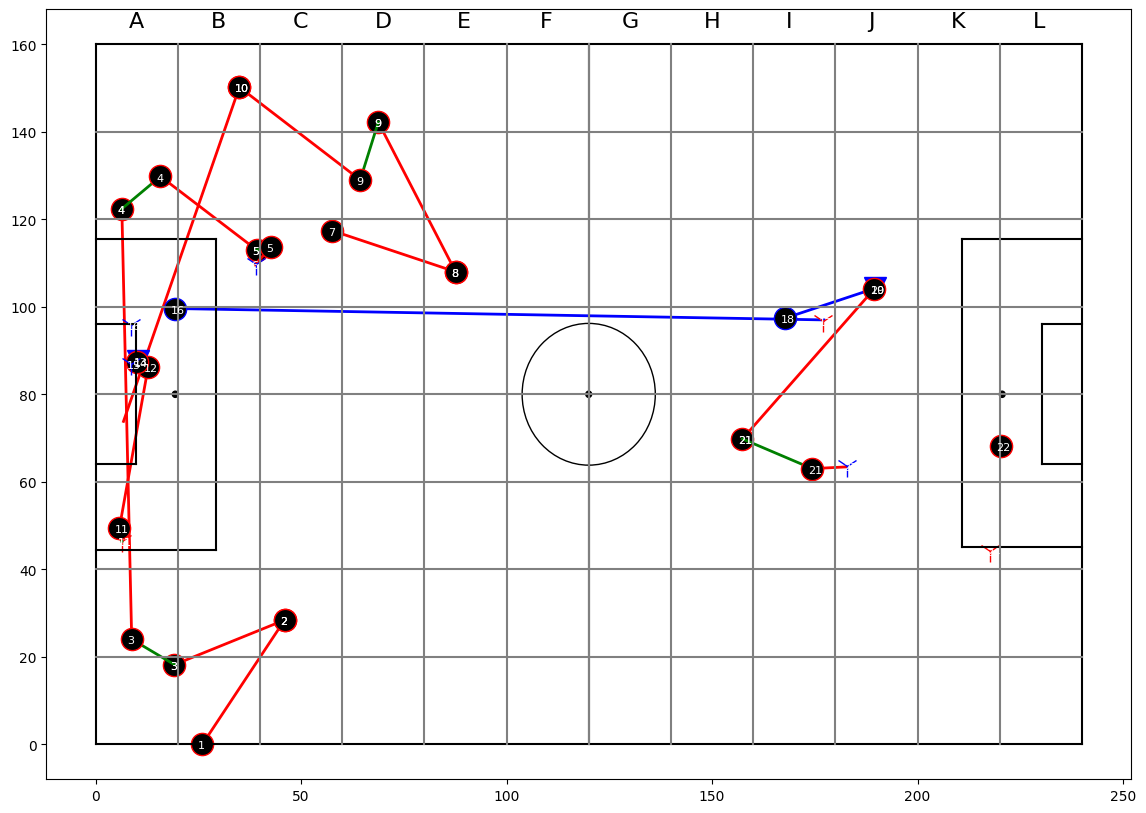

Sequence: 143
Team: Sweden
1: Viktor Claesson (Pass) <00:44:08.541>
2: Dejan Kulusevski (Ball Receipt*) <00:44:10.400>
2: Dejan Kulusevski (Dribble) <00:44:12.659>


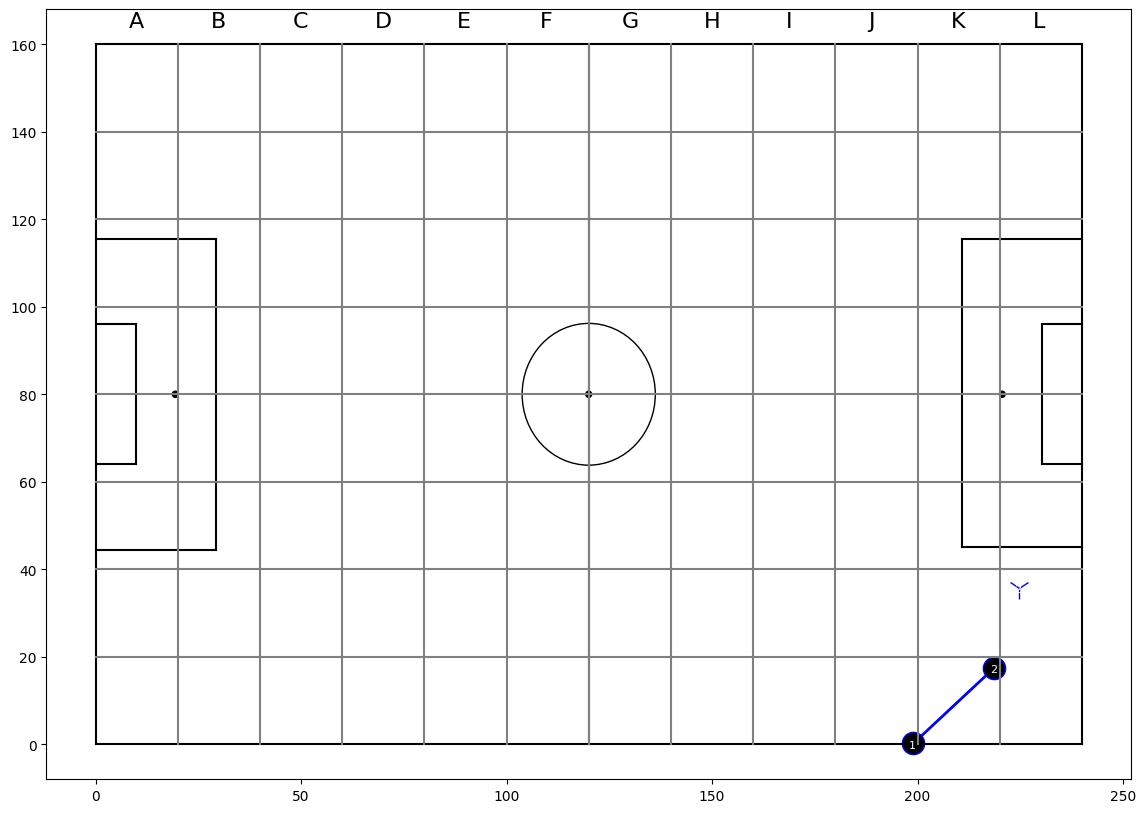

Sequence: 144
Team: Poland
1: Bartosz Bereszyński (Duel) <00:44:12.659>
1: Bartosz Bereszyński (Carry) <00:44:12.659>
1: Bartosz Bereszyński (Pass) <00:44:15.482>
2: Przemysław Płacheta (Ball Receipt*) <00:44:16.791>
2: Przemysław Płacheta (Carry) <00:44:16.791>
2: Przemysław Płacheta (Pass) <00:44:19.692>
3: Ludwig Augustinsson (Block) <00:44:19.815>
4: Przemysław Frankowski (Pass) <00:44:22.283>
5: Piotr Zieliński (Ball Receipt*) <00:44:23.636>
5: Piotr Zieliński (Pass) <00:44:23.733>
6: Jan Bednarek (Ball Receipt*) <00:44:24.629>
6: Jan Bednarek (Carry) <00:44:24.629>
6: Jan Bednarek (Pass) <00:44:25.977>
7: Robert Lewandowski (Ball Receipt*) <00:44:28.017>
7: Robert Lewandowski (Carry) <00:44:28.017>
7: Robert Lewandowski (Pass) <00:44:32.772>
8: Bartosz Bereszyński (Ball Receipt*) <00:44:34.149>
8: Bartosz Bereszyński (Carry) <00:44:34.149>
8: Bartosz Bereszyński (Pass) <00:44:36.116>
9: Przemysław Płacheta (Ball Receipt*) <00:44:37.396>
9: Przemysław Płacheta (Carry) <00:44:37.39

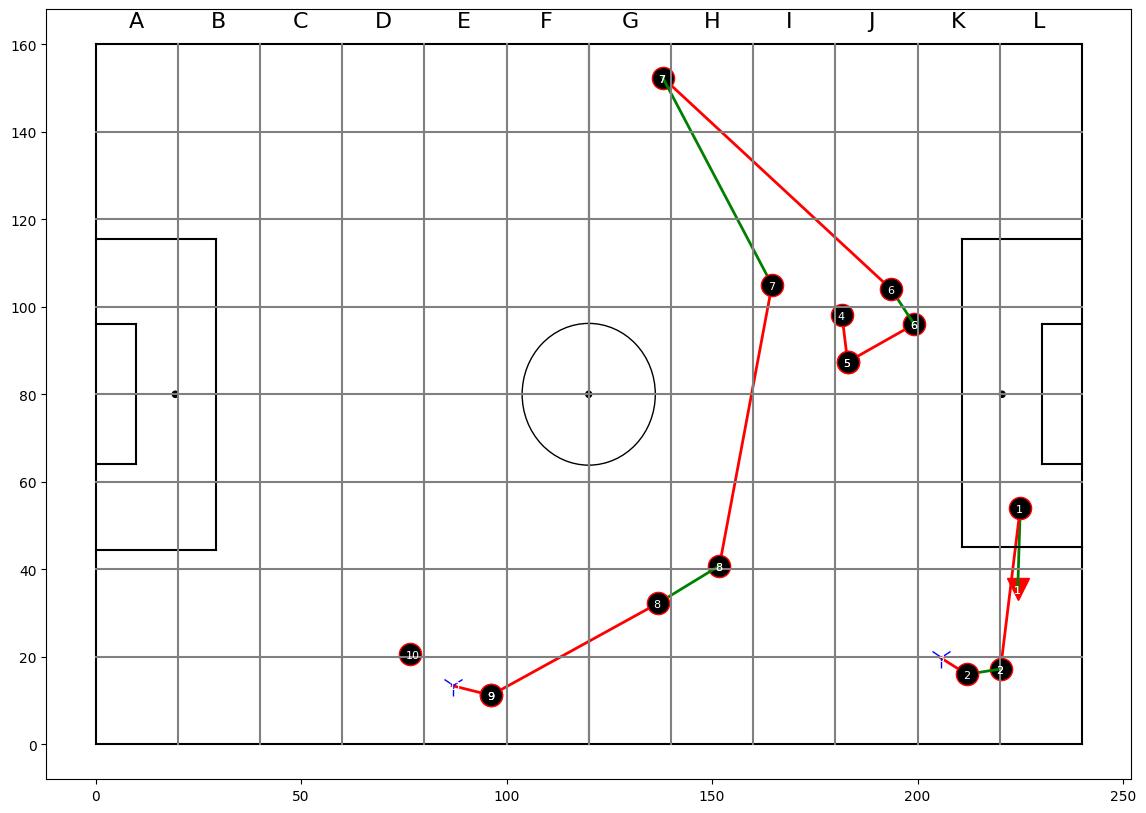

Sequence: 145
Team: Poland
1: Bartosz Bereszyński (Pass) <00:44:46.904>
2: Jakub Świerczok (Ball Receipt*) <00:44:47.790>
2: Jakub Świerczok (Carry) <00:44:47.790>
2: Jakub Świerczok (Dribble) <00:44:50.172>
2: Jakub Świerczok (Carry) <00:44:50.172>
2: Jakub Świerczok (Pass) <00:44:51.297>
3: Kacper Kozłowski (Ball Receipt*) <00:44:52.388>
3: Kacper Kozłowski (Pass) <00:44:52.388>
4: Marcus Andreas Danielsson (Pass) <00:44:53.538>
5: Viktor Claesson (Ball Receipt*) <00:44:54.680>
5: Viktor Claesson (Pass) <00:44:54.680>
6: Kacper Kozłowski (Block) <00:44:54.975>
7: Viktor Claesson (Clearance) <00:44:55.931>
8: Wojciech Szczęsny (Ball Recovery) <00:45:02.633>
8: Wojciech Szczęsny (Carry) <00:45:02.633>
8: Wojciech Szczęsny (Pass) <00:45:04.662>
9: Jan Bednarek (Ball Receipt*) <00:45:06.745>
9: Jan Bednarek (Carry) <00:45:06.745>
9: Jan Bednarek (Pass) <00:45:08.719>
10: Przemysław Frankowski (Ball Receipt*) <00:45:11.954>
10: Przemysław Frankowski (Carry) <00:45:11.954>
10: Przemysław F

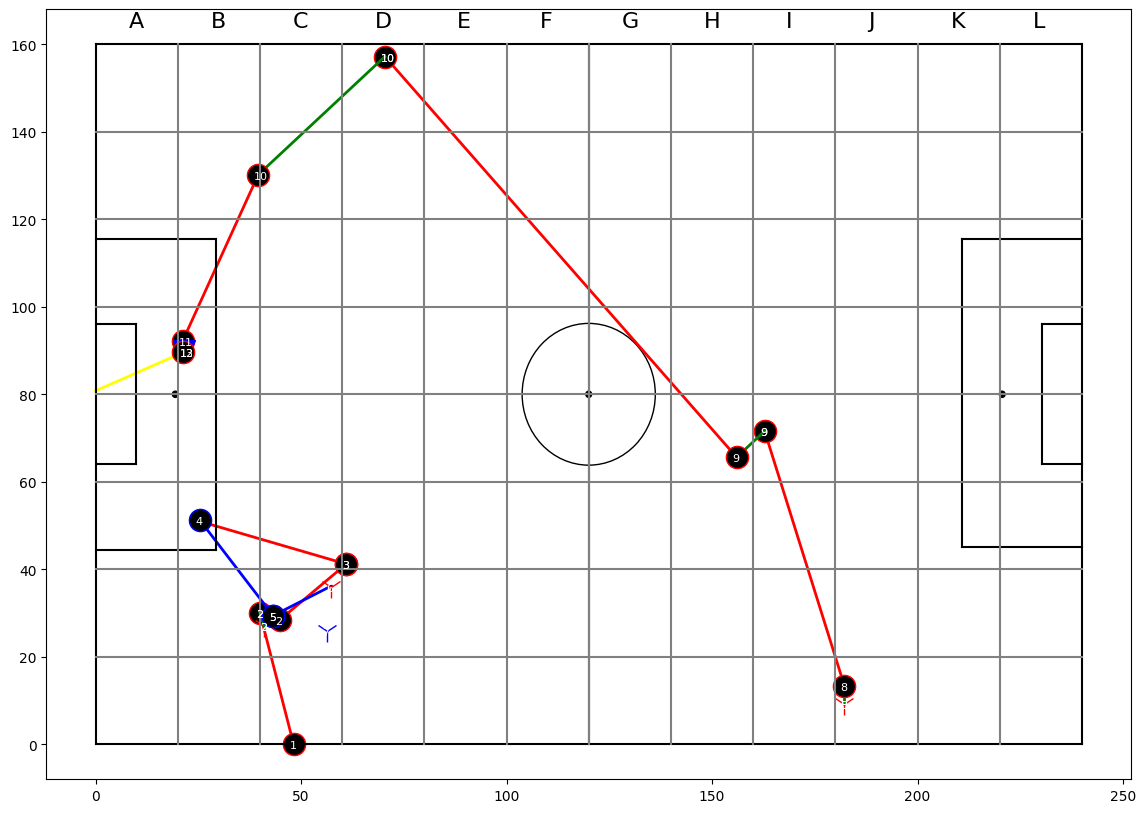

Sequence: 146
Team: Sweden
1: Robin Olsen (Pass) <00:45:46.196>
2: Marcus Berg (Ball Receipt*) <00:45:49.725>
2: Marcus Berg (Pass) <00:45:49.735>
3: Przemysław Frankowski (Duel) <00:45:49.735>
4: Dejan Kulusevski (Ball Receipt*) <00:45:51.074>


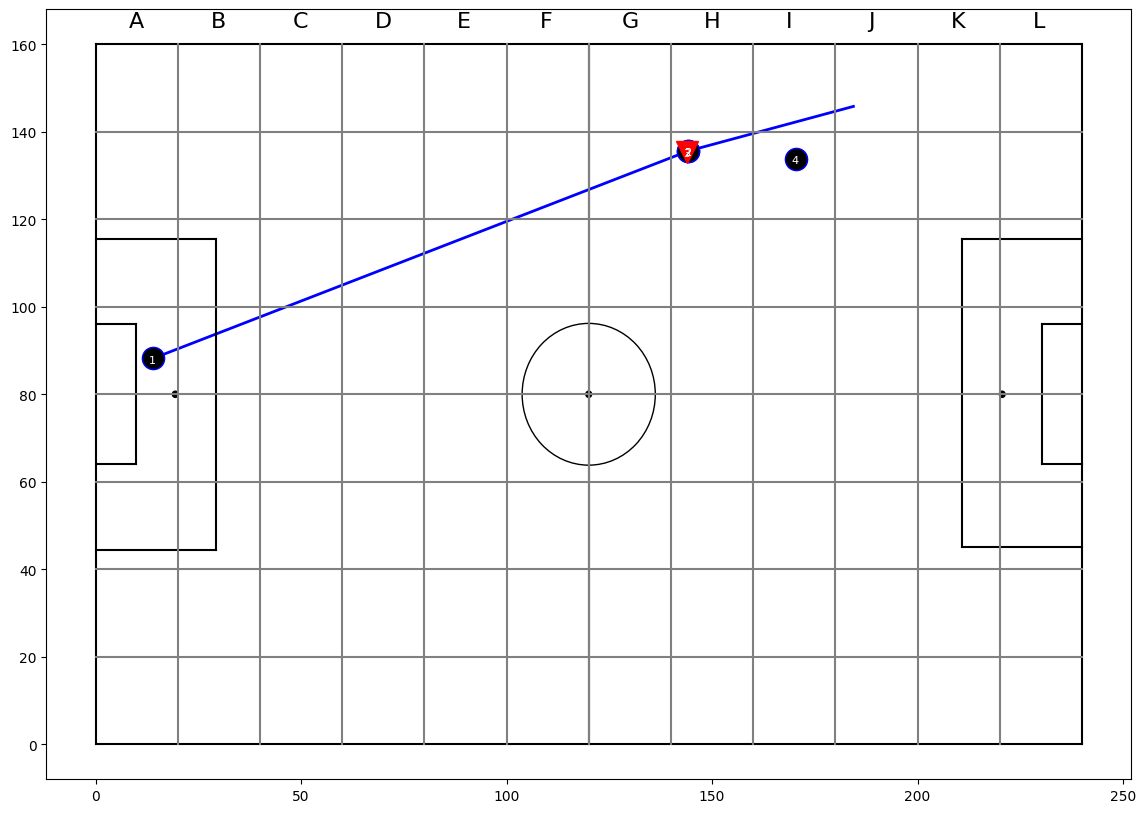

Sequence: 147
Team: Poland
1: Jan Bednarek (Ball Recovery) <00:45:51.074>
1: Jan Bednarek (Carry) <00:45:51.074>
1: Jan Bednarek (Pass) <00:45:52.105>
2: Robert Lewandowski (Ball Receipt*) <00:45:53.870>
2: Robert Lewandowski (Carry) <00:45:53.870>
2: Robert Lewandowski (Pass) <00:45:53.911>
3: Karol Świderski (Ball Receipt*) <00:45:54.269>
4: Emil Krafth (Foul Committed) <00:45:54.269>


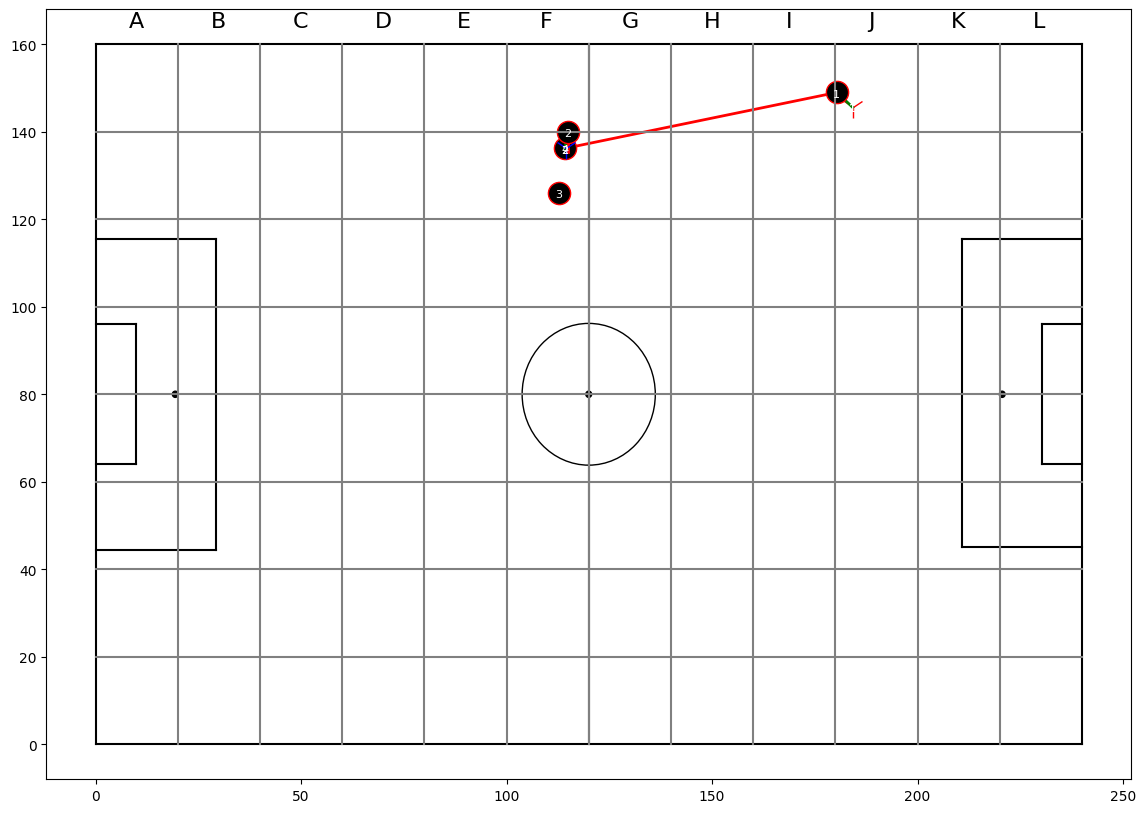

Sequence: 148
Team: Poland
1: Piotr Zieliński (Pass) <00:46:26.956>
2: Kamil Glik (Ball Receipt*) <00:46:29.684>
3: Albin Ekdal (Duel) <00:46:29.684>
4: Kamil Glik (Pass) <00:46:29.684>
5: Albin Ekdal (Block) <00:46:29.772>
6: Ludwig Augustinsson (Pass) <00:46:31.401>
7: Kacper Kozłowski (Pass) <00:46:32.608>
8: Przemysław Płacheta (Ball Receipt*) <00:46:34.220>
8: Przemysław Płacheta (Carry) <00:46:34.220>
8: Przemysław Płacheta (Miscontrol) <00:46:34.260>


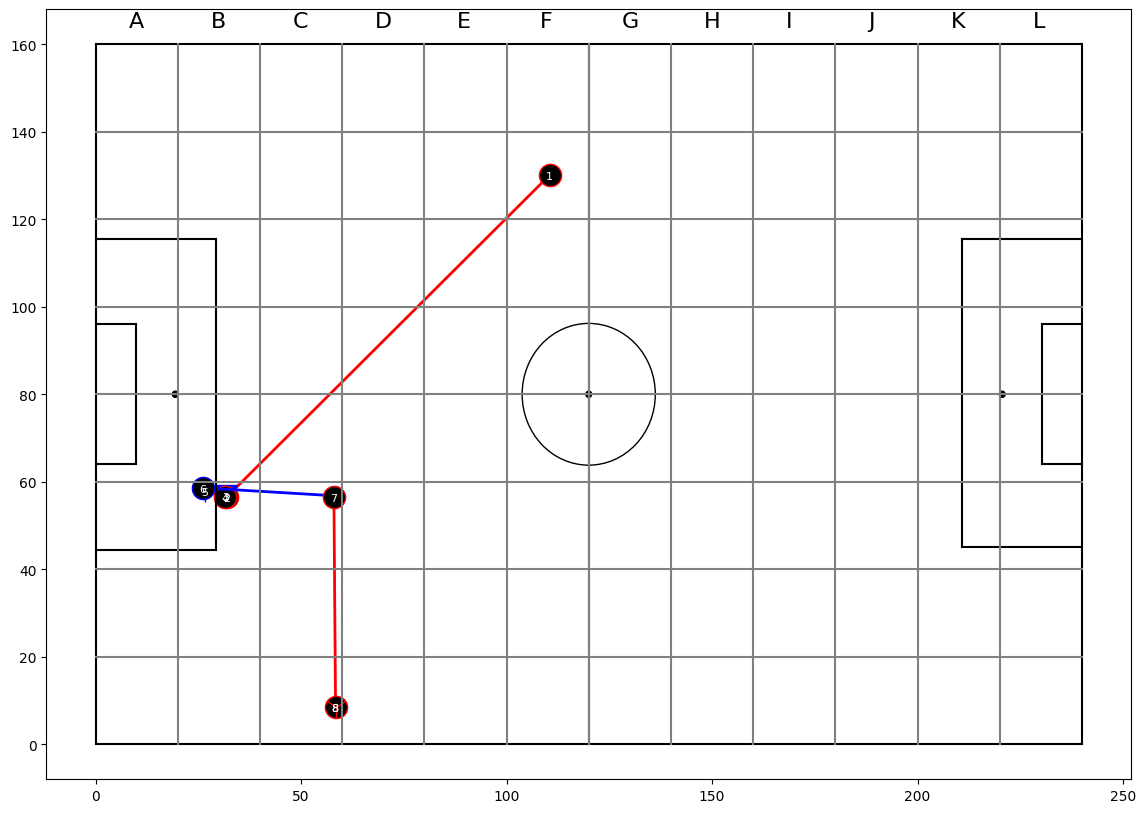

Sequence: 149
Team: Sweden
1: Ludwig Augustinsson (Pass) <00:46:56.542>
2: Marcus Berg (Ball Receipt*) <00:46:58.092>
2: Marcus Berg (Pass) <00:46:58.092>
3: Dejan Kulusevski (Ball Receipt*) <00:47:00.370>
3: Dejan Kulusevski (Carry) <00:47:00.370>
3: Dejan Kulusevski (Pass) <00:47:06.245>
4: Sebastian Larsson (Ball Receipt*) <00:47:07.636>
4: Sebastian Larsson (Carry) <00:47:07.636>
4: Sebastian Larsson (Shot) <00:47:08.487>


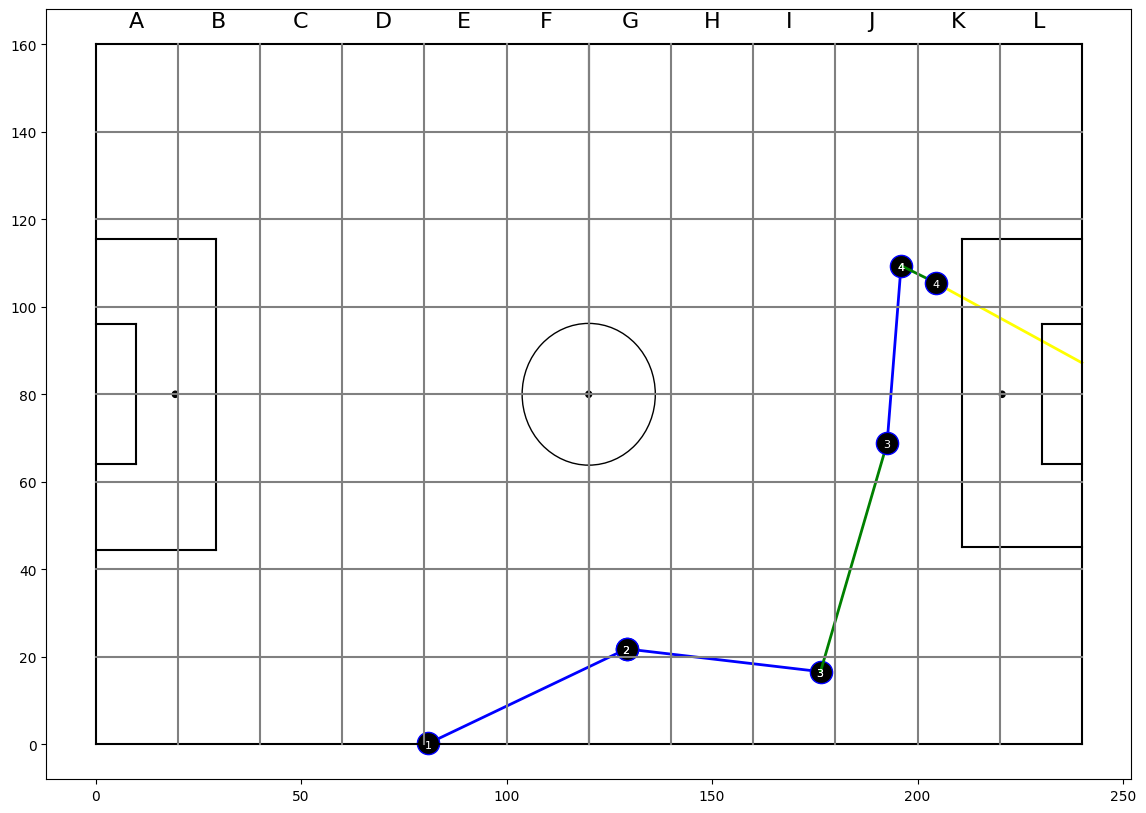

Sequence: 150
Team: Poland
1: Wojciech Szczęsny (Pass) <00:47:19.035>


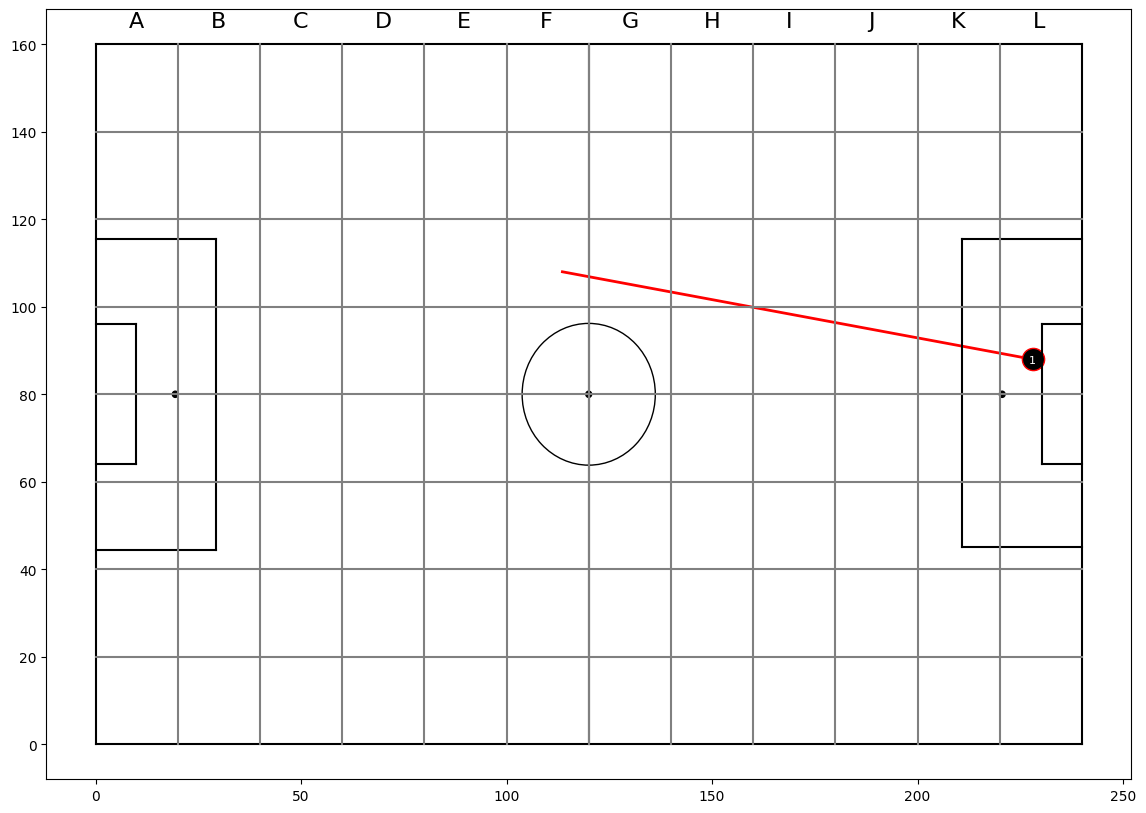

Sequence: 151
Team: Sweden
1: Kristoffer Olsson (Pass) <00:47:20.960>
2: Sebastian Larsson (Ball Receipt*) <00:47:22.386>
2: Sebastian Larsson (Carry) <00:47:22.386>
2: Sebastian Larsson (Pass) <00:47:23.225>
3: Marcus Berg (Ball Receipt*) <00:47:24.185>
3: Marcus Berg (Carry) <00:47:24.185>
3: Marcus Berg (Pass) <00:47:24.782>
4: Albin Ekdal (Ball Receipt*) <00:47:25.706>
4: Albin Ekdal (Pass) <00:47:25.706>
5: Viktor Claesson (Ball Receipt*) <00:47:26.781>
5: Viktor Claesson (Carry) <00:47:26.781>
5: Viktor Claesson (Pass) <00:47:28.530>
6: Dejan Kulusevski (Ball Receipt*) <00:47:33.384>
6: Dejan Kulusevski (Miscontrol) <00:47:33.384>


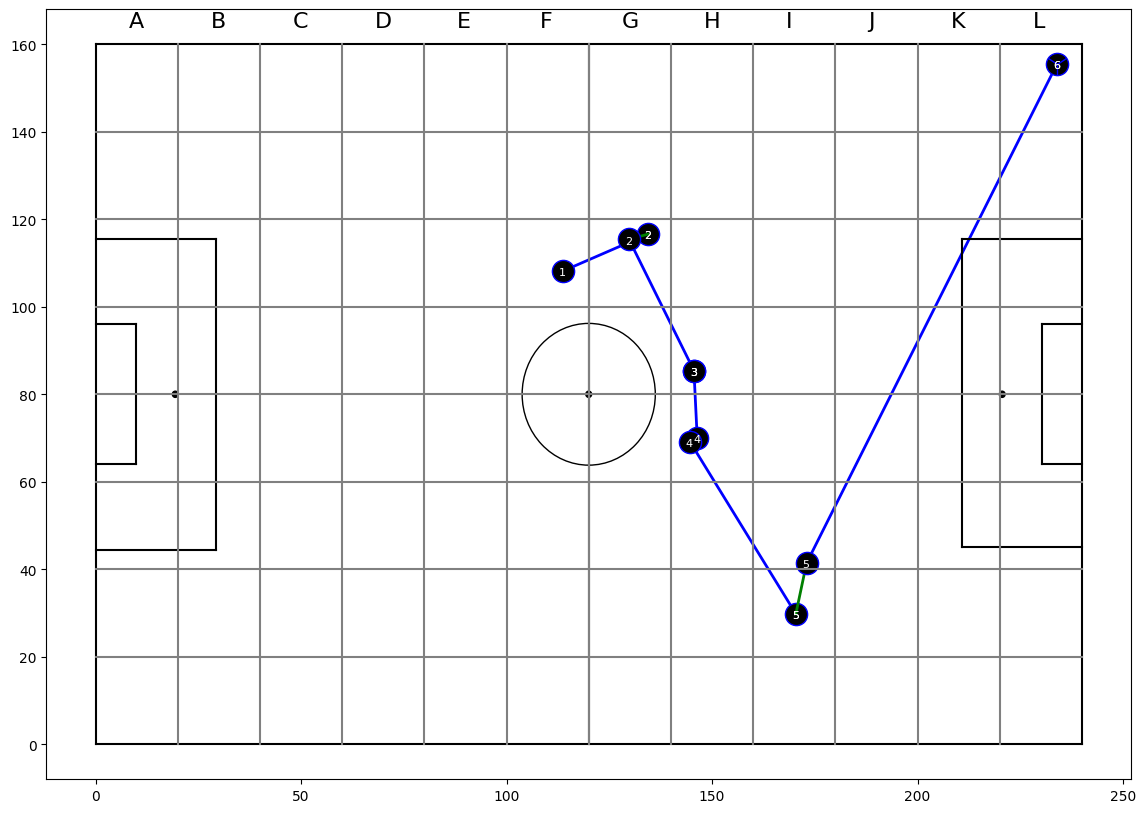

Sequence: 152
Team: Poland
1: Wojciech Szczęsny (Pass) <00:47:46.449>


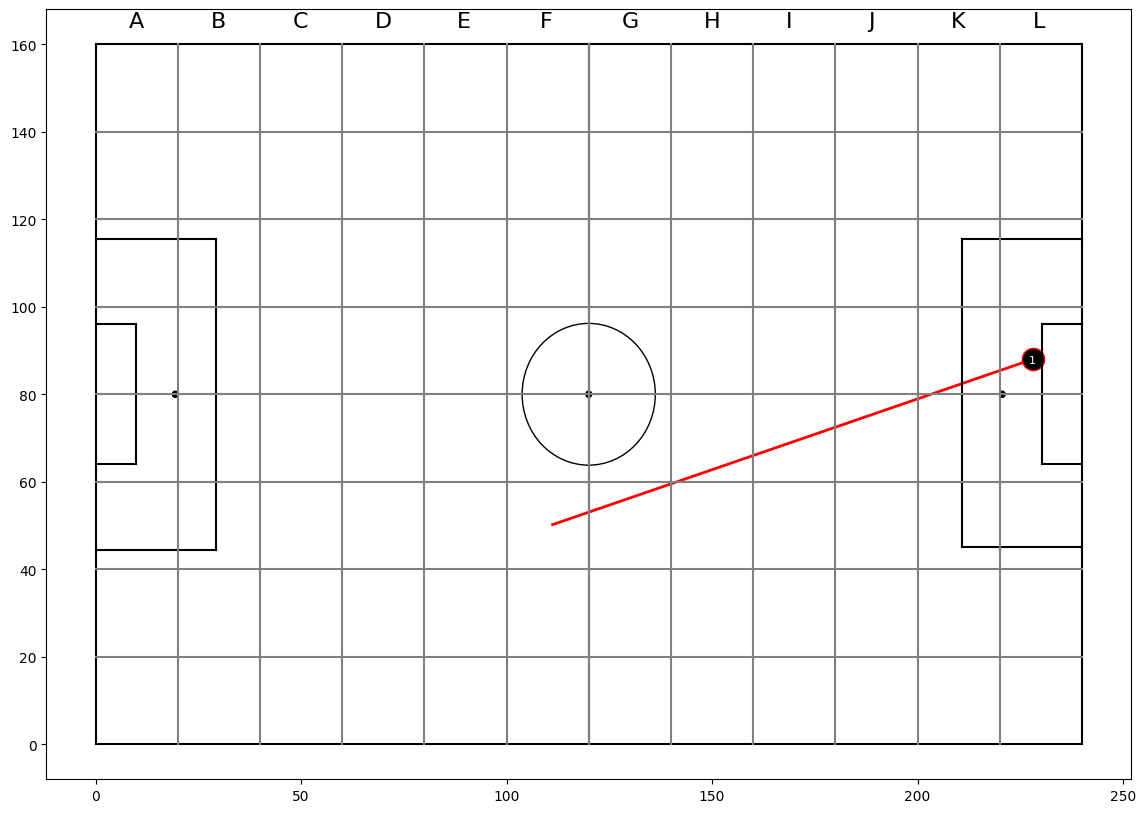

Sequence: 153
Team: Sweden
1: Albin Ekdal (Pass) <00:47:50.066>
2: Viktor Claesson (Ball Receipt*) <00:47:51.246>
2: Viktor Claesson (Pass) <00:47:51.246>
3: Marcus Berg (Ball Receipt*) <00:47:53.682>
3: Marcus Berg (Carry) <00:47:53.682>
3: Marcus Berg (Pass) <00:47:55.315>
4: Dejan Kulusevski (Ball Receipt*) <00:47:56.072>
4: Dejan Kulusevski (Carry) <00:47:56.072>
4: Dejan Kulusevski (Pass) <00:47:59.393>
5: Viktor Claesson (Ball Receipt*) <00:48:00.359>
5: Viktor Claesson (Carry) <00:48:00.359>
5: Viktor Claesson (Shot) <00:48:01.377>


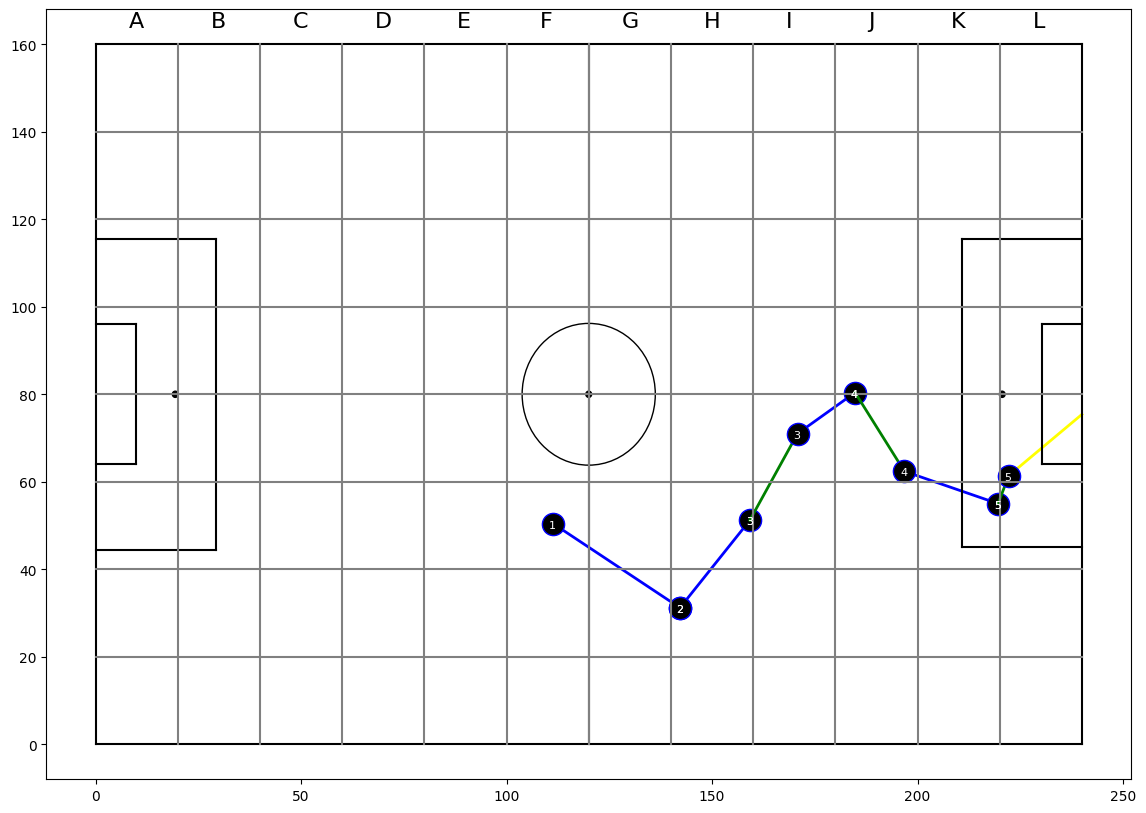

Sequence: 154
Team: Poland
1: Karol Świderski (Pass) <00:49:11.363>
2: Kamil Glik (Ball Receipt*) <00:49:13.327>
2: Kamil Glik (Carry) <00:49:13.327>
2: Kamil Glik (Pass) <00:49:14.432>
3: Piotr Zieliński (Ball Receipt*) <00:49:15.528>
3: Piotr Zieliński (Carry) <00:49:15.528>
3: Piotr Zieliński (Pass) <00:49:18.450>
4: Kacper Kozłowski (Ball Receipt*) <00:49:19.589>
4: Kacper Kozłowski (Carry) <00:49:19.589>
4: Kacper Kozłowski (Pass) <00:49:22.594>
5: Kamil Glik (Ball Receipt*) <00:49:23.728>
5: Kamil Glik (Carry) <00:49:23.728>
5: Kamil Glik (Pass) <00:49:25.470>
6: Jan Bednarek (Ball Receipt*) <00:49:26.487>
6: Jan Bednarek (Carry) <00:49:26.487>
6: Jan Bednarek (Pass) <00:49:27.459>
7: Piotr Zieliński (Ball Receipt*) <00:49:28.645>
7: Piotr Zieliński (Carry) <00:49:28.645>
8: Marcus Berg (Foul Committed) <00:49:31.731>
9: Piotr Zieliński (Foul Won) <00:49:31.731>
9: Piotr Zieliński (Pass) <00:49:40.282>
10: Przemysław Frankowski (Ball Receipt*) <00:49:41.891>
10: Przemysław Franko

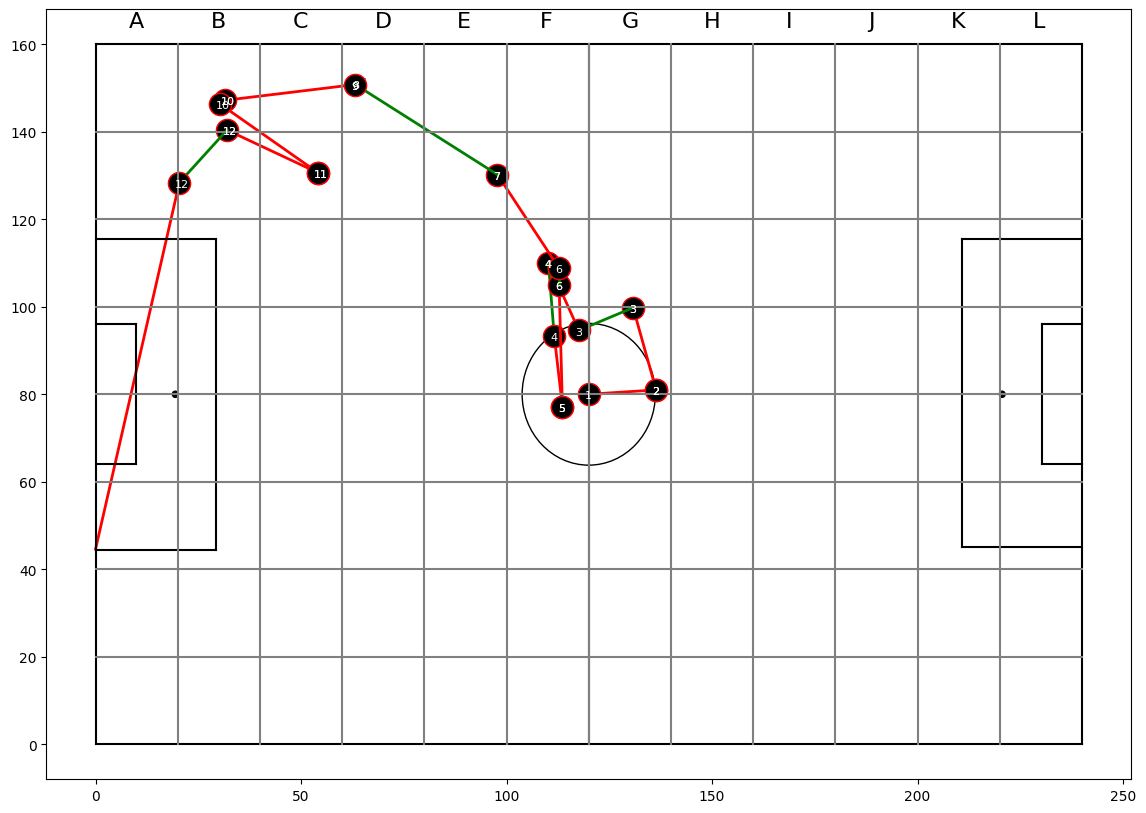

Sequence: 155
Team: Poland
0:  (Half End) <00:50:00.281>


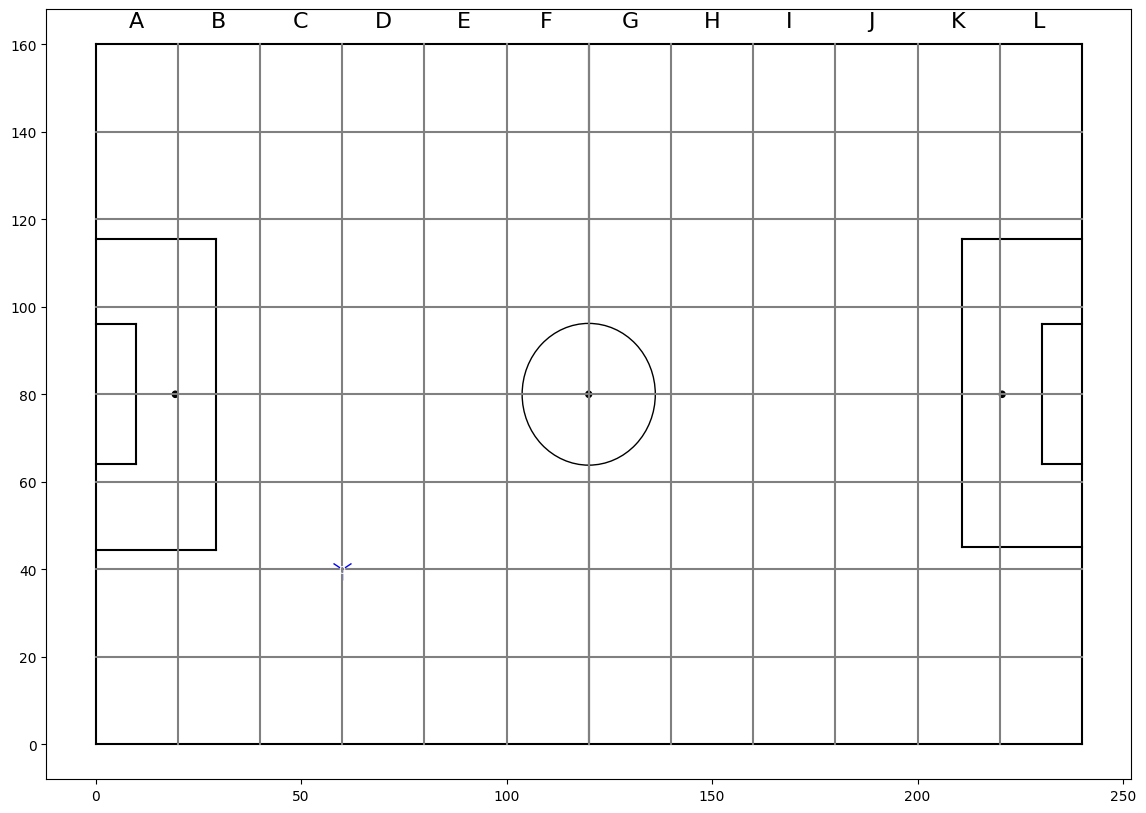

In [7]:
from draw.draw_sequences import draw_events_sequence

start_team = merged_events['possession_team'][0]

for i, s in enumerate(sequences):
    print(f'Sequence: {i+1}')
    draw_events_sequence(s, start_team, 12, 8, scale=2)